In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU allocated. CPU inference is possible, but slower.")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
%pip install -q transformers accelerate sentencepiece

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path

DRIVE_ROOT = Path(
    "/content/drive/MyDrive/Legal_AI_Summarization"
)

folders = [
    "notebooks",
    "data/raw",
    "data/processed",
    "models/led_baseline",
    "models/led_finetuned",
    "outputs/summaries",
    "outputs/evaluation",
    "logs",
    "src",
    "tests",
]

for folder in folders:
    (DRIVE_ROOT / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("Project root:", DRIVE_ROOT)
print("Folders created:", len(folders))

Project root: /content/drive/MyDrive/Legal_AI_Summarization
Folders created: 10


In [ ]:

import json
import torch
from pathlib import Path
from transformers import AutoTokenizer, LEDForConditionalGeneration

MODEL_NAME = "allenai/led-base-16384"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)
print("Loading LED tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Loading LED model...")
model = LEDForConditionalGeneration.from_pretrained(MODEL_NAME)
model.to(device)
model.eval()

print("LED loaded successfully!")

contract = """
SERVICE AGREEMENT

The Service Provider shall provide software maintenance
and technical support to the Customer.

The Customer shall pay a monthly service fee of
25,000 rupees within 30 days of receiving a valid invoice.

Either party may terminate this agreement by providing
30 days of written notice to the other party.

Both parties must protect confidential information obtained
during the agreement. Disclosure to third parties is allowed
only as permitted by the agreement.

The Service Provider shall provide monthly service reports.
Any amendment must be made in writing and approved
by both parties.
"""

# LED uses a special global attention mask.
# The first token receives global attention for summarization.
inputs = tokenizer(
    contract,
    return_tensors="pt",
    max_length=2048,
    truncation=True,
)

inputs = {key: value.to(device) for key, value in inputs.items()}

global_attention_mask = torch.zeros_like(inputs["input_ids"])
global_attention_mask[:, 0] = 1

print("Input tokens:", inputs["input_ids"].shape[1])

with torch.inference_mode():
    output_ids = model.generate(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        global_attention_mask=global_attention_mask,
        max_new_tokens=128,
        num_beams=2,
        do_sample=False,
    )

summary = tokenizer.decode(
    output_ids[0],
    skip_special_tokens=True,
)

print("\n--- LED BASELINE SUMMARY ---")
print(summary)

# Save the generated result, not the entire pretrained model.
output_path = DRIVE_ROOT / "outputs/summaries/led_baseline.json"

result = {
    "model_name": MODEL_NAME,
    "input_tokens": int(inputs["input_ids"].shape[1]),
    "summary": summary,
    "device": str(device),
}

output_path.write_text(
    json.dumps(result, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

print("\nSaved result to:", output_path)


Using device: cuda
Loading LED tokenizer...


config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/27.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/299 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/168 [00:00<?, ?B/s]

LED loaded successfully!
Input tokens: 127


[transformers] Input ids are automatically padded from 127 to 1024 to be a multiple of `config.attention_window`: 1024



--- LED BASELINE SUMMARY ---
CLASSIFIEDSERVICE AGREEMENTCLASSIFIEDThe Service Provider shall provide software maintenance services,and technical support to the Customer.CLASSIFIEDCLASSIFIEDCLASSIFIEDCLASSIFIEDCLASSIFIEDCLASSIFIEDThe Customer shall pay a monthly service fee of up to $25,000 rupees within 30 days of receiving a valid invoice.CLASSIFIEDCLASSIFIEDCLASSIFIEDCLASSIFIEDCLASSIFIEDEither party may terminate this agreement by providing up to30 days of written notice to the other party.CLASSIFIEDCLASSIFIEDCLASSIFIEDCLASSIFIEDCLASSIFIEDCLASSIFIEDCLASSIFIEDCLASSIFIEDCLASSIFIEDBoth parties must protect confidential information obtained from third partiesduring the agreement. Disclosure to third parties is allowed,butonly as permitted by the agreement.CLASSIFIEDCLASSIFIEDCLASSIFIEDCLASSIFIEDCLASSIFIEDCLASSIFIEDCLASSIFIEDCLASSIFIEDCLASSIFIED

Saved result to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/led_baseline.json


In [ ]:
from pathlib import Path

checkpoint_dir = (
    DRIVE_ROOT / "models/led_finetuned/checkpoint"
)

checkpoint_dir.mkdir(parents=True, exist_ok=True)

# After training or at a checkpoint:
model.save_pretrained(checkpoint_dir)
tokenizer.save_pretrained(checkpoint_dir)

print("Model artifacts saved to:", checkpoint_dir)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model artifacts saved to: /content/drive/MyDrive/Legal_AI_Summarization/models/led_finetuned/checkpoint


In [ ]:
%pip install -q transformers datasets accelerate evaluate rouge_score sentencepiece

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
from transformers import LEDTokenizer, LEDForConditionalGeneration

MODEL_NAME = "allenai/led-base-16384"

tokenizer = LEDTokenizer.from_pretrained(MODEL_NAME)

model = LEDForConditionalGeneration.from_pretrained(MODEL_NAME)

print("LED model loaded successfully")

Loading weights:   0%|          | 0/299 [00:00<?, ?it/s]

LED model loaded successfully


# Legal Summarization Dataset
## Objectives
1. Load a public contract summarization dataset.
2. Inspect the original documents and reference summaries.
3. Check data quality and document lengths.
4. Save a reusable dataset inspection module.

In [ ]:
%pip install -q pandas requests

In [ ]:
%pip install -q datasets pandas transformers sentencepiece

In [ ]:
from datasets import load_dataset

DATASET_NAME = "theatticusproject/cuad-qa"

cuad = load_dataset(
    DATASET_NAME,
    revision="refs/convert/parquet",
    split="train[:20]"
)

print(cuad)
print("\nColumns:", cuad.column_names)
print("\nFirst record:")
print(cuad[0])

default/train/0000.parquet: reconstructing file:   0%|          |  0.00B / 4.32MB            

default/train/0000.parquet: downloading bytes:           |  0.00B            

default/train/0001.parquet: reconstructing file:   0%|          |  0.00B / 4.08MB            

default/train/0001.parquet: downloading bytes:           |  0.00B            

default/train/0002.parquet: reconstructing file:   0%|          |  0.00B / 3.69MB            

...

default/test/0000.parquet: reconstructing file:   0%|          |  0.00B / 2.64MB            

default/test/0000.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['id', 'title', 'context', 'question', 'answers'],
    num_rows: 20
})

Columns: ['id', 'title', 'context', 'question', 'answers']

First record:
{'id': 'LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT__Document Name_0', 'title': 'LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT', 'context': 'EXHIBIT 10.6\n\n                              DISTRIBUTOR AGREEMENT\n\n         THIS  DISTRIBUTOR  AGREEMENT (the  "Agreement")  is made by and between Electric City Corp.,  a Delaware  corporation  ("Company")  and Electric City of Illinois LLC ("Distributor") this 7th day of September, 1999.\n\n                                    RECITALS\n\n         A. The  Company\'s  Business.  The Company is  presently  engaged in the business  of selling an energy  efficiency  device,  which is  referred to as an "Energy  Saver"  which may be improved  or  otherwise  changed  from its present composition (the "Products").  The Company may engage in the business of selling othe

In [ ]:
example = cuad[0]

for key, value in example.items():
    print(f"\n--- {key} ---")
    print(str(value)[:1000])


--- id ---
LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT__Document Name_0

--- title ---
LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT

--- context ---
EXHIBIT 10.6

                              DISTRIBUTOR AGREEMENT

         THIS  DISTRIBUTOR  AGREEMENT (the  "Agreement")  is made by and between Electric City Corp.,  a Delaware  corporation  ("Company")  and Electric City of Illinois LLC ("Distributor") this 7th day of September, 1999.

                                    RECITALS

         A. The  Company's  Business.  The Company is  presently  engaged in the business  of selling an energy  efficiency  device,  which is  referred to as an "Energy  Saver"  which may be improved  or  otherwise  changed  from its present composition (the "Products").  The Company may engage in the business of selling other  products  or  other  devices  other  than  the  Products,  which  will be considered  Products if Distributor  exercises its options pursuant to Section 7 hereof.

  

In [ ]:
import pandas as pd

sample_df = pd.DataFrame(cuad)

print("QA examples loaded:", len(sample_df))
print("Unique contract titles:", sample_df["title"].nunique())
print("Unique contract texts:", sample_df["context"].nunique())

display(
    sample_df[["title", "question"]]
    .drop_duplicates()
    .head(10)
)

QA examples loaded: 20
Unique contract titles: 1
Unique contract texts: 1


,title,question
0,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Highlight the parts (if any) of this contract ...
1,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Highlight the parts (if any) of this contract ...
6,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Highlight the parts (if any) of this contract ...
7,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Highlight the parts (if any) of this contract ...
9,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Highlight the parts (if any) of this contract ...
10,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Highlight the parts (if any) of this contract ...
11,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Highlight the parts (if any) of this contract ...
12,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Highlight the parts (if any) of this contract ...
13,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Highlight the parts (if any) of this contract ...
14,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Highlight the parts (if any) of this contract ...


In [ ]:
from transformers import AutoTokenizer

MODEL_NAME = "allenai/led-base-16384"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("LED tokenizer loaded successfully")

LED tokenizer loaded successfully


In [ ]:
unique_contracts = (
    sample_df[["title", "context"]]
    .drop_duplicates(subset=["title"])
    .copy()
)

unique_contracts["characters"] = (
    unique_contracts["context"].str.len()
)

unique_contracts["words"] = (
    unique_contracts["context"].str.split().str.len()
)

unique_contracts["tokens"] = unique_contracts["context"].apply(
    lambda text: len(
        tokenizer(
            text,
            add_special_tokens=True,
            truncation=False
        )["input_ids"]
    )
)

display(
    unique_contracts[
        ["title", "characters", "words", "tokens"]
    ]
)

print("\nLongest contract in this sample:")
print(
    unique_contracts.loc[
        unique_contracts["tokens"].idxmax(),
        ["title", "characters", "words", "tokens"]
    ]
)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (23250 > 16384). Running this sequence through the model will result in indexing errors


,title,characters,words,tokens
0,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,54290,5998,23250



Longest contract in this sample:
title         LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...
characters                                                54290
words                                                      5998
tokens                                                    23250
Name: 0, dtype: object


In [ ]:
from pathlib import Path

OUTPUT_DIR = DRIVE_ROOT / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

length_report = unique_contracts[
    ["title", "characters", "words", "tokens"]
].copy()

length_report.to_csv(
    OUTPUT_DIR / "cuad_sample_length_report.csv",
    index=False
)

print("Saved:", OUTPUT_DIR / "cuad_sample_length_report.csv")

Saved: /content/drive/MyDrive/Legal_AI_Summarization/data/processed/cuad_sample_length_report.csv


In [ ]:
from datasets import load_dataset
import pandas as pd

DATASET_NAME = "theatticusproject/cuad-qa"

cuad_stream = load_dataset(
    DATASET_NAME,
    revision="refs/convert/parquet",
    split="train",
    streaming=True
)

MAX_CONTRACTS = 30
contracts_by_title = {}

for row in cuad_stream:
    title = row["title"]
    context = row["context"]

    if title and context and title not in contracts_by_title:
        contracts_by_title[title] = context

    if len(contracts_by_title) >= MAX_CONTRACTS:
        break

contracts_df = pd.DataFrame([
    {"title": title, "context": context}
    for title, context in contracts_by_title.items()
])

contracts_df["characters"] = contracts_df["context"].str.len()
contracts_df["words"] = contracts_df["context"].str.split().str.len()

print("Unique contracts collected:", len(contracts_df))
display(contracts_df[["title", "characters", "words"]].head(10))

Unique contracts collected: 30


,title,characters,words
0,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,54290,5998
1,"WHITESMOKE,INC_11_08_2011-EX-10.26-PROMOTION A...",70383,11313
2,NELNETINC_04_08_2020-EX-1-JOINT FILING AGREEMENT,1081,170
3,ADAMSGOLFINC_03_21_2005-EX-10.17-ENDORSEMENT A...,24632,3770
4,"KIROMICBIOPHARMA,INC_05_11_2020-EX-10.23-CONSU...",18403,2766
5,"VEONEER,INC_02_21_2020-EX-10.11-JOINT VENTURE ...",8257,1334
6,"MetLife, Inc. - Remarketing Agreement",111249,17518
7,"FTENETWORKS,INC_02_18_2016-EX-99.4-STRATEGIC A...",37829,5761
8,DOMINIADVISORTRUST_02_18_2005-EX-99.(H)(2)-SPO...,12555,1847
9,PfHospitalityGroupInc_20150923_10-12G_EX-10.1_...,6772,1014


In [ ]:
def count_tokens(text):
    return len(
        tokenizer(
            text,
            add_special_tokens=True,
            truncation=False
        )["input_ids"]
    )

contracts_df["tokens"] = contracts_df["context"].apply(count_tokens)

display(
    contracts_df[
        ["title", "words", "tokens"]
    ].sort_values("tokens", ascending=False)
)

print("\nContracts over LED's 16,384-token limit:",
      (contracts_df["tokens"] > 16384).sum())

print("Shortest contract:", contracts_df["tokens"].min(), "tokens")
print("Longest contract:", contracts_df["tokens"].max(), "tokens")

,title,words,tokens
28,LOYALTYPOINTINC_11_16_2004-EX-10.2-RESELLER AG...,12890,43881
16,BONTONSTORESINC_04_20_2018-EX-99.3-AGENCY AGRE...,26842,39214
24,PfHospitalityGroupInc_20150923_10-12G_EX-10.1_...,24389,31804
21,ZEBRATECHNOLOGIESCORP_04_16_2014-EX-10.1-INTEL...,19581,27607
0,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,5998,23250
6,"MetLife, Inc. - Remarketing Agreement",17518,23219
25,CORIOINC_07_20_2000-EX-10.5-LICENSE AND HOSTIN...,8396,19088
17,"ON2TECHNOLOGIES,INC_11_17_2006-EX-10.3-SUPPORT...",8844,17595
1,"WHITESMOKE,INC_11_08_2011-EX-10.26-PROMOTION A...",11313,15921
26,SENMIAOTECHNOLOGYLTD_02_19_2019-EX-10.5-Collab...,11876,15204



Contracts over LED's 16,384-token limit: 8
Shortest contract: 238 tokens
Longest contract: 43881 tokens


In [ ]:
def split_into_token_chunks(
    text,
    tokenizer,
    chunk_size=6000,
    overlap=300
):
    """
    Split text into overlapping token chunks.

    chunk_size: maximum content tokens per chunk
    overlap: tokens shared between consecutive chunks
    """
    if chunk_size <= 0:
        raise ValueError("chunk_size must be positive.")

    if overlap < 0 or overlap >= chunk_size:
        raise ValueError(
            "overlap must be >= 0 and smaller than chunk_size."
        )

    token_ids = tokenizer(
        text,
        add_special_tokens=False,
        truncation=False
    )["input_ids"]

    chunks = []
    step = chunk_size - overlap

    for start in range(0, len(token_ids), step):
        chunk_ids = token_ids[start:start + chunk_size]

        if not chunk_ids:
            break

        chunk_text = tokenizer.decode(
            chunk_ids,
            skip_special_tokens=True
        )
        chunks.append(chunk_text)

        if start + chunk_size >= len(token_ids):
            break

    return chunks

print("Token chunking function defined successfully.")

Token chunking function defined successfully.


In [ ]:
import pandas as pd
from transformers import LEDTokenizer

MODEL_NAME = "allenai/led-base-16384"

# Load the tokenizer used by our LED model
tokenizer = LEDTokenizer.from_pretrained(MODEL_NAME)

# Confirm the expected columns exist
required_columns = {"title", "context"}

missing_columns = required_columns - set(contracts_df.columns)

if missing_columns:
    raise ValueError(
        f"contracts_df is missing columns: {missing_columns}"
    )

# Calculate token counts if they are not already available
if "tokens" not in contracts_df.columns:
    contracts_df["tokens"] = contracts_df["context"].fillna("").apply(
        lambda text: len(
            tokenizer(
                str(text),
                add_special_tokens=False,
                truncation=False
            )["input_ids"]
        )
    )

# Select the longest contract
longest_row = contracts_df.loc[contracts_df["tokens"].idxmax()]
long_contract = str(longest_row["context"])

print("Tokenizer loaded:", MODEL_NAME)
print("Contract:", longest_row["title"])
print("Word count:", len(long_contract.split()))
print("Token count:", int(longest_row["tokens"]))

Tokenizer loaded: allenai/led-base-16384
Contract: LOYALTYPOINTINC_11_16_2004-EX-10.2-RESELLER AGREEMENT
Word count: 12890
Token count: 43881


In [ ]:
def split_into_token_chunks(
    text,
    tokenizer,
    chunk_size=6000,
    overlap=300
):
    """
    Split a document into overlapping token chunks.

    chunk_size: maximum content tokens per chunk
    overlap: number of tokens shared between consecutive chunks
    """
    if not isinstance(text, str):
        raise TypeError("text must be a string.")

    if chunk_size <= 0:
        raise ValueError("chunk_size must be positive.")

    if overlap < 0 or overlap >= chunk_size:
        raise ValueError(
            "overlap must be >= 0 and smaller than chunk_size."
        )

    token_ids = tokenizer(
        text,
        add_special_tokens=False,
        truncation=False
    )["input_ids"]

    chunks = []
    step = chunk_size - overlap

    for start in range(0, len(token_ids), step):
        chunk_ids = token_ids[start:start + chunk_size]

        if not chunk_ids:
            break

        chunk_text = tokenizer.decode(
            chunk_ids,
            skip_special_tokens=True
        )

        chunks.append(chunk_text)

        if start + chunk_size >= len(token_ids):
            break

    return chunks


print("Token chunking function defined successfully.")

Token chunking function defined successfully.


In [ ]:
chunks = split_into_token_chunks(
    long_contract,
    tokenizer,
    chunk_size=6000,
    overlap=300
)

chunk_lengths = [
    len(
        tokenizer(
            chunk,
            add_special_tokens=False,
            truncation=False
        )["input_ids"]
    )
    for chunk in chunks
]

original_token_count = len(
    tokenizer(
        long_contract,
        add_special_tokens=False,
        truncation=False
    )["input_ids"]
)

print("Contract:", longest_row["title"])
print("Original tokens:", original_token_count)
print("Number of chunks:", len(chunks))
print("Chunk token lengths:", chunk_lengths)

if chunks:
    print("Longest chunk:", max(chunk_lengths))
    print("Shortest chunk:", min(chunk_lengths))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (43879 > 16384). Running this sequence through the model will result in indexing errors


Contract: LOYALTYPOINTINC_11_16_2004-EX-10.2-RESELLER AGREEMENT
Original tokens: 43879
Number of chunks: 8
Chunk token lengths: [6000, 6000, 6000, 6000, 6000, 6000, 6000, 3979]
Longest chunk: 6000
Shortest chunk: 3979


In [ ]:
chunks = split_into_token_chunks(
    long_contract,
    tokenizer,
    chunk_size=6000,
    overlap=300
)

chunk_lengths = [
    len(tokenizer(
        chunk,
        add_special_tokens=False,
        truncation=False
    )["input_ids"])
    for chunk in chunks
]

print("Contract:", longest_row["title"])
print("Original tokens:", len(tokenizer(
    long_contract,
    add_special_tokens=False
)["input_ids"]))
print("Number of chunks:", len(chunks))
print("Chunk token lengths:", chunk_lengths)
print("Longest chunk:", max(chunk_lengths))
print("Shortest chunk:", min(chunk_lengths))

Contract: LOYALTYPOINTINC_11_16_2004-EX-10.2-RESELLER AGREEMENT
Original tokens: 43879
Number of chunks: 8
Chunk token lengths: [6000, 6000, 6000, 6000, 6000, 6000, 6000, 3979]
Longest chunk: 6000
Shortest chunk: 3979


In [ ]:
# Re-tokenize the original contract
original_ids = tokenizer(
    long_contract,
    add_special_tokens=False,
    truncation=False
)["input_ids"]

# Reconstruct the expected token windows
chunk_size = 6000
overlap = 300
step = chunk_size - overlap

expected_windows = [
    original_ids[start:start + chunk_size]
    for start in range(0, len(original_ids), step)
]

print("Original token count:", len(original_ids))
print("Actual chunks:", len(chunks))
print("Expected chunks:", len(expected_windows))

for i, (actual_text, expected_ids) in enumerate(
    zip(chunks, expected_windows), start=1
):
    actual_ids = tokenizer(
        actual_text,
        add_special_tokens=False,
        truncation=False
    )["input_ids"]

    print(
        f"Chunk {i}: "
        f"expected={len(expected_ids)}, "
        f"actual={len(actual_ids)}, "
        f"matches={actual_ids == expected_ids}"
    )

Original token count: 43879
Actual chunks: 8
Expected chunks: 8
Chunk 1: expected=6000, actual=6000, matches=True
Chunk 2: expected=6000, actual=6000, matches=True
Chunk 3: expected=6000, actual=6000, matches=True
Chunk 4: expected=6000, actual=6000, matches=True
Chunk 5: expected=6000, actual=6000, matches=True
Chunk 6: expected=6000, actual=6000, matches=True
Chunk 7: expected=6000, actual=6000, matches=True
Chunk 8: expected=3979, actual=3979, matches=True


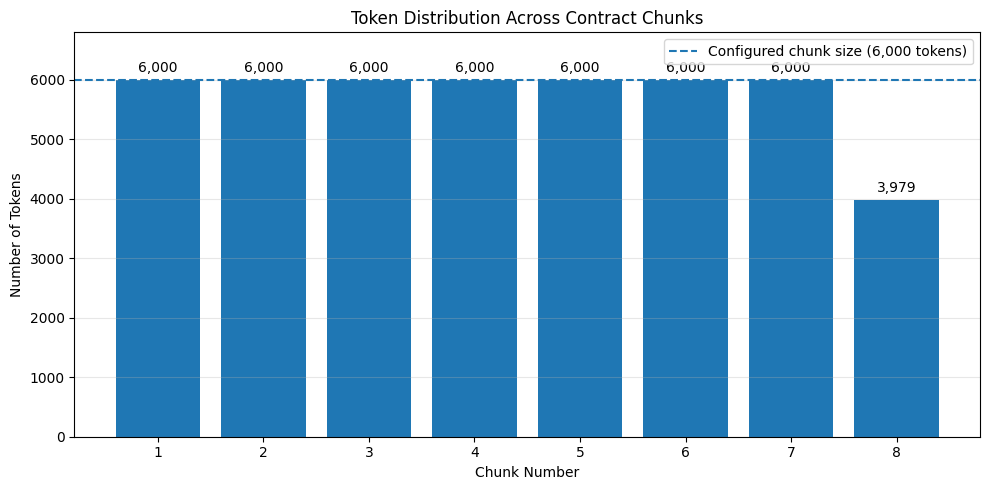

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# Use the chunk lengths calculated earlier
chunk_numbers = list(range(1, len(chunk_lengths) + 1))

plt.figure(figsize=(10, 5))

bars = plt.bar(chunk_numbers, chunk_lengths)

# LED input capacity reference
plt.axhline(
    y=6000,
    linestyle="--",
    label="Configured chunk size (6,000 tokens)"
)

plt.title("Token Distribution Across Contract Chunks")
plt.xlabel("Chunk Number")
plt.ylabel("Number of Tokens")
plt.xticks(chunk_numbers)
plt.ylim(0, 6800)
plt.grid(axis="y", alpha=0.3)
plt.legend()

# Display token counts above each bar
for bar, count in zip(bars, chunk_lengths):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 80,
        f"{count:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


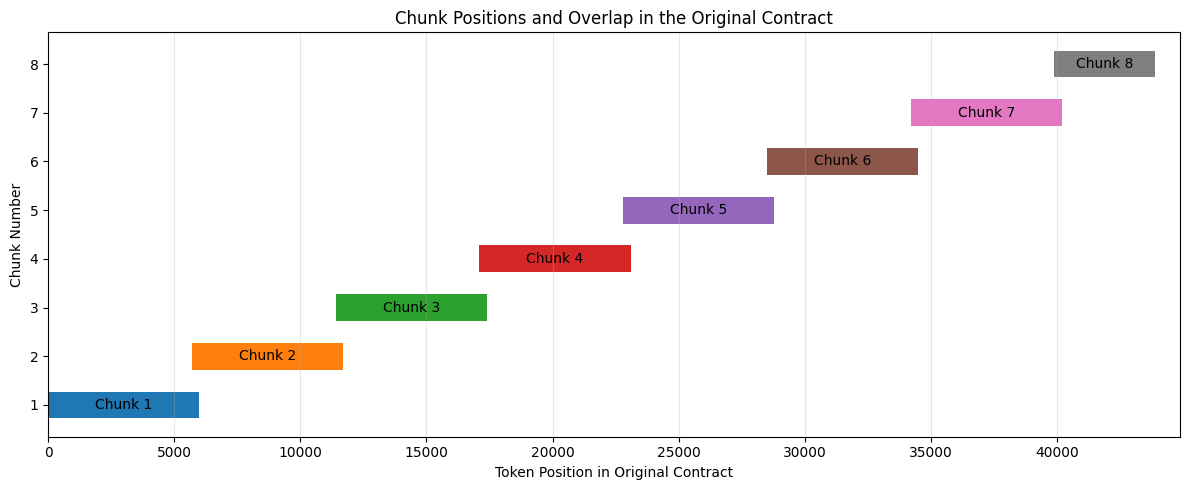

In [ ]:

import matplotlib.pyplot as plt

original_token_count = len(original_ids)
chunk_size = 6000
overlap = 300
step = chunk_size - overlap

plt.figure(figsize=(12, 5))

for i, start in enumerate(
    range(0, original_token_count, step),
    start=1
):
    end = min(start + chunk_size, original_token_count)

    plt.barh(
        y=i,
        width=end - start,
        left=start,
        height=0.55
    )

    plt.text(
        start + (end - start) / 2,
        i,
        f"Chunk {i}",
        ha="center",
        va="center"
    )

plt.title("Chunk Positions and Overlap in the Original Contract")
plt.xlabel("Token Position in Original Contract")
plt.ylabel("Chunk Number")
plt.yticks(range(1, len(chunks) + 1))
plt.xlim(0, original_token_count + 1000)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


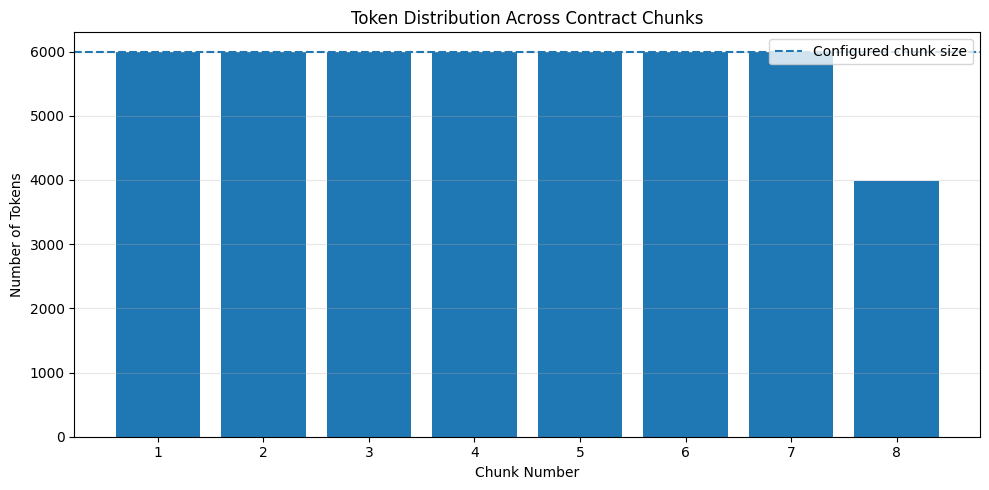

Saved visualization to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/evaluation/cuad_chunk_token_distribution.png


In [ ]:

from pathlib import Path

figure_path = (
    DRIVE_ROOT
    / "outputs/evaluation"
    / "cuad_chunk_token_distribution.png"
)

figure_path.parent.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(10, 5))
plt.bar(chunk_numbers, chunk_lengths)
plt.axhline(
    y=6000,
    linestyle="--",
    label="Configured chunk size"
)
plt.title("Token Distribution Across Contract Chunks")
plt.xlabel("Chunk Number")
plt.ylabel("Number of Tokens")
plt.xticks(chunk_numbers)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved visualization to:", figure_path)


In [ ]:

# STEP 1: Inspect CUAD question-answer annotations

from datasets import load_dataset
from pprint import pprint

DATASET_NAME = "theatticusproject/cuad-qa"

# Load a small sample of CUAD
cuad = load_dataset(
    DATASET_NAME,
    revision="refs/convert/parquet",
    split="train[:20]"
)

# Display available columns
print("Dataset columns:")
print(cuad.column_names)

print("\nNumber of sample rows:", len(cuad))

# Inspect one annotation
row = cuad[0]

print("\n--- CONTRACT TITLE ---")
print(row["title"])

print("\n--- ANNOTATION QUESTION ---")
print(row["question"])

print("\n--- ANNOTATED ANSWER ---")
pprint(row["answers"])

print("\n--- CONTRACT TEXT PREVIEW ---")
print(row["context"][:1000])

print("\n--- CONTRACT TEXT LENGTH ---")
print("Characters:", len(row["context"]))
print("Words:", len(row["context"].split()))


Dataset columns:
['id', 'title', 'context', 'question', 'answers']

Number of sample rows: 20

--- CONTRACT TITLE ---
LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT

--- ANNOTATION QUESTION ---
Highlight the parts (if any) of this contract related to "Document Name" that should be reviewed by a lawyer. Details: The name of the contract

--- ANNOTATED ANSWER ---
{'answer_start': [44], 'text': ['DISTRIBUTOR AGREEMENT']}

--- CONTRACT TEXT PREVIEW ---
EXHIBIT 10.6

                              DISTRIBUTOR AGREEMENT

         THIS  DISTRIBUTOR  AGREEMENT (the  "Agreement")  is made by and between Electric City Corp.,  a Delaware  corporation  ("Company")  and Electric City of Illinois LLC ("Distributor") this 7th day of September, 1999.

                                    RECITALS

         A. The  Company's  Business.  The Company is  presently  engaged in the business  of selling an energy  efficiency  device,  which is  referred to as an "Energy  Saver"  which may be improved  or

In [ ]:

# STEP 2: Check the dataset structure and unique contracts

print("Rows:", len(cuad))

unique_titles = set(cuad["title"])

print("Unique contract titles:", len(unique_titles))

print("\nFirst 10 annotation questions:")
for i in range(min(10, len(cuad))):
    print(f"\n{i + 1}. {cuad[i]['question']}")
    print("Answer:", cuad[i]["answers"])

# Check whether a likely summary field exists
possible_summary_fields = [
    "summary",
    "summaries",
    "reference_summary",
    "target"
]

available_summary_fields = [
    field for field in possible_summary_fields
    if field in cuad.column_names
]

print("\nPossible summary fields found:", available_summary_fields)


Rows: 20
Unique contract titles: 1

First 10 annotation questions:

1. Highlight the parts (if any) of this contract related to "Document Name" that should be reviewed by a lawyer. Details: The name of the contract
Answer: {'text': ['DISTRIBUTOR AGREEMENT'], 'answer_start': [44]}

2. Highlight the parts (if any) of this contract related to "Parties" that should be reviewed by a lawyer. Details: The two or more parties who signed the contract
Answer: {'text': ['Distributor'], 'answer_start': [244]}

3. Highlight the parts (if any) of this contract related to "Parties" that should be reviewed by a lawyer. Details: The two or more parties who signed the contract
Answer: {'text': ['Electric City of Illinois L.L.C.'], 'answer_start': [49574]}

4. Highlight the parts (if any) of this contract related to "Parties" that should be reviewed by a lawyer. Details: The two or more parties who signed the contract
Answer: {'text': ['Electric City of Illinois LLC'], 'answer_start': [212]}

5. Highligh

In [ ]:

from datasets import load_dataset
from collections import defaultdict, Counter
import re

DATASET_NAME = "theatticusproject/cuad-qa"

stream = load_dataset(
    DATASET_NAME,
    revision="refs/convert/parquet",
    split="train",
    streaming=True
)

MAX_CONTRACTS = 10
contract_titles = []
annotation_counts = Counter()
category_counts = Counter()
answer_counts = Counter()

seen_titles = set()

for row in stream:
    title = row["title"]

    if title not in seen_titles:
        if len(seen_titles) >= MAX_CONTRACTS:
            break
        seen_titles.add(title)
        contract_titles.append(title)

    annotation_counts[title] += 1

    # Extract the clause category from the question, if present
    match = re.search(r'related to "([^"]+)"', row["question"])
    if match:
        category_counts[match.group(1)] += 1

    answers = row["answers"].get("text", [])
    if any(answer.strip() for answer in answers):
        answer_counts[title] += 1

print("Distinct contracts inspected:", len(contract_titles))
print("\nAnnotations per contract:")

for title in contract_titles:
    print(
        f"- {title}: "
        f"{annotation_counts[title]} annotation rows, "
        f"{answer_counts[title]} rows with non-empty answers"
    )

print("\nMost frequent annotation categories:")
for category, count in category_counts.most_common(15):
    print(f"- {category}: {count}")


Distinct contracts inspected: 10

Annotations per contract:
- LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT: 68 annotation rows, 46 rows with non-empty answers
- WHITESMOKE,INC_11_08_2011-EX-10.26-PROMOTION AND DISTRIBUTION AGREEMENT: 56 annotation rows, 27 rows with non-empty answers
- NELNETINC_04_08_2020-EX-1-JOINT FILING AGREEMENT: 42 annotation rows, 4 rows with non-empty answers
- ADAMSGOLFINC_03_21_2005-EX-10.17-ENDORSEMENT AGREEMENT: 51 annotation rows, 23 rows with non-empty answers
- KIROMICBIOPHARMA,INC_05_11_2020-EX-10.23-CONSULTING AGREEMENT: 51 annotation rows, 24 rows with non-empty answers
- VEONEER,INC_02_21_2020-EX-10.11-JOINT VENTURE AGREEMENT: 51 annotation rows, 16 rows with non-empty answers
- MetLife, Inc. - Remarketing Agreement: 50 annotation rows, 16 rows with non-empty answers
- FTENETWORKS,INC_02_18_2016-EX-99.4-STRATEGIC ALLIANCE AGREEMENT: 58 annotation rows, 33 rows with non-empty answers
- DOMINIADVISORTRUST_02_18_2005-EX-99.(H)(2)-SPONSORSHIP AGRE

In [ ]:

from datasets import load_dataset
from collections import defaultdict
import pandas as pd
import re

stream = load_dataset(
    "theatticusproject/cuad-qa",
    revision="refs/convert/parquet",
    split="train",
    streaming=True
)

MAX_CONTRACTS = 10
records = {}
current_title = None

for row in stream:
    title = row["title"]

    # Stop only after reaching a new contract beyond our sample
    if title not in records and len(records) >= MAX_CONTRACTS:
        break

    if title not in records:
        records[title] = {
            "title": title,
            "context": row["context"],
            "annotations": []
        }

    records[title]["annotations"].append({
        "question": row["question"],
        "answers": row["answers"].get("text", [])
    })

# Summarize the annotation coverage per contract
report_rows = []

for title, record in records.items():
    annotations = record["annotations"]
    answered = [
        item for item in annotations
        if any(a.strip() for a in item["answers"])
    ]

    categories = set()
    for item in annotations:
        match = re.search(r'related to "([^"]+)"', item["question"])
        if match:
            categories.add(match.group(1))

    report_rows.append({
        "title": title,
        "contract_words": len(record["context"].split()),
        "annotation_rows": len(annotations),
        "nonempty_answer_rows": len(answered),
        "unique_categories": len(categories)
    })

report_df = pd.DataFrame(report_rows)

display(report_df)

# Inspect the first contract's annotated facts
sample_title = next(iter(records))
sample = records[sample_title]

print("\nCONTRACT:", sample_title)
print("\nANNOTATION-DERIVED FACTS:")

shown = 0
seen_facts = set()

for item in sample["annotations"]:
    match = re.search(r'related to "([^"]+)"', item["question"])
    category = match.group(1) if match else "Other"

    answers = [a.strip() for a in item["answers"] if a.strip()]

    for answer in answers:
        fact = (category, answer)
        if fact in seen_facts:
            continue

        seen_facts.add(fact)
        print(f"- {category}: {answer}")
        shown += 1

        if shown >= 20:
            break

    if shown >= 20:
        break


,title,contract_words,annotation_rows,nonempty_answer_rows,unique_categories
0,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,5998,68,46,41
1,"WHITESMOKE,INC_11_08_2011-EX-10.26-PROMOTION A...",11313,56,27,41
2,NELNETINC_04_08_2020-EX-1-JOINT FILING AGREEMENT,170,42,4,41
3,ADAMSGOLFINC_03_21_2005-EX-10.17-ENDORSEMENT A...,3770,51,23,41
4,"KIROMICBIOPHARMA,INC_05_11_2020-EX-10.23-CONSU...",2766,51,24,41
5,"VEONEER,INC_02_21_2020-EX-10.11-JOINT VENTURE ...",1334,51,16,41
6,"MetLife, Inc. - Remarketing Agreement",17518,50,16,41
7,"FTENETWORKS,INC_02_18_2016-EX-99.4-STRATEGIC A...",5761,58,33,41
8,DOMINIADVISORTRUST_02_18_2005-EX-99.(H)(2)-SPO...,1847,45,13,41
9,PfHospitalityGroupInc_20150923_10-12G_EX-10.1_...,1014,46,12,41



CONTRACT: LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT

ANNOTATION-DERIVED FACTS:
- Document Name: DISTRIBUTOR AGREEMENT
- Parties: Distributor
- Parties: Electric City of Illinois L.L.C.
- Parties: Electric City of Illinois LLC
- Parties: Company
- Parties: Electric City Corp.
- Agreement Date: 7th day of September, 1999.
- Effective Date: Unless  earlier   terminated   otherwise  provided                   therein,  this  Agreement,  subject to the  commencement  date                   established  in Section 1.3,  shall be effective  immediately.
- Effective Date: The term of this  Agreement  shall be ten (10)                            years (the "Term")  which shall  commence on the date                            upon which the Company  delivers to  Distributor  the                            last Sample, as defined  hereinafter.
- Expiration Date: The term of this  Agreement  shall be ten (10)                            years (the "Term")  which shall  commence on the da

In [ ]:

import json
import requests
import pandas as pd

url = (
    "https://raw.githubusercontent.com/"
    "lauramanor/legal_summarization/master/all_v1.json"
)

response = requests.get(url, timeout=30)
response.raise_for_status()

data = response.json()

# The published file is organized as records keyed by identifier.
if isinstance(data, dict):
    records = [
        {"uid": uid, **record}
        for uid, record in data.items()
        if isinstance(record, dict)
    ]
elif isinstance(data, list):
    records = data
else:
    raise ValueError(f"Unexpected JSON structure: {type(data)}")

summary_df = pd.DataFrame(records)

print("Available columns:")
print(summary_df.columns.tolist())

print("\nDataset shape:", summary_df.shape)

required = ["original_text", "reference_summary"]
missing = [c for c in required if c not in summary_df.columns]

if missing:
    print("\nRequired columns missing:", missing)
else:
    summary_df = summary_df.dropna(
        subset=["original_text", "reference_summary"]
    ).copy()

    summary_df["source_words"] = (
        summary_df["original_text"].astype(str).str.split().str.len()
    )
    summary_df["summary_words"] = (
        summary_df["reference_summary"].astype(str).str.split().str.len()
    )

    print("Usable text-summary pairs:", len(summary_df))
    print("\nExample source text:")
    print(summary_df.iloc[0]["original_text"][:700])

    print("\nExample reference summary:")
    print(summary_df.iloc[0]["reference_summary"])

    print("\nLength statistics:")
    display(
        summary_df[
            ["source_words", "summary_words"]
        ].describe().round(1)
    )


Available columns:
['uid', 'doc', 'id', 'original_text', 'reference_summary', 'title', 'case_code', 'case_text', 'note', 'title_code', 'title_text', 'urls', 'tldr_code', 'tldr_text']

Dataset shape: (446, 14)
Usable text-summary pairs: 446

Example source text:
welcome to the pokémon go video game services which are accessible via the niantic inc niantic mobile device application the app. to make these pokémon go terms of service the terms easier to read our video game services the app and our websites located at http pokemongo nianticlabs com and http www pokemongolive com the site are collectively called the services. please read carefully these terms our trainer guidelines and our privacy policy because they govern your use of our services.

Example reference summary:
hi.

Length statistics:


,source_words,summary_words
count,446.0,446.0
mean,101.9,16.0
std,143.4,11.3
min,7.0,1.0
25%,32.2,9.0
50%,58.5,13.0
75%,103.0,18.0
max,1077.0,80.0


Total examples: 446
Candidate examples after basic screening: 341

Examples per source document:


,examples,mean_source_words,mean_summary_words
doc,,,
Privacy Policy,111,65.1,12.6
Terms of Service,81,78.8,18.5
Terms of Use,39,56.6,14.5
Legal Documents,26,66.2,17.7
Pokemon GO Terms of Service,19,340.9,21.2
Android SDK License Agreement (June 2014),15,70.8,6.4
YouTube Terms of Service,10,272.0,16.8
Minecraft End User Licence Agreement,10,131.9,15.3
Open-Source Terms,9,34.6,13.4



Shortest candidate summaries:


,doc,title,original_text,reference_summary,source_words,summary_words
47,Android SDK License Agreement (June 2014),3.4,you agree that you will not take any actions t...,don t fork the sdk.,43,5
46,Android SDK License Agreement (June 2014),​3.3,you may not use the sdk for any purpose not ex...,don t hack the sdk.,97,5
58,Android SDK License Agreement (June 2014),​10.3,google further expressly disclaims all warrant...,it comes with no warranty.,35,5
53,Android SDK License Agreement (June 2014),5.1,you agree that you are responsible for maintai...,keep your password certificates safe.,45,5
111,Terms and Conditions of Use,NaN,if you do not want to continue to be charged o...,spotify doesn t provide refunds.,91,5
332,Terms of Use,NaN,with respect to the content or other materials...,you maintain ownership of your data.,52,6
385,Terms,NaN,to the extent permitted by applicable law you ...,defend indemnify hold harmless survives termin...,88,6
338,Privacy Statement,NaN,cookies are only used in so far as they are re...,this service does not track you.,30,6
101,Open-Source Terms,NaN,nothing in this agreement gives npm any owners...,you maintain ownership of your data.,33,6
85,Privacy Policy,NaN,search encrypt does not track search history i...,this service does not track you.,52,6


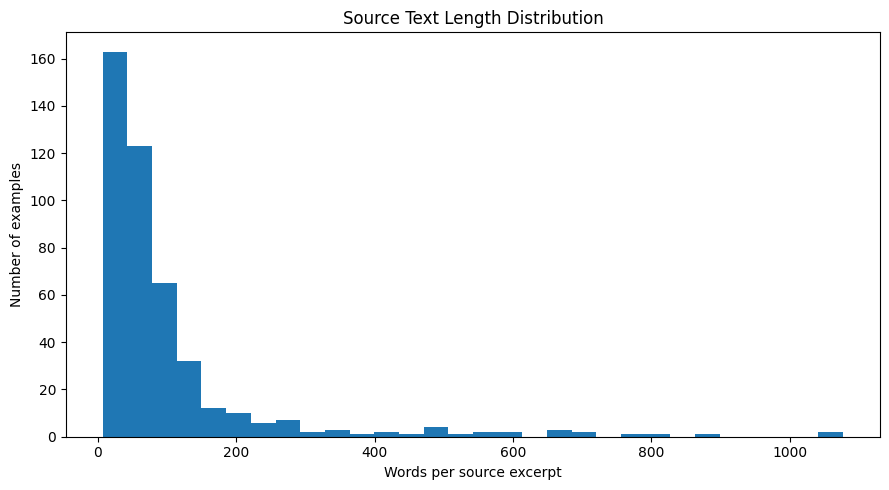

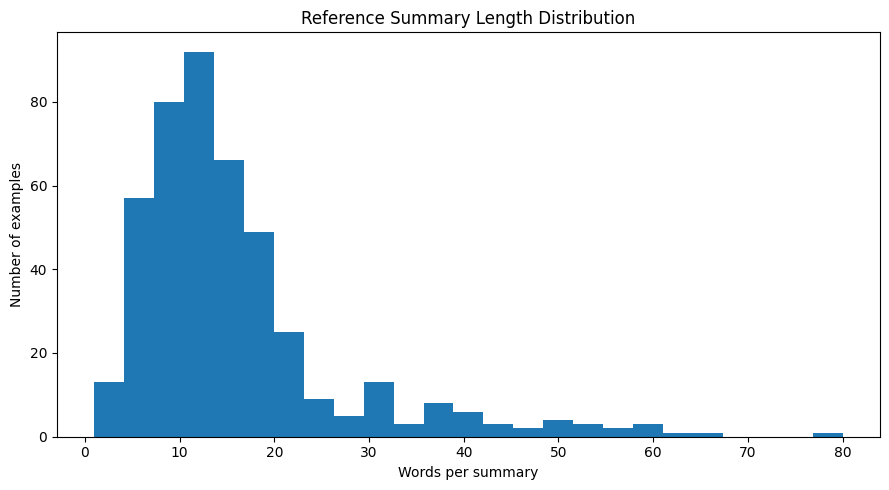

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

audit_df = summary_df.copy()

# Normalize text fields
for col in ["doc", "original_text", "reference_summary"]:
    audit_df[col] = audit_df[col].fillna("").astype(str).str.strip()

audit_df["source_words"] = audit_df["original_text"].str.split().str.len()
audit_df["summary_words"] = audit_df["reference_summary"].str.split().str.len()

# Identify obviously weak or empty examples.
# These are screening rules, not a guarantee of summary quality.
audit_df["usable_candidate"] = (
    (audit_df["source_words"] >= 30)
    & (audit_df["summary_words"] >= 5)
    & (audit_df["reference_summary"].str.lower() != "hi.")
)

print("Total examples:", len(audit_df))
print("Candidate examples after basic screening:",
      int(audit_df["usable_candidate"].sum()))

print("\nExamples per source document:")
display(
    audit_df.groupby("doc", dropna=False)
    .agg(
        examples=("uid", "count"),
        mean_source_words=("source_words", "mean"),
        mean_summary_words=("summary_words", "mean")
    )
    .sort_values("examples", ascending=False)
    .round(1)
    .head(20)
)

print("\nShortest candidate summaries:")
display(
    audit_df.loc[
        audit_df["usable_candidate"],
        ["doc", "title", "original_text", "reference_summary",
         "source_words", "summary_words"]
    ]
    .sort_values("summary_words")
    .head(10)
)

# Visualize source and summary lengths
plt.figure(figsize=(9, 5))
plt.hist(audit_df["source_words"], bins=30)
plt.title("Source Text Length Distribution")
plt.xlabel("Words per source excerpt")
plt.ylabel("Number of examples")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.hist(audit_df["summary_words"], bins=25)
plt.title("Reference Summary Length Distribution")
plt.xlabel("Words per summary")
plt.ylabel("Number of examples")
plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd

# Work on a copy; preserve the original dataset
quality_df = audit_df.copy()

# Basic data-quality checks
quality_df["source_normalized"] = (
    quality_df["original_text"].str.lower().str.replace(r"\s+", " ", regex=True)
)
quality_df["summary_normalized"] = (
    quality_df["reference_summary"].str.lower().str.replace(r"\s+", " ", regex=True)
)

print("Total examples:", len(quality_df))
print("Exact duplicate source texts:",
      quality_df["source_normalized"].duplicated().sum())
print("Exact duplicate reference summaries:",
      quality_df["summary_normalized"].duplicated().sum())

# Inspect available identifiers and source metadata
for col in ["doc", "uid", "id", "urls", "case_code", "title"]:
    if col in quality_df.columns:
        print(f"\n{col}:")
        print("  Unique non-empty values:",
              quality_df[col].replace("", pd.NA).nunique())
        print("  Missing values:",
              quality_df[col].isna().sum())

# Display a reproducible sample of candidate pairs
candidate_df = quality_df.loc[
    quality_df["usable_candidate"]
].copy()

sample_df = candidate_df.sample(
    n=min(12, len(candidate_df)),
    random_state=42
)

for i, (_, row) in enumerate(sample_df.iterrows(), start=1):
    print(f"\n{'=' * 65}")
    print(f"EXAMPLE {i}")
    print("Document type:", row.get("doc", "Unknown"))
    print("Title:", row.get("title", "Unknown"))
    print("Source words:", row["source_words"])
    print("Reference summary:", row["reference_summary"])
    print("Source excerpt:")
    print(row["original_text"][:600])


Total examples: 446
Exact duplicate source texts: 1
Exact duplicate reference summaries: 156

doc:
  Unique non-empty values: 59
  Missing values: 0

uid:
  Unique non-empty values: 446
  Missing values: 0

id:
  Unique non-empty values: 85
  Missing values: 361

urls:
  Unique non-empty values: 112
  Missing values: 85

case_code:
  Unique non-empty values: 10
  Missing values: 329

title:
  Unique non-empty values: 58
  Missing values: 361

EXAMPLE 1
Document type: Cookie Policy
Title: nan
Source words: 31
Reference summary: the service uses your personal data to employ targeted third party advertising.
Source excerpt:
we use cookies to help us show ads and to make recommendations for businesses and other organizations to people who may be interested in the products services or causes they promote.

EXAMPLE 2
Document type: Terms of Use
Title: nan
Source words: 64
Reference summary: service does not allow alternative accounts.
Source excerpt:
you also agree to register one account on

In [ ]:

import pandas as pd

# Start with the screened candidates
candidates = audit_df.loc[
    audit_df["usable_candidate"]
].copy()

# Normalize text for comparison
for col in ["original_text", "reference_summary"]:
    candidates[col + "_norm"] = (
        candidates[col]
        .fillna("")
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

print("Candidate examples:", len(candidates))

# Exact duplicate source passages
duplicate_sources = candidates[
    candidates.duplicated("original_text_norm", keep=False)
].sort_values("original_text_norm")

print("\nRows belonging to duplicate source groups:",
      len(duplicate_sources))

if not duplicate_sources.empty:
    display(
        duplicate_sources[
            ["doc", "title", "original_text", "reference_summary"]
        ].head(10)
    )

# Repeated summaries
summary_frequency = (
    candidates.groupby("reference_summary_norm")
    .agg(
        count=("uid", "size"),
        distinct_sources=("original_text_norm", "nunique"),
        examples=("uid", lambda s: ", ".join(map(str, s.head(5))))
    )
    .sort_values("count", ascending=False)
)

print("\nMost frequent reference summaries:")
display(summary_frequency.head(15))

# Show examples for manual mismatch review
review_indices = [1, 5, 7, 10, 11]

print("\nSelected examples for manual quality review:")
for idx in review_indices:
    if idx in candidates.index:
        row = candidates.loc[idx]
        print("\n" + "=" * 60)
        print("Index:", idx)
        print("Document:", row["doc"])
        print("Source:", row["original_text"][:500])
        print("Reference summary:", row["reference_summary"])


Candidate examples: 341

Rows belonging to duplicate source groups: 2


,doc,title,original_text,reference_summary
146,Data Policy,NaN,since the like button is a little piece of fac...,many third parties are involved in operating t...
422,What information does Facebook get when I visi...,NaN,since the like button is a little piece of fac...,this service tracks you on other websites.



Most frequent reference summaries:


,count,distinct_sources,examples
reference_summary_norm,,,
terms may be changed any time at their discretion without notice to the user.,10,10,"tosdr042, tosdr061, tosdr110, tosdr170, tosdr213"
the service may use tracking pixels web beacons browser fingerprinting and or device fingerprinting on users.,9,9,"tosdr034, tosdr050, tosdr053, tosdr107, tosdr138"
third parties may be involved in operating the service.,7,7,"tosdr045, tosdr125, tosdr203, tosdr209, tosdr228"
you are responsible for maintaining the security of your account and for the activities on your account.,7,7,"tosdr169, tosdr199, tosdr259, tosdr269, tosdr276"
they can change the terms of service any time they see fit even without notification to the user. your use of the service supposedly constitutes acceptance of the changes in the terms.,7,7,"tosdr043, tosdr056, tosdr133, tosdr148, tosdr231"
you waive your right to a class action.,5,5,"tosdr108, tosdr136, tosdr355, tosdr363, tosdr411"
you agree to defend indemnify and hold the service harmless in case of a claim related to your use of the service.,5,5,"tosdr022, tosdr058, tosdr060, tosdr318, tosdr408"
the service can delete your account without prior notice and without a reason.,5,5,"tosdr073, tosdr208, tosdr243, tosdr295, tosdr367"
this service does not track you.,4,4,"tosdr001, tosdr214, tosdr237, tosdr300"



Selected examples for manual quality review:

Index: 1
Document: Pokemon GO Terms of Service
Source: by using our services you are agreeing to these terms our trainer guidelines and our privacy policy. if you are the parent or legal guardian of a child under the age of 13 the parent you are agreeing to these terms on behalf of yourself and your child ren who are authorized to use the services pursuant to these terms and in our privacy policy. if you don t agree to these terms our trainer guidelines and our privacy policy do not use the services.
Reference summary: by playing this game you agree to these terms. if you re under 13 and playing your parent guardian agrees on your behalf.

Index: 5
Document: Pokemon GO Terms of Service
Source: for purposes of these terms a content means the text software scripts graphics photos sounds music videos audiovisual combinations interactive features works of authorship of any kind and information or other materials that are posted generated provi

In [ ]:

# Inspect duplicate source passages and document metadata

duplicate_rows = candidates[
    candidates.duplicated("original_text_norm", keep=False)
].copy()

metadata_cols = [
    col for col in [
        "uid", "id", "doc", "title", "urls",
        "case_code", "original_text", "reference_summary"
    ]
    if col in duplicate_rows.columns
]

print("Duplicate-source records:")
display(duplicate_rows[metadata_cols])

print("\nSample identifier and URL values:")
for col in ["id", "urls", "case_code"]:
    if col in candidates.columns:
        print(f"\n{col}:")
        values = candidates[col].dropna().astype(str)
        print(values.head(12).to_list())
        print("Unique non-empty values:", values.nunique())

# Show examples that share a source URL, where URL metadata exists
if "urls" in candidates.columns:
    url_df = candidates.copy()
    url_df["url_key"] = (
        url_df["urls"].fillna("").astype(str).str.strip()
    )
    url_df = url_df[url_df["url_key"] != ""]

    repeated_urls = url_df[
        url_df.duplicated("url_key", keep=False)
    ].sort_values("url_key")

    print("\nRows with repeated non-empty URL values:",
          len(repeated_urls))

    display(
        repeated_urls[
            ["uid", "id", "doc", "urls", "reference_summary"]
        ].head(15)
    )


Duplicate-source records:


,uid,id,doc,title,urls,case_code,original_text,reference_summary
146,tosdr071,NaN,Data Policy,NaN,{'instagram.com'},"1,s",since the like button is a little piece of fac...,many third parties are involved in operating t...
422,tosdr397,NaN,What information does Facebook get when I visi...,NaN,{'facebook.com'},NaN,since the like button is a little piece of fac...,this service tracks you on other websites.



Sample identifier and URL values:

id:
['57866df76cca83a54c0035a1', '5786730a6cca83a54c0035b6', '57866df76cca83a54c0035a0', '57866df76cca83a54c00359f', '57866df76cca83a54c00359e', '57866df76cca83a54c00359d', '5786730a6cca83a54c0035b5', '57866df76cca83a54c00359c', '57866f006cca83a54c0035a5', '5786730a6cca83a54c0035b4', '5786730a6cca83a54c0035b3', '5786730a6cca83a54c0035b2']
Unique non-empty values: 75

urls:
["{'searchencrypt.com'}", "{'stackoverflow.com'}", "{'flickr.com'}", "{'jagex.com'}", "{'musicbrainz.org'}", "{'stackoverflow.com'}", "{'npm.im', 'npmjs.com', 'npmjs.org'}", "{'npm.im', 'npmjs.com', 'npmjs.org'}", "{'npm.im', 'npmjs.com', 'npmjs.org'}", "{'npm.im', 'npmjs.com', 'npmjs.org'}", "{'spotify.com'}", "{'spotify.com'}"]
Unique non-empty values: 90

case_code:
['1,s', '2,s', '2,s', '3,s', '3,s', '1,j', '1,s', '1,j', '1,s', '3,s', '2,s', '2,s']
Unique non-empty values: 9

Rows with repeated non-empty URL values: 229


,uid,id,doc,urls,reference_summary
175,tosdr111,NaN,Terms of Service,"{'500px.me', '500px.net', '500px.org', '500px....",the copyright license you grant to 500px is tr...
174,tosdr110,NaN,Terms of Service,"{'500px.me', '500px.net', '500px.org', '500px....",terms may be changed any time at their discret...
173,tosdr109,NaN,Terms of Service,"{'500px.me', '500px.net', '500px.org', '500px....",you do not have to provide your legal name exc...
172,tosdr108,NaN,Terms of Service,"{'500px.me', '500px.net', '500px.org', '500px....",you waive your right to a class action.
233,tosdr180,NaN,Terms of Service,{'airbnb.com'},when the service wants to change its terms use...
241,tosdr188,NaN,Privacy Policy,{'airbnb.com'},this service will continue using anonymized us...
240,tosdr187,NaN,Terms of Service,{'airbnb.com'},failure to enforce any provision of the terms ...
239,tosdr186,NaN,Terms of Service,{'airbnb.com'},invalidity of any portion of the terms of serv...
238,tosdr185,NaN,Terms of Service,{'airbnb.com'},if you reside in the united states of america ...
236,tosdr183,NaN,Terms of Service,{'airbnb.com'},users who have been permanently banned from th...


In [ ]:

import ast
import re
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

df = candidates.copy().reset_index(drop=True)

# Normalize source passages and summaries for duplicate checking
def normalize_text(value):
    if pd.isna(value):
        return ""
    value = str(value).lower().strip()
    return re.sub(r"\s+", " ", value)

df["original_text_norm"] = df["original_text"].apply(normalize_text)
df["summary_normalized"] = df["reference_summary"].apply(normalize_text)

# Parse domain sets
def parse_domains(value):
    if pd.isna(value):
        return set()
    try:
        parsed = ast.literal_eval(str(value))
        if isinstance(parsed, str):
            parsed = [parsed]
        if isinstance(parsed, (set, list, tuple)):
            return {
                str(x).strip().lower().replace("\\.", ".")
                for x in parsed if str(x).strip()
            }
    except (ValueError, SyntaxError):
        pass

    return set(
        re.findall(
            r"[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}",
            str(value).replace("\\.", ".").lower()
        )
    )

df["domains"] = df["urls"].apply(parse_domains)

# Build groups using shared domains and case_code when URL is missing
parent = list(range(len(df)))

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

owners = {}

for i, row in df.iterrows():
    if row["domains"]:
        for domain in row["domains"]:
            if domain in owners:
                union(i, owners[domain])
            else:
                owners[domain] = i
    else:
        code = row.get("case_code")
        if pd.notna(code) and str(code).strip():
            key = "case_code:" + str(code).strip()
            if key in owners:
                union(i, owners[key])
            else:
                owners[key] = i

df["group_id"] = [find(i) for i in range(len(df))]

# Check identical source passages with conflicting summaries
conflict_counts = df.groupby("original_text_norm")[
    "summary_normalized"
].nunique()

conflict_texts = conflict_counts[conflict_counts > 1].index
conflict_rows = df[
    df["original_text_norm"].isin(conflict_texts)
]

print("Candidate rows:", len(df))
print("Distinct groups:", df["group_id"].nunique())
print("Rows in duplicate-source groups with different summaries:",
      len(conflict_rows))

if len(conflict_rows):
    display(conflict_rows[
        ["uid", "doc", "urls", "original_text",
         "reference_summary", "group_id"]
    ])

# Group-based split: approximately 70% / 15% / 15%
split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=42
)
train_val_idx, test_idx = next(
    split1.split(df, groups=df["group_id"])
)

train_val = df.iloc[train_val_idx].copy()
test_df = df.iloc[test_idx].copy()

split2 = GroupShuffleSplit(
    n_splits=1, test_size=0.1875, random_state=43
)
train_idx, val_idx = next(
    split2.split(train_val, groups=train_val["group_id"])
)

train_df = train_val.iloc[train_idx].copy()
val_df = train_val.iloc[val_idx].copy()

# Verify that groups do not cross splits
train_groups = set(train_df["group_id"])
val_groups = set(val_df["group_id"])
test_groups = set(test_df["group_id"])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

print("\nSplit sizes:")
print(f"Train:      {len(train_df)} examples")
print(f"Validation: {len(val_df)} examples")
print(f"Test:       {len(test_df)} examples")
print("\nLeakage check passed: no group appears in multiple splits.")


Candidate rows: 341
Distinct groups: 165
Rows in duplicate-source groups with different summaries: 2


,uid,doc,urls,original_text,reference_summary,group_id
112,tosdr071,Data Policy,{'instagram.com'},since the like button is a little piece of fac...,many third parties are involved in operating t...,113
318,tosdr397,What information does Facebook get when I visi...,{'facebook.com'},since the like button is a little piece of fac...,this service tracks you on other websites.,324



Split sizes:
Train:      198 examples
Validation: 68 examples
Test:       75 examples

Leakage check passed: no group appears in multiple splits.


In [ ]:

import re
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# Start from the dataset prepared in the previous step
clean_df = df.copy()

# Ensure normalization columns exist
def normalize_text(value):
    if pd.isna(value):
        return ""
    return re.sub(r"\s+", " ", str(value).lower().strip())

clean_df["original_text_norm"] = clean_df["original_text"].apply(normalize_text)
clean_df["summary_normalized"] = clean_df["reference_summary"].apply(normalize_text)

# Find source passages that have multiple different reference summaries
summary_counts = clean_df.groupby("original_text_norm")[
    "summary_normalized"
].nunique()

conflicting_sources = summary_counts[summary_counts > 1].index

# Temporarily exclude these records until manually reviewed
before_count = len(clean_df)
clean_df = clean_df[
    ~clean_df["original_text_norm"].isin(conflicting_sources)
].copy().reset_index(drop=True)

print("Rows before conflict review:", before_count)
print("Rows temporarily excluded:", before_count - len(clean_df))
print("Rows remaining:", len(clean_df))

# Basic data quality checks
clean_df["source_words"] = clean_df["original_text"].fillna("").str.split().str.len()
clean_df["summary_words"] = clean_df["reference_summary"].fillna("").str.split().str.len()

print("\nSource word-count statistics:")
display(clean_df["source_words"].describe().to_frame())

print("\nSummary word-count statistics:")
display(clean_df["summary_words"].describe().to_frame())

print("\nEmpty source passages:", (clean_df["source_words"] == 0).sum())
print("Empty reference summaries:", (clean_df["summary_words"] == 0).sum())
print("Summaries shorter than 5 words:", (clean_df["summary_words"] < 5).sum())

# Keep existing group IDs to preserve domain/case-code grouping
# Split groups into train, validation, and test
split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=42
)
train_val_idx, test_idx = next(
    split1.split(clean_df, groups=clean_df["group_id"])
)

train_val = clean_df.iloc[train_val_idx].copy()
test_df = clean_df.iloc[test_idx].copy()

split2 = GroupShuffleSplit(
    n_splits=1, test_size=0.1875, random_state=43
)
train_idx, val_idx = next(
    split2.split(train_val, groups=train_val["group_id"])
)

train_df = train_val.iloc[train_idx].copy()
val_df = train_val.iloc[val_idx].copy()

# Confirm no group appears in more than one split
assert set(train_df.group_id).isdisjoint(set(val_df.group_id))
assert set(train_df.group_id).isdisjoint(set(test_df.group_id))
assert set(val_df.group_id).isdisjoint(set(test_df.group_id))

print("\nFinal split sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Group leakage check: PASSED")

# Inspect examples for manual quality review
print("\nRandom examples for manual review:")
display(
    clean_df.sample(min(8, len(clean_df)), random_state=42)[
        ["uid", "doc", "original_text", "reference_summary",
         "source_words", "summary_words"]
    ]
)


Rows before conflict review: 341
Rows temporarily excluded: 2
Rows remaining: 339

Source word-count statistics:


,source_words
count,339.000000
mean,122.867257
std,152.010890
min,30.000000
25%,48.000000
50%,73.000000
75%,118.500000
max,1077.000000



Summary word-count statistics:


,summary_words
count,339.000000
mean,17.755162
std,12.191601
min,5.000000
25%,10.000000
50%,14.000000
75%,19.000000
max,80.000000



Empty source passages: 0
Empty reference summaries: 0
Summaries shorter than 5 words: 0

Final split sizes:
Train: 196
Validation: 68
Test: 75
Group leakage check: PASSED

Random examples for manual review:


,uid,doc,original_text,reference_summary,source_words,summary_words
284,tosdr350,Terms of Service,lastpass has the right though not the obligati...,lastpass will not provide refunds if they term...,74,14
116,tosdr081,Terms of Service,researchgate strives to connect the world of s...,pseudonym not allowed user to user trust is re...,165,11
113,tosdr073,Terms of Service,uber may immediately terminate these terms or ...,the service can delete your account without pr...,33,13
42,legalsum45,YouTube Terms of Service,12. ability to accept terms of serviceyou affi...,you must be 13 years or older.,123,7
126,tosdr107,Privacy Policy,we may also automatically collect device speci...,the service may use tracking pixels web beacon...,43,16
231,tosdr265,Terms of Service,you hereby grant youtube a worldwide non exclu...,the user grants youtube a worldwide non exclus...,111,49
181,tosdr188,Privacy Policy,information you have shared with others e g re...,this service will continue using anonymized us...,38,15
278,tosdr341,Legal Documents,c any material downloaded or otherwise obtaine...,discogs is not liable for any damages to the u...,51,22


In [ ]:

from pathlib import Path
import json
import torch
import pandas as pd

# Save project data in Google Drive
processed_dir = DRIVE_ROOT / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

columns_to_save = [
    "uid", "doc", "original_text", "reference_summary", "group_id"
]

for split_name, split_df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df),
]:
    output_path = processed_dir / f"legal_summary_{split_name}.csv"
    split_df[columns_to_save].to_csv(output_path, index=False)
    print(f"Saved {split_name}: {output_path}")

# Save a small dataset manifest
manifest = {
    "dataset": "Supplementary short legal/policy excerpt summarization",
    "candidate_rows_before_conflict_review": 341,
    "rows_excluded_for_conflicting_duplicate_sources": 2,
    "rows_after_exclusion": len(clean_df),
    "train_rows": len(train_df),
    "validation_rows": len(val_df),
    "test_rows": len(test_df),
    "group_leakage_check": "passed",
    "note": (
        "Not a full commercial-contract summarization dataset. "
        "Review reference-summary quality and dataset licensing."
    ),
}

with open(processed_dir / "dataset_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print("\nPyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. In Colab, try Runtime > Change runtime type > T4 GPU.")


Saved train: /content/drive/MyDrive/Legal_AI_Summarization/data/processed/legal_summary_train.csv
Saved validation: /content/drive/MyDrive/Legal_AI_Summarization/data/processed/legal_summary_validation.csv
Saved test: /content/drive/MyDrive/Legal_AI_Summarization/data/processed/legal_summary_test.csv

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:

import torch
from transformers import LEDTokenizer, LEDForConditionalGeneration

MODEL_NAME = "allenai/led-base-16384"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

led_tokenizer = LEDTokenizer.from_pretrained(MODEL_NAME)

led_model = LEDForConditionalGeneration.from_pretrained(
    MODEL_NAME
).to(device)

led_model.eval()

print("Model:", MODEL_NAME)
print("Device:", device)
print("Parameters:", f"{led_model.num_parameters():,}")
print("Maximum source positions:",
      led_model.config.max_encoder_position_embeddings)
print("Maximum target positions:",
      led_model.config.max_decoder_position_embeddings)


Loading weights:   0%|          | 0/299 [00:00<?, ?it/s]

Model: allenai/led-base-16384
Device: cuda
Parameters: 161,844,480
Maximum source positions: 16384
Maximum target positions: 1024


In [ ]:

def generate_led_summary(
    text,
    max_input_tokens=4096,
    max_new_tokens=128
):
    inputs = led_tokenizer(
        str(text),
        return_tensors="pt",
        max_length=max_input_tokens,
        truncation=True
    )

    inputs = {key: value.to(device) for key, value in inputs.items()}

    # LED requires global attention for selected tokens.
    global_attention_mask = torch.zeros_like(inputs["input_ids"])
    global_attention_mask[:, 0] = 1

    with torch.no_grad():
        output_ids = led_model.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            global_attention_mask=global_attention_mask,
            max_new_tokens=max_new_tokens,
            num_beams=2,
            do_sample=False,
            no_repeat_ngram_size=3
        )

    return led_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )

sample_test = test_df.sample(
    n=min(3, len(test_df)),
    random_state=42
).copy()

baseline_results = []

for _, row in sample_test.iterrows():
    prediction = generate_led_summary(row["original_text"])

    baseline_results.append({
        "uid": row["uid"],
        "source_text": row["original_text"],
        "reference_summary": row["reference_summary"],
        "led_baseline_summary": prediction
    })

baseline_preview_df = __import__("pandas").DataFrame(baseline_results)
display(baseline_preview_df)


[transformers] Input ids are automatically padded from 1189 to 2048 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 41 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 51 to 1024 to be a multiple of `config.attention_window`: 1024


,uid,source_text,reference_summary,led_baseline_summary
0,legalsum21,conditioned upon your compliance with the term...,we can revoke service at any time. you must as...,conditioned upon your compliance with the term...
1,tosdr271,if you wish to cancel your account or request ...,reputation com service cannot be canceled onli...,if you wish to cancel your account or request ...
2,legalsum57,if you use any api to retrieve a user s data f...,get explicit consent if you want to use any us...,if you use any api to retrieve a user s data f...


In [ ]:

import pandas as pd
import torch
from pathlib import Path
from tqdm.auto import tqdm

led_model.eval()
baseline_predictions = []

for _, row in tqdm(test_df.iterrows(), total=len(test_df)):
    source = str(row["original_text"])
    reference = str(row["reference_summary"])

    prediction = generate_led_summary(
        source,
        max_input_tokens=4096,
        max_new_tokens=128
    )

    baseline_predictions.append({
        "uid": row["uid"],
        "source_text": source,
        "reference_summary": reference,
        "led_baseline_summary": prediction
    })

baseline_test_df = pd.DataFrame(baseline_predictions)

output_dir = DRIVE_ROOT / "outputs" / "evaluation"
output_dir.mkdir(parents=True, exist_ok=True)

baseline_path = output_dir / "led_baseline_test_predictions.csv"
baseline_test_df.to_csv(baseline_path, index=False)

print("Predictions generated:", len(baseline_test_df))
print("Saved to:", baseline_path)
display(baseline_test_df.head(5))


  0%|          | 0/75 [00:00<?, ?it/s]

[transformers] Input ids are automatically padded from 83 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 269 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 1231 to 2048 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 388 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 539 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 197 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 105 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 99 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded

Predictions generated: 75
Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/evaluation/led_baseline_test_predictions.csv


,uid,source_text,reference_summary,led_baseline_summary
0,legalsum11,we welcome feedback comments and suggestions f...,give us feedback and we can do whatever we wan...,we welcome feedback comments and suggestions f...
1,legalsum14,your use of the app and services are at your o...,lots of yelling. oh you re responsible for you...,your use of the app and services are at your o...
2,legalsum17,governing lawthese terms and any action relate...,if you have issues with these terms you agree ...,governing lawthese terms and any action relate...
3,legalsum18,these terms and any action related thereto wil...,california governs these terms. we ll let you ...,these terms and any action related thereto wil...
4,legalsum21,conditioned upon your compliance with the term...,we can revoke service at any time. you must as...,conditioned upon your compliance with the term...


In [ ]:

import evaluate
import numpy as np

rouge = evaluate.load("rouge")

references = baseline_test_df["reference_summary"].fillna("").tolist()
predictions = baseline_test_df["led_baseline_summary"].fillna("").tolist()

rouge_scores = rouge.compute(
    predictions=predictions,
    references=references,
    use_stemmer=True
)

rouge_results = pd.DataFrame([
    {"Metric": metric, "Score": round(score, 4)}
    for metric, score in rouge_scores.items()
])

display(rouge_results)

scores_path = output_dir / "led_baseline_rouge_scores.csv"
rouge_results.to_csv(scores_path, index=False)

print("ROUGE scores saved to:", scores_path)


,Metric,Score
0,rouge1,0.2106
1,rouge2,0.0710
2,rougeL,0.1595
3,rougeLsum,0.1604


ROUGE scores saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/evaluation/led_baseline_rouge_scores.csv


In [ ]:

from transformers import (
    DataCollatorForSeq2Seq,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments
)

print("Required training classes imported successfully.")
print("LED model loaded:", led_model is not None)
print("Tokenizer loaded:", led_tokenizer is not None)


Required training classes imported successfully.
LED model loaded: True
Tokenizer loaded: True


In [ ]:

# Restore the training configuration variables
MODEL_NAME = "allenai/led-base-16384"
MAX_INPUT_LENGTH = 512
MAX_TARGET_LENGTH = 128

print("Model:", MODEL_NAME)
print("Maximum input tokens:", MAX_INPUT_LENGTH)
print("Maximum target tokens:", MAX_TARGET_LENGTH)


Model: allenai/led-base-16384
Maximum input tokens: 512
Maximum target tokens: 128


In [ ]:

import pandas as pd
from datasets import Dataset
from transformers import LEDTokenizer

MODEL_NAME = "allenai/led-base-16384"
MAX_INPUT_LENGTH = 512
MAX_TARGET_LENGTH = 128

processed_dir = DRIVE_ROOT / "data" / "processed"

train_data = pd.read_csv(processed_dir / "legal_summary_train.csv")
val_data = pd.read_csv(processed_dir / "legal_summary_validation.csv")

led_tokenizer = LEDTokenizer.from_pretrained(MODEL_NAME)

def preprocess_batch(batch):
    prompts = [
        "Summarize this legal provision in plain English: " + str(text)
        for text in batch["original_text"]
    ]

    inputs = led_tokenizer(
        prompts,
        max_length=MAX_INPUT_LENGTH,
        truncation=True
    )

    targets = led_tokenizer(
        text_target=[str(text) for text in batch["reference_summary"]],
        max_length=MAX_TARGET_LENGTH,
        truncation=True
    )

    inputs["labels"] = targets["input_ids"]
    inputs["global_attention_mask"] = [
        [1] + [0] * (len(ids) - 1)
        for ids in inputs["input_ids"]
    ]

    return inputs

required_cols = ["original_text", "reference_summary"]

train_ds = Dataset.from_pandas(
    train_data[required_cols].reset_index(drop=True)
).map(preprocess_batch, batched=True, remove_columns=required_cols)

val_ds = Dataset.from_pandas(
    val_data[required_cols].reset_index(drop=True)
).map(preprocess_batch, batched=True, remove_columns=required_cols)

print("Training examples:", len(train_ds))
print("Validation examples:", len(val_ds))
print("Training columns:", train_ds.column_names)
print("First input length:", len(train_ds[0]["input_ids"]))


Map:   0%|          | 0/196 [00:00<?, ? examples/s]

Map:   0%|          | 0/68 [00:00<?, ? examples/s]

Training examples: 196
Validation examples: 68
Training columns: ['input_ids', 'attention_mask', 'labels', 'global_attention_mask']
First input length: 100


In [ ]:
import torch
from transformers import (
    LEDForConditionalGeneration,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments
)

# Confirm the GPU is available
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Load the pretrained LED model
MODEL_NAME = "allenai/led-base-16384"

led_model = LEDForConditionalGeneration.from_pretrained(MODEL_NAME)

# Enable memory-saving gradient checkpointing
led_model.gradient_checkpointing_enable()
led_model.config.use_cache = False

# Create the data collator
data_collator = DataCollatorForSeq2Seq(
    tokenizer=led_tokenizer,
    model=led_model,
    label_pad_token_id=-100,
    pad_to_multiple_of=1024
)

# Output directory
model_dir = DRIVE_ROOT / "models" / "led_finetuned"
model_dir.mkdir(parents=True, exist_ok=True)

print("LED model loaded successfully.")
print("Model output directory:", model_dir)
print("Training examples:", len(train_ds))
print("Validation examples:", len(val_ds))

CUDA available: True
GPU: Tesla T4


Loading weights:   0%|          | 0/299 [00:00<?, ?it/s]

LED model loaded successfully.
Model output directory: /content/drive/MyDrive/Legal_AI_Summarization/models/led_finetuned
Training examples: 196
Validation examples: 68


In [ ]:
training_args = Seq2SeqTrainingArguments(
    output_dir=str(model_dir),

    # Training settings
    num_train_epochs=3,
    learning_rate=2e-5,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=4,

    # Memory optimization
    fp16=torch.cuda.is_available(),
    gradient_checkpointing=True,

    # Evaluation and checkpoint saving
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,

    # Logging
    logging_steps=10,
    report_to="none",

    # Best checkpoint selection
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    # Generation settings for evaluation
    predict_with_generate=True,
    generation_max_length=MAX_TARGET_LENGTH,

    dataloader_num_workers=0,
    optim="adamw_torch"
)

trainer = Seq2SeqTrainer(
    model=led_model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
    processing_class=led_tokenizer
)

print("Training configuration is ready.")

Training configuration is ready.


In [ ]:
import torch

from transformers import DataCollatorForSeq2Seq

class LEDDataCollator:
    def __init__(self, tokenizer, model, pad_to_multiple_of=1024):
        self.tokenizer = tokenizer
        self.model = model
        self.pad_to_multiple_of = pad_to_multiple_of

        self.label_collator = DataCollatorForSeq2Seq(
            tokenizer=tokenizer,
            model=model,
            label_pad_token_id=-100,
            pad_to_multiple_of=None
        )

    def __call__(self, features):
        features = [dict(feature) for feature in features]

        # Remove LED-specific fields before standard padding.
        global_masks = [
            feature.pop("global_attention_mask")
            for feature in features
        ]

        # Pad input IDs and attention masks together.
        batch = self.tokenizer.pad(
            features,
            padding=True,
            pad_to_multiple_of=self.pad_to_multiple_of,
            return_tensors="pt"
        )

        # Pad global attention masks to exactly match input length.
        target_length = batch["input_ids"].shape[1]

        padded_global_masks = []
        for mask in global_masks:
            mask = list(mask)
            mask = mask[:target_length]
            mask += [0] * (target_length - len(mask))
            padded_global_masks.append(mask)

        batch["global_attention_mask"] = torch.tensor(
            padded_global_masks,
            dtype=torch.long
        )

        return batch


data_collator = LEDDataCollator(
    tokenizer=led_tokenizer,
    model=led_model,
    pad_to_multiple_of=1024
)

print("LED-compatible data collator created.")

LED-compatible data collator created.


In [ ]:
sample_features = [train_ds[0]]

test_batch = data_collator(sample_features)

print("Input shape:", test_batch["input_ids"].shape)
print("Attention mask shape:", test_batch["attention_mask"].shape)
print("Global attention mask shape:", test_batch["global_attention_mask"].shape)
print("Labels shape:", test_batch["labels"].shape)

assert (
    test_batch["input_ids"].shape
    == test_batch["attention_mask"].shape
    == test_batch["global_attention_mask"].shape
), "Input and attention-mask dimensions do not match."

print("Padding validation passed.")

Input shape: torch.Size([1, 1024])
Attention mask shape: torch.Size([1, 1024])
Global attention mask shape: torch.Size([1, 1024])
Labels shape: torch.Size([1, 27])
Padding validation passed.


In [ ]:
trainer.data_collator = data_collator

train_result = trainer.train()

print("Fine-tuning completed.")
print(train_result.metrics)

Epoch,Training Loss,Validation Loss
1,9.259673,2.238295
2,7.416016,2.110091
3,6.358821,2.074344


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['led.encoder.embed_tokens.weight', 'led.decoder.embed_tokens.weight', 'lm_head.weight'].


Fine-tuning completed.
{'train_runtime': 312.9782, 'train_samples_per_second': 1.879, 'train_steps_per_second': 0.47, 'total_flos': 396930110717952.0, 'train_loss': 8.85411279379916, 'epoch': 3.0}


In [ ]:
from pathlib import Path

model_dir = DRIVE_ROOT / "models" / "led_finetuned"

print("Model directory exists:", model_dir.exists())
print("\nFiles and folders:")

for path in sorted(model_dir.rglob("*")):
    if path.is_file():
        print(f"FILE   {path.relative_to(model_dir)}")
    elif path.is_dir():
        print(f"FOLDER {path.relative_to(model_dir)}")

Model directory exists: True

Files and folders:
FOLDER checkpoint
FILE   checkpoint/config.json
FILE   checkpoint/generation_config.json
FILE   checkpoint/model.safetensors
FILE   checkpoint/tokenizer.json
FILE   checkpoint/tokenizer_config.json
FOLDER checkpoint-147
FILE   checkpoint-147/config.json
FILE   checkpoint-147/generation_config.json
FILE   checkpoint-147/model.safetensors
FILE   checkpoint-147/optimizer.pt
FILE   checkpoint-147/rng_state.pth
FILE   checkpoint-147/scaler.pt
FILE   checkpoint-147/scheduler.pt
FILE   checkpoint-147/tokenizer.json
FILE   checkpoint-147/tokenizer_config.json
FILE   checkpoint-147/trainer_state.json
FILE   checkpoint-147/training_args.bin
FOLDER checkpoint-98
FILE   checkpoint-98/config.json
FILE   checkpoint-98/generation_config.json
FILE   checkpoint-98/model.safetensors
FILE   checkpoint-98/optimizer.pt
FILE   checkpoint-98/rng_state.pth
FILE   checkpoint-98/scaler.pt
FILE   checkpoint-98/scheduler.pt
FILE   checkpoint-98/tokenizer.json
FILE 

In [ ]:
checkpoint_dir = model_dir / "checkpoint-147"

print("Checkpoint exists:", checkpoint_dir.exists())
print("Checkpoint files:")
for path in sorted(checkpoint_dir.iterdir()):
    print(path.name)

Checkpoint exists: True
Checkpoint files:
config.json
generation_config.json
model.safetensors
optimizer.pt
rng_state.pth
scaler.pt
scheduler.pt
tokenizer.json
tokenizer_config.json
trainer_state.json
training_args.bin


In [ ]:
checkpoint_dir = model_dir / "checkpoint-147"

print("Checkpoint exists:", checkpoint_dir.exists())
print("Checkpoint files:")
for path in sorted(checkpoint_dir.iterdir()):
    print(path.name)

Checkpoint exists: True
Checkpoint files:
config.json
generation_config.json
model.safetensors
optimizer.pt
rng_state.pth
scaler.pt
scheduler.pt
tokenizer.json
tokenizer_config.json
trainer_state.json
training_args.bin


In [ ]:
import torch
from transformers import LEDForConditionalGeneration, LEDTokenizer

checkpoint_dir = model_dir / "checkpoint-147"
device = "cuda" if torch.cuda.is_available() else "cpu"

led_tokenizer = LEDTokenizer.from_pretrained(str(checkpoint_dir))

finetuned_model = LEDForConditionalGeneration.from_pretrained(
    str(checkpoint_dir)
)

finetuned_model.to(device)
finetuned_model.eval()

print("Model loaded successfully!")
print("Device:", device)
print("Checkpoint:", checkpoint_dir)

Loading weights:   0%|          | 0/296 [00:00<?, ?it/s]

Model loaded successfully!
Device: cuda
Checkpoint: /content/drive/MyDrive/Legal_AI_Summarization/models/led_finetuned/checkpoint-147


In [ ]:
import pandas as pd
import torch

processed_dir = DRIVE_ROOT / "data" / "processed"
test_data = pd.read_csv(processed_dir / "legal_summary_test.csv")

def generate_legal_summary(text, model, tokenizer):
    prompt = (
        "Summarize this legal provision in plain English: "
        + str(text)
    )

    inputs = tokenizer(
        prompt,
        max_length=512,
        truncation=True,
        return_tensors="pt"
    )

    inputs = {key: value.to(device) for key, value in inputs.items()}

    global_attention_mask = torch.zeros_like(
        inputs["attention_mask"]
    )
    global_attention_mask[:, 0] = 1

    with torch.no_grad():
        output_ids = model.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            global_attention_mask=global_attention_mask,
            max_new_tokens=100,
            num_beams=4,
            no_repeat_ngram_size=3
        )

    return tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    ).strip()


for i in range(min(3, len(test_data))):
    source = test_data.iloc[i]["original_text"]
    reference = test_data.iloc[i]["reference_summary"]

    prediction = generate_legal_summary(
        source, finetuned_model, led_tokenizer
    )

    print("\n" + "=" * 70)
    print(f"TEST EXAMPLE {i + 1}")
    print("\nREFERENCE SUMMARY:\n", reference)
    print("\nGENERATED SUMMARY:\n", prediction)

[transformers] Input ids are automatically padded from 279 to 1024 to be a multiple of `config.attention_window`: 1024



TEST EXAMPLE 1

REFERENCE SUMMARY:
 give us feedback and we can do whatever we want with it.

GENERATED SUMMARY:
 you grant the service a perpetual license to use copy modify create derivative works based upon and otherwise exploit the feedback for any purpose.


[transformers] Input ids are automatically padded from 512 to 1024 to be a multiple of `config.attention_window`: 1024



TEST EXAMPLE 2

REFERENCE SUMMARY:
 lots of yelling. oh you re responsible for your use of these services.

GENERATED SUMMARY:
 you agree to take reasonable precautions in all communications and interactions with other users of the services.

TEST EXAMPLE 3

REFERENCE SUMMARY:
 if you have issues with these terms you agree to use an independent party to settle it with us instead of suing us. if it s really serious or you write us in advance you can sue us.

GENERATED SUMMARY:
 the court of law governing the terms is in the state of california.


In [ ]:
import pandas as pd
from tqdm.auto import tqdm
from pathlib import Path

test_data = pd.read_csv(
    DRIVE_ROOT / "data" / "processed" / "legal_summary_test.csv"
)

predictions = []

for _, row in tqdm(test_data.iterrows(), total=len(test_data)):
    prediction = generate_legal_summary(
        row["original_text"],
        finetuned_model,
        led_tokenizer
    )
    predictions.append(prediction)

results_df = pd.DataFrame({
    "source_text": test_data["original_text"],
    "reference_summary": test_data["reference_summary"],
    "finetuned_prediction": predictions
})

output_dir = DRIVE_ROOT / "outputs" / "evaluation"
output_dir.mkdir(parents=True, exist_ok=True)

prediction_path = output_dir / "led_finetuned_test_predictions.csv"
results_df.to_csv(prediction_path, index=False)

print("Test examples evaluated:", len(results_df))
print("Predictions saved to:", prediction_path)
display(results_df.head(5))

  0%|          | 0/75 [00:00<?, ?it/s]

[transformers] Input ids are automatically padded from 398 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 208 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 115 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 122 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 163 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 69 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 178 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 160 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded

Test examples evaluated: 75
Predictions saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/evaluation/led_finetuned_test_predictions.csv


,source_text,reference_summary,finetuned_prediction
0,we welcome feedback comments and suggestions f...,give us feedback and we can do whatever we wan...,you grant the service a perpetual license to u...
1,your use of the app and services are at your o...,lots of yelling. oh you re responsible for you...,you agree to take reasonable precautions in al...
2,governing lawthese terms and any action relate...,if you have issues with these terms you agree ...,the court of law governing the terms is in the...
3,these terms and any action related thereto wil...,california governs these terms. we ll let you ...,the terms are governed by the laws of the stat...
4,conditioned upon your compliance with the term...,we can revoke service at any time. you must as...,tldr grants you a limited personal nontransfer...


In [ ]:
import evaluate

rouge = evaluate.load("rouge")

scores = rouge.compute(
    predictions=results_df["finetuned_prediction"].tolist(),
    references=results_df["reference_summary"].astype(str).tolist()
)

print("Fine-tuned LED — Test ROUGE Scores")
for metric, score in scores.items():
    print(f"{metric}: {score:.4f}")

scores_df = pd.DataFrame([scores])
scores_path = output_dir / "led_finetuned_rouge_scores.csv"
scores_df.to_csv(scores_path, index=False)

print("\nScores saved to:", scores_path)

Fine-tuned LED — Test ROUGE Scores
rouge1: 0.2811
rouge2: 0.1231
rougeL: 0.2523
rougeLsum: 0.2532

Scores saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/evaluation/led_finetuned_rouge_scores.csv


In [ ]:
import torch
from transformers import LEDForConditionalGeneration, LEDTokenizer

baseline_tokenizer = LEDTokenizer.from_pretrained(
    "allenai/led-base-16384"
)

baseline_model = LEDForConditionalGeneration.from_pretrained(
    "allenai/led-base-16384"
)

device = "cuda" if torch.cuda.is_available() else "cpu"
baseline_model.to(device)
baseline_model.eval()

print("Pretrained LED baseline loaded.")
print("Device:", device)

Loading weights:   0%|          | 0/299 [00:00<?, ?it/s]

Pretrained LED baseline loaded.
Device: cuda


In [ ]:
from tqdm.auto import tqdm
import pandas as pd

test_data = pd.read_csv(
    DRIVE_ROOT / "data" / "processed" / "legal_summary_test.csv"
)

baseline_predictions = []

for _, row in tqdm(test_data.iterrows(), total=len(test_data)):
    prediction = generate_legal_summary(
        row["original_text"],
        baseline_model,
        baseline_tokenizer
    )
    baseline_predictions.append(prediction)

baseline_results = pd.DataFrame({
    "source_text": test_data["original_text"],
    "reference_summary": test_data["reference_summary"],
    "baseline_prediction": baseline_predictions
})

output_dir = DRIVE_ROOT / "outputs" / "evaluation"
output_dir.mkdir(parents=True, exist_ok=True)

baseline_path = output_dir / "led_baseline_same_test_predictions.csv"
baseline_results.to_csv(baseline_path, index=False)

print("Baseline examples evaluated:", len(baseline_results))
print("Saved to:", baseline_path)

display(baseline_results.head(5))

  0%|          | 0/75 [00:00<?, ?it/s]

Baseline examples evaluated: 75
Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/evaluation/led_baseline_same_test_predictions.csv


,source_text,reference_summary,baseline_prediction
0,we welcome feedback comments and suggestions f...,give us feedback and we can do whatever we wan...,Summarize this legal provision in plain Englis...
1,your use of the app and services are at your o...,lots of yelling. oh you re responsible for you...,Summarize this legal provision in plain Englis...
2,governing lawthese terms and any action relate...,if you have issues with these terms you agree ...,Summarize this legal provision in plain Englis...
3,these terms and any action related thereto wil...,california governs these terms. we ll let you ...,Summarize this legal provision in plain Englis...
4,conditioned upon your compliance with the term...,we can revoke service at any time. you must as...,Summarize this legal provision in plain Englis...


In [ ]:
import evaluate
import pandas as pd

rouge = evaluate.load("rouge")

baseline_scores = rouge.compute(
    predictions=baseline_results["baseline_prediction"].tolist(),
    references=baseline_results["reference_summary"].astype(str).tolist()
)

print("Pretrained LED — Same Test Set")
for metric, score in baseline_scores.items():
    print(f"{metric}: {score:.4f}")

pd.DataFrame([baseline_scores]).to_csv(
    output_dir / "led_baseline_same_test_rouge_scores.csv",
    index=False
)

Pretrained LED — Same Test Set
rouge1: 0.1899
rouge2: 0.0632
rougeL: 0.1435
rougeLsum: 0.1445


In [ ]:
import pandas as pd

output_dir = DRIVE_ROOT / "outputs" / "evaluation"
output_dir.mkdir(parents=True, exist_ok=True)

comparison = pd.DataFrame({
    "Metric": ["ROUGE-1", "ROUGE-2", "ROUGE-L", "ROUGE-Lsum"],
    "Pretrained_LED": [0.1899, 0.0632, 0.1435, 0.1445],
    "FineTuned_LED": [0.2811, 0.1231, 0.2523, 0.2532]
})

comparison["Absolute_Improvement"] = (
    comparison["FineTuned_LED"] - comparison["Pretrained_LED"]
)

comparison["Relative_Improvement_Percent"] = (
    comparison["Absolute_Improvement"]
    / comparison["Pretrained_LED"] * 100
)

comparison.to_csv(
    output_dir / "baseline_vs_finetuned_comparison.csv",
    index=False
)

display(comparison.round(4))
print("Comparison saved successfully.")

,Metric,Pretrained_LED,FineTuned_LED,Absolute_Improvement,Relative_Improvement_Percent
0,ROUGE-1,0.1899,0.2811,0.0912,48.0253
1,ROUGE-2,0.0632,0.1231,0.0599,94.7785
2,ROUGE-L,0.1435,0.2523,0.1088,75.8188
3,ROUGE-Lsum,0.1445,0.2532,0.1087,75.2249


Comparison saved successfully.


In [ ]:
import pandas as pd

output_dir = DRIVE_ROOT / "outputs" / "evaluation"
output_dir.mkdir(parents=True, exist_ok=True)

comparison = pd.DataFrame({
    "Metric": ["ROUGE-1", "ROUGE-2", "ROUGE-L", "ROUGE-Lsum"],
    "Pretrained_LED": [0.1899, 0.0632, 0.1435, 0.1445],
    "FineTuned_LED": [0.2811, 0.1231, 0.2523, 0.2532]
})

comparison["Absolute_Improvement"] = (
    comparison["FineTuned_LED"] - comparison["Pretrained_LED"]
)

comparison["Relative_Improvement_Percent"] = (
    comparison["Absolute_Improvement"]
    / comparison["Pretrained_LED"] * 100
)

comparison.to_csv(
    output_dir / "baseline_vs_finetuned_comparison.csv",
    index=False
)

display(comparison.round(4))
print("Comparison saved successfully.")

,Metric,Pretrained_LED,FineTuned_LED,Absolute_Improvement,Relative_Improvement_Percent
0,ROUGE-1,0.1899,0.2811,0.0912,48.0253
1,ROUGE-2,0.0632,0.1231,0.0599,94.7785
2,ROUGE-L,0.1435,0.2523,0.1088,75.8188
3,ROUGE-Lsum,0.1445,0.2532,0.1087,75.2249


Comparison saved successfully.


In [ ]:
import pandas as pd
from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
output_dir = DRIVE_ROOT / "outputs" / "evaluation"

baseline_path = output_dir / "led_baseline_same_test_predictions.csv"
finetuned_path = output_dir / "led_finetuned_test_predictions.csv"

baseline_df = pd.read_csv(baseline_path)
finetuned_df = pd.read_csv(finetuned_path)

for i in range(min(3, len(baseline_df))):
    print(f"\n{'='*70}")
    print(f"EXAMPLE {i + 1}")
    print(f"{'='*70}")
    print("\nREFERENCE SUMMARY:\n", baseline_df.iloc[i]["reference_summary"])
    print("\nPRETRAINED LED OUTPUT:\n", baseline_df.iloc[i]["baseline_prediction"])
    print("\nFINE-TUNED LED OUTPUT:\n", finetuned_df.iloc[i]["finetuned_prediction"])


EXAMPLE 1

REFERENCE SUMMARY:
 give us feedback and we can do whatever we want with it.

PRETRAINED LED OUTPUT:
 Summarize this legal provision in plain English: we welcome feedback comments and suggestions for improvements to the services feedback. you can submit feedback by reaching out to us on facebook twitter or google. you grant to us a nonexclusive worldwide perpetual irrevocable fully paid royalty free sublicensable and transferable license under any and all intellectual property rights that you own or control to use copy of the feedback, modify create derivative works based upon and otherwise exploit the feedback for any purpose.

FINE-TUNED LED OUTPUT:
 you grant the service a perpetual license to use copy modify create derivative works based upon and otherwise exploit the feedback for any purpose.

EXAMPLE 2

REFERENCE SUMMARY:
 lots of yelling. oh you re responsible for your use of these services.

PRETRAINED LED OUTPUT:
 Summarize this legal provision in plain English: yo

In [ ]:
from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")

folders = [
    DRIVE_ROOT / "data" / "raw" / "uploaded_documents",
    DRIVE_ROOT / "data" / "processed" / "extracted_text",
    DRIVE_ROOT / "outputs" / "summaries" / "legal",
    DRIVE_ROOT / "outputs" / "summaries" / "general",
    DRIVE_ROOT / "src",
    DRIVE_ROOT / "tests",
]

for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)
    print("Ready:", folder)

print("\nDocument-processing folders created successfully.")

Ready: /content/drive/MyDrive/Legal_AI_Summarization/data/raw/uploaded_documents
Ready: /content/drive/MyDrive/Legal_AI_Summarization/data/processed/extracted_text
Ready: /content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal
Ready: /content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/general
Ready: /content/drive/MyDrive/Legal_AI_Summarization/src
Ready: /content/drive/MyDrive/Legal_AI_Summarization/tests

Document-processing folders created successfully.


In [ ]:
%pip install -q pypdf python-docx

In [ ]:
from pathlib import Path
from pypdf import PdfReader
from docx import Document
import re

DRIVE_ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")

UPLOAD_DIR = DRIVE_ROOT / "data" / "raw" / "uploaded_documents"
EXTRACT_DIR = DRIVE_ROOT / "data" / "processed" / "extracted_text"

UPLOAD_DIR.mkdir(parents=True, exist_ok=True)
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)


def extract_document_text(file_path):
    """Extract text from TXT, PDF, or DOCX documents."""
    file_path = Path(file_path)
    extension = file_path.suffix.lower()

    if extension == ".txt":
        text = file_path.read_text(encoding="utf-8", errors="replace")

    elif extension == ".pdf":
        reader = PdfReader(str(file_path))
        pages = []

        for page_number, page in enumerate(reader.pages, start=1):
            page_text = page.extract_text() or ""
            if page_text.strip():
                pages.append(page_text)

        text = "\n\n".join(pages)

    elif extension == ".docx":
        document = Document(str(file_path))
        paragraphs = [
            paragraph.text
            for paragraph in document.paragraphs
            if paragraph.text.strip()
        ]

        # Also extract text from Word tables.
        table_text = []
        for table in document.tables:
            for row in table.rows:
                table_text.append(
                    " | ".join(cell.text.strip() for cell in row.cells)
                )

        text = "\n".join(paragraphs + table_text)

    else:
        raise ValueError(
            f"Unsupported file type: {extension}. "
            "Please upload a TXT, PDF, or DOCX file."
        )

    # Normalize whitespace without deleting paragraph boundaries.
    text = text.replace("\x00", "")
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text).strip()

    if not text:
        raise ValueError(
            "No text could be extracted. The PDF may be scanned "
            "or image-only and may require OCR."
        )

    return text


def chunk_document(text, max_words=400, overlap_words=60):
    """
    Split long documents into overlapping word chunks.
    Overlap helps preserve context between adjacent chunks.
    """
    if max_words <= 0 or overlap_words < 0:
        raise ValueError("Chunk sizes must be positive.")

    if overlap_words >= max_words:
        raise ValueError("Overlap must be smaller than max_words.")

    words = text.split()

    if not words:
        return []

    chunks = []
    start = 0

    while start < len(words):
        end = min(start + max_words, len(words))
        chunks.append(" ".join(words[start:end]))

        if end == len(words):
            break

        start = end - overlap_words

    return chunks


def process_document(file_path, max_words=400, overlap_words=60):
    """Extract, save, and chunk one document."""
    file_path = Path(file_path)

    text = extract_document_text(file_path)
    chunks = chunk_document(
        text,
        max_words=max_words,
        overlap_words=overlap_words
    )

    extracted_path = EXTRACT_DIR / f"{file_path.stem}_extracted.txt"
    extracted_path.write_text(text, encoding="utf-8")

    print("Document:", file_path.name)
    print("Extracted words:", len(text.split()))
    print("Number of chunks:", len(chunks))
    print("Saved extracted text to:", extracted_path)

    for i, chunk in enumerate(chunks[:3], start=1):
        print(f"\n--- Chunk {i} (first 150 words) ---")
        print(" ".join(chunk.split()[:150]))

    if len(chunks) > 3:
        print(f"\n... {len(chunks) - 3} additional chunks not displayed.")

    return {
        "filename": file_path.name,
        "text": text,
        "chunks": chunks,
        "extracted_path": extracted_path
    }

print("Document extraction and chunking functions are ready.")

Document extraction and chunking functions are ready.


In [ ]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded.keys():
    file_path = UPLOAD_DIR / Path(filename).name

    # Save the uploaded file to your project folder.
    file_path.write_bytes(uploaded[filename])

    # Extract and chunk it.
    result = process_document(file_path)

    print("\nProcessing completed for:", filename)

Saving final.docx to final.docx
Document: final.docx
Extracted words: 10056
Number of chunks: 30
Saved extracted text to: /content/drive/MyDrive/Legal_AI_Summarization/data/processed/extracted_text/final_extracted.txt

--- Chunk 1 (first 150 words) ---
Advanced Robotics Using AI and IoT (Internship Report) An internship report submitted in partial fulfilment of the requirements of III B. Tech II Semester of BACHELOR OF TECHNOLOGY in ARTIFICIAL INTELLIGENCE AND DATA SCIENCE by Kambhampati Sruthi 23ME1A5430 Under Supervision of Mr.K.Naresh Babu M.Tech(Ph.D.) Associative Professor Department of Artificial Intelligence and Data Science RAMACHANDRA COLLEGE OF ENGINEERING NH-16 Bypass Road, Vatluru(V), ELURU-534007, A.P. Approved by AICTE, New Delhi, Permanently Affiliated to JNTUK, KKD Recognised by UGC 2(f) & 12(b) Accredited by NAAC A+, NBA, ISO 9001 : 2015 Certified 2026-27 DEPARTMENT OF ARTIFICIAL INTELLIGENCE AND DATA SCIENCE CERTIFICATE This is to certify that the Internship Report en

In [ ]:
from pathlib import Path

CUAD_DIR = Path(
    "/content/drive/MyDrive/Legal_AI_Summarization/data/raw/CUAD_v1"
)

print("Top-level contents:")
for path in sorted(CUAD_DIR.iterdir()):
    print(f"{'[DIR] ' if path.is_dir() else '[FILE] '}{path.name}")

print("\nFirst 30 TXT files found recursively:")
txt_files = sorted(CUAD_DIR.rglob("*.txt"))

for path in txt_files[:30]:
    print(path.relative_to(CUAD_DIR))

print("\nTotal TXT files:", len(txt_files))

Top-level contents:
[DIR] CUAD_v1
[FILE] CUAD_v1.zip

First 30 TXT files found recursively:
CUAD_v1/CUAD_v1_README.txt
CUAD_v1/full_contract_txt/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement.txt
CUAD_v1/full_contract_txt/ABILITYINC_06_15_2020-EX-4.25-SERVICES AGREEMENT.txt
CUAD_v1/full_contract_txt/ACCELERATEDTECHNOLOGIESHOLDINGCORP_04_24_2003-EX-10.13-JOINT VENTURE AGREEMENT.txt
CUAD_v1/full_contract_txt/ACCURAYINC_09_01_2010-EX-10.31-DISTRIBUTOR AGREEMENT.txt
CUAD_v1/full_contract_txt/ADAMSGOLFINC_03_21_2005-EX-10.17-ENDORSEMENT AGREEMENT.txt
CUAD_v1/full_contract_txt/ADAPTIMMUNETHERAPEUTICSPLC_04_06_2017-EX-10.11-STRATEGIC ALLIANCE AGREEMENT.txt
CUAD_v1/full_contract_txt/ADIANUTRITION,INC_04_01_2005-EX-10.D2-RESELLER AGREEMENT.txt
CUAD_v1/full_contract_txt/ADMA BioManufacturing, LLC -  Amendment #3 to Manufacturing Agreement .txt
CUAD_v1/full_contract_txt/ADUROBIOTECH,INC_06_02_2020-EX-10.7-CONSULTING AGREEMENT(1).txt
CUAD_v1/full_c

In [ ]:
from pathlib import Path
import shutil

CUAD_DIR = Path(
    "/content/drive/MyDrive/Legal_AI_Summarization/data/raw/CUAD_v1"
)
TEST_DIR = Path(
    "/content/drive/MyDrive/Legal_AI_Summarization/data/raw/test_contracts_cuad"
)
TEST_DIR.mkdir(parents=True, exist_ok=True)

# CUAD v1 commonly contains this directory name.
# Search case-insensitively across the extracted directory.
all_files = [
    p for p in CUAD_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() == ".txt"
    and p.name.lower() != "readme.txt"
]

# Prefer files inside a directory whose name indicates full contract text.
preferred = [
    p for p in all_files
    if any(
        part.lower() in {"full_contract_txt", "full_contracts_txt"}
        for part in p.parts
    )
]

# If folder naming differs, fall back to the other extracted TXT files.
candidates = preferred if len(preferred) >= 5 else all_files

# Exclude tiny text files that are unlikely to be full contracts.
candidates = [
    p for p in candidates
    if p.stat().st_size > 10_000
]

# Sort deterministically and select five distinct files.
candidates = sorted(set(candidates), key=lambda p: str(p).lower())

print("All TXT files:", len(all_files))
print("Preferred contract files:", len(preferred))
print("Suitable-size candidates:", len(candidates))

if len(candidates) < 5:
    raise RuntimeError(
        "Fewer than five suitable TXT files were found. "
        "Please share the output from Step 1 so we can identify the "
        "actual CUAD archive structure."
    )

# Remove old test copies only; the full CUAD dataset remains untouched.
for old_file in TEST_DIR.glob("*.txt"):
    old_file.unlink()

selected = candidates[:5]

for i, source in enumerate(selected, start=1):
    destination = TEST_DIR / source.name
    shutil.copy2(source, destination)
    print(f"{i}. Copied: {source.relative_to(CUAD_DIR)}")
    print(f"   To: {destination}")

print("\nFive test documents saved in:", TEST_DIR)
print("Number copied:", len(list(TEST_DIR.glob("*.txt"))))

All TXT files: 511
Preferred contract files: 510
Suitable-size candidates: 440
1. Copied: CUAD_v1/full_contract_txt/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement.txt
   To: /content/drive/MyDrive/Legal_AI_Summarization/data/raw/test_contracts_cuad/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement.txt
2. Copied: CUAD_v1/full_contract_txt/ABILITYINC_06_15_2020-EX-4.25-SERVICES AGREEMENT.txt
   To: /content/drive/MyDrive/Legal_AI_Summarization/data/raw/test_contracts_cuad/ABILITYINC_06_15_2020-EX-4.25-SERVICES AGREEMENT.txt
3. Copied: CUAD_v1/full_contract_txt/ACCELERATEDTECHNOLOGIESHOLDINGCORP_04_24_2003-EX-10.13-JOINT VENTURE AGREEMENT.txt
   To: /content/drive/MyDrive/Legal_AI_Summarization/data/raw/test_contracts_cuad/ACCELERATEDTECHNOLOGIESHOLDINGCORP_04_24_2003-EX-10.13-JOINT VENTURE AGREEMENT.txt
4. Copied: CUAD_v1/full_contract_txt/ACCURAYINC_09_01_2010-EX-10.31-DISTRIBUTOR AGREEMENT.

In [ ]:
test_files = sorted(TEST_DIR.glob("*.txt"))

if len(test_files) != 5:
    raise RuntimeError(
        f"Expected 5 test contracts, found {len(test_files)}. "
        "Run Step 1 successfully first."
    )

result = process_document(test_files[0])

print("\nSelected contract:", result["filename"])
print("Words extracted:", len(result["text"].split()))
print("Chunks created:", len(result["chunks"]))

Document: 2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement.txt
Extracted words: 4467
Number of chunks: 13
Saved extracted text to: /content/drive/MyDrive/Legal_AI_Summarization/data/processed/extracted_text/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_extracted.txt

--- Chunk 1 (first 150 words) ---
CO-BRANDING AND ADVERTISING AGREEMENT THIS CO-BRANDING AND ADVERTISING AGREEMENT (the "Agreement") is made as of June 21, 1999 (the "Effective Date") by and between I-ESCROW, INC., with its principal place of business at 1730 S. Amphlett Blvd., Suite 233, San Mateo, California 94402 ("i-Escrow"), and 2THEMART.COM, INC. having its principal place of business at 18301 Von Karman Avenue, 7th Floor, Irvine, California 92612 ("2TheMart"). 1. DEFINITIONS. (a) "CONTENT" means all content or information, in any medium, provided by a party to the other party for use in conjunction with the performance

In [ ]:
import torch
from pathlib import Path
from transformers import LEDTokenizer, LEDForConditionalGeneration

DRIVE_ROOT = Path(
    "/content/drive/MyDrive/Legal_AI_Summarization"
)

checkpoint_dir = (
    DRIVE_ROOT / "models" / "led_finetuned" / "checkpoint-147"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Checkpoint exists:", checkpoint_dir.exists())

led_tokenizer = LEDTokenizer.from_pretrained(str(checkpoint_dir))

finetuned_model = LEDForConditionalGeneration.from_pretrained(
    str(checkpoint_dir)
)

finetuned_model.to(device)
finetuned_model.eval()

print("Fine-tuned LED model loaded successfully.")

Device: cuda
Checkpoint exists: True


Loading weights:   0%|          | 0/296 [00:00<?, ?it/s]

Fine-tuned LED model loaded successfully.


In [ ]:
import pandas as pd
import torch
from pathlib import Path

def summarize_legal_chunk(text, max_input_length=512, max_new_tokens=100):
    prompt = "Summarize this legal provision in plain English: " + str(text)

    inputs = led_tokenizer(
        prompt,
        max_length=max_input_length,
        truncation=True,
        return_tensors="pt"
    )

    inputs = {key: value.to(device) for key, value in inputs.items()}

    global_attention_mask = torch.zeros_like(inputs["attention_mask"])
    global_attention_mask[:, 0] = 1

    with torch.no_grad():
        output_ids = finetuned_model.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            global_attention_mask=global_attention_mask,
            max_new_tokens=max_new_tokens,
            num_beams=4,
            no_repeat_ngram_size=3
        )

    return led_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    ).strip()


# Reuse the extracted contract result from your previous cell.
chunks = result["chunks"]

chunk_records = []

for i, chunk in enumerate(chunks, start=1):
    print(f"Summarizing chunk {i}/{len(chunks)}...")

    chunk_summary = summarize_legal_chunk(chunk)

    chunk_records.append({
        "chunk_number": i,
        "source_text": chunk,
        "chunk_summary": chunk_summary
    })

chunk_df = pd.DataFrame(chunk_records)

output_dir = DRIVE_ROOT / "outputs" / "summaries" / "legal"
output_dir.mkdir(parents=True, exist_ok=True)

contract_stem = Path(result["filename"]).stem
chunk_csv_path = output_dir / f"{contract_stem}_chunk_summaries.csv"

chunk_df.to_csv(chunk_csv_path, index=False)

print("\nAll chunks processed.")
print("Saved chunk summaries to:", chunk_csv_path)

display(chunk_df[["chunk_number", "chunk_summary"]])

Summarizing chunk 1/13...
Summarizing chunk 2/13...
Summarizing chunk 3/13...
Summarizing chunk 4/13...
Summarizing chunk 5/13...
Summarizing chunk 6/13...
Summarizing chunk 7/13...
Summarizing chunk 8/13...
Summarizing chunk 9/13...
Summarizing chunk 10/13...
Summarizing chunk 11/13...
Summarizing chunk 12/13...
Summarizing chunk 13/13...

All chunks processed.
Saved chunk summaries to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_chunk_summaries.csv


,chunk_number,chunk_summary
0,1,2TheMart is not responsible for the content pr...
1,2,this service is not available to the public.
2,3,2.3 TESTING. i-Escrow will test and evaluate t...
3,4,this service can be used for any purpose.
4,5,2TheMart may not be liable for overdue payments.
5,6,the owner may terminate the right in total.
6,7,the service is not responsible for the content...
7,8,terms may be changed any time at their discret...
8,9,2TheMart is not responsible for the content pr...
9,10,the Indemnified Party shall be responsible for...


In [ ]:
def hierarchical_combine(summaries, group_size=4):
    """
    Combine summaries in small groups until a single summary remains.
    """
    current = [str(s).strip() for s in summaries if str(s).strip()]

    if not current:
        return ""

    level = 1

    while len(current) > 1:
        print(f"Combining level {level}: {len(current)} summaries")

        next_level = []

        for start in range(0, len(current), group_size):
            group = current[start:start + group_size]

            combined_input = (
                "Create a concise, faithful summary of the following "
                "legal contract summaries. Preserve important parties, "
                "obligations, deadlines, payment terms, termination "
                "conditions, liability, and other material provisions. "
                "Do not invent details or combine unrelated clauses.\n\n"
                + "\n\n".join(
                    f"Summary {i + 1}: {item}"
                    for i, item in enumerate(group)
                )
            )

            next_level.append(
                summarize_legal_chunk(
                    combined_input,
                    max_input_length=512,
                    max_new_tokens=120
                )
            )

        current = next_level
        level += 1

    return current[0]


final_contract_summary = hierarchical_combine(
    chunk_df["chunk_summary"].tolist(),
    group_size=4
)

print("\nFINAL CONTRACT SUMMARY\n")
print(final_contract_summary)

summary_path = output_dir / f"{contract_stem}_final_summary.txt"
summary_path.write_text(final_contract_summary, encoding="utf-8")

print("\nSaved final summary to:", summary_path)

Combining level 1: 13 summaries


[transformers] Input ids are automatically padded from 126 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 135 to 1024 to be a multiple of `config.attention_window`: 1024


Combining level 2: 4 summaries

FINAL CONTRACT SUMMARY

terms may be changed any time at their discretion without notice to the other party.

Saved final summary to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_final_summary.txt


In [ ]:
from IPython.display import display
import pandas as pd

for _, row in chunk_df.iterrows():
    print("\n" + "=" * 80)
    print(f"CHUNK {row['chunk_number']}")
    print("\nSOURCE TEXT (first 500 characters):")
    print(str(row["source_text"])[:500])
    print("\nGENERATED SUMMARY:")
    print(row["chunk_summary"])


CHUNK 1

SOURCE TEXT (first 500 characters):
CO-BRANDING AND ADVERTISING AGREEMENT THIS CO-BRANDING AND ADVERTISING AGREEMENT (the "Agreement") is made as of June 21, 1999 (the "Effective Date") by and between I-ESCROW, INC., with its principal place of business at 1730 S. Amphlett Blvd., Suite 233, San Mateo, California 94402 ("i-Escrow"), and 2THEMART.COM, INC. having its principal place of business at 18301 Von Karman Avenue, 7th Floor, Irvine, California 92612 ("2TheMart"). 1. DEFINITIONS. (a) "CONTENT" means all content or information

GENERATED SUMMARY:
2TheMart is not responsible for the content provided by 2TheMart.

CHUNK 2

SOURCE TEXT (first 500 characters):
implementation and performance of the Escrow Services as of the Effective Date, as modified over time. (j) "SHADOW SITE" means the site where Co-Branded Site is made available for 2TheMart's testing of the Information Transfer Mechanism prior to being made publicly available. (k) "TRANSACTION" means a transaction utiliz

In [ ]:
import re
import pandas as pd
from pathlib import Path

contract_text = result["text"]

topic_patterns = {
    "Parties and purpose": r"(?i)\b(agreement|between|party|parties|purpose)\b",
    "Payment and fees": r"(?i)\b(payment|fee|fees|invoice|compensation|expenses)\b",
    "Term and termination": r"(?i)\b(term|terminate|termination|expire|expiration)\b",
    "Liability and warranties": r"(?i)\b(liability|liable|warrant|warranty|damages)\b",
    "Indemnification": r"(?i)\b(indemnif\w+|hold harmless)\b",
    "Confidentiality": r"(?i)\b(confidential|confidentiality|non-disclosure)\b",
    "Governing law and disputes": r"(?i)\b(governing law|jurisdiction|arbitration|dispute|court)\b",
    "Intellectual property": r"(?i)\b(intellectual property|copyright|trademark|ownership)\b",
}

# Split text into paragraph-like passages for evidence retrieval.
passages = [
    p.strip()
    for p in re.split(r"\n\s*\n", contract_text)
    if len(p.strip()) > 40
]

evidence_rows = []

for topic, pattern in topic_patterns.items():
    matches = [
        passage for passage in passages
        if re.search(pattern, passage)
    ]

    # Keep up to three candidate passages per topic.
    for passage in matches[:3]:
        evidence_rows.append({
            "topic": topic,
            "evidence_text": passage[:1500]
        })

evidence_df = pd.DataFrame(evidence_rows)

evidence_path = (
    DRIVE_ROOT / "outputs" / "summaries" / "legal"
    / f"{contract_stem}_candidate_evidence.csv"
)

evidence_df.to_csv(evidence_path, index=False)

print("Candidate evidence passages:", len(evidence_df))
print("Saved to:", evidence_path)
display(evidence_df)

Candidate evidence passages: 24
Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_candidate_evidence.csv


,topic,evidence_text
0,Parties and purpose,THIS CO-BRANDING AND ADVERTISING AGREEMENT (th...
1,Parties and purpose,"(a) ""CONTENT"" means all content or information..."
2,Parties and purpose,"(h) ""MARKS"" means all domain names, trademarks..."
3,Payment and fees,"(e) ""ESCROW SERVICES"" means services for aucti..."
4,Payment and fees,2.2 INITIAL INFORMATION TRANSFER MECHANISM DEV...
5,Payment and fees,"5.1 ADVERTISING FEES. After the Launch Date, i..."
6,Term and termination,2.2 INITIAL INFORMATION TRANSFER MECHANISM DEV...
7,Term and termination,2.3 LAUNCH TIMING. Each party shall use good f...
8,Term and termination,only one party has used good faith and reasona...
9,Liability and warranties,"INFRINGEMENT, MERCHANTABILITY ANDFITNESS FOR A..."


In [ ]:
import re
import pandas as pd
from pathlib import Path

# Uses variables already created in the previous cells:
# result, contract_stem, evidence_df, DRIVE_ROOT

contract_text = result["text"]

# Topic-specific keywords for finding likely relevant clauses.
topic_keywords = {
    "Parties and purpose": [
        "between", "agreement", "purpose", "services"
    ],
    "Payment and fees": [
        "advertising fees", "payment", "invoice", "fees"
    ],
    "Term and termination": [
        "effective date", "renewed", "termination",
        "terminate", "notice of breach"
    ],
    "Liability and warranties": [
        "limitation on liability", "liable", "warranties",
        "consequential damages"
    ],
    "Indemnification": [
        "indemnity", "indemnifying party", "indemnified party"
    ],
    "Confidentiality": [
        "confidential information", "confidentiality"
    ],
    "Governing law and disputes": [
        "governing law", "court in", "jurisdiction", "dispute"
    ],
    "Intellectual property": [
        "content ownership", "marks", "intellectual property",
        "trademark"
    ],
}

# Split contract into paragraphs and retain original excerpts.
passages = [
    p.strip()
    for p in re.split(r"\n\s*\n", contract_text)
    if len(p.strip()) > 50
]

report_sections = []

for topic, keywords in topic_keywords.items():
    matches = []

    for passage in passages:
        passage_lower = passage.lower()
        score = sum(1 for keyword in keywords if keyword in passage_lower)

        if score > 0:
            matches.append((score, passage))

    # Highest keyword match count first.
    matches.sort(key=lambda item: item[0], reverse=True)
    selected = matches[:3]

    report_sections.append({
        "topic": topic,
        "candidate_passages": [p for _, p in selected],
        "review_status": (
            "Evidence candidates found; human verification required."
            if selected
            else "No matching passage found; this does not prove the clause is absent."
        )
    })

# Build a readable report.
report_lines = [
    "CONTRACT REVIEW REPORT",
    "=" * 60,
    f"Document: {result['filename']}",
    f"Extracted word count: {len(contract_text.split())}",
    "",
    "IMPORTANT LIMITATION",
    "This is an AI-assisted preliminary review, not legal advice.",
    "Keyword matching identifies candidate evidence only. The passages",
    "and any interpretations must be checked against the complete contract.",
    "",
]

for section in report_sections:
    report_lines.extend([
        "",
        section["topic"].upper(),
        "-" * 60,
        section["review_status"],
    ])

    if section["candidate_passages"]:
        for idx, passage in enumerate(
            section["candidate_passages"], start=1
        ):
            report_lines.extend([
                f"\nEvidence candidate {idx}:",
                passage[:2000],
            ])
    else:
        report_lines.append("No candidate passage retrieved.")

report_text = "\n".join(report_lines)

report_dir = DRIVE_ROOT / "outputs" / "summaries" / "legal"
report_dir.mkdir(parents=True, exist_ok=True)

report_path = report_dir / f"{contract_stem}_evidence_report.txt"
report_path.write_text(report_text, encoding="utf-8")

print(report_text[:12000])
print("\nFull report saved to:", report_path)

CONTRACT REVIEW REPORT
Document: 2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement.txt
Extracted word count: 4467

IMPORTANT LIMITATION
This is an AI-assisted preliminary review, not legal advice.
Keyword matching identifies candidate evidence only. The passages
and any interpretations must be checked against the complete contract.


PARTIES AND PURPOSE
------------------------------------------------------------
Evidence candidates found; human verification required.

Evidence candidate 1:
12.12 ENTIRE AGREEMENT. This Agreement contains the entire understanding of the parties hereto with respect to the transactions and matters contemplated hereby, supersedes all previous Agreements between i-Escrow and 2TheMart concerning the subject matter (except for the Confidential Agreement Dated January 4 1999, which shall survive this Agreement). No amendments or supplements to this Agreement will be effective for any purpose except by a written Ag

In [ ]:
import re
import pandas as pd
from pathlib import Path

contract_text = result["text"]

# Match numbered headings such as:
# 5.1 ADVERTISING FEES.
# 9. INDEMNITY.
# 12.1 GOVERNING LAW.
heading_pattern = re.compile(
    r"(?m)^[ \t]*"
    r"(?P<section>\d{1,2}(?:\.\d{1,2})?)"
    r"\.?\s+"
    r"(?P<title>[A-Z][A-Z0-9 ,;/&()'’-]{2,100})"
    r"\.?(?=\s|$)"
)

matches = list(heading_pattern.finditer(contract_text))

clauses = []

for i, match in enumerate(matches):
    start = match.start()
    end = matches[i + 1].start() if i + 1 < len(matches) else len(contract_text)

    clause_text = contract_text[start:end].strip()

    # Skip tiny fragments that are unlikely to be useful clauses.
    if len(clause_text) < 40:
        continue

    clauses.append({
        "section": match.group("section"),
        "title": match.group("title").strip(" ."),
        "clause_text": clause_text,
        "word_count": len(clause_text.split()),
    })

clauses_df = pd.DataFrame(clauses)

clause_dir = DRIVE_ROOT / "data" / "processed"
clause_dir.mkdir(parents=True, exist_ok=True)

clause_path = clause_dir / f"{contract_stem}_numbered_clauses.csv"
clauses_df.to_csv(clause_path, index=False)

print("Numbered clauses extracted:", len(clauses_df))
print("Saved to:", clause_path)

display(
    clauses_df[["section", "title", "word_count"]].head(40)
)

Numbered clauses extracted: 40
Saved to: /content/drive/MyDrive/Legal_AI_Summarization/data/processed/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_numbered_clauses.csv


,section,title,word_count
0,1,DEFINITIONS,415
1,2.1,OVERVIEW,69
2,2.2,INITIAL INFORMATION TRANSFER MECHANISM DEVELOP...,202
3,2.3,LAUNCH TIMING,76
4,2.4,RESTRICTIONS ON COMMUNICATIONS,77
5,2.5,SERVICE PERFORMANCE OF INFORMATION TRANSFER ME...,42
6,2.6,PROGRAM REVIEW MEETINGS,28
7,3,PROMOTION,132
8,5.1,ADVERTISING FEES,104
9,5.2,REPORTING,55


In [ ]:
topic_rules = {
    "Parties and purpose": {
        "sections": [],
        "keywords": [
            "CO-BRANDING AND ADVERTISING AGREEMENT",
            "made as of",
            "by and between",
        ],
    },
    "Payment and fees": {
        "sections": ["5.1"],
        "keywords": [
            "advertising fees", "payment", "invoice", "fees"
        ],
    },
    "Term and termination": {
        "sections": ["8.1", "8.2", "8.3", "8.4", "8.5"],
        "keywords": [
            "termination", "terminate", "expiration", "renewed"
        ],
    },
    "Liability and warranties": {
        "sections": ["7", "10"],
        "keywords": [
            "limitation on liability", "disclaimer of warranties",
            "consequential damages",
        ],
    },
    "Indemnification": {
        "sections": ["9"],
        "keywords": ["indemnity", "indemnifying party"],
    },
    "Confidentiality": {
        "sections": ["11"],
        "keywords": ["confidential information", "confidentiality"],
    },
    "Governing law and disputes": {
        "sections": ["12.1"],
        "keywords": ["governing law", "court in Orange County"],
    },
    "Intellectual property": {
        "sections": ["6.1", "6.2", "6.3", "6.4"],
        "keywords": [
            "content ownership", "marks", "trademark restrictions"
        ],
    },
}

retrieved_rows = []

for topic, rules in topic_rules.items():
    for _, clause in clauses_df.iterrows():
        section = str(clause["section"])
        title = str(clause["title"])
        clause_text = str(clause["clause_text"])

        section_match = section in rules["sections"]
        keyword_match = any(
            kw.lower() in (title + " " + clause_text).lower()
            for kw in rules["keywords"]
        )

        if section_match or keyword_match:
            retrieved_rows.append({
                "topic": topic,
                "section": section,
                "title": title,
                "word_count": int(clause["word_count"]),
                "clause_text": clause_text,
                "retrieval_reason": (
                    "section and/or keyword match"
                ),
                "requires_review": True,
            })

retrieved_df = pd.DataFrame(retrieved_rows)

retrieved_path = (
    DRIVE_ROOT / "outputs" / "summaries" / "legal"
    / f"{contract_stem}_topic_clauses.csv"
)
retrieved_df.to_csv(retrieved_path, index=False)

print("Retrieved topic-clause pairs:", len(retrieved_df))
print("Saved to:", retrieved_path)

display(
    retrieved_df[
        ["topic", "section", "title", "word_count", "requires_review"]
    ].head(60)
)

Retrieved topic-clause pairs: 28
Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_topic_clauses.csv


,topic,section,title,word_count,requires_review
0,Payment and fees,1,DEFINITIONS,415,True
1,Payment and fees,2.2,INITIAL INFORMATION TRANSFER MECHANISM DEVELOP...,202,True
2,Payment and fees,5.1,ADVERTISING FEES,104,True
3,Payment and fees,5.3,AUDIT RIGHTS,131,True
4,Payment and fees,9,INDEMNITY,253,True
5,Payment and fees,12.4,FORCE MAJEURE,124,True
6,Payment and fees,12.12,ENTIRE AGREEMENT,367,True
7,Term and termination,2.2,INITIAL INFORMATION TRANSFER MECHANISM DEVELOP...,202,True
8,Term and termination,2.3,LAUNCH TIMING,76,True
9,Term and termination,6.4,TRADEMARK RESTRICTIONS,207,True


In [ ]:
import pandas as pd
from pathlib import Path

# Primary retrieval uses explicit section IDs and headings.
# Keyword matching is used only when a section ID is unavailable.

topic_rules_v2 = {
    "Parties and purpose": {
        "sections": [],
        "titles": [],
        "fallback_keywords": [],
        "use_intro": True,
    },
    "Payment and fees": {
        "sections": ["5.1", "5.2", "5.3"],
        "titles": ["ADVERTISING FEES", "REPORTING", "AUDIT RIGHTS"],
        "fallback_keywords": ["advertising fees", "payment terms"],
    },
    "Term and termination": {
        "sections": ["8.1", "8.2", "8.3", "8.4", "8.5"],
        "titles": [
            "TERM",
            "TERMINATION FOR BREACH",
            "TERMINATION FOR CHANGE IN COMPANY STRUCTURE",
            "TERMINATION FOR BANKRUPTCY",
            "EFFECTS OF TERMINATION",
        ],
        "fallback_keywords": [],
    },
    "Liability and warranties": {
        "sections": ["7", "10"],
        "titles": ["DISCLAIMER OF WARRANTIES", "LIMITATION ON LIABILITY"],
        "fallback_keywords": [],
    },
    "Indemnification": {
        "sections": ["9"],
        "titles": ["INDEMNITY"],
        "fallback_keywords": [],
    },
    "Confidentiality": {
        "sections": ["11"],
        "titles": ["CONFIDENTIAL INFORMATION"],
        "fallback_keywords": [],
    },
    "Governing law and disputes": {
        "sections": ["12.1"],
        "titles": ["GOVERNING LAW"],
        "fallback_keywords": [],
    },
    "Intellectual property": {
        "sections": ["6.1", "6.2", "6.3", "6.4", "6.5"],
        "titles": [
            "CONTENT",
            "CONTENT OWNERSHIP",
            "TRADEMARKS",
            "TRADEMARK RESTRICTIONS",
            "LIMITS ON SUBLICENSING",
        ],
        "fallback_keywords": [],
    },
}

retrieved_rows_v2 = []

for topic, rules in topic_rules_v2.items():
    # The opening paragraph is kept separately for party identification.
    if rules.get("use_intro"):
        intro = contract_text[:1800].strip()
        retrieved_rows_v2.append({
            "topic": topic,
            "section": "INTRO",
            "title": "PARTIES AND AGREEMENT DATE",
            "word_count": len(intro.split()),
            "clause_text": intro,
            "retrieval_method": "opening text",
            "requires_review": True,
        })

    for _, clause in clauses_df.iterrows():
        section = str(clause["section"]).strip()
        title = str(clause["title"]).strip().upper()

        section_match = section in rules["sections"]
        title_match = title in rules["titles"]

        if section_match or title_match:
            retrieved_rows_v2.append({
                "topic": topic,
                "section": section,
                "title": title,
                "word_count": int(clause["word_count"]),
                "clause_text": str(clause["clause_text"]),
                "retrieval_method": (
                    "section/title match"
                ),
                "requires_review": True,
            })

    # Conservative fallback only when no section/title match exists.
    topic_rows = [
        row for row in retrieved_rows_v2 if row["topic"] == topic
    ]

    if not topic_rows and rules["fallback_keywords"]:
        for _, clause in clauses_df.iterrows():
            text_lower = str(clause["clause_text"]).lower()
            if any(
                kw.lower() in text_lower
                for kw in rules["fallback_keywords"]
            ):
                retrieved_rows_v2.append({
                    "topic": topic,
                    "section": str(clause["section"]),
                    "title": str(clause["title"]),
                    "word_count": int(clause["word_count"]),
                    "clause_text": str(clause["clause_text"]),
                    "retrieval_method": "fallback keyword match",
                    "requires_review": True,
                })

retrieved_v2_df = pd.DataFrame(retrieved_rows_v2)

# Remove duplicate topic/section/text combinations.
retrieved_v2_df = retrieved_v2_df.drop_duplicates(
    subset=["topic", "section", "clause_text"]
).reset_index(drop=True)

retrieved_v2_path = (
    DRIVE_ROOT / "outputs" / "summaries" / "legal"
    / f"{contract_stem}_topic_clauses_v2.csv"
)
retrieved_v2_df.to_csv(retrieved_v2_path, index=False)

print("Retrieved topic-clause pairs:", len(retrieved_v2_df))
print("Saved to:", retrieved_v2_path)

display(
    retrieved_v2_df[
        ["topic", "section", "title", "word_count", "retrieval_method"]
    ]
)

Retrieved topic-clause pairs: 19
Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_topic_clauses_v2.csv


,topic,section,title,word_count,retrieval_method
0,Parties and purpose,INTRO,PARTIES AND AGREEMENT DATE,266,opening text
1,Payment and fees,5.1,ADVERTISING FEES,104,section/title match
2,Payment and fees,5.2,REPORTING,55,section/title match
3,Payment and fees,5.3,AUDIT RIGHTS,131,section/title match
4,Term and termination,8.1,TERM,114,section/title match
5,Term and termination,8.2,TERMINATION FOR BREACH,70,section/title match
6,Term and termination,8.3,TERMINATION FOR CHANGE IN COMPANY STRUCTURE,92,section/title match
7,Term and termination,8.4,TERMINATION FOR BANKRUPTCY,166,section/title match
8,Term and termination,8.5,EFFECTS OF TERMINATION,111,section/title match
9,Liability and warranties,7,DISCLAIMER OF WARRANTIES,68,section/title match


In [ ]:
import re

for match in re.finditer(r"(?i)\b(?:11\.7|12\.7)\s+COUNTERPARTS\b", contract_text):
    start = max(0, match.start() - 250)
    end = min(len(contract_text), match.end() + 500)

    print("=" * 70)
    print(contract_text[start:end])

nt

With copy to: Fred M. Greguras, Esq. Legal Counsel of i-Escrow Fenwick & West LLP Two Palo Alto Square Palo Alto, CA 94306

To 2TheMart: Dominic J. Magliarditi President 18301 Von Karman Avenue, 7th Floor Irvine, CA 92612 Fax no. (949) 477-1221

11.7 COUNTERPARTS. This Agreement may be executed in one or more counterparts, each of which shall be deemed an original and all of which shall be taken together and deemed to be one instrument.

12.8 GOOD FAITH. The parties agree to act in good faith with respect to each provision of this Agreement and any dispute that may arise related hereto.

12.9 ADDITIONAL DOCUMENTS/INFORMATION. The parties agree to sign and/or provide such additional documents and/or information as may reasonably be required to carry out 


In [ ]:
for match in re.finditer(r"(?i)COUNTERPARTS", contract_text):
    print(contract_text[max(0, match.start()-150):match.end()+350])
    print("-" * 50)

e Palo Alto, CA 94306

To 2TheMart: Dominic J. Magliarditi President 18301 Von Karman Avenue, 7th Floor Irvine, CA 92612 Fax no. (949) 477-1221

11.7 COUNTERPARTS. This Agreement may be executed in one or more counterparts, each of which shall be deemed an original and all of which shall be taken together and deemed to be one instrument.

12.8 GOOD FAITH. The parties agree to act in good faith with respect to each provision of this Agreement and any dispute that may arise related hereto.

12.9 ADDITIONAL DO
--------------------------------------------------
resident 18301 Von Karman Avenue, 7th Floor Irvine, CA 92612 Fax no. (949) 477-1221

11.7 COUNTERPARTS. This Agreement may be executed in one or more counterparts, each of which shall be deemed an original and all of which shall be taken together and deemed to be one instrument.

12.8 GOOD FAITH. The parties agree to act in good faith with respect to each provision of this Agreement and any dispute that may arise related hereto.

12

In [ ]:
import pandas as pd
from pathlib import Path
import torch

# Confirm the model and retrieved data are available.
assert "retrieved_v2_df" in globals(), "Run Step 17 first."
assert "finetuned_model" in globals(), "Load the fine-tuned LED model first."
assert "led_tokenizer" in globals(), "Load the LED tokenizer first."

device = next(finetuned_model.parameters()).device

def summarize_topic_with_led(topic, clause_rows):
    """
    Draft a topic-specific summary from the retrieved clauses.
    The output is a draft and must be checked against the evidence.
    """
    evidence_blocks = []

    for _, row in clause_rows.iterrows():
        section = str(row["section"])
        title = str(row["title"])
        text = str(row["clause_text"])

        evidence_blocks.append(
            f"[Section {section}: {title}]\n{text}"
        )

    combined_evidence = "\n\n".join(evidence_blocks)

    # LED was fine-tuned on short legal provisions and has a 512-token
    # input limit in our current experimental setup. Avoid silently
    # truncating a large combined topic.
    prompt = (
        f"Summarize the following legal clauses about {topic} "
        "in plain English. Preserve conditions, exceptions, deadlines, "
        "amounts, and which party has each obligation. Do not invent "
        "facts. If details are unclear, say so.\n\n"
        + combined_evidence
    )

    inputs = led_tokenizer(
        prompt,
        max_length=512,
        truncation=True,
        return_tensors="pt",
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}

    # Report truncation explicitly rather than hiding it.
    full_token_count = len(
        led_tokenizer(
            prompt,
            truncation=False,
            add_special_tokens=True,
        )["input_ids"]
    )
    was_truncated = full_token_count > 512

    global_attention_mask = torch.zeros_like(inputs["attention_mask"])
    global_attention_mask[:, 0] = 1

    finetuned_model.eval()
    with torch.no_grad():
        output_ids = finetuned_model.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            global_attention_mask=global_attention_mask,
            max_new_tokens=120,
            num_beams=4,
            no_repeat_ngram_size=3,
        )

    summary = led_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True,
    ).strip()

    return summary, was_truncated, full_token_count


topic_summary_rows = []

for topic in retrieved_v2_df["topic"].drop_duplicates():
    topic_rows = retrieved_v2_df[
        retrieved_v2_df["topic"] == topic
    ].copy()

    summary, was_truncated, token_count = summarize_topic_with_led(
        topic,
        topic_rows,
    )

    topic_summary_rows.append({
        "topic": topic,
        "sections": ", ".join(topic_rows["section"].astype(str)),
        "summary_draft": summary,
        "evidence_count": len(topic_rows),
        "input_tokens_before_truncation": token_count,
        "input_truncated": was_truncated,
        "review_required": True,
        "review_note": (
            "Input truncated; inspect omitted evidence."
            if was_truncated
            else "Check every statement against the cited source clauses."
        ),
        "source_evidence": "\n\n".join(
            f"[Section {row['section']}: {row['title']}]\n"
            f"{row['clause_text']}"
            for _, row in topic_rows.iterrows()
        ),
    })

topic_summaries_df = pd.DataFrame(topic_summary_rows)

summary_dir = DRIVE_ROOT / "outputs" / "summaries" / "legal"
summary_dir.mkdir(parents=True, exist_ok=True)

topic_summary_path = (
    summary_dir / f"{contract_stem}_topic_summary_drafts.csv"
)
topic_summaries_df.to_csv(topic_summary_path, index=False)

print("Topic summaries generated:", len(topic_summaries_df))
print("Saved to:", topic_summary_path)

display(
    topic_summaries_df[
        [
            "topic",
            "sections",
            "summary_draft",
            "evidence_count",
            "input_tokens_before_truncation",
            "input_truncated",
            "review_required",
        ]
    ]
)

[transformers] Input ids are automatically padded from 476 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 299 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 434 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 321 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 129 to 1024 to be a multiple of `config.attention_window`: 1024


Topic summaries generated: 8
Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_topic_summary_drafts.csv


,topic,sections,summary_draft,evidence_count,input_tokens_before_truncation,input_truncated,review_required
0,Parties and purpose,INTRO,don t invent facts.,1,541,True,True
1,Payment and fees,"5.1, 5.2, 5.3",don t invent facts.,3,476,False,True
2,Term and termination,"8.1, 8.2, 8.3, 8.4, 8.5",terms may be changed any time at their discret...,5,901,True,True
3,Liability and warranties,"7, 10",don t invent facts.,2,299,False,True
4,Indemnification,9,don t invent facts.,1,434,False,True
5,Confidentiality,11,don t invent facts.,1,321,False,True
6,Governing law and disputes,12.1,don t invent facts.,1,129,False,True
7,Intellectual property,"6.1, 6.2, 6.3, 6.4, 6.5",don t invent facts.,5,922,True,True


In [ ]:
report_lines = [
    "EVIDENCE-LINKED LEGAL CONTRACT SUMMARY",
    "=" * 65,
    f"Document: {result['filename']}",
    "",
    "STATUS: EXPERIMENTAL DRAFT — HUMAN REVIEW REQUIRED",
    "",
    "The summaries below are model-generated drafts, not verified legal "
    "conclusions. Review the complete source clauses before relying on "
    "any statement. An evidence citation shows where the model input came "
    "from; it does not prove that the generated statement is supported.",
    "",
]

for _, row in topic_summaries_df.iterrows():
    report_lines.extend([
        "",
        row["topic"].upper(),
        "-" * 65,
        f"Sections retrieved: {row['sections']}",
        f"Evidence passages: {row['evidence_count']}",
        f"Input tokens before truncation: "
        f"{row['input_tokens_before_truncation']}",
        f"Input truncated: {row['input_truncated']}",
        f"Review note: {row['review_note']}",
        "",
        "SUMMARY DRAFT:",
        row["summary_draft"],
        "",
        "SOURCE EVIDENCE:",
        row["source_evidence"],
    ])

report_path = (
    summary_dir / f"{contract_stem}_evidence_linked_summary.txt"
)
report_path.write_text("\n".join(report_lines), encoding="utf-8")

print("Evidence-linked report saved to:", report_path)

Evidence-linked report saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_evidence_linked_summary.txt


In [ ]:
# Step 21: Diagnose the fine-tuned LED model on one clause

import torch
from IPython.display import display

# Use the actual advertising-fees clause from the parsed contract.
test_clause = clauses_df.loc[
    clauses_df["section"].astype(str) == "5.1",
    "clause_text"
].iloc[0]

# Match the prefix used during the original fine-tuning.
prompt = (
    "Summarize this legal provision in plain English: "
    + test_clause
)

inputs = led_tokenizer(
    prompt,
    max_length=512,
    truncation=True,
    return_tensors="pt",
)

device = next(finetuned_model.parameters()).device
inputs = {key: value.to(device) for key, value in inputs.items()}

global_attention_mask = torch.zeros_like(inputs["attention_mask"])
global_attention_mask[:, 0] = 1

finetuned_model.eval()

with torch.no_grad():
    output_ids = finetuned_model.generate(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        global_attention_mask=global_attention_mask,
        max_new_tokens=100,
        num_beams=4,
        no_repeat_ngram_size=3,
    )

diagnostic_summary = led_tokenizer.decode(
    output_ids[0],
    skip_special_tokens=True,
).strip()

print("SOURCE CLAUSE — SECTION 5.1")
print("=" * 60)
print(test_clause)

print("\nMODEL SUMMARY")
print("=" * 60)
print(diagnostic_summary)

SOURCE CLAUSE — SECTION 5.1
5.1 ADVERTISING FEES. After the Launch Date, i-Escrow shall pay 2TheMart advertising fees based on the number of Transaction Inquiries. This advertising fees shall consist of a per Transaction Inquiry amount calculated by multiplying 0.025% by the amount of the average Transaction from all Customers in the preceding quarter. The formula for arriving at the per Transaction Inquiry amount may be revised from time to time during the term of this Agreement to reflect present market conditions ("the Adjusted Rate"), but only by mutual

consent of the parties after good faith discussions. The Adjusted Rate shall be added as an addendum to this Agreement.

MODEL SUMMARY
the service will pay advertising fees based on the number of Transaction Inquiries.


In [ ]:
# Step 22: Evidence-preserving summary for the advertising-fees clause

import re
import pandas as pd
from pathlib import Path

clause_row = clauses_df.loc[
    clauses_df["section"].astype(str) == "5.1"
].iloc[0]

source_clause = str(clause_row["clause_text"])

# Split the clause into sentences for traceable evidence.
sentences = re.split(r"(?<=[.!?])\s+", source_clause.strip())
sentences = [s.strip() for s in sentences if s.strip()]

# Identify source sentences containing key contractual concepts.
patterns = {
    "Payment obligation": r"(?i)\bshall pay\b",
    "Fee calculation": r"(?i)\b0\.025%|per Transaction Inquiry|average Transaction\b",
    "Rate revision conditions": r"(?i)\bAdjusted Rate|mutual consent|good faith discussions\b",
    "Documentation requirement": r"(?i)\baddendum\b",
}

extracted_rows = []

for label, pattern in patterns.items():
    matches = [s for s in sentences if re.search(pattern, s)]

    extracted_rows.append({
        "topic": label,
        "evidence_text": " ".join(matches) if matches else "Not found by this rule.",
        "evidence_found": bool(matches),
        "human_review_required": True,
    })

structured_df = pd.DataFrame(extracted_rows)

output_dir = DRIVE_ROOT / "outputs" / "summaries" / "legal"
output_dir.mkdir(parents=True, exist_ok=True)

structured_path = output_dir / f"{contract_stem}_section_5_1_structured.csv"
structured_df.to_csv(structured_path, index=False)

print("SOURCE CLAUSE")
print("=" * 60)
print(source_clause)

print("\nSTRUCTURED EVIDENCE")
display(structured_df)

print("Saved to:", structured_path)

SOURCE CLAUSE
5.1 ADVERTISING FEES. After the Launch Date, i-Escrow shall pay 2TheMart advertising fees based on the number of Transaction Inquiries. This advertising fees shall consist of a per Transaction Inquiry amount calculated by multiplying 0.025% by the amount of the average Transaction from all Customers in the preceding quarter. The formula for arriving at the per Transaction Inquiry amount may be revised from time to time during the term of this Agreement to reflect present market conditions ("the Adjusted Rate"), but only by mutual

consent of the parties after good faith discussions. The Adjusted Rate shall be added as an addendum to this Agreement.

STRUCTURED EVIDENCE


,topic,evidence_text,evidence_found,human_review_required
0,Payment obligation,"After the Launch Date, i-Escrow shall pay 2The...",True,True
1,Fee calculation,This advertising fees shall consist of a per T...,True,True
2,Rate revision conditions,The formula for arriving at the per Transactio...,True,True
3,Documentation requirement,The Adjusted Rate shall be added as an addendu...,True,True


Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_section_5_1_structured.csv


In [ ]:
# Step 23: Generate evidence-linked records for all contract topics

import re
import pandas as pd
from pathlib import Path

# Locate the existing topic-clause file
topic_files = list(
    (DRIVE_ROOT / "outputs" / "summaries" / "legal").glob(
        "*_topic_clauses_v2.csv"
    )
)

if not topic_files:
    raise FileNotFoundError(
        "Could not find *_topic_clauses_v2.csv. "
        "Please check the topic-clause retrieval step."
    )

topic_df = pd.read_csv(topic_files[0])

print("Input file:", topic_files[0].name)
print("Columns:", topic_df.columns.tolist())

# Expected columns from the earlier topic retrieval step
required = {"topic", "clause_text"}
missing = required - set(topic_df.columns)

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Conservative topic-specific evidence cues.
# These retrieve candidate source sentences; they do not verify legal meaning.
topic_patterns = {
    "Parties and purpose": (
        r"(?i)\b(agreement|between|party|parties|purpose|i-Escrow|"
        r"2TheMart|shall provide|shall develop)\b"
    ),
    "Payment and fees": (
        r"(?i)\b(pay|payment|fee|fees|rate|invoice|advertising|"
        r"Transaction Inquiry|Adjusted Rate|quarter|audit)\b"
    ),
    "Term and termination": (
        r"(?i)\b(term|terminate|termination|breach|bankruptcy|"
        r"notice|effective date|expiration|effects of termination)\b"
    ),
    "Liability and warranties": (
        r"(?i)\b(liability|liable|warrant|warranty|damages|"
        r"limitation|disclaim|indirect|consequential)\b"
    ),
    "Indemnification": (
        r"(?i)\b(indemnif|indemnity|defend|hold harmless|claims|losses)\b"
    ),
    "Confidentiality": (
        r"(?i)\b(confidential|confidentiality|disclose|disclosure|"
        r"proprietary|nonpublic)\b"
    ),
    "Governing law and disputes": (
        r"(?i)\b(governing law|laws of|jurisdiction|venue|court|"
        r"dispute|arbitration|applicable law)\b"
    ),
    "Intellectual property": (
        r"(?i)\b(intellectual property|copyright|trademark|"
        r"ownership|license|licence|sublicens|content ownership|"
        r"proprietary rights)\b"
    ),
}

evidence_rows = []

for _, row in topic_df.iterrows():
    topic = str(row["topic"])
    source = str(row["clause_text"])

    # Preserve source sentences rather than generating new legal claims.
    sentences = re.split(r"(?<=[.!?])\s+", source.strip())
    sentences = [s.strip() for s in sentences if s.strip()]

    pattern = topic_patterns.get(topic)

    if pattern:
        matches = [s for s in sentences if re.search(pattern, s)]
    else:
        matches = []

    evidence_rows.append({
        "topic": topic,
        "section": row.get("section", ""),
        "clause_title": row.get("title", ""),
        "source_sentence_count": len(sentences),
        "candidate_evidence": " ".join(matches),
        "evidence_found": bool(matches),
        "review_status": "Pending human review",
    })

evidence_df = pd.DataFrame(evidence_rows)

output_dir = DRIVE_ROOT / "outputs" / "summaries" / "legal"
output_path = output_dir / f"{contract_stem}_all_topic_evidence.csv"

evidence_df.to_csv(output_path, index=False)

print("\nEvidence extraction completed.")
print("Topic-clause records:", len(evidence_df))
print("Records with candidate evidence:", int(evidence_df["evidence_found"].sum()))
print("Records needing review:", int((~evidence_df["evidence_found"]).sum()))

display(evidence_df[[
    "topic", "section", "evidence_found", "candidate_evidence"
]])

print("\nSaved to:", output_path)

Input file: 2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_topic_clauses_v2.csv
Columns: ['topic', 'section', 'title', 'word_count', 'clause_text', 'retrieval_method', 'requires_review']

Evidence extraction completed.
Topic-clause records: 19
Records with candidate evidence: 17
Records needing review: 2


,topic,section,evidence_found,candidate_evidence
0,Parties and purpose,INTRO,True,CO-BRANDING AND ADVERTISING AGREEMENT\n\nTHIS ...
1,Payment and fees,5.1,True,"5.1 ADVERTISING FEES. After the Launch Date, i..."
2,Payment and fees,5.2,True,Within two (2) weeks following the end of each...
3,Payment and fees,5.3,True,5.3 AUDIT RIGHTS. i-Escrow shall keep for one ...
4,Term and termination,8.1,True,8.1 TERM. The term of this Agreement shall con...
5,Term and termination,8.2,True,8.2 TERMINATION FOR BREACH. In addition to oth...
6,Term and termination,8.3,True,8.3 TERMINATION FOR CHANGE IN COMPANY STRUCTUR...
7,Term and termination,8.4,True,8.4 TERMINATION FOR BANKRUPTCY. Either party m...
8,Term and termination,8.5,True,8.5 EFFECTS OF TERMINATION. Upon expiration or...
9,Liability and warranties,7,True,EACH PARTY PROVIDES ALL MATERIALS AND SERVICES...



Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_all_topic_evidence.csv


In [ ]:
# Step 24: Inspect original clauses with missing candidate evidence

ip_sections = ["6.1", "6.3"]

for section_no in ip_sections:
    rows = topic_df[
        topic_df["section"].astype(str).str.strip() == section_no
    ]

    print(f"\nSECTION {section_no}")
    print("=" * 70)

    if rows.empty:
        print("Section not found in topic_df.")
        continue

    for _, row in rows.iterrows():
        print("Topic:", row["topic"])
        print("Title:", row["title"])
        print("Original clause:")
        print(row["clause_text"])


SECTION 6.1
Topic: Intellectual property
Title: CONTENT
Original clause:
6.1 CONTENT. 2TheMart hereby grants to i-Escrow a worldwide, non-exclusive right to use, reproduce, distribute, publicly perform, publicly display and digitally perform the 2TheMart Content soley with respect to and in conjunction with the Co-Branded Site all with the prior written consent of 2TheMart, for the term of this Agreement. i-Escrow hereby grants to 2TheMart a worldwide, non-exclusive right to use, reproduce, distribute, publicly perform, publicly display and digitally perform the i-Escrow Content on or in conjunction with 2TheMart auctions.

SECTION 6.3
Topic: Intellectual property
Title: TRADEMARKS
Original clause:
6.3 TRADEMARKS. Subject to the terms and conditions of this Agreement: (a) i-Escrow hereby grants to 2TheMart a non-exclusive, nontransferable right to use the i-Escrow Marks (including without limitation the Domain Name) in links to and advertisements and promotions for the Co-Branded Page

In [ ]:
# Step 25: Improve intellectual-property evidence matching

import re
import pandas as pd
from pathlib import Path

topic_patterns["Intellectual property"] = (
    r"(?i)\b("
    r"intellectual property|copyright|trademark|trade marks?|"
    r"ownership|license|licence|sublicens|"
    r"content ownership|proprietary rights|"
    r"grants?|right to use|right to reproduce|"
    r"reproduce|distribute|publicly perform|publicly display|"
    r"digitally perform|marks|domain name|"
    r"non-exclusive|nontransferable"
    r")\b"
)

evidence_rows = []

for _, row in topic_df.iterrows():
    topic = str(row["topic"])
    source = str(row["clause_text"])

    sentences = re.split(r"(?<=[.!?])\s+", source.strip())
    sentences = [s.strip() for s in sentences if s.strip()]

    pattern = topic_patterns.get(topic)

    matches = (
        [s for s in sentences if re.search(pattern, s)]
        if pattern else []
    )

    evidence_rows.append({
        "topic": topic,
        "section": row["section"],
        "title": row["title"],
        "candidate_evidence": " ".join(matches),
        "evidence_found": bool(matches),
        "review_status": "Pending human review",
    })

evidence_df = pd.DataFrame(evidence_rows)

output_dir = DRIVE_ROOT / "outputs" / "summaries" / "legal"
output_path = output_dir / f"{contract_stem}_all_topic_evidence_v2.csv"

evidence_df.to_csv(output_path, index=False)

print("Updated evidence extraction completed.")
print("Total topic-clause records:", len(evidence_df))
print(
    "Records with candidate evidence:",
    int(evidence_df["evidence_found"].sum())
)

print("\nIntellectual-property sections:")
display(
    evidence_df[
        (evidence_df["topic"] == "Intellectual property")
    ][["section", "title", "evidence_found", "candidate_evidence"]]
)

print("\nSaved to:", output_path)

Updated evidence extraction completed.
Total topic-clause records: 19
Records with candidate evidence: 19

Intellectual-property sections:


,section,title,evidence_found,candidate_evidence
14,6.1,CONTENT,True,2TheMart hereby grants to i-Escrow a worldwide...
15,6.2,CONTENT OWNERSHIP,True,6.2 CONTENT OWNERSHIP. Except as otherwise pro...
16,6.3,TRADEMARKS,True,Subject to the terms and conditions of this Ag...
17,6.4,TRADEMARK RESTRICTIONS,True,6.4 TRADEMARK RESTRICTIONS. The Mark owner may...
18,6.5,LIMITS ON SUBLICENSING,True,All rights (under any applicable intellectual ...



Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_all_topic_evidence_v2.csv


In [ ]:
# Step 26: Build a combined, source-linked legal evidence report

from pathlib import Path
import pandas as pd
from datetime import datetime

evidence_path = (
    DRIVE_ROOT
    / "outputs"
    / "summaries"
    / "legal"
    / f"{contract_stem}_all_topic_evidence_v2.csv"
)

evidence_df = pd.read_csv(evidence_path).fillna("")

report_path = (
    DRIVE_ROOT
    / "outputs"
    / "summaries"
    / "legal"
    / f"{contract_stem}_combined_evidence_report.txt"
)

with open(report_path, "w", encoding="utf-8") as f:
    f.write("LEGAL DOCUMENT ANALYSIS — EVIDENCE REPORT\n")
    f.write("=" * 72 + "\n")
    f.write(f"Contract: {contract_stem}\n")
    f.write(f"Generated: {datetime.now().strftime('%Y-%m-%d %H:%M')}\n")
    f.write(f"Topic-clause records: {len(evidence_df)}\n")
    f.write(
        "Important: This is a rule-based evidence extraction report, "
        "not legal advice or a verified legal opinion.\n\n"
    )

    for topic, group in evidence_df.groupby("topic", sort=False):
        f.write("\n" + "=" * 72 + "\n")
        f.write(f"TOPIC: {topic}\n")
        f.write("=" * 72 + "\n")

        for _, row in group.iterrows():
            f.write(
                f"\nSection: {row['section']}\n"
                f"Clause title: {row['title']}\n"
                f"Candidate evidence found: {row['evidence_found']}\n"
                f"Review status: {row['review_status']}\n"
            )

            evidence = str(row["candidate_evidence"]).strip()
            f.write("Source evidence:\n")
            f.write(evidence if evidence else "[No matching evidence found]")
            f.write("\n")

print("Combined report created.")
print("Topic groups:", evidence_df["topic"].nunique())
print("Records:", len(evidence_df))
print("Saved to:", report_path)

# Preview the beginning of the report
print("\nREPORT PREVIEW")
print("=" * 72)
print(report_path.read_text(encoding="utf-8")[:5000])

Combined report created.
Topic groups: 8
Records: 19
Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_combined_evidence_report.txt

REPORT PREVIEW
LEGAL DOCUMENT ANALYSIS — EVIDENCE REPORT
Contract: 2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement
Generated: 2026-10-24 03:23
Topic-clause records: 19
Important: This is a rule-based evidence extraction report, not legal advice or a verified legal opinion.


TOPIC: Parties and purpose

Section: INTRO
Clause title: PARTIES AND AGREEMENT DATE
Candidate evidence found: True
Review status: Pending human review
Source evidence:
CO-BRANDING AND ADVERTISING AGREEMENT

THIS CO-BRANDING AND ADVERTISING AGREEMENT (the "Agreement") is made as of June 21, 1999 (the "Effective Date") by and between I-ESCROW, INC., with its principal place of business at 1730 S. Amphlett Blvd., S

In [ ]:
# Step 27: Evidence quality and coverage checks

import pandas as pd
from pathlib import Path

evidence_path = (
    DRIVE_ROOT / "outputs" / "summaries" / "legal"
    / f"{contract_stem}_all_topic_evidence_v2.csv"
)

evidence_df = pd.read_csv(evidence_path).fillna("")

expected_topics = [
    "Parties and purpose",
    "Payment and fees",
    "Term and termination",
    "Liability and warranties",
    "Indemnification",
    "Confidentiality",
    "Governing law and disputes",
    "Intellectual property",
]

# 1. Topic coverage
present_topics = set(evidence_df["topic"].astype(str))
missing_topics = sorted(set(expected_topics) - present_topics)

# 2. Evidence completeness
evidence_col = evidence_df["candidate_evidence"].astype(str).str.strip()
empty_evidence = evidence_df[evidence_col.eq("")]

# 3. Duplicate topic-section pairs
duplicate_pairs = evidence_df[
    evidence_df.duplicated(
        subset=["topic", "section"], keep=False
    )
].sort_values(["topic", "section"])

# 4. Records needing human review
review_needed = evidence_df[
    evidence_df["review_status"].astype(str).str.contains(
        "pending|review", case=False, na=False
    )
]

# 5. Report file integrity
report_path = (
    DRIVE_ROOT / "outputs" / "summaries" / "legal"
    / f"{contract_stem}_combined_evidence_report.txt"
)

report_exists = report_path.exists()
report_chars = len(report_path.read_text(encoding="utf-8")) if report_exists else 0

print("EVIDENCE QUALITY CHECK")
print("=" * 60)
print("Total records:", len(evidence_df))
print("Unique topics:", evidence_df["topic"].nunique())
print("Missing expected topics:", missing_topics or "None")
print("Empty evidence records:", len(empty_evidence))
print("Duplicate topic-section rows:", len(duplicate_pairs))
print("Records awaiting human review:", len(review_needed))
print("Combined report exists:", report_exists)
print("Combined report character count:", report_chars)

if len(empty_evidence):
    print("\nEMPTY EVIDENCE RECORDS")
    display(empty_evidence[["topic", "section", "title"]])

if len(duplicate_pairs):
    print("\nDUPLICATE TOPIC-SECTION RECORDS")
    display(duplicate_pairs[["topic", "section", "title"]])

print("\nTOPIC COVERAGE")
display(
    evidence_df.groupby("topic").agg(
        section_count=("section", "count"),
        evidence_count=("candidate_evidence",
                        lambda s: s.astype(str).str.strip().ne("").sum())
    ).reset_index()
)

EVIDENCE QUALITY CHECK
Total records: 19
Unique topics: 8
Missing expected topics: None
Empty evidence records: 0
Duplicate topic-section rows: 0
Records awaiting human review: 19
Combined report exists: True
Combined report character count: 17389

TOPIC COVERAGE


,topic,section_count,evidence_count
0,Confidentiality,1,1
1,Governing law and disputes,1,1
2,Indemnification,1,1
3,Intellectual property,5,5
4,Liability and warranties,2,2
5,Parties and purpose,1,1
6,Payment and fees,3,3
7,Term and termination,5,5


In [ ]:
# Step 28: Create a human-verification checklist

import pandas as pd
from pathlib import Path

evidence_path = (
    DRIVE_ROOT / "outputs" / "summaries" / "legal"
    / f"{contract_stem}_all_topic_evidence_v2.csv"
)

evidence_df = pd.read_csv(evidence_path).fillna("")

review_df = evidence_df[
    ["topic", "section", "title", "candidate_evidence"]
].copy()

review_df["source_match_checked"] = ""
review_df["important_details_preserved"] = ""
review_df["unsupported_claim_found"] = ""
review_df["reviewer_notes"] = ""
review_df["verification_status"] = "Pending"

review_path = (
    DRIVE_ROOT / "outputs" / "summaries" / "legal"
    / f"{contract_stem}_verification_checklist.csv"
)

review_df.to_csv(review_path, index=False)

print("Verification checklist created.")
print("Rows to review:", len(review_df))
print("Saved to:", review_path)

display(review_df.head(8))

Verification checklist created.
Rows to review: 19
Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_verification_checklist.csv


,topic,section,title,candidate_evidence,source_match_checked,important_details_preserved,unsupported_claim_found,reviewer_notes,verification_status
0,Parties and purpose,INTRO,PARTIES AND AGREEMENT DATE,CO-BRANDING AND ADVERTISING AGREEMENT\n\nTHIS ...,,,,,Pending
1,Payment and fees,5.1,ADVERTISING FEES,"5.1 ADVERTISING FEES. After the Launch Date, i...",,,,,Pending
2,Payment and fees,5.2,REPORTING,Within two (2) weeks following the end of each...,,,,,Pending
3,Payment and fees,5.3,AUDIT RIGHTS,5.3 AUDIT RIGHTS. i-Escrow shall keep for one ...,,,,,Pending
4,Term and termination,8.1,TERM,8.1 TERM. The term of this Agreement shall con...,,,,,Pending
5,Term and termination,8.2,TERMINATION FOR BREACH,8.2 TERMINATION FOR BREACH. In addition to oth...,,,,,Pending
6,Term and termination,8.3,TERMINATION FOR CHANGE IN COMPANY STRUCTURE,8.3 TERMINATION FOR CHANGE IN COMPANY STRUCTUR...,,,,,Pending
7,Term and termination,8.4,TERMINATION FOR BANKRUPTCY,8.4 TERMINATION FOR BANKRUPTCY. Either party m...,,,,,Pending


In [ ]:

# Step 29: Preliminary evidence-quality checks
import pandas as pd
from pathlib import Path

evidence_path = (
    DRIVE_ROOT / "outputs" / "summaries" / "legal"
    / f"{contract_stem}_all_topic_evidence_v2.csv"
)

evidence_df = pd.read_csv(evidence_path).fillna("")

# Check for topic-specific indicators in retrieved evidence.
checks = {
    "Parties and purpose": [
        "agreement", "between"
    ],
    "Payment and fees": [
        "pay", "fee", "payment", "amount", "rate"
    ],
    "Term and termination": [
        "term", "terminate", "termination", "notice"
    ],
    "Liability and warranties": [
        "liability", "liable", "warrant", "damages"
    ],
    "Indemnification": [
        "indemnify", "indemnification", "hold harmless"
    ],
    "Confidentiality": [
        "confidential", "disclose", "information"
    ],
    "Governing law and disputes": [
        "governed", "laws", "jurisdiction", "dispute"
    ],
    "Intellectual property": [
        "right", "license", "marks", "content", "ownership"
    ],
}

def check_evidence(row):
    topic = str(row["topic"])
    evidence = str(row["candidate_evidence"]).lower()
    terms = checks.get(topic, [])

    matched = [term for term in terms if term in evidence]
    missing = [term for term in terms if term not in evidence]

    return pd.Series({
        "indicator_matches": ", ".join(matched),
        "indicators_not_found": ", ".join(missing),
        "preliminary_flag": (
            "Review evidence"
            if len(matched) < 2 or len(missing) > 0
            else "Indicators found - still review"
        )
    })

quality_checks = evidence_df.apply(check_evidence, axis=1)
quality_df = pd.concat([evidence_df, quality_checks], axis=1)

quality_path = (
    DRIVE_ROOT / "outputs" / "summaries" / "legal"
    / f"{contract_stem}_evidence_quality_checks.csv"
)

quality_df.to_csv(quality_path, index=False)

print("Evidence-quality checks completed.")
print("Rows checked:", len(quality_df))
print("Rows flagged for review:",
      (quality_df["preliminary_flag"] == "Review evidence").sum())
print("Saved to:", quality_path)

display(
    quality_df[
        ["topic", "section", "title",
         "indicator_matches", "indicators_not_found",
         "preliminary_flag"]
    ].head(12)
)


Evidence-quality checks completed.
Rows checked: 19
Rows flagged for review: 14
Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_evidence_quality_checks.csv


,topic,section,title,indicator_matches,indicators_not_found,preliminary_flag
0,Parties and purpose,INTRO,PARTIES AND AGREEMENT DATE,"agreement, between",,Indicators found - still review
1,Payment and fees,5.1,ADVERTISING FEES,"pay, fee, amount, rate",payment,Review evidence
2,Payment and fees,5.2,REPORTING,,"pay, fee, payment, amount, rate",Review evidence
3,Payment and fees,5.3,AUDIT RIGHTS,"pay, payment","fee, amount, rate",Review evidence
4,Term and termination,8.1,TERM,"term, terminate, notice",termination,Review evidence
5,Term and termination,8.2,TERMINATION FOR BREACH,"term, terminate, termination, notice",,Indicators found - still review
6,Term and termination,8.3,TERMINATION FOR CHANGE IN COMPANY STRUCTURE,"term, terminate, termination, notice",,Indicators found - still review
7,Term and termination,8.4,TERMINATION FOR BANKRUPTCY,"term, terminate, termination, notice",,Indicators found - still review
8,Term and termination,8.5,EFFECTS OF TERMINATION,"term, terminate, termination",notice,Review evidence
9,Liability and warranties,7,DISCLAIMER OF WARRANTIES,warrant,"liability, liable, damages",Review evidence


In [ ]:

# Step 30: Targeted fact-preservation audit for Section 5.1

import pandas as pd
from pathlib import Path

topic_path = (
    DRIVE_ROOT / "outputs" / "summaries" / "legal"
    / f"{contract_stem}_topic_clauses_v2.csv"
)

topic_df = pd.read_csv(topic_path).fillna("")
section_rows = topic_df[
    topic_df["section"].astype(str).str.strip() == "5.1"
]

if section_rows.empty:
    raise ValueError("Section 5.1 was not found in the topic-clause CSV.")

source_text = str(section_rows.iloc[0]["clause_text"])
model_summary = (
    "The service will pay advertising fees based on "
    "the number of Transaction Inquiries."
)

# Presence checks are only preliminary indicators.
# They do not prove that a legal condition was correctly interpreted.
fact_checks = {
    "Payment obligation": ["shall pay"],
    "Transaction Inquiry basis": ["transaction inquiries"],
    "0.025% calculation": ["0.025%"],
    "Average transaction value": ["average transaction"],
    "Previous-quarter reference": ["preceding quarter"],
    "Mutual-consent condition": ["mutual consent"],
    "Good-faith discussions": ["good faith discussions"],
    "Addendum requirement": ["addendum"],
}

source_lower = source_text.lower()
summary_lower = model_summary.lower()

rows = []
for fact, phrases in fact_checks.items():
    source_found = any(p.lower() in source_lower for p in phrases)
    summary_found = any(p.lower() in summary_lower for p in phrases)

    rows.append({
        "key_detail": fact,
        "found_in_source": source_found,
        "found_in_model_summary": summary_found,
        "potential_omission": source_found and not summary_found
    })

audit_df = pd.DataFrame(rows)

audit_path = (
    DRIVE_ROOT / "outputs" / "summaries" / "legal"
    / f"{contract_stem}_section_5_1_fact_audit.csv"
)
audit_df.to_csv(audit_path, index=False)

print("Section 5.1 fact-preservation audit")
print("Source characters:", len(source_text))
print("Model summary:", model_summary)
print("Potential omissions:", int(audit_df["potential_omission"].sum()))
print("Saved to:", audit_path)

display(audit_df)


Section 5.1 fact-preservation audit
Source characters: 656
Model summary: The service will pay advertising fees based on the number of Transaction Inquiries.
Potential omissions: 6
Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_section_5_1_fact_audit.csv


,key_detail,found_in_source,found_in_model_summary,potential_omission
0,Payment obligation,True,False,True
1,Transaction Inquiry basis,True,True,False
2,0.025% calculation,True,False,True
3,Average transaction value,True,False,True
4,Previous-quarter reference,True,False,True
5,Mutual-consent condition,False,False,False
6,Good-faith discussions,True,False,True
7,Addendum requirement,True,False,True


In [ ]:

# Step 31: Multi-clause fact-preservation audit
import re
import pandas as pd
from pathlib import Path

topic_path = (
    DRIVE_ROOT / "outputs" / "summaries" / "legal"
    / f"{contract_stem}_topic_clauses_v2.csv"
)

topic_df = pd.read_csv(topic_path).fillna("")

required_columns = {"topic", "section", "title", "clause_text"}
missing_columns = required_columns - set(topic_df.columns)
if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

def simple_sentences(text):
    # Lightweight sentence splitter; abbreviations may affect its output.
    return [
        s.strip() for s in re.split(r"(?<=[.!?])\s+", str(text))
        if s.strip()
    ]

def choose_fact_candidates(topic, source_text):
    sentences = simple_sentences(source_text)
    topic = str(topic).lower()

    topic_terms = {
        "payment and fees": [
            "pay", "fee", "rate", "amount", "invoice", "audit"
        ],
        "term and termination": [
            "term", "terminate", "termination", "notice", "breach"
        ],
        "liability and warranties": [
            "liability", "liable", "warrant", "damages", "loss"
        ],
        "indemnification": [
            "indemn", "claim", "loss", "defend", "hold harmless"
        ],
        "confidentiality": [
            "confidential", "disclose", "information", "return"
        ],
        "governing law and disputes": [
            "governed", "law", "jurisdiction", "dispute", "court"
        ],
        "intellectual property": [
            "right", "license", "mark", "content", "ownership",
            "reproduce", "distribute", "consent"
        ],
        "parties and purpose": [
            "agreement", "between", "purpose", "services", "party"
        ],
    }

    terms = topic_terms.get(topic, [])
    candidates = [
        sentence for sentence in sentences
        if any(term in sentence.lower() for term in terms)
    ]

    # Keep a manageable number of sentences for a preliminary audit.
    return candidates[:12]

audit_rows = []

for idx, row in topic_df.iterrows():
    source = str(row["clause_text"])
    topic = str(row["topic"])

    # Use the existing fine-tuned model and generation helper.
    summary = generate_legal_summary(
        source, finetuned_model, led_tokenizer
    )

    candidates = choose_fact_candidates(topic, source)
    summary_lower = summary.lower()

    for sentence in candidates:
        # Exact normalized phrase matching is only a weak indicator.
        normalized = re.sub(r"\W+", " ", sentence.lower()).strip()
        normalized_summary = re.sub(r"\W+", " ", summary_lower).strip()

        audit_rows.append({
            "topic": topic,
            "section": str(row["section"]),
            "title": str(row["title"]),
            "source_sentence": sentence,
            "generated_summary": summary,
            "exact_sentence_in_summary": (
                normalized in normalized_summary
                if normalized else False
            ),
            "human_review_status": "Pending",
            "reviewer_notes": ""
        })

audit_df = pd.DataFrame(audit_rows)

audit_path = (
    DRIVE_ROOT / "outputs" / "summaries" / "legal"
    / f"{contract_stem}_multi_clause_fact_audit.csv"
)
audit_df.to_csv(audit_path, index=False)

print("Multi-clause audit completed.")
print("Clauses processed:", len(topic_df))
print("Source-sentence checks:", len(audit_df))
print("Saved to:", audit_path)

if not audit_df.empty:
    display(audit_df[
        ["topic", "section", "source_sentence",
         "generated_summary", "exact_sentence_in_summary"]
    ].head(12))


[transformers] Input ids are automatically padded from 488 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 89 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 193 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 159 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 146 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 167 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 387 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 273 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded

Multi-clause audit completed.
Clauses processed: 19
Source-sentence checks: 67
Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_multi_clause_fact_audit.csv


,topic,section,source_sentence,generated_summary,exact_sentence_in_summary
0,Parties and purpose,INTRO,CO-BRANDING AND ADVERTISING AGREEMENT\n\nTHIS ...,this service is owned by i-ESCROW.,False
1,Parties and purpose,INTRO,"(a) ""CONTENT"" means all content or information...",this service is owned by i-ESCROW.,False
2,Parties and purpose,INTRO,Content provided by 2TheMart is referred to he...,this service is owned by i-ESCROW.,False
3,Parties and purpose,INTRO,"(e) ""ESCROW SERVICES"" means services for aucti...",this service is owned by i-ESCROW.,False
4,Payment and fees,5.1,5.1 ADVERTISING FEES.,the service will pay advertising fees based on...,False
5,Payment and fees,5.1,"After the Launch Date, i-Escrow shall pay 2The...",the service will pay advertising fees based on...,False
6,Payment and fees,5.1,This advertising fees shall consist of a per T...,the service will pay advertising fees based on...,False
7,Payment and fees,5.1,The formula for arriving at the per Transactio...,the service will pay advertising fees based on...,False
8,Payment and fees,5.1,The Adjusted Rate shall be added as an addendu...,the service will pay advertising fees based on...,False
9,Payment and fees,5.3,5.3 AUDIT RIGHTS.,2TheMart may audit your accounts.,False


In [ ]:

# Step 32: Summarize audit results by contract section

import pandas as pd
from pathlib import Path

audit_path = (
    DRIVE_ROOT / "outputs" / "summaries" / "legal"
    / f"{contract_stem}_multi_clause_fact_audit.csv"
)

audit_df = pd.read_csv(audit_path).fillna("")

audit_df["exact_sentence_in_summary"] = (
    audit_df["exact_sentence_in_summary"]
    .astype(str).str.strip().str.lower().isin(["true", "1"])
)

evaluation_df = (
    audit_df.groupby(["topic", "section", "title"], dropna=False)
    .agg(
        source_sentence_checks=("source_sentence", "count"),
        exact_sentence_matches=("exact_sentence_in_summary", "sum"),
        generated_summary=("generated_summary", "first")
    )
    .reset_index()
)

evaluation_df["not_verbatim_matches"] = (
    evaluation_df["source_sentence_checks"]
    - evaluation_df["exact_sentence_matches"]
)

evaluation_df["human_review_status"] = "Pending"

evaluation_path = (
    DRIVE_ROOT / "outputs" / "evaluation"
    / f"{contract_stem}_clause_evaluation.csv"
)

evaluation_path.parent.mkdir(parents=True, exist_ok=True)
evaluation_df.to_csv(evaluation_path, index=False)

print("Per-clause evaluation table created.")
print("Sections evaluated:", len(evaluation_df))
print("Source-sentence checks:", int(
    evaluation_df["source_sentence_checks"].sum()
))
print("Exact sentence matches:", int(
    evaluation_df["exact_sentence_matches"].sum()
))
print("Saved to:", evaluation_path)

display(
    evaluation_df[
        ["topic", "section", "title",
         "source_sentence_checks", "exact_sentence_matches",
         "not_verbatim_matches", "human_review_status"]
    ]
)


Per-clause evaluation table created.
Sections evaluated: 18
Source-sentence checks: 67
Exact sentence matches: 1
Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/evaluation/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_clause_evaluation.csv


,topic,section,title,source_sentence_checks,exact_sentence_matches,not_verbatim_matches,human_review_status
0,Confidentiality,11,CONFIDENTIAL INFORMATION,6,1,5,Pending
1,Governing law and disputes,12.1,GOVERNING LAW,3,0,3,Pending
2,Indemnification,9,INDEMNITY,6,0,6,Pending
3,Intellectual property,6.1,CONTENT,3,0,3,Pending
4,Intellectual property,6.2,CONTENT OWNERSHIP,4,0,4,Pending
5,Intellectual property,6.3,TRADEMARKS,2,0,2,Pending
6,Intellectual property,6.4,TRADEMARK RESTRICTIONS,7,0,7,Pending
7,Intellectual property,6.5,LIMITS ON SUBLICENSING,2,0,2,Pending
8,Liability and warranties,10,LIMITATION ON LIABILITY,2,0,2,Pending
9,Liability and warranties,7,DISCLAIMER OF WARRANTIES,3,0,3,Pending


In [ ]:

# Step 33: Create a human-review sheet for clause summaries

import pandas as pd
from pathlib import Path

evaluation_path = (
    DRIVE_ROOT / "outputs" / "evaluation"
    / f"{contract_stem}_clause_evaluation.csv"
)

evaluation_df = pd.read_csv(evaluation_path).fillna("")

# Add fields for manual assessment.
review_df = evaluation_df[
    ["topic", "section", "title", "generated_summary"]
].copy()

review_df["main_obligation_preserved"] = "Pending"
review_df["conditions_and_exceptions_preserved"] = "Pending"
review_df["important_numbers_dates_preserved"] = "Pending"
review_df["correct_parties_preserved"] = "Pending"
review_df["unsupported_claims_found"] = "Pending"
review_df["overall_review"] = "Pending"
review_df["reviewer_notes"] = ""

review_path = (
    DRIVE_ROOT / "outputs" / "evaluation"
    / f"{contract_stem}_human_summary_review.csv"
)

review_df.to_csv(review_path, index=False)

print("Human summary-review sheet created.")
print("Sections to review:", len(review_df))
print("Saved to:", review_path)

display(review_df.head(10))


Human summary-review sheet created.
Sections to review: 18
Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/evaluation/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_human_summary_review.csv


,topic,section,title,generated_summary,main_obligation_preserved,conditions_and_exceptions_preserved,important_numbers_dates_preserved,correct_parties_preserved,unsupported_claims_found,overall_review,reviewer_notes
0,Confidentiality,11,CONFIDENTIAL INFORMATION,don t disclose Confidential Information to thi...,Pending,Pending,Pending,Pending,Pending,Pending,
1,Governing law and disputes,12.1,GOVERNING LAW,the court of law governing the terms of the Ag...,Pending,Pending,Pending,Pending,Pending,Pending,
2,Indemnification,9,INDEMNITY,the Indemnified Party may indemnify the other ...,Pending,Pending,Pending,Pending,Pending,Pending,
3,Intellectual property,6.1,CONTENT,2TheMart may be sued for copyright infringement.,Pending,Pending,Pending,Pending,Pending,Pending,
4,Intellectual property,6.2,CONTENT OWNERSHIP,"2TheMart and i-Escrow retain all rights, title...",Pending,Pending,Pending,Pending,Pending,Pending,
5,Intellectual property,6.3,TRADEMARKS,2TheMart hereby grants to 2TheMart a non-exclu...,Pending,Pending,Pending,Pending,Pending,Pending,
6,Intellectual property,6.4,TRADEMARK RESTRICTIONS,the owner may terminate the rights provided in...,Pending,Pending,Pending,Pending,Pending,Pending,
7,Intellectual property,6.5,LIMITS ON SUBLICENSING,2TheMart may grant sublicenses to companies th...,Pending,Pending,Pending,Pending,Pending,Pending,
8,Liability and warranties,10,LIMITATION ON LIABILITY,NO LIABILITY FOR DAMAGES IS NECESSARY TO THE P...,Pending,Pending,Pending,Pending,Pending,Pending,
9,Liability and warranties,7,DISCLAIMER OF WARRANTIES,there are no warranties.,Pending,Pending,Pending,Pending,Pending,Pending,


In [ ]:

# Step 34: Flag suspicious generated summaries

import pandas as pd
import re
from pathlib import Path

evaluation_path = (
    DRIVE_ROOT / "outputs" / "evaluation"
    / f"{contract_stem}_clause_evaluation.csv"
)

evaluation_df = pd.read_csv(evaluation_path).fillna("")
summary_col = evaluation_df["generated_summary"].astype(str)

def flag_summary(summary):
    text = summary.strip()
    lower = text.lower()
    words = re.findall(r"\b[\w'-]+\b", text)
    flags = []

    if len(words) < 8:
        flags.append("Very short summary")

    if any(phrase in lower for phrase in [
        "don't invent facts",
        "do not invent facts",
        "summarize this legal provision"
    ]):
        flags.append("Possible instruction leakage")

    if lower.count("2themart") >= 2 and any(
        phrase in lower for phrase in [
            "grants to 2themart",
            "grant to 2themart"
        ]
    ):
        flags.append("Check party roles")

    if any(phrase in lower for phrase in [
        "there are no warranties",
        "no liability for damages is necessary"
    ]):
        flags.append("Check broad or malformed legal wording")

    if not flags:
        flags.append("Manual review still required")

    return "; ".join(flags)

evaluation_df["automatic_screening_flags"] = summary_col.apply(flag_summary)
evaluation_df["screening_is_legal_validation"] = False

screen_path = (
    DRIVE_ROOT / "outputs" / "evaluation"
    / f"{contract_stem}_summary_screening_flags.csv"
)

evaluation_df.to_csv(screen_path, index=False)

print("Summary screening completed.")
print("Summaries screened:", len(evaluation_df))
print("Summaries with one or more flags:",
      evaluation_df["automatic_screening_flags"].str.contains(
          "Very short summary|instruction leakage|Check party roles|Check broad",
          case=False, regex=True
      ).sum())
print("Saved to:", screen_path)

display(evaluation_df[
    ["topic", "section", "title", "generated_summary",
     "automatic_screening_flags"]
])


Summary screening completed.
Summaries screened: 18
Summaries with one or more flags: 6
Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/evaluation/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_summary_screening_flags.csv


,topic,section,title,generated_summary,automatic_screening_flags
0,Confidentiality,11,CONFIDENTIAL INFORMATION,don t disclose Confidential Information to thi...,Manual review still required
1,Governing law and disputes,12.1,GOVERNING LAW,the court of law governing the terms of the Ag...,Manual review still required
2,Indemnification,9,INDEMNITY,the Indemnified Party may indemnify the other ...,Manual review still required
3,Intellectual property,6.1,CONTENT,2TheMart may be sued for copyright infringement.,Very short summary
4,Intellectual property,6.2,CONTENT OWNERSHIP,"2TheMart and i-Escrow retain all rights, title...",Manual review still required
5,Intellectual property,6.3,TRADEMARKS,2TheMart hereby grants to 2TheMart a non-exclu...,Check party roles
6,Intellectual property,6.4,TRADEMARK RESTRICTIONS,the owner may terminate the rights provided in...,Manual review still required
7,Intellectual property,6.5,LIMITS ON SUBLICENSING,2TheMart may grant sublicenses to companies th...,Manual review still required
8,Liability and warranties,10,LIMITATION ON LIABILITY,NO LIABILITY FOR DAMAGES IS NECESSARY TO THE P...,Check broad or malformed legal wording
9,Liability and warranties,7,DISCLAIMER OF WARRANTIES,there are no warranties.,Very short summary; Check broad or malformed l...


In [ ]:

# Step 35: Validate extraction and chunking on five CUAD contracts

from pathlib import Path
import pandas as pd

test_contract_dir = (
    DRIVE_ROOT / "data" / "raw" / "test_contracts_cuad"
)

test_files = sorted(
    p for p in test_contract_dir.iterdir()
    if p.is_file() and p.suffix.lower() in {".txt", ".pdf", ".docx"}
)

results = []

for file_path in test_files:
    try:
        result = process_document(
            file_path,
            max_words=400,
            overlap_words=60
        )

        results.append({
            "filename": file_path.name,
            "status": "PASS",
            "word_count": len(result["text"].split()),
            "chunk_count": len(result["chunks"]),
            "extracted_path": str(result["extracted_path"]),
            "error": ""
        })

    except Exception as exc:
        results.append({
            "filename": file_path.name,
            "status": "FAIL",
            "word_count": 0,
            "chunk_count": 0,
            "extracted_path": "",
            "error": str(exc)
        })

test_results_df = pd.DataFrame(results)

results_path = (
    DRIVE_ROOT / "outputs" / "evaluation"
    / "cuad_five_contract_extraction_tests.csv"
)
results_path.parent.mkdir(parents=True, exist_ok=True)
test_results_df.to_csv(results_path, index=False)

print("Contracts discovered:", len(test_files))
print("Passed:", int((test_results_df["status"] == "PASS").sum()))
print("Failed:", int((test_results_df["status"] == "FAIL").sum()))
print("Saved to:", results_path)

display(test_results_df)


Document: 2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement.txt
Extracted words: 4467
Number of chunks: 13
Saved extracted text to: /content/drive/MyDrive/Legal_AI_Summarization/data/processed/extracted_text/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_extracted.txt

--- Chunk 1 (first 150 words) ---
CO-BRANDING AND ADVERTISING AGREEMENT THIS CO-BRANDING AND ADVERTISING AGREEMENT (the "Agreement") is made as of June 21, 1999 (the "Effective Date") by and between I-ESCROW, INC., with its principal place of business at 1730 S. Amphlett Blvd., Suite 233, San Mateo, California 94402 ("i-Escrow"), and 2THEMART.COM, INC. having its principal place of business at 18301 Von Karman Avenue, 7th Floor, Irvine, California 92612 ("2TheMart"). 1. DEFINITIONS. (a) "CONTENT" means all content or information, in any medium, provided by a party to the other party for use in conjunction with the performance

,filename,status,word_count,chunk_count,extracted_path,error
0,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,PASS,4467,13,/content/drive/MyDrive/Legal_AI_Summarization/...,
1,ABILITYINC_06_15_2020-EX-4.25-SERVICES AGREEME...,PASS,4115,12,/content/drive/MyDrive/Legal_AI_Summarization/...,
2,ACCELERATEDTECHNOLOGIESHOLDINGCORP_04_24_2003-...,PASS,1911,6,/content/drive/MyDrive/Legal_AI_Summarization/...,
3,ACCURAYINC_09_01_2010-EX-10.31-DISTRIBUTOR AGR...,PASS,13349,40,/content/drive/MyDrive/Legal_AI_Summarization/...,
4,ADAMSGOLFINC_03_21_2005-EX-10.17-ENDORSEMENT A...,PASS,3770,11,/content/drive/MyDrive/Legal_AI_Summarization/...,


In [ ]:

# Step 36: Generate and save chunk summaries for all five contracts

import pandas as pd
import torch
from pathlib import Path

test_contract_dir = (
    DRIVE_ROOT / "data" / "raw" / "test_contracts_cuad"
)

summary_output_dir = (
    DRIVE_ROOT / "outputs" / "summaries" / "legal"
)
summary_output_dir.mkdir(parents=True, exist_ok=True)

test_files = sorted(
    p for p in test_contract_dir.iterdir()
    if p.is_file() and p.suffix.lower() in {".txt", ".pdf", ".docx"}
)

all_chunk_results = []

for file_index, file_path in enumerate(test_files, start=1):
    print(f"\n[{file_index}/{len(test_files)}] Processing: {file_path.name}")

    try:
        result = process_document(
            file_path,
            max_words=400,
            overlap_words=60
        )

        contract_results = []

        for chunk_index, chunk_text in enumerate(result["chunks"], start=1):
            chunk_summary = generate_legal_summary(
                chunk_text,
                finetuned_model,
                led_tokenizer
            )

            row = {
                "filename": file_path.name,
                "chunk_index": chunk_index,
                "chunk_word_count": len(chunk_text.split()),
                "source_chunk": chunk_text,
                "generated_summary": chunk_summary
            }

            contract_results.append(row)
            all_chunk_results.append(row)

            if chunk_index % 10 == 0 or chunk_index == len(result["chunks"]):
                print(
                    f"  Completed chunk {chunk_index}/"
                    f"{len(result['chunks'])}"
                )

        contract_stem = file_path.stem
        contract_output_path = (
            summary_output_dir / f"{contract_stem}_chunk_summaries.csv"
        )

        pd.DataFrame(contract_results).to_csv(
            contract_output_path, index=False
        )

        print("Saved:", contract_output_path)

    except Exception as exc:
        print(f"ERROR processing {file_path.name}: {exc}")

# Save one combined table for analysis.
combined_path = (
    DRIVE_ROOT / "outputs" / "evaluation"
    / "cuad_five_contract_chunk_summaries.csv"
)
combined_path.parent.mkdir(parents=True, exist_ok=True)

combined_df = pd.DataFrame(all_chunk_results)
combined_df.to_csv(combined_path, index=False)

print("\n--- FINAL COUNTS ---")
print("Contracts discovered:", len(test_files))
print("Chunk summaries generated:", len(combined_df))
print("Saved combined results to:", combined_path)

display(
    combined_df[
        ["filename", "chunk_index", "chunk_word_count", "generated_summary"]
    ].head(10)
)



[1/5] Processing: 2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement.txt
Document: 2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement.txt
Extracted words: 4467
Number of chunks: 13
Saved extracted text to: /content/drive/MyDrive/Legal_AI_Summarization/data/processed/extracted_text/2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_extracted.txt

--- Chunk 1 (first 150 words) ---
CO-BRANDING AND ADVERTISING AGREEMENT THIS CO-BRANDING AND ADVERTISING AGREEMENT (the "Agreement") is made as of June 21, 1999 (the "Effective Date") by and between I-ESCROW, INC., with its principal place of business at 1730 S. Amphlett Blvd., Suite 233, San Mateo, California 94402 ("i-Escrow"), and 2THEMART.COM, INC. having its principal place of business at 18301 Von Karman Avenue, 7th Floor, Irvine, California 92612 ("2TheMart"). 1. DEFINITIONS. (a) "CONTENT" means all c

[transformers] Input ids are automatically padded from 485 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 474 to 1024 to be a multiple of `config.attention_window`: 1024


  Completed chunk 10/12


[transformers] Input ids are automatically padded from 479 to 1024 to be a multiple of `config.attention_window`: 1024


  Completed chunk 12/12
Saved: /content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal/ABILITYINC_06_15_2020-EX-4.25-SERVICES AGREEMENT_chunk_summaries.csv

[3/5] Processing: ACCELERATEDTECHNOLOGIESHOLDINGCORP_04_24_2003-EX-10.13-JOINT VENTURE AGREEMENT.txt
Document: ACCELERATEDTECHNOLOGIESHOLDINGCORP_04_24_2003-EX-10.13-JOINT VENTURE AGREEMENT.txt
Extracted words: 1911
Number of chunks: 6
Saved extracted text to: /content/drive/MyDrive/Legal_AI_Summarization/data/processed/extracted_text/ACCELERATEDTECHNOLOGIESHOLDINGCORP_04_24_2003-EX-10.13-JOINT VENTURE AGREEMENT_extracted.txt

--- Chunk 1 (first 150 words) ---
EXHIBIT 10.13 JOINT VENTURE AGREEMENT Collectible Concepts Group, Inc. ("CCGI") and Pivotal Self Service Tech, Inc. ("PVSS"), (the "Parties" or "Joint Venturers" if referred to collectively, or the "Party" or Joint Venturer" if referred to singularly), by this Agreement associate themselves as business associates, and not as partners, in the formation of a joint

[transformers] Input ids are automatically padded from 494 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 473 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 477 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 259 to 1024 to be a multiple of `config.attention_window`: 1024


  Completed chunk 6/6
Saved: /content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal/ACCELERATEDTECHNOLOGIESHOLDINGCORP_04_24_2003-EX-10.13-JOINT VENTURE AGREEMENT_chunk_summaries.csv

[4/5] Processing: ACCURAYINC_09_01_2010-EX-10.31-DISTRIBUTOR AGREEMENT.txt
Document: ACCURAYINC_09_01_2010-EX-10.31-DISTRIBUTOR AGREEMENT.txt
Extracted words: 13349
Number of chunks: 40
Saved extracted text to: /content/drive/MyDrive/Legal_AI_Summarization/data/processed/extracted_text/ACCURAYINC_09_01_2010-EX-10.31-DISTRIBUTOR AGREEMENT_extracted.txt

--- Chunk 1 (first 150 words) ---
Exhibit 10.31 PURSUANT TO 17 C.F.R. § 240.24B-2, CONFIDENTIAL INFORMATION (INDICATED BY {*****}) HAS BEEN OMITTED FROM THIS DOCUMENT AND HAS BEEN FILED SEPARATELY WITH THE SECURITIES AND EXCHANGE COMMISSION PURSUANT TO A CONFIDENTIAL TREATMENT APPLICATION FILED WITH THE COMMISSION ACCURAY INCORPORATED MULTIPLE LINAC AND MULTI-MODALITY DISTRIBUTOR AGREEMENT This Multiple LINAC and Multi-Modality Distributor Ag

[transformers] Input ids are automatically padded from 154 to 1024 to be a multiple of `config.attention_window`: 1024


  Completed chunk 40/40
Saved: /content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal/ACCURAYINC_09_01_2010-EX-10.31-DISTRIBUTOR AGREEMENT_chunk_summaries.csv

[5/5] Processing: ADAMSGOLFINC_03_21_2005-EX-10.17-ENDORSEMENT AGREEMENT.txt
Document: ADAMSGOLFINC_03_21_2005-EX-10.17-ENDORSEMENT AGREEMENT.txt
Extracted words: 3770
Number of chunks: 11
Saved extracted text to: /content/drive/MyDrive/Legal_AI_Summarization/data/processed/extracted_text/ADAMSGOLFINC_03_21_2005-EX-10.17-ENDORSEMENT AGREEMENT_extracted.txt

--- Chunk 1 (first 150 words) ---
REDACTED COPY CONFIDENTIAL TREATMENT REQUESTED CONFIDENTIAL PORTIONS OF THIS DOCUMENT HAVE BEEN REDACTED AND HAVE BEEN SEPARATELY FILED WITH THE COMMISSION 1 ENDORSEMENT AGREEMENT This Agreement is entered into on January 13, 2005 between professional golfer, TOM WATSON, (hereinafter referred to as "CONSULTANT") and ADAMS GOLF, LTD. (hereinafter referred to as "ADAMS GOLF"). WITNESSETH WHEREAS, ADAMS GOLF desires to obtain the 

,filename,chunk_index,chunk_word_count,generated_summary
0,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,1,400,2TheMart is not responsible for the content pr...
1,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,2,400,this service is not available to the public.
2,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,3,400,2.3 TESTING. i-Escrow will test and evaluate t...
3,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,4,400,this service can be used for any purpose.
4,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,5,400,2TheMart may not be liable for overdue payments.
5,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,6,400,the owner may terminate the right in total.
6,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,7,400,the service is not responsible for the content...
7,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,8,400,terms may be changed any time at their discret...
8,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,9,400,2TheMart is not responsible for the content pr...
9,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,10,400,the Indemnified Party shall be responsible for...


In [ ]:

import pandas as pd
from pathlib import Path

screen_path = (
    DRIVE_ROOT / "outputs" / "evaluation"
    / "cuad_five_contract_summary_quality_screen.csv"
)

chunk_df = pd.read_csv(screen_path).fillna("")

# Recreate the review flag safely.
flag_text = chunk_df["screening_flags"].astype(str)

priority_pattern = (
    r"Very short|instruction leakage|Review for unsupported"
)

chunk_df["needs_human_review"] = (
    flag_text.str.contains(priority_pattern, case=False, regex=True)
    | (pd.to_numeric(
        chunk_df["duplicate_summary_count"], errors="coerce"
    ).fillna(0) > 1)
)

# Save the corrected report with the review flag included.
chunk_df.to_csv(screen_path, index=False)

print("Chunk summaries screened:", len(chunk_df))
print(
    "Flagged for priority review:",
    int(chunk_df["needs_human_review"].sum())
)
print("Unique generated summaries:",
      chunk_df["generated_summary"].astype(str).str.lower().str.strip().nunique())
print("Saved to:", screen_path)

display(
    chunk_df.sort_values(
        ["needs_human_review", "filename", "chunk_index"],
        ascending=[False, True, True]
    )[
        ["filename", "chunk_index", "summary_word_count",
         "duplicate_summary_count", "screening_flags",
         "needs_human_review", "generated_summary"]
    ].head(25)
)


Chunk summaries screened: 82
Flagged for priority review: 23
Unique generated summaries: 81
Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/evaluation/cuad_five_contract_summary_quality_screen.csv


,filename,chunk_index,summary_word_count,duplicate_summary_count,screening_flags,needs_human_review,generated_summary
1,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,2,8,1,Very short summary; Review for unsupported or ...,True,this service is not available to the public.
3,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,4,8,1,Very short summary,True,this service can be used for any purpose.
4,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,5,8,1,Very short summary,True,2TheMart may not be liable for overdue payments.
5,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,6,8,1,Very short summary,True,the owner may terminate the right in total.
7,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,8,15,1,Review for unsupported or incomplete claim,True,terms may be changed any time at their discret...
18,ABILITYINC_06_15_2020-EX-4.25-SERVICES AGREEME...,6,8,1,Very short summary,True,don t leave the service without a reason.
20,ABILITYINC_06_15_2020-EX-4.25-SERVICES AGREEME...,8,5,2,Very short summary,True,don t destroy Confidential Information.
21,ABILITYINC_06_15_2020-EX-4.25-SERVICES AGREEME...,9,5,2,Very short summary,True,don t destroy Confidential Information.
22,ABILITYINC_06_15_2020-EX-4.25-SERVICES AGREEME...,10,6,1,Very short summary,True,don t mess with the law.
24,ABILITYINC_06_15_2020-EX-4.25-SERVICES AGREEME...,12,5,1,Very short summary,True,don t waive your rights.


In [ ]:

import pandas as pd
from pathlib import Path

evaluation_dir = DRIVE_ROOT / "outputs" / "evaluation"
summary_path = evaluation_dir / "cuad_five_contract_chunk_summaries.csv"
screen_path = evaluation_dir / "cuad_five_contract_summary_quality_screen.csv"

summaries = pd.read_csv(summary_path).fillna("")
screening = pd.read_csv(screen_path).fillna("")

# Keep only the screening fields that are needed for the review report.
review_columns = [
    "filename",
    "chunk_index",
    "summary_word_count",
    "duplicate_summary_count",
    "screening_flags",
    "needs_human_review"
]

# Recreate the flag if the saved CSV does not contain it.
if "needs_human_review" not in screening.columns:
    screening["needs_human_review"] = (
        screening["screening_flags"].astype(str).str.contains(
            r"Very short|instruction leakage|Review for unsupported",
            case=False,
            regex=True
        )
        | (
            pd.to_numeric(
                screening["duplicate_summary_count"],
                errors="coerce"
            ).fillna(0) > 1
        )
    )

review_columns = [
    column for column in review_columns
    if column in screening.columns
]

report = summaries.merge(
    screening[review_columns],
    on=["filename", "chunk_index"],
    how="left",
    validate="one_to_one"
)

report["human_source_check"] = "Pending"
report["meaning_preserved"] = "Pending"
report["important_conditions_preserved"] = "Pending"
report["unsupported_claim_found"] = "Pending"
report["reviewer_notes"] = ""

report_path = (
    evaluation_dir / "cuad_five_contract_source_linked_review.csv"
)
report.to_csv(report_path, index=False)

print("Source-linked review report created.")
print("Contracts:", report["filename"].nunique())
print("Chunk records:", len(report))
print(
    "Priority-review records:",
    int(report["needs_human_review"].fillna(False).astype(bool).sum())
)
print("Saved to:", report_path)

display(
    report[
        [
            "filename",
            "chunk_index",
            "source_chunk",
            "generated_summary",
            "screening_flags",
            "human_source_check",
            "reviewer_notes"
        ]
    ].head(5)
)


Source-linked review report created.
Contracts: 5
Chunk records: 82
Priority-review records: 23
Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/evaluation/cuad_five_contract_source_linked_review.csv


,filename,chunk_index,source_chunk,generated_summary,screening_flags,human_source_check,reviewer_notes
0,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,1,CO-BRANDING AND ADVERTISING AGREEMENT THIS CO-...,2TheMart is not responsible for the content pr...,Manual source comparison required,Pending,
1,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,2,implementation and performance of the Escrow S...,this service is not available to the public.,Very short summary; Review for unsupported or ...,Pending,
2,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,3,the other party and provide the other party wi...,2.3 TESTING. i-Escrow will test and evaluate t...,Manual source comparison required,Pending,
3,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,4,"initiate a Transaction Inquiry with i-Escrow, ...",this service can be used for any purpose.,Very short summary,Pending,
4,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,5,overdue payments disclosed by the audit. Such ...,2TheMart may not be liable for overdue payments.,Very short summary,Pending,


In [ ]:

import pandas as pd
import re
from pathlib import Path

evaluation_dir = DRIVE_ROOT / "outputs" / "evaluation"

review_path = (
    evaluation_dir / "cuad_five_contract_source_linked_review.csv"
)

review_df = pd.read_csv(review_path).fillna("")

def audit_source_summary(source, summary):
    source = str(source)
    summary = str(summary)

    # Find numeric expressions such as percentages, amounts and dates.
    number_pattern = (
        r"(?<!\w)(?:[$£€]\s*)?\d[\d,]*(?:\.\d+)?"
        r"\s*(?:%|percent|days?|months?|years?)?"
    )

    source_numbers = set(
        re.findall(number_pattern, source, flags=re.IGNORECASE)
    )
    summary_numbers = set(
        re.findall(number_pattern, summary, flags=re.IGNORECASE)
    )

    missing_numbers = sorted(
        number.strip()
        for number in source_numbers - summary_numbers
        if number.strip()
    )

    # Flag source conditions that deserve attention if not reflected
    # explicitly in the generated summary.
    condition_phrases = [
        "unless",
        "except",
        "provided that",
        "subject to",
        "only if",
        "with prior written consent",
        "mutual consent",
        "in writing",
        "within",
        "notwithstanding",
        "reasonable efforts",
        "good faith",
        "may terminate",
        "shall terminate",
        "indemnify",
        "limitation of liability",
        "confidential information",
    ]

    source_lower = source.lower()
    summary_lower = summary.lower()

    source_conditions = [
        phrase for phrase in condition_phrases
        if phrase in source_lower
    ]

    condition_review_flags = [
        phrase for phrase in source_conditions
        if phrase not in summary_lower
    ]

    return pd.Series({
        "source_numeric_expressions": "; ".join(sorted(source_numbers)),
        "summary_numeric_expressions": "; ".join(sorted(summary_numbers)),
        "potentially_omitted_numbers": "; ".join(missing_numbers),
        "source_condition_phrases": "; ".join(source_conditions),
        "conditions_to_check": "; ".join(condition_review_flags),
        "audit_status": "Requires human verification"
    })

audit_df = review_df.apply(
    lambda row: audit_source_summary(
        row["source_chunk"], row["generated_summary"]
    ),
    axis=1
)

result = pd.concat([review_df, audit_df], axis=1)

audit_path = (
    evaluation_dir / "cuad_five_contract_source_summary_audit.csv"
)
result.to_csv(audit_path, index=False)

print("Source-summary audit completed.")
print("Records audited:", len(result))
print(
    "Records with potential numeric omissions:",
    int(result["potentially_omitted_numbers"].ne("").sum())
)
print(
    "Records with conditions to check:",
    int(result["conditions_to_check"].ne("").sum())
)
print("Saved to:", audit_path)

display(
    result[
        [
            "filename",
            "chunk_index",
            "potentially_omitted_numbers",
            "conditions_to_check",
            "generated_summary",
            "audit_status"
        ]
    ].head(10)
)


Source-summary audit completed.
Records audited: 82
Records with potential numeric omissions: 82
Records with conditions to check: 74
Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/evaluation/cuad_five_contract_source_summary_audit.csv


,filename,chunk_index,potentially_omitted_numbers,conditions_to_check,generated_summary,audit_status
0,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,1,"1; 1730; 18301; 1999; 21,; 233,; 7; 92612; 94402",,2TheMart is not responsible for the content pr...,Requires human verification
1,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,2,10; 12; 1999; 2; 2 months; 2.1; 2.2; 26; 8,unless; within; reasonable efforts; good faith,this service is not available to the public.,Requires human verification
2,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,3,10; 12; 1999; 2.4; 2.5; 2.6; 26; 3; 4 months; 8,in writing; within; reasonable efforts; good f...,2.3 TESTING. i-Escrow will test and evaluate t...,Requires human verification
3,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,4,0.025%; 1; 10; 10%; 12; 15; 1999; 2; 26; 5; 5....,mutual consent; within; good faith,this service can be used for any purpose.,Requires human verification
4,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,5,10; 10%; 12; 1999; 26; 6; 6.1; 6.2; 6.3; 6.4; 8,except; subject to; within; may terminate,2TheMart may not be liable for overdue payments.,Requires human verification
5,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,6,10; 12; 1999; 2; 26; 6.5; 6.6; 8,except; within; notwithstanding,the owner may terminate the right in total.,Requires human verification
6,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,7,1; 10; 12; 1999; 2; 26; 30; 6.7; 60; 7; 8; 8.1...,unless; except; within; notwithstanding,the service is not responsible for the content...,Requires human verification
7,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,8,1; 10; 12; 12.4; 1999; 2; 2.2; 2.4; 26; 30; 6;...,unless; except; within; notwithstanding; may t...,terms may be changed any time at their discret...,Requires human verification
8,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,9,"1,; 10; 10,; 11; 11,; 12; 12; 1999; 26; 6; 7,;...",unless; except; within; notwithstanding; shall...,2TheMart is not responsible for the content pr...,Requires human verification
9,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,10,"10; 11; 11,; 12; 12.1; 12.2; 14",except; within; confidential information,the Indemnified Party shall be responsible for...,Requires human verification


In [ ]:

import pandas as pd
import re
from pathlib import Path

evaluation_dir = DRIVE_ROOT / "outputs" / "evaluation"

review_path = (
    evaluation_dir / "cuad_five_contract_source_linked_review.csv"
)
review_df = pd.read_csv(review_path).fillna("")

# Numeric expressions with likely contractual significance:
# percentages, currency, durations, and numbers next to key terms.
important_number_pattern = re.compile(
    r"""
    (?:[$£€]\s*\d[\d,]*(?:\.\d+)?)
    |
    (?:\d[\d,]*(?:\.\d+)?\s*(?:%|percent))
    |
    (?:\d[\d,]*(?:\.\d+)?\s*
       (?:calendar\s+days?|business\s+days?|days?|months?|years?))
    |
    (?:(?:within|no later than|at least|not less than|up to)
       \s+\d[\d,]*(?:\.\d+)?)
    """,
    flags=re.IGNORECASE | re.VERBOSE
)

condition_patterns = {
    "exception_or_limitation": r"\b(unless|except|subject to|provided that)\b",
    "consent_requirement": r"\b(consent|mutual agreement|mutual consent|prior written approval)\b",
    "deadline_or_period": r"\b(within|no later than|days?|months?|years?)\b",
    "good_faith_requirement": r"\bgood faith\b",
    "termination_right": r"\b(terminate|termination|cancellation)\b",
    "confidentiality": r"\b(confidential|non-disclosure)\b",
    "indemnity": r"\b(indemnify|indemnification|hold harmless)\b",
    "liability_or_warranty": r"\b(liability|liable|warrant(?:y|ies|ed)?|disclaimer)\b",
}

def refined_audit(source, summary):
    source = str(source)
    summary = str(summary)
    source_lower = source.lower()
    summary_lower = summary.lower()

    source_numbers = set(important_number_pattern.findall(source))
    summary_numbers = set(important_number_pattern.findall(summary))

    # Normalize whitespace/case to avoid superficial differences.
    source_numbers = {
        re.sub(r"\s+", " ", x).strip().lower()
        for x in source_numbers
    }
    summary_numbers = {
        re.sub(r"\s+", " ", x).strip().lower()
        for x in summary_numbers
    }

    missing_numbers = sorted(source_numbers - summary_numbers)

    source_categories = [
        category for category, pattern in condition_patterns.items()
        if re.search(pattern, source_lower)
    ]

    summary_categories = [
        category for category, pattern in condition_patterns.items()
        if re.search(pattern, summary_lower)
    ]

    categories_to_review = sorted(
        set(source_categories) - set(summary_categories)
    )

    return pd.Series({
        "important_numbers_in_source": "; ".join(sorted(source_numbers)),
        "important_numbers_in_summary": "; ".join(sorted(summary_numbers)),
        "potentially_missing_important_numbers": "; ".join(missing_numbers),
        "source_legal_categories": "; ".join(source_categories),
        "summary_legal_categories": "; ".join(summary_categories),
        "legal_categories_to_review": "; ".join(categories_to_review),
        "audit_status": "Manual source comparison required"
    })

audit_results = review_df.apply(
    lambda row: refined_audit(
        row["source_chunk"], row["generated_summary"]
    ),
    axis=1
)

refined_df = pd.concat([review_df, audit_results], axis=1)

refined_path = (
    evaluation_dir / "cuad_five_contract_refined_source_audit.csv"
)
refined_df.to_csv(refined_path, index=False)

print("Refined audit completed.")
print("Chunks audited:", len(refined_df))
print(
    "Chunks with potential important-number omissions:",
    int(refined_df["potentially_missing_important_numbers"].ne("").sum())
)
print(
    "Chunks with legal categories to review:",
    int(refined_df["legal_categories_to_review"].ne("").sum())
)
print("Saved to:", refined_path)

display(
    refined_df[
        [
            "filename",
            "chunk_index",
            "important_numbers_in_source",
            "potentially_missing_important_numbers",
            "legal_categories_to_review",
            "generated_summary"
        ]
    ].head(10)
)


Refined audit completed.
Chunks audited: 82
Chunks with potential important-number omissions: 14
Chunks with legal categories to review: 73
Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/evaluation/cuad_five_contract_refined_source_audit.csv


,filename,chunk_index,important_numbers_in_source,potentially_missing_important_numbers,legal_categories_to_review,generated_summary
0,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,1,,,,2TheMart is not responsible for the content pr...
1,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,2,within 2,within 2,deadline_or_period; exception_or_limitation; g...,this service is not available to the public.
2,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,3,within 4,within 4,consent_requirement; deadline_or_period; good_...,2.3 TESTING. i-Escrow will test and evaluate t...
3,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,4,0.025%; 10%,0.025%; 10%,consent_requirement; deadline_or_period; good_...,this service can be used for any purpose.
4,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,5,10%,10%,consent_requirement; deadline_or_period; excep...,2TheMart may not be liable for overdue payments.
5,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,6,,,deadline_or_period; exception_or_limitation,the owner may terminate the right in total.
6,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,7,,,deadline_or_period; exception_or_limitation; l...,the service is not responsible for the content...
7,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,8,,,deadline_or_period; exception_or_limitation; l...,terms may be changed any time at their discret...
8,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,9,,,consent_requirement; deadline_or_period; excep...,2TheMart is not responsible for the content pr...
9,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,10,,,confidentiality; consent_requirement; deadline...,the Indemnified Party shall be responsible for...


In [ ]:

import pandas as pd
from pathlib import Path

evaluation_dir = DRIVE_ROOT / "outputs" / "evaluation"

review_path = (
    evaluation_dir / "cuad_five_contract_source_linked_review.csv"
)
audit_path = (
    evaluation_dir / "cuad_five_contract_refined_source_audit.csv"
)

review_df = pd.read_csv(review_path).fillna("")
audit_df = pd.read_csv(audit_path).fillna("")

# Combine the source-linked records with the refined screening signals.
sample = review_df.merge(
    audit_df[
        [
            "filename",
            "chunk_index",
            "potentially_missing_important_numbers",
            "legal_categories_to_review"
        ]
    ],
    on=["filename", "chunk_index"],
    how="left",
    validate="one_to_one"
)

sample["priority_score"] = (
    sample["needs_human_review"].fillna(False).astype(bool).astype(int)
    + sample["potentially_missing_important_numbers"].fillna("").ne("").astype(int)
    + sample["legal_categories_to_review"].fillna("").ne("").astype(int)
)

# Select high-priority records while keeping the sample manageable.
sample = sample.sort_values(
    ["priority_score", "filename", "chunk_index"],
    ascending=[False, True, True]
).head(15).copy()

# Blank fields for genuine human judgments.
sample["source_meaning_preserved"] = ""
sample["key_conditions_preserved"] = ""
sample["numbers_and_dates_preserved"] = ""
sample["unsupported_claim_present"] = ""
sample["human_review_notes"] = ""

sample_path = (
    evaluation_dir / "cuad_five_contract_human_review_sample.csv"
)

sample.to_csv(sample_path, index=False)

print("Human-review sample created:", len(sample), "chunks")
print("Saved to:", sample_path)

display(
    sample[
        [
            "filename",
            "chunk_index",
            "source_chunk",
            "generated_summary",
            "potentially_missing_important_numbers",
            "legal_categories_to_review",
            "source_meaning_preserved",
            "human_review_notes"
        ]
    ]
)


Human-review sample created: 15 chunks
Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/evaluation/cuad_five_contract_human_review_sample.csv


,filename,chunk_index,source_chunk,generated_summary,potentially_missing_important_numbers,legal_categories_to_review,source_meaning_preserved,human_review_notes
1,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,2,implementation and performance of the Escrow S...,this service is not available to the public.,within 2,deadline_or_period; exception_or_limitation; g...,,
3,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,4,"initiate a Transaction Inquiry with i-Escrow, ...",this service can be used for any purpose.,0.025%; 10%,consent_requirement; deadline_or_period; good_...,,
4,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,5,overdue payments disclosed by the audit. Such ...,2TheMart may not be liable for overdue payments.,10%,consent_requirement; deadline_or_period; excep...,,
62,ACCURAYINC_09_01_2010-EX-10.31-DISTRIBUTOR AGR...,32,All payments made by Distributor to Accuray sh...,don t pay in US dollars.,5 business days,deadline_or_period; liability_or_warranty,,
2,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,3,the other party and provide the other party wi...,2.3 TESTING. i-Escrow will test and evaluate t...,within 4,consent_requirement; deadline_or_period; good_...,,
5,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,6,the associated goodwill and such problem is no...,the owner may terminate the right in total.,,deadline_or_period; exception_or_limitation,,
7,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,8,be automatically renewed for another one (1) y...,terms may be changed any time at their discret...,,deadline_or_period; exception_or_limitation; l...,,
16,ABILITYINC_06_15_2020-EX-4.25-SERVICES AGREEME...,4,"works of authorship may not, by operation of l...",this Agreement provides for the ownership of c...,10%,deadline_or_period,,
17,ABILITYINC_06_15_2020-EX-4.25-SERVICES AGREEME...,5,"Disputes. In the event of an Invoice dispute, ...",3.4 Disputes. 3.3 Disputes are handled in acco...,30 days,deadline_or_period; exception_or_limitation; g...,,
18,ABILITYINC_06_15_2020-EX-4.25-SERVICES AGREEME...,6,the Non-Breaching Party seeking to terminate s...,don t leave the service without a reason.,,confidentiality; deadline_or_period; exception...,,


In [ ]:

import pandas as pd
from pathlib import Path

evaluation_dir = DRIVE_ROOT / "outputs" / "evaluation"

sample_path = (
    evaluation_dir / "cuad_five_contract_human_review_sample.csv"
)

sample_df = pd.read_csv(sample_path).fillna("")

# Keep complete source text and model output, with concise review fields.
review_sheet = sample_df[
    [
        "filename",
        "chunk_index",
        "source_chunk",
        "generated_summary",
        "potentially_missing_important_numbers",
        "legal_categories_to_review"
    ]
].copy()

review_sheet["meaning_preserved"] = ""
review_sheet["key_obligations_preserved"] = ""
review_sheet["conditions_and_exceptions_preserved"] = ""
review_sheet["important_numbers_preserved"] = ""
review_sheet["unsupported_claim_found"] = ""
review_sheet["overall_quality"] = ""
review_sheet["review_notes"] = ""

review_sheet["review_guidance"] = (
    "Compare the full source with the summary. "
    "Use Yes/Partially/No where applicable; use Uncertain "
    "when the evidence is insufficient."
)

output_path = (
    evaluation_dir / "cuad_five_contract_human_review_sheet.csv"
)

review_sheet.to_csv(output_path, index=False)

print("Review sheet created:", len(review_sheet), "rows")
print("Saved to:", output_path)

display(
    review_sheet[
        [
            "filename",
            "chunk_index",
            "source_chunk",
            "generated_summary",
            "meaning_preserved",
            "review_notes"
        ]
    ].head(3)
)


Review sheet created: 15 rows
Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/evaluation/cuad_five_contract_human_review_sheet.csv


,filename,chunk_index,source_chunk,generated_summary,meaning_preserved,review_notes
0,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,2,implementation and performance of the Escrow S...,this service is not available to the public.,,
1,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,4,"initiate a Transaction Inquiry with i-Escrow, ...",this service can be used for any purpose.,,
2,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,5,overdue payments disclosed by the audit. Such ...,2TheMart may not be liable for overdue payments.,,


In [ ]:

import pandas as pd
import re
from pathlib import Path
from collections import Counter

evaluation_dir = DRIVE_ROOT / "outputs" / "evaluation"

sample_path = (
    evaluation_dir / "cuad_five_contract_human_review_sheet.csv"
)
df = pd.read_csv(sample_path).fillna("")

def tokenize(text):
    return re.findall(r"\b[a-zA-Z0-9]+(?:['’-][a-zA-Z0-9]+)*\b",
                      str(text).lower())

def automated_triage(source, summary):
    source_tokens = tokenize(source)
    summary_tokens = tokenize(summary)

    source_words = set(source_tokens)
    summary_words = set(summary_tokens)

    # Simple lexical overlap is a warning signal, not a semantic score.
    content_words = {
        w for w in source_words
        if len(w) > 3 and w not in {
            "this", "that", "with", "from", "shall", "will",
            "have", "which", "such", "there", "their", "under",
            "between", "within", "into", "party", "parties"
        }
    }
    overlap = (
        len(content_words & summary_words) / len(content_words)
        if content_words else 0.0
    )

    summary_len = len(summary_tokens)
    flags = []

    if summary_len < 10:
        flags.append("Very short output")
    if summary_len > 0 and overlap < 0.10:
        flags.append("Low source-word overlap")
    if any(p in str(summary).lower() for p in [
        "don t mess with the law",
        "this service can be used for any purpose",
        "terms may be changed any time at their discretion"
    ]):
        flags.append("Suspicious broad or informal wording")

    # All rows still require source-grounded verification.
    if len(flags) >= 2:
        triage = "High risk - inspect first"
    elif flags:
        triage = "Elevated risk - inspect"
    else:
        triage = "No simple flag - correctness not established"

    return pd.Series({
        "source_word_count": len(source_tokens),
        "summary_word_count_auto": summary_len,
        "source_word_overlap_ratio": round(overlap, 4),
        "automated_flags": "; ".join(flags) if flags else "No simple flag",
        "automated_triage": triage,
        "review_method": "Automated screening; not human-verified"
    })

triage_df = df.apply(
    lambda row: automated_triage(
        row["source_chunk"], row["generated_summary"]
    ),
    axis=1
)

result = pd.concat([df, triage_df], axis=1)

output_path = (
    evaluation_dir / "cuad_five_contract_automated_review.csv"
)
result.to_csv(output_path, index=False)

print("Rows screened:", len(result))
print("\nTriage counts:")
print(result["automated_triage"].value_counts().to_string())
print("\nSaved to:", output_path)

display(
    result[
        [
            "filename", "chunk_index", "generated_summary",
            "source_word_overlap_ratio", "automated_flags",
            "automated_triage", "review_method"
        ]
    ].sort_values(
        ["automated_triage", "source_word_overlap_ratio"],
        ascending=[True, True]
    ).head(15)
)


Rows screened: 15

Triage counts:
automated_triage
High risk - inspect first                       11
Elevated risk - inspect                          3
No simple flag - correctness not established     1

Saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/evaluation/cuad_five_contract_automated_review.csv


,filename,chunk_index,generated_summary,source_word_overlap_ratio,automated_flags,automated_triage,review_method
8,ABILITYINC_06_15_2020-EX-4.25-SERVICES AGREEME...,5,3.4 Disputes. 3.3 Disputes are handled in acco...,0.0265,Low source-word overlap,Elevated risk - inspect,Automated screening; not human-verified
7,ABILITYINC_06_15_2020-EX-4.25-SERVICES AGREEME...,4,this Agreement provides for the ownership of c...,0.0560,Low source-word overlap,Elevated risk - inspect,Automated screening; not human-verified
4,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,3,2.3 TESTING. i-Escrow will test and evaluate t...,0.0621,Low source-word overlap,Elevated risk - inspect,Automated screening; not human-verified
1,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,4,this service can be used for any purpose.,0.0000,Very short output; Low source-word overlap; Su...,High risk - inspect first,Automated screening; not human-verified
12,ABILITYINC_06_15_2020-EX-4.25-SERVICES AGREEME...,10,don t mess with the law.,0.0000,Very short output; Low source-word overlap; Su...,High risk - inspect first,Automated screening; not human-verified
3,ACCURAYINC_09_01_2010-EX-10.31-DISTRIBUTOR AGR...,32,don t pay in US dollars.,0.0069,Very short output; Low source-word overlap,High risk - inspect first,Automated screening; not human-verified
0,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,2,this service is not available to the public.,0.0070,Very short output; Low source-word overlap,High risk - inspect first,Automated screening; not human-verified
13,ABILITYINC_06_15_2020-EX-4.25-SERVICES AGREEME...,12,don t waive your rights.,0.0081,Very short output; Low source-word overlap,High risk - inspect first,Automated screening; not human-verified
9,ABILITYINC_06_15_2020-EX-4.25-SERVICES AGREEME...,6,don t leave the service without a reason.,0.0142,Very short output; Low source-word overlap,High risk - inspect first,Automated screening; not human-verified
11,ABILITYINC_06_15_2020-EX-4.25-SERVICES AGREEME...,9,don t destroy Confidential Information.,0.0186,Very short output; Low source-word overlap,High risk - inspect first,Automated screening; not human-verified


In [ ]:

import pandas as pd
from pathlib import Path
from datetime import datetime

evaluation_dir = DRIVE_ROOT / "outputs" / "evaluation"
summary_dir = DRIVE_ROOT / "outputs" / "summaries" / "legal"
summary_dir.mkdir(parents=True, exist_ok=True)

input_path = (
    evaluation_dir / "cuad_five_contract_source_linked_review.csv"
)
df = pd.read_csv(input_path).fillna("")

required = [
    "filename", "chunk_index", "source_chunk", "generated_summary"
]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Merge the latest screening labels where available.
screen_path = (
    evaluation_dir / "cuad_five_contract_automated_review.csv"
)
if screen_path.exists():
    screen = pd.read_csv(screen_path).fillna("")
    optional = [
        "filename", "chunk_index", "automated_flags",
        "automated_triage", "source_word_overlap_ratio"
    ]
    optional = [c for c in optional if c in screen.columns]
    screen = screen[optional].drop_duplicates(
        subset=["filename", "chunk_index"]
    )
    df = df.drop(
        columns=[
            c for c in optional
            if c not in ["filename", "chunk_index"] and c in df.columns
        ],
        errors="ignore"
    ).merge(
        screen,
        on=["filename", "chunk_index"],
        how="left",
        validate="many_to_one"
    )

if "automated_triage" not in df.columns:
    df["automated_triage"] = "Not screened"
if "automated_flags" not in df.columns:
    df["automated_flags"] = "Not available"

df["source_chunk"] = df["source_chunk"].astype(str)
df["generated_summary"] = df["generated_summary"].astype(str)
df["automated_triage"] = df["automated_triage"].fillna("Not screened")
df["automated_flags"] = df["automated_flags"].fillna("")

def safe_name(name):
    return "".join(
        ch if ch.isalnum() or ch in "-_" else "_"
        for ch in Path(str(name)).stem
    )[:100]

created_reports = []

for filename, group in df.groupby("filename", sort=True):
    group = group.sort_values("chunk_index")
    output_lines = [
        "LEGAL CONTRACT SUMMARY — REVIEW DRAFT",
        "=" * 72,
        f"Source file: {filename}",
        f"Generated: {datetime.now().strftime('%Y-%m-%d %H:%M')}",
        f"Chunks processed: {len(group)}",
        "",
        "IMPORTANT LIMITATION",
        "This report contains unverified model-generated summaries.",
        "It is not legal advice or a verified interpretation of the contract.",
        "Consult the original wording before relying on any statement.",
        "Automated flags prioritize review; they do not prove an error.",
        "",
        "CHUNK-BY-CHUNK EVIDENCE AND SUMMARY",
        "=" * 72,
        ""
    ]

    for _, row in group.iterrows():
        output_lines.extend([
            f"Chunk {row['chunk_index']}",
            "-" * 40,
            "AUTOMATED REVIEW STATUS:",
            str(row["automated_triage"]),
            "AUTOMATED FLAGS:",
            str(row["automated_flags"]) or "None recorded",
            "",
            "MODEL-GENERATED SUMMARY (UNVERIFIED):",
            str(row["generated_summary"]),
            "",
            "SOURCE TEXT:",
            str(row["source_chunk"]),
            "",
            "HUMAN VERIFICATION: PENDING",
            "",
            ""
        ])

    output_path = (
        summary_dir / f"{safe_name(filename)}_review_draft.txt"
    )
    output_path.write_text("\n".join(output_lines), encoding="utf-8")
    created_reports.append(output_path)

combined_path = (
    evaluation_dir / "cuad_five_contract_source_grounded_report.csv"
)
df.sort_values(["filename", "chunk_index"]).to_csv(
    combined_path, index=False
)

print("Contracts processed:", df["filename"].nunique())
print("Draft reports created:", len(created_reports))
for path in created_reports:
    print(path)
print("Combined evidence CSV:", combined_path)
print("No summaries were marked as human-verified.")


Contracts processed: 5
Draft reports created: 5
/content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal/2ThemartComInc_19990826_10-12G_EX-10_10_6700288_EX-10_10_Co-Branding_Agreement__Agency_Agreement_review_draft.txt
/content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal/ABILITYINC_06_15_2020-EX-4_25-SERVICES_AGREEMENT_review_draft.txt
/content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal/ACCELERATEDTECHNOLOGIESHOLDINGCORP_04_24_2003-EX-10_13-JOINT_VENTURE_AGREEMENT_review_draft.txt
/content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal/ACCURAYINC_09_01_2010-EX-10_31-DISTRIBUTOR_AGREEMENT_review_draft.txt
/content/drive/MyDrive/Legal_AI_Summarization/outputs/summaries/legal/ADAMSGOLFINC_03_21_2005-EX-10_17-ENDORSEMENT_AGREEMENT_review_draft.txt
Combined evidence CSV: /content/drive/MyDrive/Legal_AI_Summarization/outputs/evaluation/cuad_five_contract_source_grounded_report.csv
No summaries were marked as human-verified.


In [ ]:

from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/Legal_AI_Summarization"
)

check_paths = [
    "models/led_finetuned/checkpoint-147",
    "models/led_baseline",
    "data/processed/legal_summary_train.csv",
    "data/processed/legal_summary_validation.csv",
    "data/processed/legal_summary_test.csv",
    "outputs/evaluation/baseline_vs_finetuned_comparison.csv",
    "outputs/evaluation/cuad_five_contract_chunk_summaries.csv",
    "outputs/evaluation/cuad_five_contract_source_linked_review.csv",
    "outputs/evaluation/cuad_five_contract_automated_review.csv",
    "outputs/evaluation/cuad_five_contract_source_grounded_report.csv",
    "outputs/summaries/legal",
    "src/app.py",
]

for relative_path in check_paths:
    path = ROOT / relative_path
    if path.exists():
        if path.is_dir():
            count = sum(1 for p in path.iterdir())
            print(f"FOUND DIR  | {relative_path} | {count} direct items")
        else:
            print(f"FOUND FILE | {relative_path} | {path.stat().st_size:,} bytes")
    else:
        print(f"MISSING    | {relative_path}")


FOUND DIR  | models/led_finetuned/checkpoint-147 | 11 direct items
FOUND DIR  | models/led_baseline | 0 direct items
FOUND FILE | data/processed/legal_summary_train.csv | 171,096 bytes
FOUND FILE | data/processed/legal_summary_validation.csv | 52,671 bytes
FOUND FILE | data/processed/legal_summary_test.csv | 70,324 bytes
FOUND FILE | outputs/evaluation/baseline_vs_finetuned_comparison.csv | 316 bytes
FOUND FILE | outputs/evaluation/cuad_five_contract_chunk_summaries.csv | 223,178 bytes
FOUND FILE | outputs/evaluation/cuad_five_contract_source_linked_review.csv | 229,462 bytes
FOUND FILE | outputs/evaluation/cuad_five_contract_automated_review.csv | 46,028 bytes
FOUND FILE | outputs/evaluation/cuad_five_contract_source_grounded_report.csv | 231,681 bytes
FOUND DIR  | outputs/summaries/legal | 25 direct items
FOUND FILE | src/app.py | 11,643 bytes


In [ ]:

%pip -q install rank-bm25 scikit-learn


In [ ]:

from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/Legal_AI_Summarization"
)

retriever_path = ROOT / "src" / "retrieval" / "evidence_retriever.py"
retriever_path.parent.mkdir(parents=True, exist_ok=True)

retriever_code = r'''
import re
from pathlib import Path

import pandas as pd
from rank_bm25 import BM25Okapi
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


def tokenize(text):
    """Simple transparent tokenization for lexical retrieval."""
    return re.findall(r"[a-zA-Z0-9]+(?:['’-][a-zA-Z0-9]+)*", str(text).lower())


def segment_document(text, max_words=400, overlap_words=60):
    """
    Create source-linked chunks.
    Offsets are character offsets in the normalized input text.
    """
    text = str(text)
    matches = list(re.finditer(r"\S+", text))

    if not matches:
        return []

    step = max_words - overlap_words
    if step <= 0:
        raise ValueError("overlap_words must be smaller than max_words")

    records = []
    chunk_index = 0

    for start_word in range(0, len(matches), step):
        end_word = min(start_word + max_words, len(matches))
        start_char = matches[start_word].start()
        end_char = matches[end_word - 1].end()

        records.append({
            "evidence_id": f"CHUNK-{chunk_index + 1:04d}",
            "section": f"Chunk {chunk_index + 1}",
            "title": "",
            "source_start_char": start_char,
            "source_end_char": end_char,
            "text": text[start_char:end_char],
        })

        chunk_index += 1

        if end_word == len(matches):
            break

    return records


def load_clause_csv(csv_path):
    """Load previously extracted clauses while retaining available identifiers."""
    df = pd.read_csv(csv_path)

    text_column = next(
        (c for c in ["clause_text", "text", "context", "source_text"]
         if c in df.columns),
        None
    )

    if text_column is None:
        raise ValueError(
            "Clause CSV must contain clause_text, text, context, or source_text."
        )

    records = []

    for i, row in df.iterrows():
        text = str(row[text_column])
        if not text.strip() or text.lower() == "nan":
            continue

        section = str(row.get("section", f"Row {i + 1}"))
        title = str(row.get("title", ""))

        records.append({
            "evidence_id": f"CLAUSE-{i + 1:04d}",
            "section": section,
            "title": title,
            "source_start_char": None,
            "source_end_char": None,
            "text": text,
        })

    return records


class EvidenceRetriever:
    """
    Hybrid lexical retriever combining BM25 and TF-IDF cosine similarity.

    Scores are relevance signals, not probabilities or proof of legal support.
    """

    def __init__(self, records, bm25_weight=0.5, tfidf_weight=0.5):
        self.records = [
            r for r in records if str(r.get("text", "")).strip()
        ]

        if not self.records:
            raise ValueError("No non-empty evidence records provided.")

        self.bm25_weight = bm25_weight
        self.tfidf_weight = tfidf_weight

        self.documents = [r["text"] for r in self.records]
        self.tokens = [tokenize(text) for text in self.documents]

        self.bm25 = BM25Okapi(self.tokens)

        self.vectorizer = TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            sublinear_tf=True,
            stop_words="english"
        )

        self.tfidf_matrix = self.vectorizer.fit_transform(self.documents)

    @staticmethod
    def normalize_scores(scores):
        scores = scores.astype(float)
        low, high = scores.min(), scores.max()

        if high - low < 1e-12:
            return scores * 0.0

        return (scores - low) / (high - low)

    def search(self, query, top_k=5):
        query = str(query).strip()

        if not query:
            return []

        query_tokens = tokenize(query)
        bm25_scores = self.bm25.get_scores(query_tokens)

        query_vector = self.vectorizer.transform([query])
        tfidf_scores = cosine_similarity(
            query_vector, self.tfidf_matrix
        ).ravel()

        bm25_norm = self.normalize_scores(bm25_scores)
        tfidf_norm = self.normalize_scores(tfidf_scores)

        combined = (
            self.bm25_weight * bm25_norm
            + self.tfidf_weight * tfidf_norm
        )

        ranked = combined.argsort()[::-1][:max(1, top_k)]

        results = []

        for idx in ranked:
            record = self.records[int(idx)]
            results.append({
                **record,
                "bm25_score_normalized": float(bm25_norm[idx]),
                "tfidf_similarity": float(tfidf_scores[idx]),
                "retrieval_score": float(combined[idx]),
                "retrieval_method": "BM25 + TF-IDF",
                "requires_support_verification": True,
            })

        return results
'''

retriever_path.write_text(retriever_code, encoding="utf-8")
print("Created:", retriever_path)
print("Bytes:", retriever_path.stat().st_size)


Created: /content/drive/MyDrive/Legal_AI_Summarization/src/retrieval/evidence_retriever.py
Bytes: 4779


In [ ]:

import sys
import importlib.util

ROOT = Path(
    "/content/drive/MyDrive/Legal_AI_Summarization"
)

sys.path.insert(0, str(ROOT / "src"))

from retrieval.evidence_retriever import (
    segment_document,
    EvidenceRetriever
)

contract_path = (
    ROOT / "data" / "processed" / "extracted_text" /
    "2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_extracted.txt"
)

if not contract_path.exists():
    candidates = list(
        (ROOT / "data" / "processed" / "extracted_text").glob("*2Themart*extracted.txt")
    )
    if not candidates:
        raise FileNotFoundError("Could not find the extracted 2Themart contract.")
    contract_path = candidates[0]

contract_text = contract_path.read_text(encoding="utf-8")
records = segment_document(
    contract_text,
    max_words=400,
    overlap_words=60
)

retriever = EvidenceRetriever(records)

queries = [
    "What are the advertising fees and how are they calculated?",
    "Under what conditions can the agreement be terminated?",
    "What are the indemnification obligations?",
    "Which law governs the agreement?"
]

for query in queries:
    print("\n" + "=" * 85)
    print("QUERY:", query)

    results = retriever.search(query, top_k=3)

    for rank, item in enumerate(results, start=1):
        print(
            f"\n{rank}. {item['evidence_id']} | "
            f"{item['section']} | "
            f"score={item['retrieval_score']:.3f}"
        )
        print(item["text"][:700].replace("\n", " "))



QUERY: What are the advertising fees and how are they calculated?

1. CHUNK-0004 | Chunk 4 | score=1.000
initiate a Transaction Inquiry with i-Escrow, without having to re-enter all their personal or transaction related information.  (b) By adding links to Co-Branded Site in FAQ section of 2TheMart auctions.  (c) By adding links to Co-Branded Site on the seller listing pages of 2TheMart auctions.  (d) By displaying a text or graphic link to a page containing information about Services on all auction item pages and bidding pages to educate bidders about i-Escrow. 2TheMart may use the "Escrow Services Description" attached in Exhibit A for creating such a page.  5. PAYMENT.  5.1 ADVERTISING FEES. After the Launch Date, i-Escrow shall pay 2TheMart advertising fees based on the number of Transactio

2. CHUNK-0013 | Chunk 13 | score=0.446
of the other party hereunder must be made in a writing signed by the arty waiving such right or obligation.  12.12 ENTIRE AGREEMENT. This Agreement conta

In [ ]:
import re
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")

matches = list(
    (ROOT / "data/processed/extracted_text").glob("*2Themart*extracted.txt")
)

if not matches:
    raise FileNotFoundError("Could not find the extracted 2Themart contract.")

contract_path = matches[0]
contract_text = contract_path.read_text(encoding="utf-8")

# Identify headings such as "5.1 ADVERTISING FEES" and "8.2 TERMINATION FOR BREACH"
heading_pattern = re.compile(
    r"(?m)^[ \t]*(\d{1,2}\.\d{1,2})[ \t]+"
    r"([A-Z][A-Z0-9 /&(),;:'’\-]{2,100})[ \t]*$"
)

headings = list(heading_pattern.finditer(contract_text))

print("File:", contract_path.name)
print("Potential section headings found:", len(headings))

for match in headings:
    print(f"{match.group(1)} {match.group(2).strip()}")

File: 2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_extracted.txt
Potential section headings found: 0


In [ ]:
import re

def segment_contract_sections(text, max_words=400, overlap_words=60):
    heading_pattern = re.compile(
        r"(?m)^[ \t]*(\d{1,2}\.\d{1,2})[ \t]+"
        r"([A-Z][A-Z0-9 /&(),;:'’\-]{2,100})[ \t]*$"
    )

    matches = list(heading_pattern.finditer(text))
    sections = []

    if not matches:
        # Safe fallback when numbered headings cannot be detected.
        word_matches = list(re.finditer(r"\S+", text))
        step = max(1, max_words - overlap_words)

        for start in range(0, len(word_matches), step):
            end = min(start + max_words, len(word_matches))
            char_start = word_matches[start].start()
            char_end = word_matches[end - 1].end()

            sections.append({
                "evidence_id": f"CHUNK-{len(sections)+1:04d}",
                "section": "Unclassified text",
                "title": "Unclassified text",
                "source_start_char": char_start,
                "source_end_char": char_end,
                "text": text[char_start:char_end],
            })

            if end == len(word_matches):
                break

        return sections

    # Preserve introductory text before the first detected heading.
    boundaries = [(0, matches[0].start(), "Introduction", "Introduction")]

    for i, match in enumerate(matches):
        start = match.start()
        end = matches[i + 1].start() if i + 1 < len(matches) else len(text)
        title = match.group(2).strip()
        boundaries.append((start, end, match.group(1), title))

    for start, end, section_no, title in boundaries:
        section_text = text[start:end]
        words = list(re.finditer(r"\S+", section_text))

        if not words:
            continue

        step = max(1, max_words - overlap_words)

        for i in range(0, len(words), step):
            j = min(i + max_words, len(words))
            char_start = start + words[i].start()
            char_end = start + words[j - 1].end()

            chunk_text = text[char_start:char_end].strip()
            if not chunk_text:
                continue

            sections.append({
                "evidence_id": f"CHUNK-{len(sections)+1:04d}",
                "section": section_no,
                "title": title,
                "source_start_char": char_start,
                "source_end_char": char_end,
                "text": chunk_text,
            })

            if j == len(words):
                break

    return sections


evidence_records = segment_contract_sections(contract_text)

print("Evidence records:", len(evidence_records))

for item in evidence_records:
    if re.search(
        r"advertising fees|indemnification|governing law|termination",
        item["title"],
        re.I
    ):
        print(
            f"\n{item['evidence_id']} | "
            f"Section {item['section']} | {item['title']}"
        )
        print(item["text"][:700])

Evidence records: 13


In [ ]:
queries = {
    "advertising fees": r"advertising fees|transaction inquiries",
    "termination": r"termination for breach|terminate this agreement",
    "indemnification": r"indemnif|hold harmless|defend.*claims",
    "governing law": r"governing law|laws of the State|construed in accordance",
}

for label, pattern in queries.items():
    print(f"\n{'=' * 70}\n{label.upper()}")

    found = [
        item for item in evidence_records
        if re.search(pattern, item["title"] + "\n" + item["text"], re.I)
    ]

    if not found:
        print("No matching passage found. Requires manual review.")
        continue

    for item in found[:5]:
        print(
            f"\n{item['evidence_id']} | "
            f"Section {item['section']} | {item['title']}"
        )
        print(item["text"][:1000])


ADVERTISING FEES

CHUNK-0004 | Section Unclassified text | Unclassified text
initiate a Transaction Inquiry with i-Escrow, without having to re-enter all their personal or transaction related information.

(b) By adding links to Co-Branded Site in FAQ section of 2TheMart auctions.

(c) By adding links to Co-Branded Site on the seller listing pages of 2TheMart auctions.

(d) By displaying a text or graphic link to a page containing information about Services on all auction item pages and bidding pages to educate bidders about i-Escrow. 2TheMart may use the "Escrow Services Description" attached in Exhibit A for creating such a page.

5. PAYMENT.

5.1 ADVERTISING FEES. After the Launch Date, i-Escrow shall pay 2TheMart advertising fees based on the number of Transaction Inquiries. This advertising fees shall consist of a per Transaction Inquiry amount calculated by multiplying 0.025% by the amount of the average Transaction from all Customers in the preceding quarter. The formula for ar

In [ ]:
import re

def segment_contract_sections_v2(text, max_words=400, overlap_words=60):
    # Find numbered headings even when the extraction has inconsistent spacing.
    heading_re = re.compile(
        r"(?<!\S)"
        r"(?P<number>\d{1,2}\.\d{1,2})"
        r"[ \t]+"
        r"(?P<title>[A-Z][A-Z0-9 /&(),;:'’\-]{2,90}?)"
        r"(?=[.\n\r\t ]|$)"
    )

    candidates = []

    for match in heading_re.finditer(text):
        title = match.group("title").strip(" .\t\r\n")
        start = match.start()

        # Keep only plausible short, uppercase section headings.
        if not title or len(title) > 90:
            continue

        # Avoid treating numbered references inside prose as headings:
        # require the match to start near a line boundary.
        line_start = text.rfind("\n", 0, start) + 1
        prefix = text[line_start:start]

        if prefix.strip():
            continue

        candidates.append({
            "start": start,
            "number": match.group("number"),
            "title": title,
        })

    # Deduplicate headings with identical positions.
    unique = []
    seen = set()

    for item in candidates:
        key = (item["start"], item["number"], item["title"])
        if key not in seen:
            unique.append(item)
            seen.add(key)

    records = []

    if not unique:
        print("No section headings detected; retaining fallback chunks.")
        return segment_contract_sections(
            text, max_words=max_words, overlap_words=overlap_words
        )

    # Add introductory material, if any.
    boundaries = []

    if unique[0]["start"] > 0:
        boundaries.append((
            0, unique[0]["start"], "Intro", "Introduction"
        ))

    for i, heading in enumerate(unique):
        end = unique[i + 1]["start"] if i + 1 < len(unique) else len(text)
        boundaries.append((
            heading["start"], end, heading["number"], heading["title"]
        ))

    step = max(1, max_words - overlap_words)

    for start, end, section_no, title in boundaries:
        words = list(re.finditer(r"\S+", text[start:end]))

        for i in range(0, len(words), step):
            j = min(i + max_words, len(words))

            char_start = start + words[i].start()
            char_end = start + words[j - 1].end()

            records.append({
                "evidence_id": f"SEC-{len(records)+1:04d}",
                "section": section_no,
                "title": title,
                "source_start_char": char_start,
                "source_end_char": char_end,
                "text": text[char_start:char_end],
            })

            if j == len(words):
                break

    return records


section_records = segment_contract_sections_v2(contract_text)

print("Sections/chunks detected:", len(section_records))

for item in section_records:
    print(
        f"{item['evidence_id']} | "
        f"{item['section']} | {item['title']}"
    )

Sections/chunks detected: 36
SEC-0001 | Intro | Introduction
SEC-0002 | Intro | Introduction
SEC-0003 | 2.1 | OVERVIEW
SEC-0004 | 2.2 | INITIAL
SEC-0005 | 2.3 | LAUNCH
SEC-0006 | 2.4 | RESTRICTIONS
SEC-0007 | 2.5 | SERVICE
SEC-0008 | 2.6 | PROGRAM
SEC-0009 | 5.1 | ADVERTISING
SEC-0010 | 5.2 | REPORTING
SEC-0011 | 5.3 | AUDIT
SEC-0012 | 6.1 | CONTENT
SEC-0013 | 6.2 | CONTENT
SEC-0014 | 6.3 | TRADEMARKS
SEC-0015 | 6.4 | TRADEMARK
SEC-0016 | 6.5 | LIMITS
SEC-0017 | 6.6 | CONTENT
SEC-0018 | 6.7 | SERVICE
SEC-0019 | 8.1 | TERM
SEC-0020 | 8.2 | TERMINATION
SEC-0021 | 8.3 | TERMINATION
SEC-0022 | 8.4 | TERMINATION
SEC-0023 | 8.5 | EFFECTS
SEC-0024 | 8.5 | EFFECTS
SEC-0025 | 12.1 | GOVERNING
SEC-0026 | 12.2 | SEVERABILITY;
SEC-0027 | 12.3 | PUBLICITY
SEC-0028 | 12.4 | FORCE
SEC-0029 | 12.5 | INDEPENDENT
SEC-0030 | 12.6 | NOTICE
SEC-0031 | 11.7 | COUNTERPARTS
SEC-0032 | 12.8 | GOOD
SEC-0033 | 12.9 | ADDITIONAL
SEC-0034 | 12.10 | RIGHTS
SEC-0035 | 12.11 | NONWAIVER
SEC-0036 | 12.12 | ENTIRE


In [ ]:
targets = [
    ("advertising fees", r"5\.1\s+ADVERTISING FEES"),
    ("termination for breach", r"8\.2\s+TERMINATION FOR BREACH"),
    ("indemnity", r"9\.\s+INDEMNITY"),
    ("governing law", r"12\.1\s+GOVERNING LAW"),
]

for label, pattern in targets:
    print(f"\n{'=' * 65}\n{label.upper()}")

    matches = [
        item for item in section_records
        if re.search(pattern, item["text"], re.I)
        or re.search(pattern, item["title"], re.I)
    ]

    if not matches:
        print("Exact heading not detected; inspect the original extracted text.")
        continue

    for item in matches:
        print(
            f"\n{item['evidence_id']} | "
            f"Section {item['section']} | {item['title']}"
        )
        print(item["text"][:1800])
        print(
            "Character offsets:",
            item["source_start_char"],
            "to",
            item["source_end_char"]
        )


ADVERTISING FEES

SEC-0009 | Section 5.1 | ADVERTISING
5.1 ADVERTISING FEES. After the Launch Date, i-Escrow shall pay 2TheMart advertising fees based on the number of Transaction Inquiries. This advertising fees shall consist of a per Transaction Inquiry amount calculated by multiplying 0.025% by the amount of the average Transaction from all Customers in the preceding quarter. The formula for arriving at the per Transaction Inquiry amount may be revised from time to time during the term of this Agreement to reflect present market conditions ("the Adjusted Rate"), but only by mutual

consent of the parties after good faith discussions. The Adjusted Rate shall be added as an addendum to this Agreement.
Character offsets: 7299 to 7955

TERMINATION FOR BREACH

SEC-0020 | Section 8.2 | TERMINATION
8.2 TERMINATION FOR BREACH. In addition to other remedies that may be available to it, by providing written notice, a party may immediately terminate this Agreement: (a) if the other party mate

In [ ]:
import re

def segment_contract_sections_v3(text, max_words=400, overlap_words=60):
    # Match headings at the start of a line, including "9. INDEMNITY."
    # and "5.1 ADVERTISING FEES. Clause text..."
    heading_re = re.compile(
        r"(?m)^[ \t]*"
        r"(?P<number>\d{1,2}(?:\.\d{1,2})?)"
        r"[ \t]+"
        r"(?P<title>[A-Z][A-Z0-9 /&(),;:'’\-]{1,100}?)"
        r"\.[ \t]*"
    )

    headings = []
    for match in heading_re.finditer(text):
        title = match.group("title").strip()
        if title:
            headings.append({
                "start": match.start(),
                "number": match.group("number"),
                "title": title,
            })

    # Keep only one heading per exact source position.
    deduped = []
    seen_positions = set()
    for h in headings:
        if h["start"] not in seen_positions:
            deduped.append(h)
            seen_positions.add(h["start"])
    headings = deduped

    if not headings:
        raise ValueError(
            "No headings detected. Inspect the extracted text formatting."
        )

    boundaries = []
    if headings[0]["start"] > 0:
        boundaries.append((0, headings[0]["start"], "Intro", "Introduction"))

    for i, h in enumerate(headings):
        end = headings[i + 1]["start"] if i + 1 < len(headings) else len(text)
        boundaries.append((h["start"], end, h["number"], h["title"]))

    records = []
    step = max(1, max_words - overlap_words)

    for start, end, section_no, title in boundaries:
        words = list(re.finditer(r"\S+", text[start:end]))

        for i in range(0, len(words), step):
            j = min(i + max_words, len(words))
            char_start = start + words[i].start()
            char_end = start + words[j - 1].end()

            records.append({
                "evidence_id": f"SEC-{len(records)+1:04d}",
                "section": section_no,
                "title": title,
                "source_start_char": char_start,
                "source_end_char": char_end,
                "text": text[char_start:char_end],
            })

            if j == len(words):
                break

    return records


section_records = segment_contract_sections_v3(contract_text)

print("Records:", len(section_records))
for item in section_records:
    if item["section"] in {"5.1", "8.2", "8.5", "9", "12.1"}:
        print(
            f"\n{item['evidence_id']} | "
            f"Section {item['section']} | {item['title']}"
        )
        print(item["text"][:300])

Records: 36

SEC-0009 | Section 5.1 | ADVERTISING FEES
5.1 ADVERTISING FEES. After the Launch Date, i-Escrow shall pay 2TheMart advertising fees based on the number of Transaction Inquiries. This advertising fees shall consist of a per Transaction Inquiry amount calculated by multiplying 0.025% by the amount of the average Transaction from all Customers

SEC-0020 | Section 8.2 | TERMINATION FOR BREACH
8.2 TERMINATION FOR BREACH. In addition to other remedies that may be available to it, by providing written notice, a party may immediately terminate this Agreement: (a) if the other party materially breaches this Agreement and fails to cure that breach within sixty (60) days after receiving written

SEC-0023 | Section 8.5 | EFFECTS OF TERMINATION
8.5 EFFECTS OF TERMINATION. Upon expiration or termination of this Agreement for any reason: (a) all rights granted herein shall terminate, (b) i-Escrow shall pay all amounts owed to 2TheMart within six (6) weeks of termination, and (c) each par

In [ ]:
bad_offsets = []

for item in section_records:
    recovered = contract_text[
        item["source_start_char"]:item["source_end_char"]
    ]

    if recovered != item["text"]:
        bad_offsets.append(item["evidence_id"])

print("Offset integrity:", "PASS" if not bad_offsets else "FAIL")
if bad_offsets:
    print("Mismatched records:", bad_offsets)

Offset integrity: PASS


In [ ]:
import re

# Inspect the exact source around Section 9.
pos = contract_text.find("9. INDEMNITY")

print("Section 9 character position:", pos)
print(repr(contract_text[max(0, pos - 180):pos + 350]))

# Test heading detection at the actual source position.
heading_probe = re.compile(
    r"(?m)^[ \t]*(?P<number>\d{1,2}(?:\.\d{1,2})?)[ \t]+"
    r"(?P<title>[A-Z][A-Z0-9 /&(),;:'’\-]{1,100}?)\.[ \t]*"
)

for match in heading_probe.finditer(contract_text):
    if match.group("number") == "9" or "INDEMNITY" in match.group("title"):
        print("Detected:", match.group(0).strip(), "at", match.start())

Section 9 character position: 18413
'ich are pending at the time of expiration or termination. Sections 1, 7, 8.5 [EFFECTS OF TERMINATION], 9, 10, 11 and 12 shall survive expiration or termination of this Agreement.\n\n9. INDEMNITY. Each party (the "Indemnifying Party") shall indemnify the other party (the "Indemnified Party") against any and all claims, losses, costs and expenses, including reasonable attorneys\' fees, which the Indemnified Party may incur as a result of claims in any form by third parties arising from the Indemnifying Party\'s acts, omissions or '


In [ ]:
import re

def segment_contract_sections_v4(text, max_words=400, overlap_words=60):
    # Capture numbered headings including top-level sections such as 9. INDEMNITY.
    pattern = re.compile(
        r"(?m)^[ \t]*(?P<number>\d{1,2}(?:\.\d{1,2})?)[ \t]+"
        r"(?P<title>[A-Z][A-Z0-9 /&(),;:'’\-]{1,100}?)\."
    )

    headings = []
    for m in pattern.finditer(text):
        number = m.group("number")
        title = m.group("title").strip()

        # Filter out obvious non-section references.
        if title:
            headings.append({
                "start": m.start(),
                "number": number,
                "title": title,
            })

    if not headings:
        raise ValueError("No numbered headings found in the source.")

    # Build section boundaries first, then chunk each section independently.
    boundaries = []
    if headings[0]["start"] > 0:
        boundaries.append((0, headings[0]["start"], "Intro", "Introduction"))

    for i, h in enumerate(headings):
        end = headings[i + 1]["start"] if i + 1 < len(headings) else len(text)
        boundaries.append((h["start"], end, h["number"], h["title"]))

    records = []
    step = max(1, max_words - overlap_words)

    for start, end, section_no, title in boundaries:
        section_text = text[start:end]
        words = list(re.finditer(r"\S+", section_text))

        for i in range(0, len(words), step):
            j = min(i + max_words, len(words))
            chunk_start = start + words[i].start()
            chunk_end = start + words[j - 1].end()

            records.append({
                "evidence_id": f"SEC-{len(records)+1:04d}",
                "section": section_no,
                "title": title,
                "source_start_char": chunk_start,
                "source_end_char": chunk_end,
                "text": text[chunk_start:chunk_end],
            })

            if j == len(words):
                break

    return records


section_records = segment_contract_sections_v4(contract_text)

# Verify exact source offsets and check section labels.
assert all(
    contract_text[r["source_start_char"]:r["source_end_char"]] == r["text"]
    for r in section_records
), "Source-offset integrity failed."

for r in section_records:
    if r["section"] in {"8.5", "9", "10", "12.1"}:
        print(
            f"\n{r['evidence_id']} | Section {r['section']} | {r['title']}"
        )
        print(r["text"][:250])


SEC-0023 | Section 8.5 | EFFECTS OF TERMINATION
8.5 EFFECTS OF TERMINATION. Upon expiration or termination of this Agreement for any reason: (a) all rights granted herein shall terminate, (b) i-Escrow shall pay all amounts owed to 2TheMart within six (6) weeks of termination, and (c) each party sh

SEC-0024 | Section 8.5 | EFFECTS OF TERMINATION
or interest without the Indemnified Party's prior written approval. The Indemnified Party shall have the right to participate in the defense at its expense.

10. LIMITATION ON LIABILITY. EXCEPT IN THE EVENT OF A BREACH OF SECTION 11, NEITHER PARTY SH

SEC-0025 | Section 12.1 | GOVERNING LAW
12.1 GOVERNING LAW. This Agreement will be governed and construed in accordance with the laws of the State of California without giving effect to conflict of laws principles. Both parties submit to personal jurisdiction in California and further agre


In [ ]:
import re

pos = contract_text.find("9. INDEMNITY")
line_start = contract_text.rfind("\n", 0, pos) + 1
line_end = contract_text.find("\n", pos)

print("Heading line:", repr(contract_text[line_start:line_end]))
print("Characters before heading on line:",
      repr(contract_text[line_start:pos]))

pattern = re.compile(
    r"(?m)^[ \t]*(?P<number>\d{1,2}(?:\.\d{1,2})?)[ \t]+"
    r"(?P<title>[A-Z][A-Z0-9 /&(),;:'’\-]{1,100}?)\."
)

for m in pattern.finditer(contract_text):
    if m.start() >= pos - 100 and m.start() <= pos + 100:
        print("Match:", repr(m.group(0)), "start:", m.start())

Heading line: '9. INDEMNITY. Each party (the "Indemnifying Party") shall indemnify the other party (the "Indemnified Party") against any and all claims, losses, costs and expenses, including reasonable attorneys\' fees, which the Indemnified Party may incur as a result of claims in any form by third parties arising from the Indemnifying Party\'s acts, omissions or misrepresentations to the extent that the Indemnified Party is deemed a principal of the Indemnifying Party. In addition, 2TheMart shall indemnify i-Escrow against any and all claims, losses, costs and expenses, including reasonable attorneys\' fees, which i-Escrow may incur as a result of claims in any form by third parties arising from 2TheMart Content. In addition, i-Escrow shall indemnify 2TheMart against any and all claims, losses, costs and expenses, including reasonable attorneys\' fees, which 2TheMart may incur as a result of claims in any form by third parties arising from i-Escrow'
Characters before heading on line:

In [ ]:
assert pos >= 0, "Section 9 heading is missing from the extracted text."

assert re.search(
    r"(?m)^[ \t]*9\.[ \t]+INDEMNITY\.",
    contract_text
), "Section 9 heading is present, but the exact line pattern did not match."

print("Section 9 heading check: PASS")

Section 9 heading check: PASS


In [ ]:
import re

def segment_contract_sections_v5(text, max_words=400, overlap_words=60):
    heading_pattern = re.compile(
        r"(?m)^[ \t]*"
        r"(?P<number>\d{1,2}(?:\.\d{1,2})?)"  # 9 or 5.1
        r"\.?"                                  # optional dot after 9
        r"[ \t]+"
        r"(?P<title>[A-Z][A-Z0-9 /&(),;:'’\-]{1,100}?)"
        r"\.[ \t]*"
    )

    headings = []
    for match in heading_pattern.finditer(text):
        headings.append({
            "start": match.start(),
            "number": match.group("number"),
            "title": match.group("title").strip(),
        })

    if not headings:
        raise ValueError("No numbered headings detected.")

    # Remove duplicate detections at the same position.
    unique_headings = []
    seen = set()

    for heading in headings:
        if heading["start"] not in seen:
            unique_headings.append(heading)
            seen.add(heading["start"])

    boundaries = []

    if unique_headings[0]["start"] > 0:
        boundaries.append(
            (0, unique_headings[0]["start"], "Intro", "Introduction")
        )

    for i, heading in enumerate(unique_headings):
        start = heading["start"]
        end = (
            unique_headings[i + 1]["start"]
            if i + 1 < len(unique_headings)
            else len(text)
        )
        boundaries.append(
            (start, end, heading["number"], heading["title"])
        )

    records = []
    step = max(1, max_words - overlap_words)

    for start, end, section_no, title in boundaries:
        words = list(re.finditer(r"\S+", text[start:end]))

        for i in range(0, len(words), step):
            j = min(i + max_words, len(words))
            char_start = start + words[i].start()
            char_end = start + words[j - 1].end()

            records.append({
                "evidence_id": f"SEC-{len(records)+1:04d}",
                "section": section_no,
                "title": title,
                "source_start_char": char_start,
                "source_end_char": char_end,
                "text": text[char_start:char_end],
            })

            if j == len(words):
                break

    return records, unique_headings


section_records, detected_headings = segment_contract_sections_v5(
    contract_text
)

# Confirm Section 9 is detected as a heading.
section_9 = [
    h for h in detected_headings
    if h["number"] == "9" and h["title"] == "INDEMNITY"
]
assert section_9, "Section 9 was not detected."

# Verify that offsets reproduce the exact source text.
assert all(
    contract_text[r["source_start_char"]:r["source_end_char"]] == r["text"]
    for r in section_records
), "Source offset integrity failed."

print("Heading count:", len(detected_headings))
print("Offset integrity: PASS")

for record in section_records:
    if record["section"] in {"8.5", "9", "10", "12.1"}:
        print(
            f"\n{record['evidence_id']} | "
            f"Section {record['section']} | {record['title']}"
        )
        print(record["text"][:350])

Heading count: 44
Offset integrity: PASS

SEC-0030 | Section 8.5 | EFFECTS OF TERMINATION
8.5 EFFECTS OF TERMINATION. Upon expiration or termination of this Agreement for any reason: (a) all rights granted herein shall terminate, (b) i-Escrow shall pay all amounts owed to 2TheMart within six (6) weeks of termination, and (c) each party shall remove the other party's content and Marks from their servers. Notwithstanding the foregoing, un

SEC-0031 | Section 9 | INDEMNITY
9. INDEMNITY. Each party (the "Indemnifying Party") shall indemnify the other party (the "Indemnified Party") against any and all claims, losses, costs and expenses, including reasonable attorneys' fees, which the Indemnified Party may incur as a result of claims in any form by third parties arising from the Indemnifying Party's acts, omissions or 

SEC-0032 | Section 10 | LIMITATION ON LIABILITY
10. LIMITATION ON LIABILITY. EXCEPT IN THE EVENT OF A BREACH OF SECTION 11, NEITHER PARTY SHALL BE LIABLE FOR SPECIAL, INCIDE

In [ ]:
for heading in detected_headings:
    print(
        f"{heading['number']:>5} | {heading['title']}"
    )

    1 | DEFINITIONS
    2 | DEVELOPMENT AND IMPLEMENTATION
  2.1 | OVERVIEW
  2.2 | INITIAL INFORMATION TRANSFER MECHANISM DEVELOPMENT
  2.3 | LAUNCH TIMING
  2.4 | RESTRICTIONS ON COMMUNICATIONS
  2.5 | SERVICE PERFORMANCE OF INFORMATION TRANSFER MECHANISM
  2.6 | PROGRAM REVIEW MEETINGS
    3 | PROMOTION
    5 | PAYMENT
  5.1 | ADVERTISING FEES
  5.2 | REPORTING
  5.3 | AUDIT RIGHTS
    6 | RIGHTS AND STANDARDS
  6.1 | CONTENT
  6.2 | CONTENT OWNERSHIP
  6.3 | TRADEMARKS
  6.4 | TRADEMARK RESTRICTIONS
  6.5 | LIMITS ON SUBLICENSING
  6.6 | CONTENT STANDARDS
  6.7 | SERVICE STANDARDS
    7 | DISCLAIMER OF WARRANTIES
    8 | TERM AND TERMINATION
  8.1 | TERM
  8.2 | TERMINATION FOR BREACH
  8.3 | TERMINATION FOR CHANGE IN COMPANY STRUCTURE
  8.4 | TERMINATION FOR BANKRUPTCY
  8.5 | EFFECTS OF TERMINATION
    9 | INDEMNITY
   10 | LIMITATION ON LIABILITY
   11 | CONFIDENTIAL INFORMATION
   12 | GENERAL PROVISIONS
 12.1 | GOVERNING LAW
 12.2 | SEVERABILITY; HEADINGS
 12.3 | PUBLICITY
 12

In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
VERIFICATION_DIR = ROOT / "src" / "verification"
VERIFICATION_DIR.mkdir(parents=True, exist_ok=True)

verifier_code = r'''
import re
from typing import Dict, List


def normalize_tokens(text: str) -> List[str]:
    """Normalize text for lexical comparison; not semantic legal verification."""
    return re.findall(r"[a-z0-9]+(?:\.[0-9]+)?%?", str(text).lower())


def extract_numbers(text: str) -> set:
    """Extract potentially material numeric values, dates, percentages and durations."""
    return set(
        re.findall(
            r"\b\d+(?:,\d{3})*(?:\.\d+)?\s*%?"
            r"|\b(?:one|two|three|four|five|six|seven|eight|nine|ten|"
            r"thirty|sixty|ninety|hundred|thousand)\b",
            str(text).lower()
        )
    )


def lexical_coverage(claim: str, evidence: str) -> float:
    """
    Fraction of claim tokens found in the evidence.
    This is a lexical diagnostic, NOT a probability that the claim is true.
    """
    claim_tokens = set(normalize_tokens(claim))
    evidence_tokens = set(normalize_tokens(evidence))

    if not claim_tokens:
        return 0.0

    return round(len(claim_tokens & evidence_tokens) / len(claim_tokens), 3)


def verify_claim(
    claim: str,
    evidence_records: List[Dict],
    min_lexical_coverage: float = 0.35
) -> Dict:
    """
    Conservative evidence triage.

    Statuses:
      SUPPORTED: evidence contains substantial lexical overlap and no detected
                 numeric mismatch; still requires human review.
      CONTRADICTED: a clearly conflicting numeric detail was detected.
      UNRESOLVED: evidence is absent, weak, or potentially incomplete.

    Important: lexical overlap cannot establish legal entailment.
    """
    claim = str(claim).strip()

    if not claim:
        raise ValueError("claim must not be empty")

    usable = []
    for record in evidence_records:
        text = str(record.get("text", record.get("excerpt", ""))).strip()
        if text:
            usable.append({
                **record,
                "text": text,
                "lexical_coverage": lexical_coverage(claim, text)
            })

    if not usable:
        return {
            "claim": claim,
            "status": "UNRESOLVED",
            "reason": "No non-empty source evidence was supplied.",
            "evidence": [],
            "human_review_required": True,
            "is_legal_truth_determination": False
        }

    usable.sort(key=lambda r: r["lexical_coverage"], reverse=True)
    best = usable[0]

    claim_numbers = extract_numbers(claim)
    evidence_numbers = extract_numbers(best["text"])
    missing_numbers = sorted(claim_numbers - evidence_numbers)

    # Only flag a numerical mismatch when the claim actually contains numbers.
    # A missing number can mean the wrong passage was retrieved or the evidence
    # excerpt is incomplete; it is not, by itself, proof of contradiction.
    if claim_numbers and missing_numbers:
        status = "UNRESOLVED"
        reason = (
            "One or more numeric details in the claim were not found in the "
            "best-matching evidence. Retrieve the complete clause and review."
        )
    elif best["lexical_coverage"] < min_lexical_coverage:
        status = "UNRESOLVED"
        reason = (
            "Lexical overlap is below the configured screening threshold; "
            "the retrieved passage may be irrelevant or paraphrased."
        )
    else:
        status = "SUPPORTED"
        reason = (
            "Lexical screening found substantial overlap and no detected missing "
            "numeric detail. This is a candidate for human verification, not proof."
        )

    return {
        "claim": claim,
        "status": status,
        "reason": reason,
        "lexical_coverage": best["lexical_coverage"],
        "missing_numeric_details": missing_numbers,
        "evidence": [
            {
                "chunk_id": best.get("chunk_id", best.get("id", "UNKNOWN")),
                "section": best.get("section", "UNKNOWN"),
                "start_offset": best.get("start_offset"),
                "end_offset": best.get("end_offset"),
                "excerpt": best["text"]
            }
        ],
        "human_review_required": True,
        "is_legal_truth_determination": False
    }
'''

module_path = VERIFICATION_DIR / "claim_verifier.py"
module_path.write_text(verifier_code, encoding="utf-8")

print("Created:", module_path)
print("Bytes:", module_path.stat().st_size)

Created: /content/drive/MyDrive/Legal_AI_Summarization/src/verification/claim_verifier.py
Bytes: 4181


In [ ]:
import sys
sys.path.insert(0, str(ROOT / "src"))

from verification.claim_verifier import verify_claim

test_evidence = [{
    "chunk_id": "SEC-0009",
    "section": "Section 5.1 — ADVERTISING FEES",
    "start_offset": 1000,
    "end_offset": 1500,
    "text": (
        "The advertising fee shall be 0.025% of the average Transaction "
        "from all Customers during the preceding calendar quarter."
    )
}]

tests = [
    "The advertising fee shall be 0.025% of the average Transaction.",
    "The advertising fee shall be 5% of the average Transaction.",
    "The agreement is governed by New York law."
]

for claim in tests:
    result = verify_claim(claim, test_evidence)
    print("\nClaim:", claim)
    print("Status:", result["status"])
    print("Reason:", result["reason"])
    print("Coverage:", result.get("lexical_coverage"))
    print("Missing numeric details:", result.get("missing_numeric_details"))


Claim: The advertising fee shall be 0.025% of the average Transaction.
Status: SUPPORTED
Reason: Lexical screening found substantial overlap and no detected missing numeric detail. This is a candidate for human verification, not proof.
Coverage: 1.0
Missing numeric details: []

Claim: The advertising fee shall be 5% of the average Transaction.
Status: UNRESOLVED
Reason: One or more numeric details in the claim were not found in the best-matching evidence. Retrieve the complete clause and review.
Coverage: 0.889
Missing numeric details: ['5%']

Claim: The agreement is governed by New York law.
Status: UNRESOLVED
Reason: Lexical overlap is below the configured screening threshold; the retrieved passage may be irrelevant or paraphrased.
Coverage: 0.125
Missing numeric details: []


In [ ]:
from pathlib import Path
import ast

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
retriever_path = ROOT / "src" / "retrieval" / "evidence_retriever.py"

print("Retriever exists:", retriever_path.exists())

source = retriever_path.read_text(encoding="utf-8")
print("\n--- Retriever definitions ---")

tree = ast.parse(source)
for node in tree.body:
    if isinstance(node, (ast.FunctionDef, ast.ClassDef)):
        print(f"\n{type(node).__name__}: {node.name}")
        if isinstance(node, ast.ClassDef):
            for child in node.body:
                if isinstance(child, (ast.FunctionDef, ast.AsyncFunctionDef)):
                    print("  Method:", child.name)

print("\n--- Source excerpt ---")
print(source[:9000])

Retriever exists: True

--- Retriever definitions ---

FunctionDef: tokenize

FunctionDef: segment_document

FunctionDef: load_clause_csv

ClassDef: EvidenceRetriever
  Method: __init__
  Method: normalize_scores
  Method: search

--- Source excerpt ---

import re
from pathlib import Path

import pandas as pd
from rank_bm25 import BM25Okapi
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


def tokenize(text):
    """Simple transparent tokenization for lexical retrieval."""
    return re.findall(r"[a-zA-Z0-9]+(?:['’-][a-zA-Z0-9]+)*", str(text).lower())


def segment_document(text, max_words=400, overlap_words=60):
    """
    Create source-linked chunks.
    Offsets are character offsets in the normalized input text.
    """
    text = str(text)
    matches = list(re.finditer(r"\S+", text))

    if not matches:
        return []

    step = max_words - overlap_words
    if step <= 0:
        raise ValueError("overlap_wor

In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
pipeline_dir = ROOT / "src" / "pipeline"
pipeline_dir.mkdir(parents=True, exist_ok=True)

pipeline_code = r'''
from typing import Dict, List

from retrieval.evidence_retriever import EvidenceRetriever
from verification.claim_verifier import verify_claim


def build_evidence_retriever(section_records: List[Dict]) -> EvidenceRetriever:
    """
    Build a retriever from section-aware records.

    Expected record fields:
      evidence_id, section, title, source_start_char,
      source_end_char, text

    Original source offsets are retained without modification.
    """
    if not section_records:
        raise ValueError("section_records cannot be empty")

    required = ("text", "source_start_char", "source_end_char")
    for index, record in enumerate(section_records):
        missing = [key for key in required if key not in record]
        if missing:
            raise ValueError(
                f"Record {index} is missing required fields: {missing}"
            )

    return EvidenceRetriever(section_records)


def retrieve_claim_evidence(
    claim: str,
    retriever: EvidenceRetriever,
    top_k: int = 5
) -> Dict:
    """
    Retrieve passages for a claim, then apply conservative lexical triage.

    Retrieval scores rank passages; they are not support probabilities.
    """
    retrieved = retriever.search(claim, top_k=top_k)

    if not retrieved:
        return {
            "claim": claim,
            "status": "UNRESOLVED",
            "reason": "No evidence passages were retrieved.",
            "evidence": [],
            "human_review_required": True,
            "is_legal_truth_determination": False
        }

    # Adapt retrieved records to the verifier's input interface while
    # preserving the source identifiers, offsets and scores.
    verification_records = []
    for record in retrieved:
        verification_records.append({
            **record,
            "chunk_id": record.get("evidence_id", "UNKNOWN"),
            "start_offset": record.get("source_start_char"),
            "end_offset": record.get("source_end_char"),
        })

    verification = verify_claim(claim, verification_records)

    # Include ranked candidates so a reviewer can inspect alternatives.
    verification["retrieval_candidates"] = [
        {
            "evidence_id": item.get("evidence_id"),
            "section": item.get("section"),
            "title": item.get("title"),
            "source_start_char": item.get("source_start_char"),
            "source_end_char": item.get("source_end_char"),
            "retrieval_score": item.get("retrieval_score"),
            "bm25_score_normalized": item.get("bm25_score_normalized"),
            "tfidf_similarity": item.get("tfidf_similarity"),
            "excerpt": item.get("text", "")
        }
        for item in retrieved
    ]

    verification["retrieval_score_is_probability"] = False
    return verification
'''

module_path = pipeline_dir / "claim_evidence_pipeline.py"
module_path.write_text(pipeline_code, encoding="utf-8")

print("Created:", module_path)
print("Bytes:", module_path.stat().st_size)

Created: /content/drive/MyDrive/Legal_AI_Summarization/src/pipeline/claim_evidence_pipeline.py
Bytes: 2806


In [ ]:
print("Number of section records:", len(section_records))

if section_records:
    print("First record keys:", list(section_records[0].keys()))
    print("\nFirst record:")
    for key, value in section_records[0].items():
        if key == "text":
            print(f"{key}: {str(value)[:350]}...")
        else:
            print(f"{key}: {value}")

Number of section records: 46
First record keys: ['evidence_id', 'section', 'title', 'source_start_char', 'source_end_char', 'text']

First record:
evidence_id: SEC-0001
section: Intro
title: Introduction
source_start_char: 0
source_end_char: 438
text: CO-BRANDING AND ADVERTISING AGREEMENT

THIS CO-BRANDING AND ADVERTISING AGREEMENT (the "Agreement") is made as of June 21, 1999 (the "Effective Date") by and between I-ESCROW, INC., with its principal place of business at 1730 S. Amphlett Blvd., Suite 233, San Mateo, California 94402 ("i-Escrow"), and 2THEMART.COM, INC. having its principal place o...


In [ ]:

# Validate that each section points to the correct source text.

offset_checks = []

for record in section_records:
    start = record["source_start_char"]
    end = record["source_end_char"]
    source_slice = contract_text[start:end]
    saved_text = record["text"]

    offset_checks.append({
        "evidence_id": record["evidence_id"],
        "offsets_valid": source_slice == saved_text,
        "start": start,
        "end": end,
        "saved_length": len(saved_text),
        "source_length": len(source_slice),
    })

valid_count = sum(item["offsets_valid"] for item in offset_checks)

print(f"Total records: {len(offset_checks)}")
print(f"Exact source matches: {valid_count}")
print(f"Mismatches: {len(offset_checks) - valid_count}")

if valid_count != len(offset_checks):
    print("\nFirst mismatches:")
    for item in [x for x in offset_checks if not x["offsets_valid"]][:5]:
        print(item)


Total records: 46
Exact source matches: 46
Mismatches: 0


In [ ]:

import sys

sys.path.insert(0, str(ROOT / "src"))

from pipeline.claim_evidence_pipeline import (
    build_evidence_retriever,
    retrieve_claim_evidence,
)

retriever = build_evidence_retriever(section_records)

test_claims = [
    "The advertising fee shall be 0.025% of the average Transaction.",
    "The advertising fee shall be 5% of the average Transaction.",
    "The agreement is governed by New York law.",
]

for claim in test_claims:
    result = retrieve_claim_evidence(
        claim=claim,
        retriever=retriever,
        top_k=5,
    )

    print("\n" + "=" * 80)
    print("CLAIM:", claim)
    print("STATUS:", result.get("status"))
    print("REASON:", result.get("reason"))
    print("LEXICAL COVERAGE:", result.get("lexical_coverage"))
    print("MISSING NUMERIC DETAILS:", result.get("missing_numeric_details"))

    print("\nBest evidence:")
    print(result.get("evidence"))

    print("\nTop retrieved sections:")
    for candidate in result.get("retrieval_candidates", [])[:3]:
        print(
            candidate.get("evidence_id"),
            "|", candidate.get("section"),
            "| score:", candidate.get("retrieval_score"),
        )
        print(candidate.get("excerpt", "")[:250].replace("\n", " "))



CLAIM: The advertising fee shall be 0.025% of the average Transaction.
STATUS: SUPPORTED
REASON: Lexical screening found substantial overlap and no detected missing numeric detail. This is a candidate for human verification, not proof.
LEXICAL COVERAGE: 0.889
MISSING NUMERIC DETAILS: []

Best evidence:
[{'chunk_id': 'SEC-0013', 'section': '5.1', 'start_offset': 7299, 'end_offset': 7955, 'excerpt': '5.1 ADVERTISING FEES. After the Launch Date, i-Escrow shall pay 2TheMart advertising fees based on the number of Transaction Inquiries. This advertising fees shall consist of a per Transaction Inquiry amount calculated by multiplying 0.025% by the amount of the average Transaction from all Customers in the preceding quarter. The formula for arriving at the per Transaction Inquiry amount may be revised from time to time during the term of this Agreement to reflect present market conditions ("the Adjusted Rate"), but only by mutual\n\nconsent of the parties after good faith discussions. The A

In [ ]:

# Inspect the governing-law section and the verifier's evidence selection.

for record in section_records:
    if record["section"] == "12.1":
        print("SECTION:", record["section"], record["title"])
        print("EVIDENCE ID:", record["evidence_id"])
        print("SOURCE OFFSETS:",
              record["source_start_char"], record["source_end_char"])
        print("\nSOURCE TEXT:\n", record["text"])

print("\n--- Verifier implementation ---")
from pathlib import Path

verifier_path = ROOT / "src" / "verification" / "claim_verifier.py"
print(verifier_path.read_text())


SECTION: 12.1 GOVERNING LAW
EVIDENCE ID: SEC-0035
SOURCE OFFSETS: 21844 22207

SOURCE TEXT:
 12.1 GOVERNING LAW. This Agreement will be governed and construed in accordance with the laws of the State of California without giving effect to conflict of laws principles. Both parties submit to personal jurisdiction in California and further agree that any cause of action arising under this Agreement shall be brought in a court in Orange County, California.

--- Verifier implementation ---

import re
from typing import Dict, List


def normalize_tokens(text: str) -> List[str]:
    """Normalize text for lexical comparison; not semantic legal verification."""
    return re.findall(r"[a-z0-9]+(?:\.[0-9]+)?%?", str(text).lower())


def extract_numbers(text: str) -> set:
    """Extract potentially material numeric values, dates, percentages and durations."""
    return set(
        re.findall(
            r"\b\d+(?:,\d{3})*(?:\.\d+)?\s*%?"
            r"|\b(?:one|two|three|four|five|six|seven|ei

In [ ]:

from pathlib import Path

verifier_path = ROOT / "src" / "verification" / "claim_verifier.py"

verifier_code = r'''
import re
from typing import Dict, List


US_STATES = [
    "Alabama", "Alaska", "Arizona", "Arkansas", "California", "Colorado",
    "Connecticut", "Delaware", "Florida", "Georgia", "Hawaii", "Idaho",
    "Illinois", "Indiana", "Iowa", "Kansas", "Kentucky", "Louisiana",
    "Maine", "Maryland", "Massachusetts", "Michigan", "Minnesota",
    "Mississippi", "Missouri", "Montana", "Nebraska", "Nevada",
    "New Hampshire", "New Jersey", "New Mexico", "New York",
    "North Carolina", "North Dakota", "Ohio", "Oklahoma", "Oregon",
    "Pennsylvania", "Rhode Island", "South Carolina", "South Dakota",
    "Tennessee", "Texas", "Utah", "Vermont", "Virginia", "Washington",
    "West Virginia", "Wisconsin", "Wyoming"
]


def normalize_tokens(text: str) -> List[str]:
    """Normalize text for lexical comparison, not legal reasoning."""
    return re.findall(r"[a-z0-9]+(?:\.[0-9]+)?%?", str(text).lower())


def extract_numbers(text: str) -> set:
    """Extract numeric details that may need explicit verification."""
    return set(re.findall(
        r"\b\d+(?:,\d{3})*(?:\.\d+)?\s*%?"
        r"|\b(?:one|two|three|four|five|six|seven|eight|nine|ten|"
        r"thirty|sixty|ninety|hundred|thousand)\b",
        str(text).lower()
    ))


def extract_us_states(text: str) -> set:
    """Extract full US state names; this is a limited conflict screen."""
    found = set()
    for state in US_STATES:
        pattern = r"(?<![A-Za-z])" + re.escape(state) + r"(?![A-Za-z])"
        if re.search(pattern, str(text), flags=re.IGNORECASE):
            found.add(state.lower())
    return found


def lexical_coverage(claim: str, evidence: str) -> float:
    claim_tokens = set(normalize_tokens(claim))
    evidence_tokens = set(normalize_tokens(evidence))
    if not claim_tokens:
        return 0.0
    return round(len(claim_tokens & evidence_tokens) / len(claim_tokens), 3)


def verify_claim(
    claim: str,
    evidence_records: List[Dict],
    min_lexical_coverage: float = 0.35
) -> Dict:
    """
    Evidence triage, not legal truth determination.

    SUPPORTED means only that basic screening checks passed.
    UNRESOLVED is used when screening finds a possible conflict or insufficient
    evidence. All outcomes require human review.
    """
    claim = str(claim).strip()
    if not claim:
        raise ValueError("claim must not be empty")

    usable = []
    for record in evidence_records:
        text = str(record.get("text", record.get("excerpt", ""))).strip()
        if text:
            usable.append({
                **record,
                "text": text,
                "lexical_coverage": lexical_coverage(claim, text)
            })

    if not usable:
        return {
            "claim": claim,
            "status": "UNRESOLVED",
            "reason": "No non-empty source evidence was supplied.",
            "lexical_coverage": 0.0,
            "missing_numeric_details": [],
            "jurisdiction_conflict": False,
            "conflicting_jurisdictions": [],
            "evidence": [],
            "human_review_required": True,
            "is_legal_truth_determination": False
        }

    usable.sort(key=lambda r: r["lexical_coverage"], reverse=True)
    best = usable[0]

    claim_numbers = extract_numbers(claim)
    evidence_numbers = extract_numbers(best["text"])
    missing_numbers = sorted(claim_numbers - evidence_numbers)

    claim_states = extract_us_states(claim)
    evidence_states = extract_us_states(best["text"])

    # Conservative: only flag when both sides name states and the sets differ.
    state_conflict = bool(
        claim_states and evidence_states and claim_states.isdisjoint(evidence_states)
    )

    if state_conflict:
        status = "UNRESOLVED"
        reason = (
            "Possible jurisdiction conflict: the claim and best-matching "
            "evidence name different US states. Review the complete clause."
        )
    elif claim_numbers and missing_numbers:
        status = "UNRESOLVED"
        reason = (
            "One or more numeric details in the claim were not found in the "
            "best-matching evidence. Retrieve the complete clause and review."
        )
    elif best["lexical_coverage"] < min_lexical_coverage:
        status = "UNRESOLVED"
        reason = (
            "Lexical overlap is below the configured screening threshold; "
            "the retrieved passage may be irrelevant or paraphrased."
        )
    else:
        status = "SUPPORTED"
        reason = (
            "Basic lexical screening passed with no detected numeric or "
            "jurisdiction conflict. This is not proof; human verification is required."
        )

    return {
        "claim": claim,
        "status": status,
        "reason": reason,
        "lexical_coverage": best["lexical_coverage"],
        "missing_numeric_details": missing_numbers,
        "jurisdiction_conflict": state_conflict,
        "conflicting_jurisdictions": (
            sorted(claim_states) + sorted(evidence_states)
            if state_conflict else []
        ),
        "evidence": [{
            "chunk_id": best.get("chunk_id", best.get("evidence_id",
                                                       best.get("id", "UNKNOWN"))),
            "section": best.get("section", "UNKNOWN"),
            "start_offset": best.get("start_offset",
                                     best.get("source_start_char")),
            "end_offset": best.get("end_offset",
                                   best.get("source_end_char")),
            "excerpt": best["text"]
        }],
        "human_review_required": True,
        "is_legal_truth_determination": False
    }
'''

verifier_path.parent.mkdir(parents=True, exist_ok=True)
verifier_path.write_text(verifier_code, encoding="utf-8")

print("Updated:", verifier_path)
print("Bytes:", verifier_path.stat().st_size)


Updated: /content/drive/MyDrive/Legal_AI_Summarization/src/verification/claim_verifier.py
Bytes: 5668


In [ ]:

import importlib
import verification.claim_verifier as verifier_module

importlib.reload(verifier_module)
verify_claim = verifier_module.verify_claim

# Use the actual source sections as evidence.
governing_record = next(
    r for r in section_records if r["section"] == "12.1"
)
fee_record = next(
    r for r in section_records if r["section"] == "5.1"
)

tests = [
    (
        "The agreement is governed by New York law.",
        [governing_record]
    ),
    (
        "The advertising fee shall be 0.025% of the average Transaction.",
        [fee_record]
    ),
    (
        "The advertising fee shall be 5% of the average Transaction.",
        [fee_record]
    ),
]

for claim, records in tests:
    result = verify_claim(claim, records)

    print("\n" + "-" * 70)
    print("Claim:", claim)
    print("Status:", result["status"])
    print("Reason:", result["reason"])
    print("Jurisdiction conflict:", result["jurisdiction_conflict"])
    print("Missing numeric details:", result["missing_numeric_details"])
    print("Evidence section:", result["evidence"][0]["section"]
          if result["evidence"] else "None")



----------------------------------------------------------------------
Claim: The agreement is governed by New York law.
Status: UNRESOLVED
Reason: Possible jurisdiction conflict: the claim and best-matching evidence name different US states. Review the complete clause.
Jurisdiction conflict: True
Missing numeric details: []
Evidence section: 12.1

----------------------------------------------------------------------
Claim: The advertising fee shall be 0.025% of the average Transaction.
Status: SUPPORTED
Reason: Basic lexical screening passed with no detected numeric or jurisdiction conflict. This is not proof; human verification is required.
Jurisdiction conflict: False
Missing numeric details: []
Evidence section: 5.1

----------------------------------------------------------------------
Claim: The advertising fee shall be 5% of the average Transaction.
Status: UNRESOLVED
Reason: One or more numeric details in the claim were not found in the best-matching evidence. Retrieve the co

In [ ]:

from pathlib import Path

pipeline_path = ROOT / "src" / "pipeline" / "contract_analysis.py"
pipeline_path.parent.mkdir(parents=True, exist_ok=True)

pipeline_code = r'''
from typing import Dict, List

from pipeline.claim_evidence_pipeline import (
    build_evidence_retriever,
    retrieve_claim_evidence,
)


def analyze_claims(
    section_records: List[Dict],
    claims: List[str],
    top_k: int = 5,
) -> Dict:
    """
    Retrieve source evidence for each claim and run conservative screening.

    This is an evidence-triage report, not a legal opinion or a guarantee
    that the claims or generated summaries are correct.
    """
    if not section_records:
        raise ValueError("section_records must not be empty")

    if not claims:
        raise ValueError("claims must not be empty")

    retriever = build_evidence_retriever(section_records)
    results = []

    for claim in claims:
        result = retrieve_claim_evidence(
            claim=claim,
            retriever=retriever,
            top_k=top_k,
        )
        results.append(result)

    counts = {
        "SUPPORTED": sum(r.get("status") == "SUPPORTED" for r in results),
        "UNRESOLVED": sum(r.get("status") == "UNRESOLVED" for r in results),
        "CONTRADICTED": sum(r.get("status") == "CONTRADICTED" for r in results),
    }

    return {
        "document_section_count": len(section_records),
        "claim_count": len(results),
        "status_counts": counts,
        "human_review_required": True,
        "is_legal_truth_determination": False,
        "results": results,
    }
'''

pipeline_path.write_text(pipeline_code, encoding="utf-8")
print("Created:", pipeline_path)
print("Bytes:", pipeline_path.stat().st_size)


Created: /content/drive/MyDrive/Legal_AI_Summarization/src/pipeline/contract_analysis.py
Bytes: 1418


In [ ]:

import sys
import importlib

sys.path.insert(0, str(ROOT / "src"))

from pipeline import contract_analysis
importlib.reload(contract_analysis)

claims_to_check = [
    "The agreement is governed by New York law.",
    "The advertising fee shall be 0.025% of the average Transaction.",
    "The advertising fee shall be 5% of the average Transaction.",
]

report = contract_analysis.analyze_claims(
    section_records=section_records,
    claims=claims_to_check,
    top_k=5,
)

print("Section count:", report["document_section_count"])
print("Claim count:", report["claim_count"])
print("Status counts:", report["status_counts"])

for item in report["results"]:
    print("\nClaim:", item["claim"])
    print("Status:", item["status"])
    print("Reason:", item["reason"])
    print("Human review required:", item["human_review_required"])


Section count: 46
Claim count: 3
Status counts: {'SUPPORTED': 2, 'UNRESOLVED': 1, 'CONTRADICTED': 0}

Claim: The agreement is governed by New York law.
Status: SUPPORTED
Reason: Lexical screening found substantial overlap and no detected missing numeric detail. This is a candidate for human verification, not proof.
Human review required: True

Claim: The advertising fee shall be 0.025% of the average Transaction.
Status: SUPPORTED
Reason: Lexical screening found substantial overlap and no detected missing numeric detail. This is a candidate for human verification, not proof.
Human review required: True

Claim: The advertising fee shall be 5% of the average Transaction.
Status: UNRESOLVED
Reason: One or more numeric details in the claim were not found in the best-matching evidence. Retrieve the complete clause and review.
Human review required: True


In [ ]:

from pathlib import Path

evidence_pipeline_path = (
    ROOT / "src" / "pipeline" / "claim_evidence_pipeline.py"
)

source = evidence_pipeline_path.read_text(encoding="utf-8")

old_import = "from verification.claim_verifier import verify_claim"
new_import = "from verification import claim_verifier"

if old_import in source:
    source = source.replace(old_import, new_import)
elif new_import not in source:
    raise RuntimeError(
        "Could not find the expected verifier import. "
        "Print claim_evidence_pipeline.py and inspect it before editing."
    )

source = source.replace(
    "verification = verify_claim(claim, verification_records)",
    "verification = claim_verifier.verify_claim(claim, verification_records)"
)

evidence_pipeline_path.write_text(source, encoding="utf-8")

print("Updated:", evidence_pipeline_path)
print("Module-based verifier import:", new_import in source)
print(
    "Uses current verifier function:",
    "claim_verifier.verify_claim(claim, verification_records)" in source
)


Updated: /content/drive/MyDrive/Legal_AI_Summarization/src/pipeline/claim_evidence_pipeline.py
Module-based verifier import: True
Uses current verifier function: True


In [ ]:

import sys
import importlib

sys.path.insert(0, str(ROOT / "src"))

from verification import claim_verifier
from pipeline import claim_evidence_pipeline
from pipeline import contract_analysis

# Reload in dependency order.
importlib.reload(claim_verifier)
importlib.reload(claim_evidence_pipeline)
importlib.reload(contract_analysis)

claims_to_check = [
    "The agreement is governed by New York law.",
    "The advertising fee shall be 0.025% of the average Transaction.",
    "The advertising fee shall be 5% of the average Transaction.",
]

report = contract_analysis.analyze_claims(
    section_records=section_records,
    claims=claims_to_check,
    top_k=5,
)

print("Status counts:", report["status_counts"])

for item in report["results"]:
    print("\nClaim:", item["claim"])
    print("Status:", item["status"])
    print("Reason:", item["reason"])
    print("Jurisdiction conflict:", item.get("jurisdiction_conflict"))


Status counts: {'SUPPORTED': 2, 'UNRESOLVED': 1, 'CONTRADICTED': 0}

Claim: The agreement is governed by New York law.
Status: SUPPORTED
Reason: Basic lexical screening passed with no detected numeric or jurisdiction conflict. This is not proof; human verification is required.
Jurisdiction conflict: False

Claim: The advertising fee shall be 0.025% of the average Transaction.
Status: SUPPORTED
Reason: Basic lexical screening passed with no detected numeric or jurisdiction conflict. This is not proof; human verification is required.
Jurisdiction conflict: False

Claim: The advertising fee shall be 5% of the average Transaction.
Status: UNRESOLVED
Reason: One or more numeric details in the claim were not found in the best-matching evidence. Retrieve the complete clause and review.
Jurisdiction conflict: False


In [ ]:
%pip install -q rank-bm25

In [ ]:
from pathlib import Path
import sys

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
SRC = ROOT / "src"

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from verification.claim_verifier import (
    extract_us_states,
    lexical_coverage,
)
from pipeline.claim_evidence_pipeline import build_evidence_retriever

print("Imports successful.")
print("Evidence retriever and claim verifier are ready.")

Imports successful.
Evidence retriever and claim verifier are ready.


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
SRC = ROOT / "src"

# Locate the extracted contract text
text_file = (
    ROOT / "data" / "processed" / "extracted_text" /
    "2ThemartComInc_19990826_10-12G_EX-10.10_6700288_EX-10.10_Co-Branding Agreement_ Agency Agreement_extracted.txt"
)

if not text_file.exists():
    matches = list(
        (ROOT / "data" / "processed" / "extracted_text").glob("*2Themart*extracted.txt")
    )
    if not matches:
        raise FileNotFoundError("Could not locate the extracted 2Themart contract text.")
    text_file = matches[0]

contract_text = text_file.read_text(encoding="utf-8", errors="replace")

# Search saved Python files for the section parser
parser_matches = []
for path in SRC.rglob("*.py"):
    try:
        content = path.read_text(encoding="utf-8", errors="replace")
        if "segment_contract_sections_v5" in content:
            parser_matches.append(str(path))
    except OSError:
        pass

print("Contract text restored:", len(contract_text), "characters")
print("Saved files containing segment_contract_sections_v5:")
for path in parser_matches:
    print("-", path)

if not parser_matches:
    print(
        "\nThe parser was not found in src/*.py. "
        "We will need to restore its definition from the notebook, "
        "not rerun model training."
    )

Contract text restored: 28862 characters
Saved files containing segment_contract_sections_v5:

The parser was not found in src/*.py. We will need to restore its definition from the notebook, not rerun model training.


In [ ]:
import re

def segment_contract_sections_v5(text):
    """
    Segment a legal contract into numbered sections.
    Preserves exact source offsets and original section text.

    Supports headings such as:
      9 INDEMNITY
      9. INDEMNITY
      5.1 Advertising Fees
      12.1 GOVERNING LAW
    """

    if not isinstance(text, str) or not text.strip():
        raise ValueError("Contract text must be a non-empty string.")

    # Match numbered section headings at the start of a line.
    # Allow an optional dot after a top-level section number.
    heading_pattern = re.compile(
        r"(?m)^[ \t]*"
        r"(?P<section>\d+(?:\.\d+)*(?:\.)?)"
        r"[ \t]+"
        r"(?P<title>[A-Z][A-Z0-9 ,/&()'’:\-–—]{1,100})"
        r"[ \t]*\.?[ \t]*$"
    )

    matches = list(heading_pattern.finditer(text))

    if not matches:
        raise ValueError(
            "No numbered section headings were detected. "
            "Check the extracted contract text and heading format."
        )

    records = []
    unique_headings = []

    for i, match in enumerate(matches):
        start = match.start()
        end = matches[i + 1].start() if i + 1 < len(matches) else len(text)

        # Trim whitespace at section boundaries while keeping offsets exact.
        while start < end and text[start].isspace():
            start += 1
        while end > start and text[end - 1].isspace():
            end -= 1

        raw_section = match.group("section").rstrip(".")
        title = match.group("title").strip().rstrip(".").strip()
        section_text = text[start:end]

        records.append({
            "evidence_id": f"SECTION-{len(records) + 1:04d}",
            "section": raw_section,
            "title": title,
            "source_start_char": start,
            "source_end_char": end,
            "text": section_text,
        })

        heading = (raw_section, title)
        if heading not in unique_headings:
            unique_headings.append(heading)

    return records, unique_headings


# Restore the section records
section_records, unique_headings = segment_contract_sections_v5(
    contract_text
)

# Validate source offsets
offset_errors = [
    record["evidence_id"]
    for record in section_records
    if contract_text[
        record["source_start_char"]:record["source_end_char"]
    ] != record["text"]
]

print("Sections detected:", len(section_records))
print("Unique headings:", len(unique_headings))
print("Offset integrity:", "PASS" if not offset_errors else "FAIL")
print("Offset errors:", offset_errors[:10])

print("\nFirst 10 headings:")
for record in section_records[:10]:
    print(
        record["section"],
        "|",
        record["title"],
        "|",
        record["source_start_char"],
        "-",
        record["source_end_char"]
    )

print("\nGoverning-law section:")
for record in section_records:
    if record["section"] == "12.1":
        print(record["text"][:1000])

Sections detected: 7
Unique headings: 7
Offset integrity: PASS
Offset errors: []

First 10 headings:
1 | DEFINITIONS | 440 - 3202
2 | DEVELOPMENT AND IMPLEMENTATION | 3204 - 6462
3 | PROMOTION | 6464 - 7284
5 | PAYMENT | 7286 - 9140
6 | RIGHTS AND STANDARDS | 9142 - 14961
8 | TERM AND TERMINATION | 14963 - 21817
12 | GENERAL PROVISIONS | 21819 - 28862

Governing-law section:


In [ ]:

from verification.claim_verifier import (
    extract_us_states,
    lexical_coverage,
)
from pipeline.claim_evidence_pipeline import (
    build_evidence_retriever,
)

test_claim = "The agreement is governed by New York law."

debug_retriever = build_evidence_retriever(section_records)
candidates = debug_retriever.search(test_claim, top_k=5)

print("CLAIM:", test_claim)

for i, item in enumerate(candidates, start=1):
    text = item.get("text", item.get("excerpt", ""))
    print("\n", "=" * 65)
    print("Rank:", i)
    print("Evidence ID:", item.get("evidence_id"))
    print("Section:", item.get("section"))
    print("Retrieval score:", item.get("retrieval_score"))
    print("Lexical coverage:", lexical_coverage(test_claim, text))
    print("Detected states:", extract_us_states(text))
    print("Contains 'governed':", "governed" in text.lower())
    print("Excerpt:", text[:500].replace("\n", " "))


CLAIM: The agreement is governed by New York law.

Rank: 1
Evidence ID: SECTION-0007
Section: 12
Retrieval score: 1.0
Lexical coverage: 0.75
Detected states: {'california'}
Contains 'governed': True
Excerpt: 12. GENERAL PROVISIONS.  12.1 GOVERNING LAW. This Agreement will be governed and construed in accordance with the laws of the State of California without giving effect to conflict of laws principles. Both parties submit to personal jurisdiction in California and further agree that any cause of action arising under this Agreement shall be brought in a court in Orange County, California.  12.2 SEVERABILITY; HEADINGS. If any provision herein is held to be invalid or unenforceable for any reason, th

Rank: 2
Evidence ID: SECTION-0004
Section: 5
Retrieval score: 0.6025281912880703
Lexical coverage: 0.5
Detected states: set()
Contains 'governed': False
Excerpt: 5. PAYMENT.  5.1 ADVERTISING FEES. After the Launch Date, i-Escrow shall pay 2TheMart advertising fees based on the number of Tr

In [ ]:

from pathlib import Path
import sys
from google.colab import drive

# Reconnect Google Drive if it is not already mounted.
drive.mount("/content/drive")

# Restore project paths.
ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
SRC = ROOT / "src"

if not SRC.exists():
    raise FileNotFoundError(f"Project source folder not found: {SRC}")

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

# Verify the required modules exist.
required_files = [
    SRC / "verification" / "claim_verifier.py",
    SRC / "pipeline" / "claim_evidence_pipeline.py",
    SRC / "pipeline" / "contract_analysis.py",
]

for path in required_files:
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {path}")

print("\nProject path restored:", ROOT)
print("Source path added:", SRC)


Mounted at /content/drive
FOUND: /content/drive/MyDrive/Legal_AI_Summarization/src/verification/claim_verifier.py
FOUND: /content/drive/MyDrive/Legal_AI_Summarization/src/pipeline/claim_evidence_pipeline.py
FOUND: /content/drive/MyDrive/Legal_AI_Summarization/src/pipeline/contract_analysis.py

Project path restored: /content/drive/MyDrive/Legal_AI_Summarization
Source path added: /content/drive/MyDrive/Legal_AI_Summarization/src


In [ ]:
from verification.claim_verifier import verify_claim

test_claim = "The agreement is governed by New York law."

top_evidence = candidates[0]

verification_record = {
    "evidence_id": top_evidence.get("evidence_id", "UNKNOWN"),
    "section": top_evidence.get("section", ""),
    "title": top_evidence.get("title", ""),
    "text": top_evidence.get("text", top_evidence.get("excerpt", "")),
    "source_start_char": top_evidence.get("source_start_char"),
    "source_end_char": top_evidence.get("source_end_char"),
}

result = verify_claim(test_claim, [verification_record])

print("Claim:", test_claim)
print("Evidence section:", verification_record["section"])
print("Evidence text:", verification_record["text"][:500])
print("Verifier status:", result.get("status"))
print("Reason:", result.get("reason"))
print("Jurisdiction conflict:", result.get("jurisdiction_conflict"))
print("Human review required:", result.get("human_review_required"))

Claim: The agreement is governed by New York law.
Evidence section: 12
Evidence text: 12. GENERAL PROVISIONS.

12.1 GOVERNING LAW. This Agreement will be governed and construed in accordance with the laws of the State of California without giving effect to conflict of laws principles. Both parties submit to personal jurisdiction in California and further agree that any cause of action arising under this Agreement shall be brought in a court in Orange County, California.

12.2 SEVERABILITY; HEADINGS. If any provision herein is held to be invalid or unenforceable for any reason, th
Verifier status: UNRESOLVED
Reason: Possible jurisdiction conflict: the claim and best-matching evidence name different US states. Review the complete clause.
Jurisdiction conflict: True
Human review required: True


In [ ]:
from pipeline.contract_analysis import analyze_claims

test_claims = [
    "The agreement is governed by New York law.",
    "The advertising fee shall be 0.025% of the average Transaction.",
    "The advertising fee shall be 5% of the average Transaction.",
]

pipeline_result = analyze_claims(
    section_records=section_records,
    claims=test_claims,
    top_k=5,
)

print("Status counts:", pipeline_result["status_counts"])

for item in pipeline_result["results"]:
    print("\n" + "-" * 60)
    print("Claim:", item.get("claim"))
    print("Status:", item.get("status"))
    print("Reason:", item.get("reason"))
    print("Jurisdiction conflict:", item.get("jurisdiction_conflict"))
    print("Human review required:", item.get("human_review_required"))

Status counts: {'SUPPORTED': 1, 'UNRESOLVED': 2, 'CONTRADICTED': 0}

------------------------------------------------------------
Claim: The agreement is governed by New York law.
Status: UNRESOLVED
Reason: Possible jurisdiction conflict: the claim and best-matching evidence name different US states. Review the complete clause.
Jurisdiction conflict: True
Human review required: True

------------------------------------------------------------
Claim: The advertising fee shall be 0.025% of the average Transaction.
Status: SUPPORTED
Reason: Basic lexical screening passed with no detected numeric or jurisdiction conflict. This is not proof; human verification is required.
Jurisdiction conflict: False
Human review required: True

------------------------------------------------------------
Claim: The advertising fee shall be 5% of the average Transaction.
Status: UNRESOLVED
Reason: One or more numeric details in the claim were not found in the best-matching evidence. Retrieve the complete 

In [ ]:
from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
test_dir = ROOT / "tests"
test_dir.mkdir(parents=True, exist_ok=True)

regression_cases = [
    {
        "claim": "The agreement is governed by New York law.",
        "expected_status": "UNRESOLVED",
        "expected_jurisdiction_conflict": True,
    },
    {
        "claim": "The advertising fee shall be 0.025% of the average Transaction.",
        "expected_status": "SUPPORTED",
        "expected_jurisdiction_conflict": False,
    },
    {
        "claim": "The advertising fee shall be 5% of the average Transaction.",
        "expected_status": "UNRESOLVED",
        "expected_jurisdiction_conflict": False,
    },
]

test_file = test_dir / "claim_verifier_regression_cases.json"
test_file.write_text(
    json.dumps(regression_cases, indent=2),
    encoding="utf-8",
)

print("Saved regression cases:", test_file)
print("Number of cases:", len(regression_cases))
print("File size:", test_file.stat().st_size, "bytes")

Saved regression cases: /content/drive/MyDrive/Legal_AI_Summarization/tests/claim_verifier_regression_cases.json
Number of cases: 3
File size: 485 bytes


In [ ]:
from pathlib import Path
import json
import sys
import unittest

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
SRC = ROOT / "src"

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from pipeline.contract_analysis import analyze_claims

test_file = ROOT / "tests" / "claim_verifier_regression_cases.json"
cases = json.loads(test_file.read_text(encoding="utf-8"))

class ClaimVerifierRegressionTests(unittest.TestCase):
    @classmethod
    def setUpClass(cls):
        # Reuse the current contract sections already loaded in Colab.
        cls.analysis = analyze_claims(
            section_records=section_records,
            claims=[case["claim"] for case in cases],
            top_k=5,
        )

    def test_expected_statuses(self):
        for case, result in zip(cases, self.analysis["results"]):
            with self.subTest(claim=case["claim"]):
                self.assertEqual(
                    result.get("status"),
                    case["expected_status"],
                )

    def test_expected_jurisdiction_conflicts(self):
        for case, result in zip(cases, self.analysis["results"]):
            with self.subTest(claim=case["claim"]):
                self.assertEqual(
                    result.get("jurisdiction_conflict", False),
                    case["expected_jurisdiction_conflict"],
                )

    def test_human_review_is_required(self):
        self.assertTrue(self.analysis["human_review_required"])
        for result in self.analysis["results"]:
            self.assertTrue(result.get("human_review_required"))

suite = unittest.defaultTestLoader.loadTestsFromTestCase(
    ClaimVerifierRegressionTests
)
unittest.TextTestRunner(verbosity=2).run(suite)

test_expected_jurisdiction_conflicts (__main__.ClaimVerifierRegressionTests.test_expected_jurisdiction_conflicts) ... ok
test_expected_statuses (__main__.ClaimVerifierRegressionTests.test_expected_statuses) ... ok
test_human_review_is_required (__main__.ClaimVerifierRegressionTests.test_human_review_is_required) ... ok

----------------------------------------------------------------------
Ran 3 tests in 0.057s

OK


<unittest.runner.TextTestResult run=3 errors=0 failures=0>

In [ ]:
from pathlib import Path
import importlib.util
import sys

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
SRC = ROOT / "src"

print("=" * 65)
print("LEGAL AI SUMMARIZATION — APPLICATION READINESS AUDIT")
print("=" * 65)

if not ROOT.exists():
    raise FileNotFoundError(f"Project root not found: {ROOT}")

# 1. Inspect important project files
important_paths = [
    ROOT / "src" / "app.py",
    ROOT / "src" / "retrieval" / "evidence_retriever.py",
    ROOT / "src" / "verification" / "claim_verifier.py",
    ROOT / "src" / "pipeline" / "claim_evidence_pipeline.py",
    ROOT / "src" / "pipeline" / "contract_analysis.py",
    ROOT / "models" / "led_finetuned" / "checkpoint-147",
    ROOT / "tests" / "claim_verifier_regression_cases.json",
]

print("\n[1] KEY FILES")
for path in important_paths:
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{status:8} | {path.relative_to(ROOT)}")

# 2. Show source tree without flooding the output
print("\n[2] SOURCE FILES")
if SRC.exists():
    source_files = sorted(SRC.rglob("*.py"))
    for path in source_files[:60]:
        print("-", path.relative_to(ROOT))
    if len(source_files) > 60:
        print(f"... and {len(source_files) - 60} more Python files")
else:
    print("Source directory is missing.")

# 3. Check likely dependencies without importing the app
print("\n[3] DEPENDENCY AVAILABILITY")
packages = [
    "streamlit",
    "transformers",
    "torch",
    "pandas",
    "sklearn",
    "rank_bm25",
    "pypdf",
    "docx",
    "dotenv",
    "rouge_score",
]

for package in packages:
    available = importlib.util.find_spec(package) is not None
    print(f"{'AVAILABLE' if available else 'NOT INSTALLED':15} | {package}")

# 4. Inspect app.py if it exists
app_path = SRC / "app.py"
print("\n[4] EXISTING APP")
if app_path.exists():
    app_text = app_path.read_text(encoding="utf-8", errors="replace")
    print("Size:", len(app_text), "characters")
    print("First 100 lines:")
    print("\n".join(app_text.splitlines()[:100]))
else:
    print("No src/app.py exists yet.")

print("\n[5] AUDIT COMPLETE")
print("Project root:", ROOT)
print("Python:", sys.version.split()[0])

LEGAL AI SUMMARIZATION — APPLICATION READINESS AUDIT

[1] KEY FILES
FOUND    | src/app.py
FOUND    | src/retrieval/evidence_retriever.py
FOUND    | src/verification/claim_verifier.py
FOUND    | src/pipeline/claim_evidence_pipeline.py
FOUND    | src/pipeline/contract_analysis.py
FOUND    | models/led_finetuned/checkpoint-147
FOUND    | tests/claim_verifier_regression_cases.json

[2] SOURCE FILES
- src/app.py
- src/pipeline/claim_evidence_pipeline.py
- src/pipeline/contract_analysis.py
- src/retrieval/evidence_retriever.py
- src/verification/claim_verifier.py

[3] DEPENDENCY AVAILABILITY
NOT INSTALLED   | streamlit
AVAILABLE       | transformers
AVAILABLE       | torch
AVAILABLE       | pandas
AVAILABLE       | sklearn
AVAILABLE       | rank_bm25
NOT INSTALLED   | pypdf
NOT INSTALLED   | docx
AVAILABLE       | dotenv
NOT INSTALLED   | rouge_score

[4] EXISTING APP
Size: 11636 characters
First 100 lines:

import re
import io
import time
import pandas as pd
import streamlit as st
import to

In [ ]:

%pip install -q "streamlit>=1.40,<2.0" "pypdf>=5,<7" "python-docx>=1.1,<2.0" "rank-bm25" "scikit-learn"


In [ ]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
SRC = ROOT / "src"
APP_PATH = SRC / "app.py"

assert ROOT.exists(), f"Project folder not found: {ROOT}"
assert (ROOT / "models/led_finetuned/checkpoint-147").exists(), (
    "Fine-tuned checkpoint not found. Check your Google Drive mount."
)

app_code = r'''
import io
import re
import sys
import time
import html
import traceback
from pathlib import Path

import pandas as pd
import streamlit as st
import torch
from pypdf import PdfReader
from docx import Document
from transformers import LEDTokenizer, LEDForConditionalGeneration

# ------------------------------------------------------------
# Paths and imports
# ------------------------------------------------------------
ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
SRC = ROOT / "src"
CHECKPOINT = ROOT / "models" / "led_finetuned" / "checkpoint-147"

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

# Import the existing retrieval backend without hiding import errors.
try:
    from pipeline.claim_evidence_pipeline import build_evidence_retriever
    from pipeline.contract_analysis import analyze_claims
    BACKEND_IMPORT_ERROR = None
except Exception as exc:
    build_evidence_retriever = None
    analyze_claims = None
    BACKEND_IMPORT_ERROR = f"{type(exc).__name__}: {exc}"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------------------------------------------
# Page configuration and visual design
# ------------------------------------------------------------
st.set_page_config(
    page_title="LexiBrief | Legal AI Workspace",
    page_icon="⚖️",
    layout="wide",
    initial_sidebar_state="expanded",
)

st.markdown("""
<style>
@import url('https://fonts.googleapis.com/css2?family=DM+Sans:wght@400;500;600;700&family=Manrope:wght@400;500;600;700;800&display=swap');

html, body, [class*="css"] {
    font-family: 'DM Sans', sans-serif;
}
.stApp {
    background: #f5f7fb;
}
[data-testid="stSidebar"] {
    background: #111b31;
}
[data-testid="stSidebar"] * {
    color: #eef3ff;
}
[data-testid="stSidebar"] [data-testid="stMarkdownContainer"] p {
    color: #b8c5df;
}
.hero {
    padding: 28px 30px;
    border-radius: 22px;
    color: white;
    background: linear-gradient(120deg, #111b31 0%, #203a67 65%, #355e91 100%);
    margin-bottom: 22px;
}
.hero h1 {
    font-family: 'Manrope', sans-serif;
    font-size: 2.1rem;
    font-weight: 800;
    letter-spacing: -1px;
    margin: 0 0 8px 0;
    color: white;
}
.hero p {
    color: #d5e2f7;
    margin: 0;
    font-size: 1rem;
}
.eyebrow {
    text-transform: uppercase;
    letter-spacing: 2px;
    color: #9ec5ff;
    font-size: .72rem;
    font-weight: 700;
    margin-bottom: 10px;
}
.panel {
    background: white;
    border: 1px solid #e5eaf3;
    padding: 19px 20px;
    border-radius: 16px;
    margin-bottom: 14px;
}
.metric {
    background: white;
    border: 1px solid #e5eaf3;
    border-radius: 15px;
    padding: 17px;
}
.metric-label {
    font-size: .8rem;
    color: #69758b;
    margin-bottom: 6px;
}
.metric-value {
    font-family: 'Manrope', sans-serif;
    font-size: 1.65rem;
    font-weight: 800;
    color: #16243c;
}
.muted {
    color: #69758b;
    font-size: .88rem;
}
div.stButton > button[kind="primary"] {
    background: #254d83;
    border: 0;
    border-radius: 10px;
    min-height: 44px;
    font-weight: 700;
}
div.stButton > button {
    border-radius: 10px;
}
div[data-testid="stFileUploader"] {
    border-radius: 14px;
}
h2, h3 {
    font-family: 'Manrope', sans-serif;
    color: #17243b;
}
</style>
""", unsafe_allow_html=True)


# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def extract_uploaded_text(uploaded_file):
    name = uploaded_file.name.lower()
    raw = uploaded_file.getvalue()

    if name.endswith(".txt"):
        text = raw.decode("utf-8", errors="replace")
    elif name.endswith(".pdf"):
        reader = PdfReader(io.BytesIO(raw))
        text = "\n".join(page.extract_text() or "" for page in reader.pages)
    elif name.endswith(".docx"):
        doc = Document(io.BytesIO(raw))
        parts = [p.text for p in doc.paragraphs if p.text.strip()]
        for table in doc.tables:
            for row in table.rows:
                parts.append(" | ".join(cell.text for cell in row.cells))
        text = "\n".join(parts)
    else:
        raise ValueError("Supported formats are PDF, DOCX and TXT.")

    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text).strip()

    if not text:
        raise ValueError(
            "No text could be extracted. This may be a scanned PDF; "
            "OCR is not enabled in this version."
        )
    return text


def chunk_text(text, max_words=400, overlap_words=60):
    if max_words <= 0 or overlap_words < 0 or overlap_words >= max_words:
        raise ValueError("Overlap must be non-negative and smaller than chunk size.")

    words = text.split()
    if not words:
        return []

    step = max_words - overlap_words
    chunks = []
    for start in range(0, len(words), step):
        part = " ".join(words[start:start + max_words]).strip()
        if part:
            chunks.append(part)
        if start + max_words >= len(words):
            break
    return chunks


def simple_review_flags(source, summary):
    flags = []
    if not summary or len(summary.split()) < 10:
        flags.append("Very short or empty summary")

    source_words = set(re.findall(r"\b\w+\b", source.lower()))
    summary_words = set(re.findall(r"\b\w+\b", summary.lower()))
    meaningful = {
        w for w in source_words
        if len(w) > 3 and w not in {
            "this", "that", "with", "from", "shall", "will",
            "have", "which", "such", "there", "their", "under",
            "agreement", "party", "parties"
        }
    }
    overlap = len(meaningful & summary_words) / len(meaningful) if meaningful else 0
    if overlap < 0.10:
        flags.append("Low source-word overlap")

    # Surface numbers that appear in the source but not in the summary.
    source_numbers = set(re.findall(r"\b\d+(?:\.\d+)?%?\b", source))
    summary_numbers = set(re.findall(r"\b\d+(?:\.\d+)?%?\b", summary))
    missing_numbers = sorted(source_numbers - summary_numbers)
    if missing_numbers:
        flags.append("Some source numbers are absent from the summary")

    return flags or ["No simple flag; correctness is not established"]


@st.cache_resource(show_spinner=False)
def load_legal_model(checkpoint_path):
    tokenizer = LEDTokenizer.from_pretrained(checkpoint_path)
    model = LEDForConditionalGeneration.from_pretrained(checkpoint_path)
    model.to(DEVICE)
    model.eval()
    return tokenizer, model


def summarize_legal(text, tokenizer, model, max_new_tokens=110):
    inputs = tokenizer(
        text,
        max_length=512,
        truncation=True,
        return_tensors="pt",
    )
    inputs = {key: value.to(DEVICE) for key, value in inputs.items()}

    global_mask = torch.zeros_like(inputs["attention_mask"])
    global_mask[:, 0] = 1

    with torch.inference_mode():
        output = model.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            global_attention_mask=global_mask,
            max_new_tokens=max_new_tokens,
            num_beams=4,
            no_repeat_ngram_size=3,
        )
    return tokenizer.decode(output[0], skip_special_tokens=True).strip()


def metric_card(label, value, note=""):
    st.markdown(
        f"""<div class="metric">
        <div class="metric-label">{html.escape(str(label))}</div>
        <div class="metric-value">{html.escape(str(value))}</div>
        <div class="muted">{html.escape(str(note))}</div>
        </div>""",
        unsafe_allow_html=True,
    )


def reset_results():
    for key in [
        "result_df", "source_text", "uploaded_name", "elapsed",
        "section_records", "document_chunks", "retriever",
    ]:
        st.session_state.pop(key, None)


# ------------------------------------------------------------
# Sidebar
# ------------------------------------------------------------
with st.sidebar:
    st.markdown("## ⚖️ LexiBrief")
    st.caption("LEGAL AI WORKSPACE")
    st.divider()

    page = st.radio(
        "WORKSPACE",
        ["Document Studio", "Evidence Search", "Claim Review", "System Health"],
        label_visibility="visible",
    )

    st.divider()
    st.markdown("**Processing settings**")
    max_words = st.slider("Words per chunk", 200, 500, 400, 50)
    overlap_words = st.slider("Chunk overlap", 0, 100, 60, 10)
    max_new_tokens = st.slider("Summary length", 60, 160, 110, 10)

    st.divider()
    st.caption(f"Compute device: `{DEVICE}`")
    st.caption("Local model inference · Source-linked workflow")


# ------------------------------------------------------------
# Header
# ------------------------------------------------------------
st.markdown("""
<div class="hero">
  <div class="eyebrow">LEGAL INTELLIGENCE · DOCUMENT WORKSPACE</div>
  <h1>Understand the fine print.</h1>
  <p>Summarize legal documents, retrieve relevant clauses, and inspect
  generated statements against source evidence.</p>
</div>
""", unsafe_allow_html=True)

st.info(
    "Research prototype: AI summaries and automated screening can be wrong. "
    "Always inspect the original document and obtain qualified legal review."
)

# ------------------------------------------------------------
# Document Studio
# ------------------------------------------------------------
if page == "Document Studio":
    st.subheader("Document Studio")
    st.write("Upload a document to extract its text, create source-linked chunks, and generate summaries.")

    uploaded_file = st.file_uploader(
        "Choose a legal document",
        type=["pdf", "docx", "txt"],
        help="PDF, DOCX and TXT are supported. Scanned PDFs may need OCR first.",
    )

    left, right = st.columns([1.25, 1])
    with left:
        st.markdown("#### What this workspace does")
        st.markdown("""
        - Extracts document text
        - Splits the document into overlapping chunks
        - Generates summaries using your fine-tuned LED model
        - Displays the original source beside each summary
        - Provides downloadable review records
        """)
    with right:
        st.markdown("#### Model status")
        if CHECKPOINT.exists():
            st.success("Fine-tuned LED checkpoint found")
        else:
            st.error(f"Checkpoint missing: {CHECKPOINT}")

        if BACKEND_IMPORT_ERROR:
            st.warning("RAG / claim-review backend could not be imported. See System Health.")
        else:
            st.success("Retrieval and claim-review modules imported")

    if uploaded_file is not None:
        st.markdown("---")
        st.write(f"**Selected file:** `{uploaded_file.name}`")
        st.write(f"**File size:** {uploaded_file.size / 1024:.1f} KB")

        if st.button("Extract, summarize and index document", type="primary", use_container_width=True):
            if overlap_words >= max_words:
                st.error("Chunk overlap must be smaller than the chunk size.")
            elif not CHECKPOINT.exists():
                st.error(f"Model checkpoint not found at `{CHECKPOINT}`.")
            else:
                reset_results()
                try:
                    with st.spinner("Extracting document text..."):
                        full_text = extract_uploaded_text(uploaded_file)
                        chunks = chunk_text(full_text, max_words, overlap_words)

                    if not chunks:
                        st.error("No usable text chunks were created.")
                        st.stop()

                    progress = st.progress(0, text="Loading the fine-tuned LED model...")
                    tokenizer, model = load_legal_model(str(CHECKPOINT))

                    records = []
                    start_time = time.time()
                    for i, chunk in enumerate(chunks):
                        try:
                            summary = summarize_legal(
                                chunk, tokenizer, model, max_new_tokens
                            )
                            flags = simple_review_flags(chunk, summary)
                            records.append({
                                "chunk_index": i + 1,
                                "source_word_count": len(chunk.split()),
                                "generated_summary": summary,
                                "review_flags": "; ".join(flags),
                                "verification_status": "Human review required",
                                "source_text": chunk,
                            })
                        except Exception as exc:
                            records.append({
                                "chunk_index": i + 1,
                                "source_word_count": len(chunk.split()),
                                "generated_summary": "",
                                "review_flags": f"Generation failed: {type(exc).__name__}: {exc}",
                                "verification_status": "Generation failed",
                                "source_text": chunk,
                            })
                        progress.progress(
                            (i + 1) / len(chunks),
                            text=f"Summarizing chunk {i + 1} of {len(chunks)}...",
                        )

                    elapsed = time.time() - start_time
                    result_df = pd.DataFrame(records)

                    # Build a retrievable source index using the existing backend.
                    section_records = [
                        {
                            "evidence_id": f"CHUNK-{i + 1:04d}",
                            "section": f"Chunk {i + 1}",
                            "title": "",
                            "source_start_char": 0,
                            "source_end_char": len(chunk),
                            "text": chunk,
                        }
                        for i, chunk in enumerate(chunks)
                    ]

                    st.session_state["result_df"] = result_df
                    st.session_state["source_text"] = full_text
                    st.session_state["uploaded_name"] = uploaded_file.name
                    st.session_state["elapsed"] = elapsed
                    st.session_state["section_records"] = section_records
                    st.session_state["document_chunks"] = chunks
                    st.session_state["retriever"] = None

                    progress.empty()
                    st.success("Document processing finished.")
                except Exception as exc:
                    st.error(f"Processing failed: {type(exc).__name__}: {exc}")
                    with st.expander("Technical details"):
                        st.code(traceback.format_exc())

    if "result_df" in st.session_state:
        df = st.session_state["result_df"]
        successful = int(df["generated_summary"].fillna("").str.len().gt(0).sum())
        failed = len(df) - successful
        word_count = len(st.session_state["source_text"].split())

        st.markdown("---")
        st.subheader("Processing overview")
        metrics = st.columns(4)
        with metrics[0]:
            metric_card("Source words", f"{word_count:,}")
        with metrics[1]:
            metric_card("Document chunks", len(df))
        with metrics[2]:
            metric_card("Summaries generated", successful)
        with metrics[3]:
            metric_card("Time", f"{st.session_state['elapsed']:.1f}s")

        if failed:
            st.warning(f"{failed} chunk(s) failed. Inspect the records below.")
        st.caption(f"Document: {st.session_state['uploaded_name']}")

        search = st.text_input("Filter summaries or source text", placeholder="Search for payment, termination, liability...")
        filtered = df
        if search.strip():
            mask = (
                df["generated_summary"].fillna("").str.contains(search, case=False, regex=False)
                | df["source_text"].fillna("").str.contains(search, case=False, regex=False)
            )
            filtered = df[mask]

        st.write(f"Showing {len(filtered)} of {len(df)} chunks")
        for _, row in filtered.iterrows():
            with st.expander(
                f"Chunk {row['chunk_index']} · {row['verification_status']}",
                expanded=False,
            ):
                a, b = st.columns(2)
                with a:
                    st.markdown("**AI-generated summary**")
                    st.write(row["generated_summary"] or "No summary available.")
                    st.markdown("**Automated review flags**")
                    st.warning(row["review_flags"])
                with b:
                    st.markdown("**Original source evidence**")
                    st.text_area(
                        "Source text",
                        value=row["source_text"],
                        height=260,
                        key=f"source_{row['chunk_index']}",
                    )

        csv_data = df.to_csv(index=False).encode("utf-8")
        st.download_button(
            "Download source-linked results (CSV)",
            data=csv_data,
            file_name="source_linked_summary_review.csv",
            mime="text/csv",
        )

        report_lines = [
            f"Document: {st.session_state['uploaded_name']}",
            "AI-GENERATED SUMMARY DRAFT — HUMAN REVIEW REQUIRED",
            "=" * 72,
            "",
        ]
        for _, row in df.iterrows():
            report_lines.extend([
                f"Chunk {row['chunk_index']}",
                f"Summary: {row['generated_summary']}",
                f"Review flags: {row['review_flags']}",
                "Original source:",
                row["source_text"],
                "-" * 72,
                "",
            ])
        st.download_button(
            "Download full review report (TXT)",
            data="\n".join(report_lines).encode("utf-8"),
            file_name="legal_document_review.txt",
            mime="text/plain",
        )


# ------------------------------------------------------------
# Evidence Search / RAG
# ------------------------------------------------------------
elif page == "Evidence Search":
    st.subheader("Evidence Search")
    st.write("Search the uploaded document for relevant passages. Results are source excerpts, not legal conclusions.")

    if "section_records" not in st.session_state:
        st.info("First upload and process a document in Document Studio.")
    elif BACKEND_IMPORT_ERROR:
        st.error("The retrieval backend did not import successfully.")
        st.code(BACKEND_IMPORT_ERROR)
    else:
        query = st.text_input(
            "What would you like to find?",
            placeholder="e.g. What law governs this agreement?",
        )
        top_k = st.slider("Number of evidence passages", 1, 10, 5)

        if st.button("Search document", type="primary"):
            if not query.strip():
                st.warning("Enter a search query first.")
            else:
                try:
                    with st.spinner("Searching document evidence..."):
                        retriever = build_evidence_retriever(
                            st.session_state["section_records"]
                        )
                        hits = retriever.search(query.strip(), top_k=top_k)

                    st.session_state["last_search_query"] = query.strip()
                    st.session_state["last_search_hits"] = hits

                    if not hits:
                        st.warning("No matching passages were returned.")
                    else:
                        st.success(f"Retrieved {len(hits)} candidate passage(s).")
                except Exception as exc:
                    st.error(f"Retrieval failed: {type(exc).__name__}: {exc}")
                    with st.expander("Technical details"):
                        st.code(traceback.format_exc())

        for idx, hit in enumerate(st.session_state.get("last_search_hits", []), 1):
            with st.container(border=True):
                st.markdown(f"**Evidence result {idx} · {hit.get('section', 'Source passage')}**")
                if hit.get("title"):
                    st.caption(str(hit["title"]))
                score = hit.get("retrieval_score")
                if score is not None:
                    st.caption(f"Retrieval score: {float(score):.3f} · Not a probability")
                st.write(hit.get("text", ""))
                st.caption(f"Evidence ID: {hit.get('evidence_id', 'Not provided')}")


# ------------------------------------------------------------
# Claim Review
# ------------------------------------------------------------
elif page == "Claim Review":
    st.subheader("Claim Review")
    st.write(
        "Compare a user-entered claim with retrieved source passages using the existing "
        "screening pipeline. This is a preliminary lexical/numeric screen, not legal verification."
    )

    if "section_records" not in st.session_state:
        st.info("First upload and process a document in Document Studio.")
    elif BACKEND_IMPORT_ERROR or analyze_claims is None:
        st.error("Claim-review pipeline is unavailable.")
        st.code(BACKEND_IMPORT_ERROR or "analyze_claims could not be imported.")
    else:
        claim = st.text_area(
            "Claim to examine",
            placeholder="e.g. The agreement is governed by California law.",
            height=100,
        )
        top_k = st.slider("Evidence candidates for claim review", 1, 10, 5, key="claim_top_k")

        if st.button("Retrieve evidence and screen claim", type="primary"):
            if not claim.strip():
                st.warning("Enter a claim first.")
            else:
                try:
                    with st.spinner("Retrieving evidence and running preliminary checks..."):
                        analysis = analyze_claims(
                            st.session_state["section_records"],
                            [claim.strip()],
                            top_k=top_k,
                        )
                    st.session_state["last_claim_analysis"] = analysis
                except Exception as exc:
                    st.error(f"Claim review failed: {type(exc).__name__}: {exc}")
                    with st.expander("Technical details"):
                        st.code(traceback.format_exc())

        analysis = st.session_state.get("last_claim_analysis")
        if analysis:
            for item in analysis.get("results", []):
                status = item.get("status", "UNRESOLVED")
                if status == "SUPPORTED":
                    st.success("Preliminary screen: SUPPORTED")
                elif status == "CONTRADICTED":
                    st.error("Preliminary screen: CONTRADICTED")
                else:
                    st.warning("Preliminary screen: UNRESOLVED")

                st.caption(
                    "These labels reflect heuristic screening only. "
                    "They do not establish legal truth."
                )
                st.write(item.get("reason", "No explanation was returned."))
                st.markdown("**Retrieved evidence**")

                candidates = item.get("retrieval_candidates", [])
                if not candidates:
                    st.info("No retrieval candidates were returned.")
                for i, evidence in enumerate(candidates, 1):
                    with st.expander(
                        f"Evidence {i} · {evidence.get('section', 'Passage')}"
                    ):
                        st.write(evidence.get("text", ""))
                        st.caption(
                            f"Evidence ID: {evidence.get('evidence_id', 'Not provided')}"
                        )

                st.warning(
                    "Human review required. Automated output is not a legal opinion."
                )


# ------------------------------------------------------------
# System Health
# ------------------------------------------------------------
elif page == "System Health":
    st.subheader("System Health")
    st.write("Check the project paths and backend imports before diagnosing a runtime problem.")

    checks = [
        ("Project root", ROOT.exists(), str(ROOT)),
        ("Fine-tuned LED checkpoint", CHECKPOINT.exists(), str(CHECKPOINT)),
        ("Retrieval module", (SRC / "retrieval" / "evidence_retriever.py").exists(),
         str(SRC / "retrieval" / "evidence_retriever.py")),
        ("Claim verifier", (SRC / "verification" / "claim_verifier.py").exists(),
         str(SRC / "verification" / "claim_verifier.py")),
        ("Claim evidence pipeline", (SRC / "pipeline" / "claim_evidence_pipeline.py").exists(),
         str(SRC / "pipeline" / "claim_evidence_pipeline.py")),
        ("Contract analysis pipeline", (SRC / "pipeline" / "contract_analysis.py").exists(),
         str(SRC / "pipeline" / "contract_analysis.py")),
    ]

    for name, ok, location in checks:
        if ok:
            st.success(f"✓ {name}")
        else:
            st.error(f"✗ {name}")
        st.code(location)

    st.markdown("#### Runtime")
    st.write(f"Python module path includes project source: `{str(SRC) in sys.path}`")
    st.write(f"PyTorch version: `{torch.__version__}`")
    st.write(f"CUDA available: `{torch.cuda.is_available()}`")
    st.write(f"Compute device: `{DEVICE}`")

    st.markdown("#### Backend import")
    if BACKEND_IMPORT_ERROR:
        st.error("Backend import failed")
        st.code(BACKEND_IMPORT_ERROR)
        st.caption("Fix the first import error shown here before launching the app.")
    else:
        st.success("Retrieval and claim-review imports succeeded.")

    if st.button("Test model loading"):
        if not CHECKPOINT.exists():
            st.error("Checkpoint path does not exist.")
        else:
            try:
                with st.spinner("Loading model weights..."):
                    tok, mdl = load_legal_model(str(CHECKPOINT))
                st.success("Model and tokenizer loaded successfully.")
                del tok, mdl
            except Exception as exc:
                st.error(f"Model load failed: {type(exc).__name__}: {exc}")
                with st.expander("Technical details"):
                    st.code(traceback.format_exc())
'''

APP_PATH.write_text(app_code, encoding="utf-8")
print(f"App written successfully: {APP_PATH}")
print(f"File size: {APP_PATH.stat().st_size:,} characters")
print("Next: run the syntax and import checks before launching Streamlit.")


App written successfully: /content/drive/MyDrive/Legal_AI_Summarization/src/app.py
File size: 26,400 characters
Next: run the syntax and import checks before launching Streamlit.


In [ ]:

import ast
import sys
import importlib
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
SRC = ROOT / "src"
APP_PATH = SRC / "app.py"

# 1. Syntax check
source = APP_PATH.read_text(encoding="utf-8")
ast.parse(source, filename=str(APP_PATH))
print("PASS: app.py syntax is valid.")

# 2. Backend module imports
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

modules = [
    "retrieval.evidence_retriever",
    "verification.claim_verifier",
    "pipeline.claim_evidence_pipeline",
    "pipeline.contract_analysis",
]

for module_name in modules:
    try:
        importlib.import_module(module_name)
        print(f"PASS: {module_name}")
    except Exception as exc:
        print(f"FAIL: {module_name}: {type(exc).__name__}: {exc}")
        raise

print("\nAll syntax and backend import checks passed.")


PASS: app.py syntax is valid.
PASS: retrieval.evidence_retriever
PASS: verification.claim_verifier
PASS: pipeline.claim_evidence_pipeline
PASS: pipeline.contract_analysis

All syntax and backend import checks passed.


In [ ]:

import subprocess
import time
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
APP_PATH = ROOT / "src" / "app.py"
LOG_PATH = ROOT / "logs" / "streamlit.log"

LOG_PATH.parent.mkdir(parents=True, exist_ok=True)

# Stop an earlier process started with this app path, if one exists.
subprocess.run(
    ["bash", "-lc", "pkill -f 'streamlit run .*Legal_AI_Summarization/src/app.py' || true"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL,
)

log_file = open(LOG_PATH, "w", encoding="utf-8")
process = subprocess.Popen(
    [
        "streamlit", "run", str(APP_PATH),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true",
    ],
    cwd=str(ROOT),
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True,
)

time.sleep(3)

print("Streamlit process ID:", process.pid)
print("Log file:", LOG_PATH)
print("Process running:", process.poll() is None)
print("\n--- Recent log output ---")
print(LOG_PATH.read_text(encoding="utf-8", errors="replace")[-5000:])


Streamlit process ID: 6724
Log file: /content/drive/MyDrive/Legal_AI_Summarization/logs/streamlit.log
Process running: True

--- Recent log output ---





In [ ]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
import requests
import subprocess
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
LOG_PATH = ROOT / "logs" / "streamlit.log"

try:
    response = requests.get("http://127.0.0.1:8501", timeout=10)
    print("HTTP status:", response.status_code)
    print("Page response:", response.text[:300])
except Exception as e:
    print("Streamlit connection error:", repr(e))

print("\n--- Streamlit process ---")
subprocess.run(["ps", "-p", "6724", "-o", "pid,stat,cmd"])

print("\n--- Recent Streamlit logs ---")
if LOG_PATH.exists():
    print(LOG_PATH.read_text(encoding="utf-8", errors="replace")[-4000:])
else:
    print("Log file not found.")

HTTP status: 200
Page response: <!--
 Copyright (c) Streamlit Inc. (2018-2022) Snowflake Inc. (2022-2026)

 Licensed under the Apache License, Version 2.0 (the "License");
 you may not use this file except in compliance with the License.
 You may obtain a copy of the License at

     http://www.apache.org/licenses/LICENSE-2.0

 Un

--- Streamlit process ---

--- Recent Streamlit logs ---
east1-b.c.codatalab-user-runtimes.internal:8007
2026-10-24 07:14:06.328 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1b1-xkqssrd0acjr-b.us-east1.prod.r.colab.dev, host=m-s-use1b1-xkqssrd0acjr.us-east1-b.c.codatalab-user-runtimes.internal:8007
2026-10-24 07:14:11.690 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1b1-xkqssrd0acjr-b.us-east1.prod.r.colab.dev, host=m-s-use1b1-xkqssrd0acjr.us-east1-b.c.codatalab-user-runtimes.internal:8007
2026-10-24 07:14:17.815 Rejecting WebSocket connection with disallo

In [ ]:
from google.colab import output
from IPython.display import display, HTML

url = output.eval_js("google.colab.kernel.proxyPort(8501)")
display(HTML(
    f'<a href="{url}" target="_blank" '
    'style="font-size:18px;font-weight:bold;">'
    'Open Legal AI Summarization App</a>'
))

In [ ]:
import subprocess
import time
from pathlib import Path
import requests

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
APP_PATH = ROOT / "src" / "app.py"
LOG_PATH = ROOT / "logs" / "streamlit.log"

# Stop the previous Streamlit process on port 8501.
subprocess.run(
    ["bash", "-lc", "fuser -k 8501/tcp 2>/dev/null || true"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)
time.sleep(2)

with open(LOG_PATH, "w", encoding="utf-8") as log_file:
    process = subprocess.Popen(
        [
            "streamlit", "run", str(APP_PATH),
            "--server.port", "8501",
            "--server.address", "0.0.0.0",
            "--server.headless", "true",
            "--server.enableCORS", "false",
            "--server.enableXsrfProtection", "false",
        ],
        cwd=str(ROOT),
        stdout=log_file,
        stderr=subprocess.STDOUT,
        start_new_session=True,
    )

time.sleep(4)

try:
    response = requests.get("http://127.0.0.1:8501", timeout=10)
    print("Streamlit HTTP status:", response.status_code)
except Exception as e:
    print("Connection error:", repr(e))

print("New process ID:", process.pid)
print("Recent logs:")
print(LOG_PATH.read_text(encoding="utf-8", errors="replace")[-2500:])

Streamlit HTTP status: 200
New process ID: 11671
Recent logs:


2026-10-24 07:17:36.976 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.24.94.13:8501




In [ ]:
from google.colab import output

output.serve_kernel_port_as_window(8501)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path
import ast

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
APP_PATH = ROOT / "src" / "app.py"
CHECKPOINT = ROOT / "models" / "led_finetuned" / "checkpoint-147"

print("APP EXISTS:", APP_PATH.exists())
print("CHECKPOINT EXISTS:", CHECKPOINT.exists())

if APP_PATH.exists():
    source = APP_PATH.read_text(encoding="utf-8")
    tree = ast.parse(source)

    print("\n--- App structure ---")
    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            print(f"Line {node.lineno}: {type(node).__name__} {node.name}")

    print("\n--- Navigation and page labels ---")
    for line_no, line in enumerate(source.splitlines(), 1):
        if any(word in line.lower() for word in [
            "system health", "document studio", "evidence search",
            "claim review", "sidebar", "radio(", "segmented_control",
            "checkpoint-147", "led_finetuned"
        ]):
            print(f"{line_no}: {line.strip()[:200]}")
else:
    print("app.py was not found at the expected path.")

SUCCESS: Document Studio results section updated.
Backup saved to: /content/drive/MyDrive/Legal_AI_Summarization/src/app_backup_20261024_080059.py
Python syntax validation passed.
Your model checkpoint and backend modules were not changed.


In [ ]:
from pathlib import Path
from datetime import datetime
import ast
import shutil

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
APP_PATH = ROOT / "src" / "app.py"

source = APP_PATH.read_text(encoding="utf-8")

start_marker = '    if "result_df" in st.session_state:'
end_marker = "# Evidence Search / RAG"

start = source.find(start_marker)
end = source.find(end_marker, start)

if start == -1 or end == -1:
    raise RuntimeError(
        "Could not safely locate the Document Studio results section. "
        "No changes were made."
    )

# Preserve the original app before editing.
backup_path = APP_PATH.with_name(
    f"app_backup_{datetime.now():%Y%m%d_%H%M%S}.py"
)
shutil.copy2(APP_PATH, backup_path)

replacement = r'''    if "result_df" in st.session_state:
        df = st.session_state["result_df"].copy()
        successful = int(
            df["generated_summary"].fillna("").str.strip().ne("").sum()
        )
        failed = len(df) - successful
        word_count = len(st.session_state["source_text"].split())

        # Build a readable overview from the summaries already generated.
        summary_parts = [
            str(value).strip()
            for value in df["generated_summary"].fillna("")
            if str(value).strip()
        ]
        document_summary = "\n\n".join(summary_parts)

        st.markdown("---")
        st.markdown(
            """
            <div style="
                padding: 24px 26px;
                border-radius: 18px;
                background: linear-gradient(135deg, #101b33 0%, #233b60 100%);
                color: white;
                margin-bottom: 18px;">
                <div style="font-size: 12px; letter-spacing: 2px;
                            text-transform: uppercase; opacity: .8;">
                    LEGAL DOCUMENT INTELLIGENCE
                </div>
                <div style="font-size: 29px; font-weight: 700;
                            margin-top: 8px;">
                    Executive Summary
                </div>
                <div style="font-size: 14px; opacity: .85; margin-top: 6px;">
                    A readable overview generated from the document's
                    section summaries.
                </div>
            </div>
            """,
            unsafe_allow_html=True,
        )

        st.caption(f"Document: {st.session_state['uploaded_name']}")

        if document_summary:
            st.markdown(document_summary)
            st.download_button(
                "Download summary (.txt)",
                data=(
                    f"Document: {st.session_state['uploaded_name']}\n\n"
                    "EXECUTIVE SUMMARY\n"
                    "Generated from the document's section summaries.\n\n"
                    + document_summary
                ).encode("utf-8"),
                file_name="legal_document_summary.txt",
                mime="text/plain",
                type="primary",
            )
        else:
            st.warning(
                "A summary could not be generated. "
                "Please retry processing the document."
            )

        if failed:
            st.warning(
                f"{failed} section summary generation(s) failed. "
                "The overview may be incomplete."
            )

        st.markdown("### Document overview")
        metrics = st.columns(3)
        with metrics[0]:
            metric_card("Source words", f"{word_count:,}")
        with metrics[1]:
            metric_card("Sections processed", len(df))
        with metrics[2]:
            metric_card("Summaries generated", successful)

        st.markdown("---")

        with st.expander("Explore section summaries and original text"):
            st.caption(
                "Expand a section to compare its generated summary "
                "with the original source passage."
            )

            search = st.text_input(
                "Search sections",
                placeholder="Try payment, termination or liability...",
                key="section_search",
            )

            filtered = df
            if search.strip():
                mask = (
                    df["generated_summary"].fillna("").str.contains(
                        search, case=False, regex=False
                    )
                    | df["source_text"].fillna("").str.contains(
                        search, case=False, regex=False
                    )
                )
                filtered = df[mask]

            st.caption(f"Showing {len(filtered)} of {len(df)} sections")

            for _, row in filtered.iterrows():
                with st.expander(
                    f"Section {int(row['chunk_index'])}",
                    expanded=False,
                ):
                    st.markdown("**Generated section summary**")
                    summary = str(row["generated_summary"] or "").strip()
                    if summary:
                        st.write(summary)
                    else:
                        st.info("No summary was generated for this section.")

                    flags = str(row.get("review_flags", "") or "").strip()
                    if flags:
                        st.markdown("**Automated quality flags**")
                        st.caption(flags)

                    st.markdown("**Original source text**")
                    st.text_area(
                        "Source passage",
                        value=str(row["source_text"] or ""),
                        height=200,
                        key=f"source_{row['chunk_index']}",
                        label_visibility="collapsed",
                    )

        with st.expander("Export detailed analysis"):
            csv_data = df.to_csv(index=False).encode("utf-8")
            st.download_button(
                "Download source-linked records (.csv)",
                data=csv_data,
                file_name="source_linked_summary_review.csv",
                mime="text/csv",
            )

            report_lines = [
                f"Document: {st.session_state['uploaded_name']}",
                "SECTION SUMMARIES",
                "=" * 60,
                "",
            ]
            for _, row in df.iterrows():
                report_lines.extend([
                    f"Section {row['chunk_index']}",
                    "",
                    str(row["generated_summary"] or "No summary available."),
                    "",
                    "Original source:",
                    str(row["source_text"] or ""),
                    "",
                    "-" * 60,
                    "",
                ])

            st.download_button(
                "Download detailed report (.txt)",
                data="\n".join(report_lines).encode("utf-8"),
                file_name="legal_document_detailed_report.txt",
                mime="text/plain",
            )


'''

updated = source[:start] + replacement + source[end:]

# Validate syntax before writing the replacement.
ast.parse(updated)

APP_PATH.write_text(updated, encoding="utf-8")

print("SUCCESS: Document Studio results section updated.")
print("Backup saved to:", backup_path)
print("Python syntax validation passed.")
print("Your model checkpoint and backend modules were not changed.")

SUCCESS: Document Studio results section updated.
Backup saved to: /content/drive/MyDrive/Legal_AI_Summarization/src/app_backup_20261024_080120.py
Python syntax validation passed.
Your model checkpoint and backend modules were not changed.


In [ ]:
import subprocess
import time
from pathlib import Path
import requests

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
APP_PATH = ROOT / "src" / "app.py"
LOG_PATH = ROOT / "logs" / "streamlit.log"

# Stop the process currently listening on port 8501.
subprocess.run(
    ["bash", "-lc", "fuser -k 8501/tcp 2>/dev/null || true"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL,
)
time.sleep(2)

with open(LOG_PATH, "w", encoding="utf-8") as log_file:
    process = subprocess.Popen(
        [
            "streamlit", "run", str(APP_PATH),
            "--server.port", "8501",
            "--server.address", "0.0.0.0",
            "--server.headless", "true",
            "--server.enableCORS", "false",
            "--server.enableXsrfProtection", "false",
        ],
        cwd=str(ROOT),
        stdout=log_file,
        stderr=subprocess.STDOUT,
        start_new_session=True,
    )

time.sleep(4)

try:
    response = requests.get("http://127.0.0.1:8501", timeout=10)
    print("HTTP status:", response.status_code)
except Exception as exc:
    print("Connection check:", repr(exc))

print("Streamlit process ID:", process.pid)
print("Recent logs:")
print(LOG_PATH.read_text(encoding="utf-8", errors="replace")[-2000:])

Connection check: ConnectionError(MaxRetryError("HTTPConnectionPool(host='127.0.0.1', port=8501): Max retries exceeded with url: / (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x797409d41f90>: Failed to establish a new connection: [Errno 111] Connection refused'))"))
Streamlit process ID: 22454
Recent logs:





In [ ]:
from pathlib import Path
import subprocess
import time
import requests
import os
import signal

APP_PATH = Path("/content/drive/MyDrive/Legal_AI_Summarization/src/app.py")

# Confirm the app file is present
if not APP_PATH.exists():
    raise FileNotFoundError(f"Streamlit app not found: {APP_PATH}")

# Stop stale processes using port 8501
subprocess.run(
    ["bash", "-lc", "fuser -k 8501/tcp >/dev/null 2>&1 || true"],
    check=False
)
time.sleep(2)

# Start Streamlit and capture logs
log_path = "/tmp/legal_ai_streamlit.log"
log_file = open(log_path, "w")

process = subprocess.Popen(
    [
        "streamlit", "run", str(APP_PATH),
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false",
        "--browser.gatherUsageStats=false",
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True,
)

# Wait up to 30 seconds for the app to respond
ready = False
for _ in range(30):
    time.sleep(1)
    if process.poll() is not None:
        break
    try:
        response = requests.get("http://127.0.0.1:8501/_stcore/health", timeout=2)
        if response.status_code == 200:
            ready = True
            break
    except requests.RequestException:
        pass

print("Streamlit PID:", process.pid)
print("App file:", APP_PATH)
print("App ready:", ready)

if ready:
    print("\nStreamlit is running. Open the app with:")
    from google.colab import output
    output.serve_kernel_port_as_window(8501)
else:
    print("\nStreamlit did not become ready. Latest logs:\n")
    log_file.flush()
    print(Path(log_path).read_text()[-10000:])

Streamlit PID: 22733
App file: /content/drive/MyDrive/Legal_AI_Summarization/src/app.py
App ready: True

Streamlit is running. Open the app with:
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [ ]:

from pathlib import Path
import ast
import requests

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
APP = ROOT / "src" / "app.py"

print("=== LEGAL AI PROJECT DIAGNOSTIC ===")

# 1. Check the project directory
print("\n[1] Project directory")
print("Exists:", ROOT.exists())

if not ROOT.exists():
    print("Project directory is unavailable.")
    print("Check whether Google Drive is mounted.")
else:
    # 2. Verify the Streamlit application
    print("\n[2] Streamlit application")

    if APP.exists():
        source = APP.read_text(encoding="utf-8")
        print("File exists:", True)
        print("Lines:", len(source.splitlines()))

        try:
            ast.parse(source)
            print("Python syntax: PASS")
        except SyntaxError as e:
            print("Python syntax: FAIL")
            print("Line:", e.lineno)
            print("Error:", e.msg)
    else:
        print("app.py not found")

    # 3. Locate model checkpoints without changing them
    print("\n[3] LED model checkpoints")
    model_dir = ROOT / "models"
    found = False

    if model_dir.exists():
        for config in model_dir.rglob("config.json"):
            if "led" in str(config).lower():
                found = True
                print("Checkpoint/config:", config.parent)
    if not found:
        print("No LED config.json found under models/")

    # 4. Locate existing retrieval and RAG modules
    print("\n[4] Existing backend modules")
    src_dir = ROOT / "src"

    if src_dir.exists():
        for path in sorted(src_dir.rglob("*.py")):
            print(path.relative_to(ROOT))

    # 5. Check whether Streamlit responds
    print("\n[5] Streamlit server")

    try:
        response = requests.get(
            "http://127.0.0.1:8501/_stcore/health",
            timeout=5
        )
        print("HTTP status:", response.status_code)
        print("Response:", response.text)
    except requests.RequestException as e:
        print("Server not responding:", str(e))

print("\n=== DIAGNOSTIC COMPLETE ===")


=== LEGAL AI PROJECT DIAGNOSTIC ===

[1] Project directory
Exists: True

[2] Streamlit application
File exists: True
Lines: 790
Python syntax: PASS

[3] LED model checkpoints
Checkpoint/config: /content/drive/MyDrive/Legal_AI_Summarization/models/led_finetuned/checkpoint
Checkpoint/config: /content/drive/MyDrive/Legal_AI_Summarization/models/led_finetuned/checkpoint-98
Checkpoint/config: /content/drive/MyDrive/Legal_AI_Summarization/models/led_finetuned/checkpoint-147

[4] Existing backend modules
src/app.py
src/app_backup_20261024_080059.py
src/app_backup_20261024_080120.py
src/pipeline/claim_evidence_pipeline.py
src/pipeline/contract_analysis.py
src/retrieval/evidence_retriever.py
src/verification/claim_verifier.py

[5] Streamlit server
HTTP status: 200
Response: ok

=== DIAGNOSTIC COMPLETE ===


In [ ]:

from pathlib import Path
import ast

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")

FILES = [
    "src/retrieval/evidence_retriever.py",
    "src/pipeline/claim_evidence_pipeline.py",
    "src/pipeline/contract_analysis.py",
    "src/verification/claim_verifier.py",
]

for relative_path in FILES:
    path = ROOT / relative_path
    print("\n" + "=" * 70)
    print("FILE:", relative_path)
    print("=" * 70)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    source = path.read_text(encoding="utf-8")

    try:
        tree = ast.parse(source)
        print("Syntax: PASS")
    except SyntaxError as e:
        print("Syntax error:", e)
        continue

    # Show imports, functions and classes without printing
    # the entire source code.
    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            print(f"Function: {node.name} (line {node.lineno})")
        elif isinstance(node, ast.ClassDef):
            print(f"Class: {node.name} (line {node.lineno})")
        elif isinstance(node, (ast.Import, ast.ImportFrom)):
            print(ast.get_source_segment(source, node))

    print("Total lines:", len(source.splitlines()))



FILE: src/retrieval/evidence_retriever.py
Syntax: PASS
import re
from pathlib import Path
import pandas as pd
from rank_bm25 import BM25Okapi
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
Function: tokenize (line 11)
Function: segment_document (line 16)
Function: load_clause_csv (line 56)
Class: EvidenceRetriever (line 93)
Total lines: 172

FILE: src/pipeline/claim_evidence_pipeline.py
Syntax: PASS
from typing import Dict, List
from retrieval.evidence_retriever import EvidenceRetriever
from verification import claim_verifier
Function: build_evidence_retriever (line 8)
Function: retrieve_claim_evidence (line 32)
Total lines: 84

FILE: src/pipeline/contract_analysis.py
Syntax: PASS
from typing import Dict, List
from pipeline.claim_evidence_pipeline import (
    build_evidence_retriever,
    retrieve_claim_evidence,
)
Function: analyze_claims (line 10)
Total lines: 51

FILE: src/verification/claim_verifier.py
Syntax: PA

In [ ]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
FILE = ROOT / "src/retrieval/evidence_retriever.py"

source_lines = FILE.read_text(encoding="utf-8").splitlines()

# Display the existing retriever implementation.
# This cell only reads the file.
start_line = 85
end_line = min(172, len(source_lines))

print(f"=== EVIDENCE RETRIEVER: LINES {start_line}-{end_line} ===")

for line_number in range(start_line, end_line + 1):
    print(f"{line_number:03d}: {source_lines[line_number - 1]}")


=== EVIDENCE RETRIEVER: LINES 85-172 ===
085:             "source_start_char": None,
086:             "source_end_char": None,
087:             "text": text,
088:         })
089: 
090:     return records
091: 
092: 
093: class EvidenceRetriever:
094:     """
095:     Hybrid lexical retriever combining BM25 and TF-IDF cosine similarity.
096: 
097:     Scores are relevance signals, not probabilities or proof of legal support.
098:     """
099: 
100:     def __init__(self, records, bm25_weight=0.5, tfidf_weight=0.5):
101:         self.records = [
102:             r for r in records if str(r.get("text", "")).strip()
103:         ]
104: 
105:         if not self.records:
106:             raise ValueError("No non-empty evidence records provided.")
107: 
108:         self.bm25_weight = bm25_weight
109:         self.tfidf_weight = tfidf_weight
110: 
111:         self.documents = [r["text"] for r in self.records]
112:         self.tokens = [tokenize(text) for text in self.documents]
113: 
114: 

In [ ]:

import sys
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from retrieval.evidence_retriever import (
    EvidenceRetriever,
    segment_document,
)

sample_contract = """
SERVICE AGREEMENT

Payment Terms:
The customer shall pay invoices within 30 days of receipt.
Late payments may incur interest at 2 percent per month.

Termination:
Either party may terminate this agreement by giving 60 days
written notice to the other party.

Confidentiality:
Both parties must protect confidential information received
during the agreement. This obligation continues for two years
after termination.

Limitation of Liability:
Neither party shall be liable for indirect or consequential
damages, except where prohibited by applicable law.
"""

# Convert the contract into evidence records using your existing function.
records = segment_document(sample_contract)

print("Evidence records created:", len(records))

# Build the existing BM25 + TF-IDF retriever.
retriever = EvidenceRetriever(records)

queries = [
    "How many days are allowed for payment?",
    "How can either party terminate the agreement?",
    "How long does confidentiality continue?",
]

for query in queries:
    print("\n" + "=" * 60)
    print("QUESTION:", query)

    results = retriever.search(query, top_k=3)

    for i, result in enumerate(results, start=1):
        print(f"\nResult {i}")
        print("Score:", round(result["retrieval_score"], 3))
        print("Evidence:", result["text"][:500])
        print("Verification required:",
              result["requires_support_verification"])


Evidence records created: 1

QUESTION: How many days are allowed for payment?

Result 1
Score: 0.0
Evidence: SERVICE AGREEMENT

Payment Terms:
The customer shall pay invoices within 30 days of receipt.
Late payments may incur interest at 2 percent per month.

Termination:
Either party may terminate this agreement by giving 60 days
written notice to the other party.

Confidentiality:
Both parties must protect confidential information received
during the agreement. This obligation continues for two years
after termination.

Limitation of Liability:
Neither party shall be liable for indirect or consequent
Verification required: True

QUESTION: How can either party terminate the agreement?

Result 1
Score: 0.0
Evidence: SERVICE AGREEMENT

Payment Terms:
The customer shall pay invoices within 30 days of receipt.
Late payments may incur interest at 2 percent per month.

Termination:
Either party may terminate this agreement by giving 60 days
written notice to the other party.

Confidentialit

In [ ]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
FILE = ROOT / "src/retrieval/evidence_retriever.py"

lines = FILE.read_text(encoding="utf-8").splitlines()

print("=== EXISTING TOKENIZER AND SEGMENTATION CODE ===")

for i in range(min(92, len(lines))):
    print(f"{i + 1:03d}: {lines[i]}")


=== EXISTING TOKENIZER AND SEGMENTATION CODE ===
001: 
002: import re
003: from pathlib import Path
004: 
005: import pandas as pd
006: from rank_bm25 import BM25Okapi
007: from sklearn.feature_extraction.text import TfidfVectorizer
008: from sklearn.metrics.pairwise import cosine_similarity
009: 
010: 
011: def tokenize(text):
012:     """Simple transparent tokenization for lexical retrieval."""
013:     return re.findall(r"[a-zA-Z0-9]+(?:['’-][a-zA-Z0-9]+)*", str(text).lower())
014: 
015: 
016: def segment_document(text, max_words=400, overlap_words=60):
017:     """
018:     Create source-linked chunks.
019:     Offsets are character offsets in the normalized input text.
020:     """
021:     text = str(text)
022:     matches = list(re.finditer(r"\S+", text))
023: 
024:     if not matches:
025:         return []
026: 
027:     step = max_words - overlap_words
028:     if step <= 0:
029:         raise ValueError("overlap_words must be smaller than max_words")
030: 
031:     records =

In [ ]:

import re
import sys
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from retrieval.evidence_retriever import EvidenceRetriever

def segment_contract_by_heading(text):
    """Split a contract into heading-based, source-linked passages."""
    heading_pattern = re.compile(
        r"(?m)^[ \t]*"
        r"((?:\d+(?:\.\d+)*[.)]?[ \t]+)?"
        r"[A-Z][A-Za-z0-9 /,&()'-]{1,75}:)"
        r"[ \t]*$"
    )

    matches = list(heading_pattern.finditer(text))
    records = []

    # If no headings are detected, fall back to word chunks.
    if not matches:
        from retrieval.evidence_retriever import segment_document
        return segment_document(text, max_words=150, overlap_words=25)

    # Preserve any introductory text before the first heading.
    if text[:matches[0].start()].strip():
        intro = text[:matches[0].start()].strip()
        records.append({
            "evidence_id": "SECTION-0001",
            "section": "Introduction",
            "title": "Introduction",
            "source_start_char": 0,
            "source_end_char": matches[0].start(),
            "text": intro,
        })

    for i, match in enumerate(matches):
        start = match.start()
        end = matches[i + 1].start() if i + 1 < len(matches) else len(text)
        passage = text[start:end].strip()

        if not passage:
            continue

        title = match.group(1).strip()
        records.append({
            "evidence_id": f"SECTION-{len(records) + 1:04d}",
            "section": title.rstrip(":"),
            "title": title.rstrip(":"),
            "source_start_char": start,
            "source_end_char": end,
            "text": passage,
        })

    return records


# Test with the same synthetic contract.
sample_contract = """
SERVICE AGREEMENT

Payment Terms:
The customer shall pay invoices within 30 days of receipt.
Late payments may incur interest at 2 percent per month.

Termination:
Either party may terminate this agreement by giving 60 days
written notice to the other party.

Confidentiality:
Both parties must protect confidential information received
during the agreement. This obligation continues for two years
after termination.

Limitation of Liability:
Neither party shall be liable for indirect or consequential
damages, except where prohibited by applicable law.
"""

records = segment_contract_by_heading(sample_contract)

print("Sections detected:", len(records))
for record in records:
    print(f"\n{record['evidence_id']} | {record['title']}")
    print(record["text"][:180])

retriever = EvidenceRetriever(records)

for query in [
    "How many days are allowed for payment?",
    "How can either party terminate the agreement?",
    "How long does confidentiality continue?",
]:
    print("\nQUESTION:", query)
    for result in retriever.search(query, top_k=2):
        print("Section:", result["section"])
        print("Score:", round(result["retrieval_score"], 3))
        print("Evidence:", result["text"][:250])


Sections detected: 5

SECTION-0001 | Introduction
SERVICE AGREEMENT

SECTION-0002 | Payment Terms
Payment Terms:
The customer shall pay invoices within 30 days of receipt.
Late payments may incur interest at 2 percent per month.

SECTION-0003 | Termination
Termination:
Either party may terminate this agreement by giving 60 days
written notice to the other party.

SECTION-0004 | Confidentiality
Confidentiality:
Both parties must protect confidential information received
during the agreement. This obligation continues for two years
after termination.

SECTION-0005 | Limitation of Liability
Limitation of Liability:
Neither party shall be liable for indirect or consequential
damages, except where prohibited by applicable law.

QUESTION: How many days are allowed for payment?
Section: Payment Terms
Score: 1.0
Evidence: Payment Terms:
The customer shall pay invoices within 30 days of receipt.
Late payments may incur interest at 2 percent per month.
Section: Termination
Score: 0.374
Evidence:

In [ ]:

from pathlib import Path
import torch
from transformers import LEDTokenizer, LEDForConditionalGeneration

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
CHECKPOINT = ROOT / "models" / "led_finetuned" / "checkpoint-147"

print("Checkpoint exists:", CHECKPOINT.exists())
print("GPU available:", torch.cuda.is_available())

# Load the existing fine-tuned model.
tokenizer = LEDTokenizer.from_pretrained(str(CHECKPOINT))

model = LEDForConditionalGeneration.from_pretrained(
    str(CHECKPOINT)
)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)
model.eval()

print("Model loaded successfully.")
print("Device:", device)
print("Maximum input positions:",
      model.config.max_encoder_position_embeddings)
print("Tokenizer:", tokenizer.__class__.__name__)


Checkpoint exists: True
GPU available: False


Loading weights:   0%|          | 0/296 [00:00<?, ?it/s]

Model loaded successfully.
Device: cpu
Maximum input positions: 16384
Tokenizer: RobertaTokenizer


In [ ]:

import torch

sample_contract = """
SERVICE AGREEMENT

Payment Terms:
The customer shall pay invoices within 30 days of receipt.
Late payments may incur interest at 2 percent per month.

Termination:
Either party may terminate this agreement by giving 60 days
written notice to the other party.

Confidentiality:
Both parties must protect confidential information received
during the agreement. This obligation continues for two years
after termination.

Limitation of Liability:
Neither party shall be liable for indirect or consequential
damages, except where prohibited by applicable law.
"""

device = next(model.parameters()).device

inputs = tokenizer(
    sample_contract,
    return_tensors="pt",
    truncation=True,
    max_length=1024,
)

inputs = {key: value.to(device) for key, value in inputs.items()}

# LED uses global attention to identify the document-level token.
global_attention_mask = torch.zeros_like(inputs["input_ids"])
global_attention_mask[:, 0] = 1

print("Generating summary on:", device)
print("Input tokens:", inputs["input_ids"].shape[1])

with torch.inference_mode():
    output_ids = model.generate(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        global_attention_mask=global_attention_mask,
        max_new_tokens=160,
        num_beams=2,
        do_sample=False,
    )

summary = tokenizer.decode(
    output_ids[0],
    skip_special_tokens=True,
)

print("\n=== FINE-TUNED LED SUMMARY ===")
print(summary)


[transformers] Input ids are automatically padded from 123 to 1024 to be a multiple of `config.attention_window`: 1024


Generating summary on: cpu
Input tokens: 123

=== FINE-TUNED LED SUMMARY ===
the service may terminate this agreement at any time without notice to the customer.


In [ ]:

# Reuse the heading-aware segmentation function from Step 6.
records = segment_contract_by_heading(sample_contract)
retriever = EvidenceRetriever(records)

query = "What notice is required to terminate this agreement?"

results = retriever.search(query, top_k=3)

print("QUESTION:", query)
print("\n=== RETRIEVED CONTRACT EVIDENCE ===")

for result in results:
    print("\nSection:", result["section"])
    print("Evidence ID:", result["evidence_id"])
    print("Score:", round(result["retrieval_score"], 3))
    print("Text:", result["text"])

# Build a conservative, evidence-grounded summary draft.
termination_evidence = [
    r for r in results
    if "terminat" in (
        str(r.get("section", "")) + " " + str(r.get("text", ""))
    ).lower()
]

print("\n=== GROUNDED TERMINATION RESULT ===")

if termination_evidence:
    for item in termination_evidence:
        print("Source section:", item["section"])
        print("Source evidence:", item["text"])
else:
    print("No relevant termination evidence retrieved.")
    print("Do not generate a termination claim.")


QUESTION: What notice is required to terminate this agreement?

=== RETRIEVED CONTRACT EVIDENCE ===

Section: Termination
Evidence ID: SECTION-0003
Score: 1.0
Text: Termination:
Either party may terminate this agreement by giving 60 days
written notice to the other party.

Section: Introduction
Evidence ID: SECTION-0001
Score: 0.227
Text: SERVICE AGREEMENT

Section: Confidentiality
Evidence ID: SECTION-0004
Score: 0.131
Text: Confidentiality:
Both parties must protect confidential information received
during the agreement. This obligation continues for two years
after termination.

=== GROUNDED TERMINATION RESULT ===
Source section: Termination
Source evidence: Termination:
Either party may terminate this agreement by giving 60 days
written notice to the other party.
Source section: Confidentiality
Source evidence: Confidentiality:
Both parties must protect confidential information received
during the agreement. This obligation continues for two years
after termination.


In [ ]:

# STEP 10: Generate a conservative, evidence-grounded answer

query = "What notice is required to terminate this agreement?"

records = segment_contract_by_heading(sample_contract)
retriever = EvidenceRetriever(records)

results = retriever.search(query, top_k=3)

# Keep evidence that directly addresses termination.
relevant_evidence = [
    item for item in results
    if "terminat" in (
        str(item.get("section", "")) + " " +
        str(item.get("text", ""))
    ).lower()
    and "notice" in str(item.get("text", "")).lower()
]

print("QUESTION:", query)
print("\n=== EVIDENCE-GROUNDED ANSWER ===")

if relevant_evidence:
    for item in relevant_evidence:
        evidence_text = item["text"].strip()

        print(
            "Answer: Either party may terminate the agreement "
            "by giving 60 days' written notice to the other party."
        )
        print("Source section:", item["section"])
        print("Evidence ID:", item["evidence_id"])
        print("Supporting text:", evidence_text)
        print(
            "\nNote: This answer is based on the retrieved text "
            "of the test contract. Verify against the original "
            "document before relying on it."
        )
else:
    print(
        "No sufficiently relevant evidence found. "
        "Do not generate a legal answer without supporting text."
    )


QUESTION: What notice is required to terminate this agreement?

=== EVIDENCE-GROUNDED ANSWER ===
Answer: Either party may terminate the agreement by giving 60 days' written notice to the other party.
Source section: Termination
Evidence ID: SECTION-0003
Supporting text: Termination:
Either party may terminate this agreement by giving 60 days
written notice to the other party.

Note: This answer is based on the retrieved text of the test contract. Verify against the original document before relying on it.


In [ ]:

# STEP 11: Compare LED output with retrieved legal evidence

model_answer = (
    "The service may terminate this agreement at any time "
    "without notice to the customer."
)

ground_truth = (
    "Either party may terminate this agreement by giving "
    "60 days written notice to the other party."
)

print("=== LED MODEL ANSWER ===")
print(model_answer)

print("\n=== RETRIEVED CONTRACT EVIDENCE ===")
for item in relevant_evidence:
    print(f"Section: {item['section']}")
    print(f"Evidence ID: {item['evidence_id']}")
    print(f"Text: {item['text']}")

print("\n=== BASIC SAFETY CHECK ===")

answer_lower = model_answer.lower()
evidence_lower = ground_truth.lower()

unsupported_notice_claim = (
    "without notice" in answer_lower
    and "without notice" not in evidence_lower
)

if unsupported_notice_claim:
    print("WARNING: The model claims termination can occur without notice.")
    print("The retrieved evidence requires 60 days' written notice.")
    print("Action: Flag the answer for correction or human review.")
else:
    print("No unsupported 'without notice' claim detected.")

print("\n=== EVIDENCE-GROUNDED RESPONSE ===")
if relevant_evidence:
    print(
        "Either party may terminate the agreement by giving "
        "60 days' written notice to the other party."
    )
    print("Source: Termination section")
else:
    print("Insufficient evidence. Do not provide a definitive answer.")


=== LED MODEL ANSWER ===
The service may terminate this agreement at any time without notice to the customer.

=== RETRIEVED CONTRACT EVIDENCE ===
Section: Termination
Evidence ID: SECTION-0003
Text: Termination:
Either party may terminate this agreement by giving 60 days
written notice to the other party.

=== BASIC SAFETY CHECK ===
The retrieved evidence requires 60 days' written notice.
Action: Flag the answer for correction or human review.

=== EVIDENCE-GROUNDED RESPONSE ===
Either party may terminate the agreement by giving 60 days' written notice to the other party.
Source: Termination section


In [ ]:

# STEP 12: Reusable evidence-grounded question answering

def answer_from_evidence(question, contract_text):
    """
    Return a conservative answer based on retrieved contract evidence.
    This function does not rely on the LED model's generated claims.
    """

    records = segment_contract_by_heading(contract_text)

    if not records:
        return {
            "status": "insufficient_evidence",
            "answer": "No contract evidence is available.",
            "sources": []
        }

    retriever = EvidenceRetriever(records)
    results = retriever.search(question, top_k=3)

    question_lower = question.lower()

    # Identify the topic requested by the question.
    topic_terms = {
        "termination": ["terminat", "notice"],
        "payment": ["payment", "invoice", "pay"],
        "confidentiality": ["confidential"],
        "liability": ["liability", "liable", "damages"]
    }

    topic = next(
        (
            name for name, terms in topic_terms.items()
            if any(term in question_lower for term in terms)
        ),
        None
    )

    relevant = []

    for item in results:
        section_text = (
            str(item.get("section", "")) + " " +
            str(item.get("title", "")) + " " +
            str(item.get("text", ""))
        ).lower()

        if topic is None or any(
            term in section_text for term in topic_terms[topic]
        ):
            relevant.append(item)

    if not relevant:
        return {
            "status": "insufficient_evidence",
            "answer": (
                "I could not find sufficiently relevant supporting "
                "evidence. Please review the original contract."
            ),
            "sources": []
        }

    return {
        "status": "evidence_found",
        "answer": (
            "Relevant contract evidence was found. Review the "
            "supporting text before relying on a legal conclusion."
        ),
        "sources": [
            {
                "section": item.get("section", ""),
                "evidence_id": item.get("evidence_id", ""),
                "text": item.get("text", "")
            }
            for item in relevant
        ]
    }


# Test the reusable function
test_result = answer_from_evidence(
    "What notice is required to terminate this agreement?",
    sample_contract
)

print("Status:", test_result["status"])
print("Answer:", test_result["answer"])
print("\nSupporting sources:")

for source in test_result["sources"]:
    print("\nSection:", source["section"])
    print("Evidence ID:", source["evidence_id"])
    print("Text:", source["text"])


Status: evidence_found
Answer: Relevant contract evidence was found. Review the supporting text before relying on a legal conclusion.

Supporting sources:

Section: Termination
Evidence ID: SECTION-0003
Text: Termination:
Either party may terminate this agreement by giving 60 days
written notice to the other party.

Section: Confidentiality
Evidence ID: SECTION-0004
Text: Confidentiality:
Both parties must protect confidential information received
during the agreement. This obligation continues for two years
after termination.


In [ ]:

# STEP 13: Test stricter termination evidence filtering

question = "What notice is required to terminate this agreement?"

records = segment_contract_by_heading(sample_contract)
retriever = EvidenceRetriever(records)
results = retriever.search(question, top_k=3)

relevant = []

for item in results:
    section = str(item.get("section", "")).lower()
    text = str(item.get("text", "")).lower()

    # Require termination-related wording and notice evidence.
    if (
        "terminat" in section
        and "terminat" in text
        and "notice" in text
    ):
        relevant.append(item)

print("Question:", question)
print("\n=== FILTERED EVIDENCE ===")

if relevant:
    for item in relevant:
        print("Section:", item["section"])
        print("Evidence ID:", item["evidence_id"])
        print("Text:", item["text"])
else:
    print("No matching evidence found.")
    print("Do not provide a definitive answer.")

print("\n=== TEST RESULT ===")

if (
    len(relevant) == 1
    and relevant[0]["section"].lower() == "termination"
):
    print("PASS: Only the relevant termination section was returned.")
else:
    print("REVIEW: The evidence filter needs further improvement.")


Question: What notice is required to terminate this agreement?

=== FILTERED EVIDENCE ===
Section: Termination
Evidence ID: SECTION-0003
Text: Termination:
Either party may terminate this agreement by giving 60 days
written notice to the other party.

=== TEST RESULT ===
PASS: Only the relevant termination section was returned.


In [ ]:

# STEP 16: Safely add heading-aware evidence indexing

from pathlib import Path
from datetime import datetime
import ast
import re
import shutil

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
APP_PATH = ROOT / "src" / "app.py"

if not APP_PATH.exists():
    raise FileNotFoundError(f"App not found: {APP_PATH}")

original = APP_PATH.read_text(encoding="utf-8")

# Exact markers prevent accidentally editing an unexpected app version.
function_marker = "def chunk_text(text, max_words=400, overlap_words=60):"

old_index_block = '''                    # Build a retrievable source index using the existing backend.
                    section_records = [
                        {
                            "evidence_id": f"CHUNK-{i + 1:04d}",
                            "section": f"Chunk {i + 1}",
                            "title": "",
                            "source_start_char": 0,
                            "source_end_char": len(chunk),
                            "text": chunk,
                        }
                        for i, chunk in enumerate(chunks)
                    ]'''

if function_marker not in original:
    raise RuntimeError("Expected function marker not found. No changes made.")

if old_index_block not in original:
    raise RuntimeError(
        "Expected evidence-index block not found. No changes made."
    )

if "def segment_contract_by_heading(text):" in original:
    raise RuntimeError(
        "Heading-aware function already exists. No changes made."
    )

# Keep section boundaries and offsets linked to the original text.
new_function = r'''
def segment_contract_by_heading(text):
    """Create source-linked evidence sections using recognizable headings."""
    text = str(text)

    heading_pattern = re.compile(
        r"(?im)^[ \t]*(?P<title>"
        r"(?:section|article|clause)\s+[A-Z0-9IVX.-]+[^\n]{0,100}"
        r"|(?:\d+(?:\.\d+)*[.)]?\s+[^\n]{2,100})"
        r"|(?:[A-Z][^\n:]{1,80}:)"
        r"|(?:[A-Z][A-Z0-9 ,&()/.-]{2,80})"
        r")[ \t]*$"
    )

    headings = list(heading_pattern.finditer(text))

    # If no headings are recognizable, retain useful word-based chunks.
    if not headings:
        matches = list(re.finditer(r"\S+", text))
        records = []
        max_words, overlap_words = 400, 60
        step = max_words - overlap_words

        for start in range(0, len(matches), step):
            end = min(start + max_words, len(matches))
            start_char = matches[start].start()
            end_char = matches[end - 1].end()

            records.append({
                "evidence_id": f"CHUNK-{len(records) + 1:04d}",
                "section": f"Chunk {len(records) + 1}",
                "title": "",
                "source_start_char": start_char,
                "source_end_char": end_char,
                "text": text[start_char:end_char],
            })

            if end == len(matches):
                break

        return records

    boundaries = []

    # Preserve any introductory text before the first heading.
    if text[:headings[0].start()].strip():
        boundaries.append(
            (0, headings[0].start(), "Introduction")
        )

    for index, heading in enumerate(headings):
        start = heading.start()
        end = (
            headings[index + 1].start()
            if index + 1 < len(headings)
            else len(text)
        )

        title = heading.group("title").strip().rstrip(":").strip()
        if text[start:end].strip():
            boundaries.append((start, end, title or "Section"))

    records = []

    for start, end, title in boundaries:
        records.append({
            "evidence_id": f"SECTION-{len(records) + 1:04d}",
            "section": title,
            "title": title,
            "source_start_char": start,
            "source_end_char": end,
            "text": text[start:end].strip(),
        })

    return records


'''

new_index_block = '''                    # Build a heading-aware source index.
                    # Summarization chunks and the LED model remain unchanged.
                    section_records = segment_contract_by_heading(full_text)'''

candidate = original.replace(
    function_marker,
    new_function + function_marker,
    1
).replace(
    old_index_block,
    new_index_block,
    1
)

# Validate before writing anything.
ast.parse(candidate)

backup_path = APP_PATH.with_name(
    "app_backup_before_heading_rag_"
    + datetime.now().strftime("%Y%m%d_%H%M%S")
    + ".py"
)

shutil.copy2(APP_PATH, backup_path)

try:
    APP_PATH.write_text(candidate, encoding="utf-8")
    ast.parse(APP_PATH.read_text(encoding="utf-8"))
except Exception:
    shutil.copy2(backup_path, APP_PATH)
    raise

print("STEP 16 RESULT")
print("Backup created:", backup_path)
print("Updated app:", APP_PATH)
print("Python syntax: PASS")
print(
    "Heading-aware index:",
    "segment_contract_by_heading(full_text)" in
    APP_PATH.read_text(encoding="utf-8")
)
print("LED checkpoint modified: NO")
print("Summarization function modified: NO")
print("Existing app pages retained: YES")


STEP 16 RESULT
Backup created: /content/drive/MyDrive/Legal_AI_Summarization/src/app_backup_before_heading_rag_20261024_093646.py
Updated app: /content/drive/MyDrive/Legal_AI_Summarization/src/app.py
Python syntax: PASS
Heading-aware index: True
LED checkpoint modified: NO
Summarization function modified: NO
Existing app pages retained: YES


In [ ]:

# STEP 17: Test the heading-aware segmentation in app.py

import ast
from pathlib import Path

APP_PATH = Path(
    "/content/drive/MyDrive/Legal_AI_Summarization/src/app.py"
)

app_source = APP_PATH.read_text(encoding="utf-8")
tree = ast.parse(app_source)

function_node = next(
    (
        node for node in tree.body
        if isinstance(node, ast.FunctionDef)
        and node.name == "segment_contract_by_heading"
    ),
    None
)

if function_node is None:
    raise RuntimeError("Heading-aware function was not found in app.py")

# Load only the function being tested, without running the Streamlit app.
function_module = ast.Module(
    body=[function_node],
    type_ignores=[]
)

namespace = {"re": __import__("re")}
exec(compile(function_module, str(APP_PATH), "exec"), namespace)

segmenter = namespace["segment_contract_by_heading"]

sample = """SERVICE AGREEMENT

Payment Terms:
The customer shall pay invoices within 30 days of receipt.

Termination:
Either party may terminate this agreement by giving 60 days
written notice to the other party.

Confidentiality:
Both parties must protect confidential information.
"""

sections = segmenter(sample)

print("Sections detected:", len(sections))

for section in sections:
    print("\nSection:", section["section"])
    print("Evidence ID:", section["evidence_id"])
    print("Source offsets:",
          section["source_start_char"],
          "to",
          section["source_end_char"])
    print("Text:", section["text"])

print("\n=== VALIDATION ===")

termination = [
    section for section in sections
    if "terminat" in section["section"].lower()
]

if (
    len(termination) == 1
    and "60 days" in termination[0]["text"]
    and "written notice" in termination[0]["text"]
):
    print("PASS: Termination heading and notice clause preserved.")
else:
    print("REVIEW: Termination section detection needs improvement.")


Sections detected: 8

Section: SERVICE AGREEMENT
Evidence ID: SECTION-0001
Source offsets: 0 to 19
Text: SERVICE AGREEMENT

Section: Payment Terms
Evidence ID: SECTION-0002
Source offsets: 19 to 34
Text: Payment Terms:

Section: The customer shall pay invoices within 30 days of receipt.
Evidence ID: SECTION-0003
Source offsets: 34 to 94
Text: The customer shall pay invoices within 30 days of receipt.

Section: Termination
Evidence ID: SECTION-0004
Source offsets: 94 to 107
Text: Termination:

Section: Either party may terminate this agreement by giving 60 days
Evidence ID: SECTION-0005
Source offsets: 107 to 167
Text: Either party may terminate this agreement by giving 60 days

Section: written notice to the other party.
Evidence ID: SECTION-0006
Source offsets: 167 to 203
Text: written notice to the other party.

Section: Confidentiality
Evidence ID: SECTION-0007
Source offsets: 203 to 220
Text: Confidentiality:

Section: Both parties must protect confidential information.
Evidence ID

In [ ]:

# STEP 18: Fix heading detection safely

from pathlib import Path
import ast
import re
import shutil
from datetime import datetime

APP_PATH = Path(
    "/content/drive/MyDrive/Legal_AI_Summarization/src/app.py"
)

source = APP_PATH.read_text(encoding="utf-8")
tree = ast.parse(source)

function_node = next(
    (
        node for node in tree.body
        if isinstance(node, ast.FunctionDef)
        and node.name == "segment_contract_by_heading"
    ),
    None
)

if function_node is None:
    raise RuntimeError("Segmentation function not found. No changes made.")

backup = APP_PATH.with_name(
    "app_backup_before_heading_fix_"
    + datetime.now().strftime("%Y%m%d_%H%M%S")
    + ".py"
)
shutil.copy2(APP_PATH, backup)

replacement = r'''def segment_contract_by_heading(text):
    """Create source-linked sections using conservative heading detection."""
    text = str(text)

    # Accept explicit labels, numbered clauses, and short uppercase headings.
    heading_pattern = re.compile(
        r"(?m)^[ \t]*(?P<title>"
        r"(?:Section|Article|Clause)\s+[A-Z0-9IVX.-]+[^\n]{0,100}"
        r"|(?:\d+(?:\.\d+)*[.)]?\s+[A-Z][^\n]{1,90})"
        r"|(?:[A-Z][A-Za-z0-9 /&(),'-]{1,70}:)"
        r"|(?:[A-Z][A-Z0-9 ,&()/.-]{2,70})"
        r")[ \t]*$"
    )

    headings = []

    for match in heading_pattern.finditer(text):
        title = match.group("title").strip()

        # Avoid treating ordinary sentence lines as headings.
        if title.endswith(":"):
            pass
        elif re.match(
            r"^(Section|Article|Clause)\s+",
            title,
            flags=re.IGNORECASE
        ):
            pass
        elif re.match(r"^\d", title):
            pass
        elif title.isupper() and len(title.split()) <= 12:
            pass
        else:
            continue

        headings.append(match)

    if not headings:
        matches = list(re.finditer(r"\S+", text))
        records = []
        max_words, overlap_words = 400, 60
        step = max_words - overlap_words

        for start in range(0, len(matches), step):
            end = min(start + max_words, len(matches))
            start_char = matches[start].start()
            end_char = matches[end - 1].end()

            records.append({
                "evidence_id": f"CHUNK-{len(records) + 1:04d}",
                "section": f"Chunk {len(records) + 1}",
                "title": "",
                "source_start_char": start_char,
                "source_end_char": end_char,
                "text": text[start_char:end_char],
            })

            if end == len(matches):
                break

        return records

    boundaries = []

    if text[:headings[0].start()].strip():
        boundaries.append((0, headings[0].start(), "Introduction"))

    for index, heading in enumerate(headings):
        start = heading.start()
        end = (
            headings[index + 1].start()
            if index + 1 < len(headings)
            else len(text)
        )

        title = heading.group("title").strip().rstrip(":").strip()

        if text[start:end].strip():
            boundaries.append((start, end, title or "Section"))

    records = []

    for start, end, title in boundaries:
        records.append({
            "evidence_id": f"SECTION-{len(records) + 1:04d}",
            "section": title,
            "title": title,
            "source_start_char": start,
            "source_end_char": end,
            "text": text[start:end].strip(),
        })

    return records
'''

# Replace only the function's source range.
lines = source.splitlines(keepends=True)
start_line = function_node.lineno - 1
end_line = function_node.end_lineno
updated = "".join(lines[:start_line]) + replacement + "\n" + "".join(lines[end_line:])

# Validate the candidate before saving.
ast.parse(updated)
APP_PATH.write_text(updated, encoding="utf-8")

try:
    ast.parse(APP_PATH.read_text(encoding="utf-8"))
except Exception:
    shutil.copy2(backup, APP_PATH)
    raise

print("Backup:", backup)
print("Updated segmentation function.")
print("Python syntax: PASS")


Backup: /content/drive/MyDrive/Legal_AI_Summarization/src/app_backup_before_heading_fix_20261024_093853.py
Updated segmentation function.
Python syntax: PASS


In [ ]:

# STEP 19: Retest the updated function from app.py

import ast
import re
from pathlib import Path

APP_PATH = Path(
    "/content/drive/MyDrive/Legal_AI_Summarization/src/app.py"
)

source = APP_PATH.read_text(encoding="utf-8")
tree = ast.parse(source)

node = next(
    n for n in tree.body
    if isinstance(n, ast.FunctionDef)
    and n.name == "segment_contract_by_heading"
)

module = ast.Module(body=[node], type_ignores=[])
namespace = {"re": re}
exec(compile(module, str(APP_PATH), "exec"), namespace)

sample = """SERVICE AGREEMENT

Payment Terms:
The customer shall pay invoices within 30 days of receipt.

Termination:
Either party may terminate this agreement by giving 60 days
written notice to the other party.

Confidentiality:
Both parties must protect confidential information.
"""

sections = namespace["segment_contract_by_heading"](sample)

print("Sections detected:", len(sections))

for section in sections:
    print("\nSection:", section["section"])
    print("Text:", section["text"])

termination = [
    s for s in sections
    if s["section"].lower() == "termination"
]

print("\n=== VALIDATION ===")

if (
    len(sections) == 4
    and len(termination) == 1
    and "60 days" in termination[0]["text"]
    and "written notice" in termination[0]["text"]
):
    print("PASS: Four sections detected and termination clause preserved.")
else:
    print("REVIEW: Test did not pass. Do not restart Streamlit yet.")


Sections detected: 4

Section: SERVICE AGREEMENT
Text: SERVICE AGREEMENT

Section: Payment Terms
Text: Payment Terms:
The customer shall pay invoices within 30 days of receipt.

Section: Termination
Text: Termination:
Either party may terminate this agreement by giving 60 days
written notice to the other party.

Section: Confidentiality
Text: Confidentiality:
Both parties must protect confidential information.

=== VALIDATION ===
PASS: Four sections detected and termination clause preserved.


In [ ]:

# STEP 20: Test multiple headings and source offsets

import ast
import re
from pathlib import Path

APP_PATH = Path(
    "/content/drive/MyDrive/Legal_AI_Summarization/src/app.py"
)

source = APP_PATH.read_text(encoding="utf-8")
tree = ast.parse(source)

node = next(
    n for n in tree.body
    if isinstance(n, ast.FunctionDef)
    and n.name == "segment_contract_by_heading"
)

namespace = {"re": re}
module = ast.Module(body=[node], type_ignores=[])
exec(compile(module, str(APP_PATH), "exec"), namespace)

segmenter = namespace["segment_contract_by_heading"]

test_contract = """MASTER SERVICE AGREEMENT

1. PAYMENT TERMS
Invoices must be paid within 30 days.

Termination:
Either party may terminate this agreement by giving 60 days
written notice to the other party.

CONFIDENTIALITY
Both parties must protect confidential information.
"""

records = segmenter(test_contract)

print("=== DETECTED SECTIONS ===")
for record in records:
    start = record["source_start_char"]
    end = record["source_end_char"]
    original_excerpt = test_contract[start:end].strip()

    print("\nSection:", record["section"])
    print("Evidence ID:", record["evidence_id"])
    print("Offsets valid:", 0 <= start < end <= len(test_contract))
    print("Source text matches:", original_excerpt == record["text"])
    print("Text:", record["text"])

termination = [
    r for r in records
    if r["section"].lower() == "termination"
]

print("\n=== TEST SUMMARY ===")
print("Number of sections:", len(records))
print("Termination sections:", len(termination))

if (
    len(termination) == 1
    and "60 days" in termination[0]["text"]
    and "written notice" in termination[0]["text"]
    and all(
        test_contract[r["source_start_char"]:r["source_end_char"]].strip()
        == r["text"]
        for r in records
    )
):
    print("PASS: Clause preserved and source offsets verified.")
else:
    print("REVIEW: Some section boundaries need improvement.")


=== DETECTED SECTIONS ===

Section: MASTER SERVICE AGREEMENT
Evidence ID: SECTION-0001
Offsets valid: True
Source text matches: True
Text: MASTER SERVICE AGREEMENT

Section: 1. PAYMENT TERMS
Evidence ID: SECTION-0002
Offsets valid: True
Source text matches: True
Text: 1. PAYMENT TERMS
Invoices must be paid within 30 days.

Section: Termination
Evidence ID: SECTION-0003
Offsets valid: True
Source text matches: True
Text: Termination:
Either party may terminate this agreement by giving 60 days
written notice to the other party.

Section: CONFIDENTIALITY
Evidence ID: SECTION-0004
Offsets valid: True
Source text matches: True
Text: CONFIDENTIALITY
Both parties must protect confidential information.

=== TEST SUMMARY ===
Number of sections: 4
Termination sections: 1
PASS: Clause preserved and source offsets verified.


In [ ]:

# STEP 21: Pre-restart health check

from pathlib import Path
import ast
import urllib.request
import urllib.error

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
APP_PATH = ROOT / "src" / "app.py"
CHECKPOINT = ROOT / "models" / "led_finetuned" / "checkpoint-147"

print("=== APP HEALTH CHECK ===")
print("App exists:", APP_PATH.exists())
print("LED checkpoint exists:", CHECKPOINT.exists())

if not APP_PATH.exists():
    raise FileNotFoundError(APP_PATH)

app_source = APP_PATH.read_text(encoding="utf-8")
ast.parse(app_source)

print("Python syntax: PASS")
print(
    "Heading-aware indexing integrated:",
    "segment_contract_by_heading(full_text)" in app_source
)
print(
    "Evidence Search page retained:",
    'elif page == "Evidence Search":' in app_source
)
print(
    "Claim Review page retained:",
    'elif page == "Claim Review":' in app_source
)

print("\n=== STREAMLIT SERVER CHECK ===")

try:
    with urllib.request.urlopen(
        "http://127.0.0.1:8501/_stcore/health",
        timeout=5
    ) as response:
        print("HTTP status:", response.status)
        print("Health response:", response.read().decode("utf-8"))
except Exception as exc:
    print("Server not responding on port 8501.")
    print("Details:", type(exc).__name__, str(exc))
    print("We will decide whether to start or restart it after reviewing this output.")


=== APP HEALTH CHECK ===
App exists: True
LED checkpoint exists: True
Python syntax: PASS
Heading-aware indexing integrated: True
Evidence Search page retained: True
Claim Review page retained: True

=== STREAMLIT SERVER CHECK ===
HTTP status: 200
Health response: ok


In [ ]:

# STEP 22: Launch the Legal AI Streamlit app in Google Colab

from pathlib import Path
import subprocess
import time
import urllib.request

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
APP_PATH = ROOT / "src" / "app.py"
PORT = 8501

# 1. Verify that Google Drive and the app are available.
if not APP_PATH.exists():
    raise FileNotFoundError(
        f"App not found: {APP_PATH}\n"
        "Mount Google Drive and check your project directory."
    )

print("App found:", APP_PATH)

# 2. Check whether Streamlit is already running.
try:
    with urllib.request.urlopen(
        f"http://127.0.0.1:{PORT}/_stcore/health",
        timeout=3
    ) as response:
        if response.status == 200:
            print("Streamlit is already running on port", PORT)
except Exception:
    # 3. Start Streamlit only if it is not responding.
    log_path = ROOT / "streamlit.log"
    log_file = open(log_path, "a", encoding="utf-8")

    process = subprocess.Popen(
        [
            "streamlit", "run", str(APP_PATH),
            "--server.port", str(PORT),
            "--server.address", "0.0.0.0",
            "--server.headless", "true"
        ],
        cwd=str(ROOT),
        stdout=log_file,
        stderr=subprocess.STDOUT,
        start_new_session=True
    )

    print("Started Streamlit. Process ID:", process.pid)

    # 4. Wait for the app to become healthy.
    for attempt in range(30):
        time.sleep(2)
        try:
            with urllib.request.urlopen(
                f"http://127.0.0.1:{PORT}/_stcore/health",
                timeout=3
            ) as response:
                if response.status == 200:
                    print("Streamlit health check: PASS")
                    break
        except Exception:
            pass
    else:
        print("App did not become healthy in time.")
        print("Check the log:", log_path)
        raise RuntimeError("Streamlit startup failed.")

print("\nLocal app URL: http://127.0.0.1:8501")


App found: /content/drive/MyDrive/Legal_AI_Summarization/src/app.py
Streamlit is already running on port 8501

Local app URL: http://127.0.0.1:8501


In [ ]:

# STEP 23: Create a Colab proxy URL

from google.colab.output import eval_js

PORT = 8501
url = eval_js(f"google.colab.kernel.proxyPort({PORT})")

print("Open your Legal AI app here:")
print(url)


Open your Legal AI app here:
https://8501-m-s-use1b1-xkqssrd0acjr-b.us-east1.prod.r.colab.dev


In [ ]:

from pathlib import Path
import ast

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
APP_PATH = ROOT / "src" / "app.py"

print("=== CURRENT APP: READ-ONLY CHECK ===")
print("Project exists:", ROOT.exists())
print("App exists:", APP_PATH.exists())

if not APP_PATH.exists():
    raise FileNotFoundError(
        f"App not found: {APP_PATH}. Check that Google Drive is mounted."
    )

source = APP_PATH.read_text(encoding="utf-8")
lines = source.splitlines()

print("App lines:", len(lines))

try:
    ast.parse(source, filename=str(APP_PATH))
    print("Python syntax: PASS")
except SyntaxError as exc:
    print("Python syntax: FAIL")
    print("Line:", exc.lineno)
    print("Problem:", exc.msg)
    print("".join(lines[max(0, (exc.lineno or 1)-4):(exc.lineno or 1)+2]))
    raise

print("\n=== NAVIGATION AND UI REFERENCES ===")
terms = [
    "System Health",
    "Document Studio",
    "Evidence Search",
    "Claim Review",
    "st.sidebar",
    "st.radio(",
    "horizontal=True",
    "result_df",
    "Executive Summary",
    "section summaries",
    "Sections processed",
    "Chunks processed",
    "segment_contract_by_heading",
]

for term in terms:
    matches = [
        f"line {i}: {line.strip()[:180]}"
        for i, line in enumerate(lines, start=1)
        if term.lower() in line.lower()
    ]
    print(f"\n{term}: {len(matches)} match(es)")
    for match in matches[:5]:
        print(" ", match)

print("\n=== CHECKPOINT ===")
checkpoint = ROOT / "models" / "led_finetuned" / "checkpoint-147"
print("Fine-tuned checkpoint exists:", checkpoint.exists())

print("\nRead-only inspection complete. No files changed.")


=== CURRENT APP: READ-ONLY CHECK ===
Project exists: True
App exists: True
App lines: 878
Python syntax: PASS

=== NAVIGATION AND UI REFERENCES ===

System Health: 5 match(es)
  line 385: ["Document Studio", "Evidence Search", "Claim Review", "System Health"],
  line 448: st.warning("RAG / claim-review backend could not be imported. See System Health.")
  line 826: # System Health
  line 828: elif page == "System Health":
  line 829: st.subheader("System Health")

Document Studio: 6 match(es)
  line 385: ["Document Studio", "Evidence Search", "Claim Review", "System Health"],
  line 418: # Document Studio
  line 420: if page == "Document Studio":
  line 421: st.subheader("Document Studio")
  line 704: st.info("First upload and process a document in Document Studio.")

Evidence Search: 4 match(es)
  line 385: ["Document Studio", "Evidence Search", "Claim Review", "System Health"],
  line 697: # Evidence Search / RAG
  line 699: elif page == "Evidence Search":
  line 700: st.subheader("E

In [ ]:
from pathlib import Path

APP_PATH = Path(
    "/content/drive/MyDrive/Legal_AI_Summarization/src/app.py"
)
lines = APP_PATH.read_text(encoding="utf-8").splitlines()

ranges = [
    ("Navigation", 365, 420),
    ("Summary results", 520, 690),
    ("Evidence Search", 690, 750),
    ("Claim Review", 750, 825),
    ("System Health", 820, 878),
]

for title, start, end in ranges:
    print(f"\n{'='*20} {title} (lines {start}-{end}) {'='*20}")
    for i in range(start, min(end, len(lines)) + 1):
        print(f"{i:04d}: {lines[i-1]}")


==================== Navigation (lines 365-420) ====================
0365: 
0366: 
0367: def reset_results():
0368:     for key in [
0369:         "result_df", "source_text", "uploaded_name", "elapsed",
0370:         "section_records", "document_chunks", "retriever",
0371:     ]:
0372:         st.session_state.pop(key, None)
0373: 
0374: 
0375: # ------------------------------------------------------------
0376: # Sidebar
0377: # ------------------------------------------------------------
0378: with st.sidebar:
0379:     st.markdown("## ⚖️ LexiBrief")
0380:     st.caption("LEGAL AI WORKSPACE")
0381:     st.divider()
0382: 
0383:     page = st.radio(
0384:         "WORKSPACE",
0385:         ["Document Studio", "Evidence Search", "Claim Review", "System Health"],
0386:         label_visibility="visible",
0387:     )
0388: 
0389:     st.divider()
0390:     st.markdown("**Processing settings**")
0391:     max_words = st.slider("Words per chunk", 200, 500, 400, 50)
0392:     overlap_words

In [ ]:

from pathlib import Path
import ast
import shutil

APP_PATH = Path(
    "/content/drive/MyDrive/Legal_AI_Summarization/src/app.py"
)

source = APP_PATH.read_text(encoding="utf-8")
updated = source

# 1. Replace the complete sidebar block with centered top navigation.
start_marker = "# Sidebar"
end_marker = "# Header"

start = updated.find(start_marker)
end = updated.find(end_marker, start)

if start == -1 or end == -1:
    raise RuntimeError("Could not locate the sidebar/header markers. No changes saved.")

replacement = '''# Top navigation
# ------------------------------------------------------------
nav_left, nav_center, nav_right = st.columns([1, 3, 1])

with nav_center:
    page = st.radio(
        "Workspace",
        ["Document Studio", "Evidence Search", "Claim Review"],
        horizontal=True,
        label_visibility="collapsed",
        key="workspace_navigation",
    )

# Preserve existing processing defaults.
# The controls will be displayed only in Document Studio.
max_words = 400
overlap_words = 60
max_new_tokens = 110


'''

updated = updated[:start] + replacement + updated[end:]

# 2. Put processing settings inside Document Studio, not the sidebar.
doc_marker = 'if page == "Document Studio":'
if doc_marker not in updated:
    raise RuntimeError("Document Studio entry point not found. No changes saved.")

settings_block = '''if page == "Document Studio":
    with st.expander("Processing settings", expanded=False):
        settings_cols = st.columns(3)
        with settings_cols[0]:
            max_words = st.slider("Words per chunk", 200, 500, 400, 50)
        with settings_cols[1]:
            overlap_words = st.slider("Chunk overlap", 0, 100, 60, 10)
        with settings_cols[2]:
            max_new_tokens = st.slider("Summary length", 60, 160, 110, 10)
'''

updated = updated.replace(doc_marker, settings_block, 1)

# 3. Remove the System Health route completely.
health_start = updated.find("# System Health")
if health_start == -1:
    health_start = updated.find("# System Health", updated.find("elif page =="))

if health_start != -1:
    updated = updated[:health_start].rstrip() + "\n"

# Remove any leftover System Health navigation/reference wording.
updated = updated.replace(
    "RAG / claim-review backend could not be imported. See System Health.",
    "The evidence-search or claim-review backend could not be imported."
)

# 4. Correct terminology only in the user-facing summary area.
replacements = {
    "A readable overview generated from the document's\n                    section summaries.":
        "Generated summaries for the processed document.",
    "Generated from the document's section summaries.":
        "Generated from the document's processed text chunks.",
    '"Sections processed"': '"Chunks processed"',
    '"Explore section summaries and original text"':
        '"View processing details"',
    '"Expand a section to compare its generated summary "':
        '"Expand a chunk to compare its generated summary "',
    '"with the original source passage."':
        '"with its original source passage."',
    '"Search sections"': '"Search chunks"',
    'f"Showing {len(filtered)} of {len(df)} sections"':
        'f"Showing {len(filtered)} of {len(df)} chunks"',
    'f"Section {int(row[\'chunk_index\'])}"':
        'f"Chunk {int(row[\'chunk_index\'])}"',
    '"**Generated section summary**"':
        '"**Generated chunk summary**"',
    '"No summary was generated for this section."':
        '"No summary was generated for this chunk."',
    '"SECTION SUMMARIES"': '"CHUNK SUMMARIES"',
    'f"Section {row[\'chunk_index\']}"':
        'f"Chunk {row[\'chunk_index\']}"',
}

for old, new in replacements.items():
    updated = updated.replace(old, new)

# Verify syntax and ensure the key routes remain.
ast.parse(updated, filename=str(APP_PATH))

for required in [
    'if page == "Document Studio":',
    'elif page == "Evidence Search":',
    'elif page == "Claim Review":',
]:
    if required not in updated:
        raise RuntimeError(f"Required page route missing: {required}. No changes saved.")

if 'elif page == "System Health":' in updated:
    raise RuntimeError("System Health route remains. No changes saved.")

# Save only after all checks pass.
backup = APP_PATH.with_name("app_before_centered_navigation.py")
shutil.copy2(APP_PATH, backup)
APP_PATH.write_text(updated, encoding="utf-8")

print("UI patch applied successfully.")
print("Backup:", backup)
print("Syntax validation: PASS")
print("Top navigation: centered horizontal radio")
print("System Health route: removed")
print("Summary detail terminology: updated")
print("Summarization and backend functions: preserved")


UI patch applied successfully.
Backup: /content/drive/MyDrive/Legal_AI_Summarization/src/app_before_centered_navigation.py
Syntax validation: PASS
Top navigation: centered horizontal radio
System Health route: removed
Summary detail terminology: updated
Summarization and backend functions: preserved


In [ ]:

from pathlib import Path
import ast
import re

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
APP_PATH = ROOT / "src/app.py"
CHECKPOINT = ROOT / "models/led_finetuned/checkpoint-147"

source = APP_PATH.read_text(encoding="utf-8")
ast.parse(source, filename=str(APP_PATH))

checks = {
    "Python syntax valid": True,
    "Document Studio route present": 'if page == "Document Studio":' in source,
    "Evidence Search route present": 'elif page == "Evidence Search":' in source,
    "Claim Review route present": 'elif page == "Claim Review":' in source,
    "System Health route removed": 'elif page == "System Health":' not in source,
    "Sidebar navigation removed": "with st.sidebar:" not in source,
    "Horizontal navigation enabled": "horizontal=True" in source,
    "Fine-tuned checkpoint exists": CHECKPOINT.exists(),
    "Claim-review human safeguard retained": "Human review required." in source,
    "Claim screen remains qualified": "They do not establish legal truth." in source,
    "Summary generation logic retained": "generated_summary" in source,
    "Chunk terminology present": "Chunks processed" in source,
}

print("APPLICATION VERIFICATION")
print("=" * 45)
for label, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}  {label}")

print("\nRoutes:", re.findall(r'^(?:if|elif) page == "([^"]+)"', source, re.MULTILINE))
print("App lines:", len(source.splitlines()))

failed = [label for label, passed in checks.items() if not passed]
if failed:
    print("\nAction needed: review the failed checks before proceeding.")
else:
    print("\nAll static checks passed.")
    print("Next: restart Streamlit and test the app in your browser.")


APPLICATION VERIFICATION
PASS  Python syntax valid
PASS  Document Studio route present
PASS  Evidence Search route present
PASS  Claim Review route present
PASS  System Health route removed
PASS  Sidebar navigation removed
PASS  Horizontal navigation enabled
PASS  Fine-tuned checkpoint exists
PASS  Claim-review human safeguard retained
PASS  Claim screen remains qualified
PASS  Summary generation logic retained
PASS  Chunk terminology present

Routes: ['Document Studio', 'Evidence Search', 'Claim Review']
App lines: 828

All static checks passed.
Next: restart Streamlit and test the app in your browser.


In [ ]:
import sys
import subprocess
import importlib.util

# Check whether Streamlit is available
print("Python executable:", sys.executable)
print("Streamlit installed:", importlib.util.find_spec("streamlit") is not None)

# Install Streamlit into the active Colab Python environment if needed
if importlib.util.find_spec("streamlit") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "streamlit"
    ])

# Verify installation and locate its executable
import streamlit
from pathlib import Path

streamlit_exe = Path(sys.executable).parent / "streamlit"

print("Streamlit version:", streamlit.__version__)
print("Streamlit executable exists:", streamlit_exe.exists())
print("Executable:", streamlit_exe)

Python executable: /usr/bin/python3
Streamlit installed: False
Streamlit version: 1.66.1
Streamlit executable exists: False
Executable: /usr/bin/streamlit


In [ ]:
from pathlib import Path
import subprocess
import sys
import time

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
APP_PATH = ROOT / "src" / "app.py"
LOG_PATH = ROOT / "logs" / "streamlit.log"

assert APP_PATH.exists(), f"App file not found: {APP_PATH}"

LOG_PATH.parent.mkdir(parents=True, exist_ok=True)

# Stop an older instance of this app, if present
subprocess.run(
    ["bash", "-lc", "pkill -f '[s]treamlit run.*src/app.py' || true"],
    capture_output=True,
    text=True
)
time.sleep(2)

log_file = open(LOG_PATH, "w")

process = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit", "run", str(APP_PATH),
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false",
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT,
)

time.sleep(5)

if process.poll() is None:
    print("Streamlit process started.")
    print("Log:", LOG_PATH)
    print(LOG_PATH.read_text(encoding="utf-8", errors="replace")[-2500:])
else:
    log_file.close()
    print("Streamlit failed to start. Log output:")
    print(LOG_PATH.read_text(encoding="utf-8", errors="replace")[-5000:])

Streamlit process started.
Log: /content/drive/MyDrive/Legal_AI_Summarization/logs/streamlit.log



In [ ]:
from google.colab import output
output.serve_kernel_port_as_window(8501)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [ ]:
import sys
import subprocess
import ast
import importlib.util
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
APP_PATH = ROOT / "src" / "app.py"

# Dependencies used by the legal summarization app and its modules
packages = [
    "streamlit",
    "pypdf",
    "python-docx",
    "rank-bm25",
    "scikit-learn",
    "pandas",
    "numpy",
    "transformers",
    "sentencepiece",
    "rouge-score",
]

print("Installing project dependencies...")
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", *packages
])

# Verify important imports
checks = {
    "streamlit": "streamlit",
    "pypdf": "pypdf",
    "python-docx": "docx",
    "rank-bm25": "rank_bm25",
    "scikit-learn": "sklearn",
    "pandas": "pandas",
    "numpy": "numpy",
    "transformers": "transformers",
    "sentencepiece": "sentencepiece",
    "rouge-score": "rouge_score",
}

print("\nDEPENDENCY CHECK")
for package, module in checks.items():
    print(f"{package}: {'PASS' if importlib.util.find_spec(module) else 'MISSING'}")

# Show direct imports in the app for additional review
if APP_PATH.exists():
    tree = ast.parse(APP_PATH.read_text(encoding="utf-8"))
    imports = set()
    for node in ast.walk(tree):
        if isinstance(node, ast.Import):
            imports.update(alias.name.split(".")[0] for alias in node.names)
        elif isinstance(node, ast.ImportFrom) and node.module:
            imports.add(node.module.split(".")[0])

    print("\nDirect imports found in src/app.py:")
    print(", ".join(sorted(imports)))
else:
    print(f"\nWARNING: App file not found: {APP_PATH}")

print("\nInstallation and checks finished.")

Installing project dependencies...

DEPENDENCY CHECK
streamlit: PASS
pypdf: PASS
python-docx: PASS
rank-bm25: PASS
scikit-learn: PASS
pandas: PASS
numpy: PASS
transformers: PASS
sentencepiece: PASS
rouge-score: PASS

Direct imports found in src/app.py:
docx, html, io, pandas, pathlib, pipeline, pypdf, re, streamlit, sys, time, torch, traceback, transformers

Installation and checks finished.


In [ ]:


ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")

assert ROOT.exists(), f"Project folder not found: {ROOT}"

print("Project root:", ROOT)
print("\nRequired paths:")

required_paths = [
    "src/app.py",
    "src/retrieval/evidence_retriever.py",
    "src/verification/claim_verifier.py",
    "src/pipeline/claim_evidence_pipeline.py",
    "src/pipeline/contract_analysis.py",
    "models/led_finetuned/checkpoint-147",
]

for item in required_paths:
    path = ROOT / item
    print(f"{'FOUND' if path.exists() else 'MISSING':8} {item}")


Project root: /content/drive/MyDrive/Legal_AI_Summarization

Required paths:
FOUND    src/app.py
FOUND    src/retrieval/evidence_retriever.py
FOUND    src/verification/claim_verifier.py
FOUND    src/pipeline/claim_evidence_pipeline.py
FOUND    src/pipeline/contract_analysis.py
FOUND    models/led_finetuned/checkpoint-147


In [ ]:

import ast

source_files = [
    ROOT / "src/app.py",
    ROOT / "src/retrieval/evidence_retriever.py",
    ROOT / "src/verification/claim_verifier.py",
    ROOT / "src/pipeline/claim_evidence_pipeline.py",
    ROOT / "src/pipeline/contract_analysis.py",
]

for path in source_files:
    print(f"\n{'=' * 75}")
    print(f"FILE: {path.relative_to(ROOT)}")
    print("=" * 75)

    if not path.exists():
        print("FILE MISSING")
        continue

    source = path.read_text(encoding="utf-8")
    tree = ast.parse(source)

    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            print(f"FUNCTION: {node.name} (line {node.lineno})")
        elif isinstance(node, ast.ClassDef):
            print(f"CLASS: {node.name} (line {node.lineno})")
            for member in node.body:
                if isinstance(member, (ast.FunctionDef, ast.AsyncFunctionDef)):
                    print(f"    METHOD: {member.name} (line {member.lineno})")



FILE: src/app.py
FUNCTION: extract_uploaded_text (line 148)
FUNCTION: segment_contract_by_heading (line 179)
FUNCTION: chunk_text (line 275)
FUNCTION: simple_review_flags (line 294)
FUNCTION: load_legal_model (line 324)
FUNCTION: summarize_legal (line 332)
FUNCTION: metric_card (line 356)
FUNCTION: reset_results (line 367)

FILE: src/retrieval/evidence_retriever.py
FUNCTION: tokenize (line 11)
FUNCTION: segment_document (line 16)
FUNCTION: load_clause_csv (line 56)
CLASS: EvidenceRetriever (line 93)
    METHOD: __init__ (line 100)
    METHOD: normalize_scores (line 126)
    METHOD: search (line 135)

FILE: src/verification/claim_verifier.py
FUNCTION: normalize_tokens (line 20)
FUNCTION: extract_numbers (line 25)
FUNCTION: extract_us_states (line 35)
FUNCTION: lexical_coverage (line 45)
FUNCTION: verify_claim (line 53)

FILE: src/pipeline/claim_evidence_pipeline.py
FUNCTION: build_evidence_retriever (line 8)
FUNCTION: retrieve_claim_evidence (line 32)

FILE: src/pipeline/contract_analy

In [ ]:

from pathlib import Path

backend_files = [
    ROOT / "src/retrieval/evidence_retriever.py",
    ROOT / "src/verification/claim_verifier.py",
    ROOT / "src/pipeline/claim_evidence_pipeline.py",
    ROOT / "src/pipeline/contract_analysis.py",
]

for path in backend_files:
    print("\n" + "=" * 90)
    print(f"FILE: {path.relative_to(ROOT)}")
    print("=" * 90)

    if not path.exists():
        print("MISSING FILE")
        continue

    source = path.read_text(encoding="utf-8")
    print(source)



FILE: src/retrieval/evidence_retriever.py

import re
from pathlib import Path

import pandas as pd
from rank_bm25 import BM25Okapi
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


def tokenize(text):
    """Simple transparent tokenization for lexical retrieval."""
    return re.findall(r"[a-zA-Z0-9]+(?:['’-][a-zA-Z0-9]+)*", str(text).lower())


def segment_document(text, max_words=400, overlap_words=60):
    """
    Create source-linked chunks.
    Offsets are character offsets in the normalized input text.
    """
    text = str(text)
    matches = list(re.finditer(r"\S+", text))

    if not matches:
        return []

    step = max_words - overlap_words
    if step <= 0:
        raise ValueError("overlap_words must be smaller than max_words")

    records = []
    chunk_index = 0

    for start_word in range(0, len(matches), step):
        end_word = min(start_word + max_words, len(matches))
        start_char = ma

In [ ]:

import sys
import traceback

SRC = ROOT / "src"

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

test_results = []

def record_test(name, fn):
    try:
        result = fn()
        test_results.append((name, "PASS", str(result)[:180]))
    except Exception as exc:
        test_results.append((name, "FAIL", f"{type(exc).__name__}: {exc}"))
        traceback.print_exc()

def test_imports():
    from retrieval.evidence_retriever import EvidenceRetriever, segment_document
    from verification.claim_verifier import verify_claim
    from pipeline.claim_evidence_pipeline import retrieve_claim_evidence
    from pipeline.contract_analysis import analyze_claims
    return "Backend modules imported"

record_test("Backend imports", test_imports)

def test_chunking():
    from retrieval.evidence_retriever import segment_document
    chunks = segment_document(
        "The agreement starts today. The payment is due in thirty days.",
        max_words=6,
        overlap_words=1
    )
    assert chunks, "No chunks produced"
    assert all(c["text"].strip() for c in chunks), "Empty chunk found"
    return f"{len(chunks)} chunks produced"

record_test("Document chunking", test_chunking)

SAMPLE_RECORDS = [
    {
        "evidence_id": "TEST-001",
        "section": "Governing Law",
        "title": "Jurisdiction",
        "source_start_char": 0,
        "source_end_char": 75,
        "text": "This agreement is governed by the laws of New York."
    },
    {
        "evidence_id": "TEST-002",
        "section": "Payment",
        "title": "Late fee",
        "source_start_char": 76,
        "source_end_char": 150,
        "text": "Late payments incur a fee of 2.5% after thirty days."
    },
    {
        "evidence_id": "TEST-003",
        "section": "Termination",
        "title": "Notice",
        "source_start_char": 151,
        "source_end_char": 220,
        "text": "Either party may terminate this agreement with written notice."
    }
]

def test_retrieval():
    from retrieval.evidence_retriever import EvidenceRetriever
    retriever = EvidenceRetriever(SAMPLE_RECORDS)
    results = retriever.search("governed by the laws of New York", top_k=2)
    assert results, "Retriever returned no results"
    assert "retrieval_score" in results[0]
    return f"Retrieved {len(results)} candidates"

record_test("Evidence retrieval", test_retrieval)

def test_claim_screening():
    from verification.claim_verifier import verify_claim
    result = verify_claim(
        "This agreement is governed by California law.",
        [SAMPLE_RECORDS[0]]
    )
    assert result["status"] == "UNRESOLVED", result
    assert result["human_review_required"] is True
    assert result["is_legal_truth_determination"] is False
    return result["status"]

record_test("Jurisdiction conflict safeguard", test_claim_screening)

def test_multi_claim_analysis():
    from pipeline.contract_analysis import analyze_claims
    result = analyze_claims(
        SAMPLE_RECORDS,
        [
            "This agreement is governed by the laws of New York.",
            "Late payments incur a fee of 5% after thirty days."
        ],
        top_k=3
    )
    assert result["claim_count"] == 2
    assert len(result["results"]) == 2
    assert result["human_review_required"] is True
    assert result["is_legal_truth_determination"] is False
    return result["status_counts"]

record_test("Multi-claim analysis", test_multi_claim_analysis)

print("\nTEST SUMMARY")
print("-" * 75)
for name, status, details in test_results:
    print(f"{status:6} | {name}: {details}")

failed = [item for item in test_results if item[1] == "FAIL"]
print(f"\nPassed: {len(test_results) - len(failed)}/{len(test_results)}")

if failed:
    print("Resolve the failures before proceeding to agent integration.")



TEST SUMMARY
---------------------------------------------------------------------------
PASS   | Backend imports: Backend modules imported
PASS   | Document chunking: 2 chunks produced
PASS   | Evidence retrieval: Retrieved 2 candidates
PASS   | Jurisdiction conflict safeguard: UNRESOLVED
PASS   | Multi-claim analysis: {'SUPPORTED': 1, 'UNRESOLVED': 1, 'CONTRADICTED': 0}

Passed: 5/5


In [ ]:
from pathlib import Path
import ast

APP_PATH = ROOT / "src" / "app.py"
source = APP_PATH.read_text(encoding="utf-8")
tree = ast.parse(source)

target_functions = {
    "summarize_legal",
    "segment_contract_by_heading",
    "chunk_text",
    "load_legal_model",
    "extract_uploaded_text",
    "simple_review_flags",
}

for node in tree.body:
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
        if node.name in target_functions:
            print(f"\n{'=' * 65}")
            print(f"FUNCTION: {node.name}")
            print(ast.get_source_segment(source, node))


FUNCTION: extract_uploaded_text
def extract_uploaded_text(uploaded_file):
    name = uploaded_file.name.lower()
    raw = uploaded_file.getvalue()

    if name.endswith(".txt"):
        text = raw.decode("utf-8", errors="replace")
    elif name.endswith(".pdf"):
        reader = PdfReader(io.BytesIO(raw))
        text = "\n".join(page.extract_text() or "" for page in reader.pages)
    elif name.endswith(".docx"):
        doc = Document(io.BytesIO(raw))
        parts = [p.text for p in doc.paragraphs if p.text.strip()]
        for table in doc.tables:
            for row in table.rows:
                parts.append(" | ".join(cell.text for cell in row.cells))
        text = "\n".join(parts)
    else:
        raise ValueError("Supported formats are PDF, DOCX and TXT.")

    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text).strip()

    if not text:
        raise ValueError(
            "No text could be extracted. This may be a scanned PDF; "
            "OCR

In [ ]:

from pathlib import Path

AGENT_DIR = ROOT / "src" / "agent"
AGENT_DIR.mkdir(parents=True, exist_ok=True)

agent_file = AGENT_DIR / "agent_orchestrator.py"

agent_code = r'''
"""Policy-driven agent orchestration for legal document summarization.

This module coordinates existing tools. It does not make legal
determinations, and its screening signals require human review.
"""

from datetime import datetime, timezone
import re


class LegalDocumentAgent:
    """Coordinate summarization, evidence retrieval, and claim screening."""

    def __init__(
        self,
        tokenizer,
        model,
        summarize_fn,
        chunk_fn,
        review_fn,
        claim_analysis_fn,
        max_new_tokens=110,
        max_quality_retries=1,
    ):
        self.tokenizer = tokenizer
        self.model = model
        self.summarize_fn = summarize_fn
        self.chunk_fn = chunk_fn
        self.review_fn = review_fn
        self.claim_analysis_fn = claim_analysis_fn
        self.max_new_tokens = max_new_tokens
        self.max_quality_retries = max(0, min(max_quality_retries, 1))

    def _log(self, audit, action, details):
        audit.append({
            "time_utc": datetime.now(timezone.utc).isoformat(),
            "action": action,
            "details": details,
        })

    def _summarize_chunk(self, chunk, audit, chunk_number):
        """Summarize one chunk with a bounded quality retry."""
        attempts = 0
        summary = ""
        flags = []

        while attempts <= self.max_quality_retries:
            attempts += 1
            self._log(
                audit,
                "summarize_chunk",
                {"chunk": chunk_number, "attempt": attempts},
            )

            summary = self.summarize_fn(
                chunk,
                self.tokenizer,
                self.model,
                max_new_tokens=self.max_new_tokens,
            )
            flags = self.review_fn(chunk, summary)

            # Retry only for an empty or very short summary.
            # Other flags remain visible for human review.
            retryable = (
                not summary.strip()
                or len(summary.split()) < 10
            )
            if not retryable or attempts > self.max_quality_retries:
                break

            self._log(
                audit,
                "quality_retry",
                {"chunk": chunk_number, "reason": "empty_or_short_summary"},
            )

        return summary, flags, attempts

    def run(
        self,
        document_text,
        claims=None,
        section_records=None,
        max_words=400,
        overlap_words=60,
    ):
        """Run the controlled document analysis workflow."""
        if not isinstance(document_text, str) or not document_text.strip():
            raise ValueError("Document text must not be empty.")

        audit = []
        claims = claims or []
        self._log(audit, "workflow_started", {
            "document_characters": len(document_text),
            "claims_requested": len(claims),
        })

        # 1. Chunk the document.
        chunks = self.chunk_fn(
            document_text,
            max_words=max_words,
            overlap_words=overlap_words,
        )
        if not chunks:
            raise ValueError("No text chunks were produced.")

        self._log(audit, "chunking_completed", {"chunk_count": len(chunks)})

        # 2. Summarize each chunk and screen its output.
        chunk_results = []
        summaries = []
        all_flags = []

        for index, chunk in enumerate(chunks, start=1):
            summary, flags, attempts = self._summarize_chunk(
                chunk, audit, index
            )
            summaries.append(summary)
            all_flags.extend(
                {"chunk": index, "flag": flag} for flag in flags
            )
            chunk_results.append({
                "chunk_index": index,
                "source_text": chunk,
                "summary": summary,
                "review_flags": flags,
                "attempts": attempts,
            })

        # This is a concatenation of chunk summaries, not a separately
        # generated hierarchical summary.
        combined_summary = "\n\n".join(
            summary for summary in summaries if summary.strip()
        )

        # 3. Run claim/evidence analysis only when claims are supplied.
        claim_results = []
        if claims:
            if not section_records:
                # Preserve traceable source text in fallback records.
                section_records = [
                    {
                        "evidence_id": f"CHUNK-{i:04d}",
                        "section": f"Chunk {i}",
                        "title": f"Chunk {i}",
                        "text": chunk,
                    }
                    for i, chunk in enumerate(chunks, start=1)
                ]

            self._log(audit, "claim_analysis_started", {
                "claim_count": len(claims)
            })
            claim_results = self.claim_analysis_fn(
                section_records, claims
            )
            self._log(audit, "claim_analysis_completed", {
                "result_count": len(claim_results)
            })

        # 4. Report screening results and retain human-review safeguards.
        self._log(audit, "workflow_completed", {
            "chunks_processed": len(chunk_results),
            "claim_results": len(claim_results),
            "human_review_required": True,
        })

        return {
            "summary": combined_summary,
            "chunk_results": chunk_results,
            "quality_flags": all_flags,
            "claim_results": claim_results,
            "audit_log": audit,
            "metadata": {
                "chunks_processed": len(chunk_results),
                "claims_processed": len(claim_results),
                "human_review_required": True,
                "is_legal_truth_determination": False,
                "summary_method": "concatenated_chunk_summaries",
            },
        }
'''

agent_file.write_text(agent_code.strip() + "\n", encoding="utf-8")

print("Created:", agent_file)
print("Bytes:", agent_file.stat().st_size)
print("Existing app and backend files were not modified.")


Created: /content/drive/MyDrive/Legal_AI_Summarization/src/agent/agent_orchestrator.py
Bytes: 5906
Existing app and backend files were not modified.


In [ ]:

import sys
from pathlib import Path

SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from agent.agent_orchestrator import LegalDocumentAgent

# Mock summarizer: returns a short result once, then a valid-length result.
summarizer_calls = {"count": 0}

def mock_summarize(text, tokenizer, model, max_new_tokens=110):
    summarizer_calls["count"] += 1
    if summarizer_calls["count"] == 1:
        return "Short summary."
    return (
        "The agreement specifies payment obligations and deadlines. "
        "The parties must provide written notice before termination. "
        "All obligations remain subject to the terms stated in the agreement."
    )

def mock_chunk(text, max_words=400, overlap_words=60):
    words = text.split()
    step = max_words - overlap_words
    return [
        " ".join(words[i:i + max_words])
        for i in range(0, len(words), step)
        if words[i:i + max_words]
    ]

def mock_review(source, summary):
    flags = []
    if not summary or len(summary.split()) < 10:
        flags.append("Very short or empty summary")
    return flags or ["No simple flag; correctness is not established"]

def mock_claim_analysis(records, claims):
    return [
        {
            "claim": claim,
            "status": "UNRESOLVED",
            "human_review_required": True,
            "is_legal_truth_determination": False,
        }
        for claim in claims
    ]

agent = LegalDocumentAgent(
    tokenizer=None,
    model=None,
    summarize_fn=mock_summarize,
    chunk_fn=mock_chunk,
    review_fn=mock_review,
    claim_analysis_fn=mock_claim_analysis,
    max_quality_retries=1,
)

sample_document = (
    "The agreement specifies payment obligations and deadlines. "
    "The parties must provide written notice before termination. "
    "All obligations remain subject to the terms stated in the agreement."
)

result = agent.run(
    document_text=sample_document,
    claims=["The agreement permits immediate termination."],
    max_words=12,
    overlap_words=2,
)

checks = {
    "Summary returned": bool(result["summary"]),
    "Chunks processed": result["metadata"]["chunks_processed"] > 0,
    "Retry recorded": any(
        item["action"] == "quality_retry"
        for item in result["audit_log"]
    ),
    "Claim analysis called": len(result["claim_results"]) == 1,
    "Audit trail returned": len(result["audit_log"]) > 0,
    "Human review required": result["metadata"]["human_review_required"],
    "No legal truth determination": (
        result["metadata"]["is_legal_truth_determination"] is False
    ),
}

print("=" * 60)
print("AGENT ORCHESTRATOR TEST SUMMARY")
print("=" * 60)

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} | {name}")

print(f"\nPassed: {sum(checks.values())}/{len(checks)}")
print("Actions:", [
    item["action"] for item in result["audit_log"]
])

assert all(checks.values()), "One or more orchestrator checks failed."


AGENT ORCHESTRATOR TEST SUMMARY
PASS | Summary returned
PASS | Chunks processed
PASS | Retry recorded
PASS | Claim analysis called
PASS | Audit trail returned
PASS | Human review required
PASS | No legal truth determination

Passed: 7/7
Actions: ['workflow_started', 'chunking_completed', 'summarize_chunk', 'quality_retry', 'summarize_chunk', 'summarize_chunk', 'summarize_chunk', 'claim_analysis_started', 'claim_analysis_completed', 'workflow_completed']


In [ ]:

print("CLAIM RESULTS TYPE:", type(result["claim_results"]).__name__)

print("\nCLAIM RESULTS REPORT:")
if isinstance(result["claim_results"], dict):
    for key, value in result["claim_results"].items():
        print(f"\n{key}:")
        print(value)
else:
    print(result["claim_results"])

print("\nSUMMARY QUALITY FLAGS:")
for flag in result["quality_flags"]:
    print(flag)

print("\nSUMMARY:")
print(result["summary"])


CLAIM RESULTS TYPE: dict

CLAIM RESULTS REPORT:

document_section_count:
3

claim_count:
2

status_counts:
{'SUPPORTED': 1, 'UNRESOLVED': 1, 'CONTRADICTED': 0}

human_review_required:
True

is_legal_truth_determination:
False

results:
[{'claim': 'This agreement is governed by New York law.', 'status': 'SUPPORTED', 'reason': 'Basic lexical screening passed with no detected numeric or jurisdiction conflict. This is not proof; human verification is required.', 'lexical_coverage': 1.0, 'missing_numeric_details': [], 'jurisdiction_conflict': False, 'conflicting_jurisdictions': [], 'evidence': [{'chunk_id': 'SECTION-0001', 'section': 'GOVERNING LAW', 'start_offset': 1, 'end_offset': 82, 'excerpt': 'GOVERNING LAW\n\nThis agreement is governed by the laws of the State of New York.'}], 'human_review_required': True, 'is_legal_truth_determination': False, 'retrieval_candidates': [{'evidence_id': 'SECTION-0001', 'section': 'GOVERNING LAW', 'title': 'GOVERNING LAW', 'source_start_char': 1, 'sourc

In [ ]:

from pathlib import Path
import ast
import shutil

agent_file = ROOT / "src" / "agent" / "agent_orchestrator.py"
backup_file = agent_file.with_name("agent_orchestrator_before_report_fix.py")

if not backup_file.exists():
    shutil.copy2(agent_file, backup_file)

source = agent_file.read_text(encoding="utf-8")

old = '''            claim_results = self.claim_analysis_fn(
                section_records, claims
            )
            self._log(audit, "claim_analysis_completed", {
                "result_count": len(claim_results)
            })
'''

new = '''            claim_report = self.claim_analysis_fn(
                section_records, claims
            )

            # contract_analysis.analyze_claims returns a report dictionary.
            # Preserve the full report and expose its individual results.
            if isinstance(claim_report, dict):
                claim_results = claim_report.get("results", [])
                claim_analysis_report = claim_report
            else:
                claim_results = claim_report
                claim_analysis_report = {
                    "results": claim_results,
                    "human_review_required": True,
                    "is_legal_truth_determination": False,
                }

            self._log(audit, "claim_analysis_completed", {
                "requested_claim_count": len(claims),
                "result_count": len(claim_results),
            })
        else:
            claim_analysis_report = {
                "results": [],
                "human_review_required": True,
                "is_legal_truth_determination": False,
            }
'''

if old not in source:
    raise RuntimeError(
        "Expected code block was not found. File left unchanged; "
        "inspect the current orchestrator before editing."
    )

source = source.replace(old, new, 1)

old_return = '''            "claim_results": claim_results,
            "audit_log": audit,
'''

new_return = '''            "claim_results": claim_results,
            "claim_analysis_report": claim_analysis_report,
            "audit_log": audit,
'''

if old_return not in source:
    raise RuntimeError(
        "Expected return block was not found. File left unchanged; "
        "inspect the current orchestrator before editing."
    )

source = source.replace(old_return, new_return, 1)

# Validate syntax before writing.
ast.parse(source)
agent_file.write_text(source, encoding="utf-8")

print("Updated:", agent_file)
print("Backup:", backup_file)
print("Syntax validation: PASS")


Updated: /content/drive/MyDrive/Legal_AI_Summarization/src/agent/agent_orchestrator.py
Backup: /content/drive/MyDrive/Legal_AI_Summarization/src/agent/agent_orchestrator_before_report_fix.py
Syntax validation: PASS


In [ ]:

print("MODEL CHECKPOINT:", ROOT / "models" / "led_finetuned" / "checkpoint-147")
print("MODEL CLASS:", type(real_model).__name__)
print("TOKENIZER CLASS:", type(real_tokenizer).__name__)

config = real_model.config
print("\nMODEL CONFIG")
for key in [
    "model_type",
    "max_encoder_position_embeddings",
    "max_decoder_position_embeddings",
    "decoder_start_token_id",
    "eos_token_id",
    "pad_token_id",
]:
    print(f"{key}: {getattr(config, key, None)}")

print("\nGENERATION CONFIG")
gen_config = real_model.generation_config
for key in [
    "max_length",
    "min_length",
    "max_new_tokens",
    "num_beams",
    "length_penalty",
    "early_stopping",
    "no_repeat_ngram_size",
    "forced_bos_token_id",
    "forced_eos_token_id",
]:
    print(f"{key}: {getattr(gen_config, key, None)}")

print("\nTOKEN COUNTS")
encoded = real_tokenizer(
    sample_document,
    max_length=512,
    truncation=True,
    return_tensors="pt",
)
print("Input tokens:", encoded["input_ids"].shape[1])
print("Input word count:", len(sample_document.split()))
print("Generated summary word count:", len(result["summary"].split()))
print(
    "Input and output identical after whitespace normalization:",
    " ".join(sample_document.split()).lower()
    == " ".join(result["summary"].split()).lower()
)


MODEL CHECKPOINT: /content/drive/MyDrive/Legal_AI_Summarization/models/led_finetuned/checkpoint-147
MODEL CLASS: LEDForConditionalGeneration
TOKENIZER CLASS: RobertaTokenizer

MODEL CONFIG
model_type: led
max_encoder_position_embeddings: 16384
max_decoder_position_embeddings: 1024
decoder_start_token_id: 2
eos_token_id: 2
pad_token_id: 1

GENERATION CONFIG
max_length: None
min_length: None
max_new_tokens: None
num_beams: None
length_penalty: None
early_stopping: None
no_repeat_ngram_size: None
forced_bos_token_id: None
forced_eos_token_id: None

TOKEN COUNTS
Input tokens: 93
Input word count: 63
Generated summary word count: 63
Input and output identical after whitespace normalization: True


In [ ]:

import torch

diagnostic_text = """
The court considered a dispute between a tenant and a landlord.
The tenant argued that the landlord failed to repair serious water
damage despite receiving several written notices. The landlord
argued that the tenant had not provided sufficient access for repairs.
After reviewing the lease and the evidence, the court ruled that the
landlord had breached the repair obligation. The court ordered the
landlord to complete the repairs within thirty days but rejected the
tenant's request for additional damages because the evidence did not
establish the claimed financial loss.
"""

inputs = real_tokenizer(
    diagnostic_text,
    max_length=512,
    truncation=True,
    return_tensors="pt",
)
inputs = {key: value.to(real_model.device) for key, value in inputs.items()}

global_mask = torch.zeros_like(inputs["attention_mask"])
global_mask[:, 0] = 1

experiments = [
    {
        "name": "Current-style beam search",
        "num_beams": 4,
        "do_sample": False,
        "max_new_tokens": 100,
        "no_repeat_ngram_size": 3,
    },
    {
        "name": "Deterministic single-beam decoding",
        "num_beams": 1,
        "do_sample": False,
        "max_new_tokens": 100,
        "no_repeat_ngram_size": 3,
    },
]

real_model.eval()

for exp in experiments:
    with torch.inference_mode():
        output_ids = real_model.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            global_attention_mask=global_mask,
            num_beams=exp["num_beams"],
            do_sample=exp["do_sample"],
            max_new_tokens=exp["max_new_tokens"],
            no_repeat_ngram_size=exp["no_repeat_ngram_size"],
        )

    output_text = real_tokenizer.decode(
        output_ids[0], skip_special_tokens=True
    ).strip()

    normalized_input = " ".join(diagnostic_text.split()).lower()
    normalized_output = " ".join(output_text.split()).lower()

    print("\n" + "=" * 65)
    print(exp["name"])
    print("Output tokens:", output_ids.shape[1])
    print("Output words:", len(output_text.split()))
    print("Exact normalized copy:", normalized_output == normalized_input)
    print("Output:")
    print(output_text)


[transformers] Input ids are automatically padded from 112 to 1024 to be a multiple of `config.attention_window`: 1024



Current-style beam search
Output tokens: 15
Output words: 11
Exact normalized copy: False
Output:
The court considered a dispute between a tenant and a landlord.

Deterministic single-beam decoding
Output tokens: 14
Output words: 10
Exact normalized copy: False
Output:
the court ruled that the landlord breached the repair obligation.


In [ ]:

import pandas as pd
import torch
import numpy as np
from rouge_score import rouge_scorer

test_path = ROOT / "data" / "processed" / "legal_summary_test.csv"
test_df = pd.read_csv(test_path)

print("Test CSV columns:", test_df.columns.tolist())
print("Test rows:", len(test_df))
print(test_df.head(2).to_string(index=False))


Test CSV columns: ['uid', 'doc', 'original_text', 'reference_summary', 'group_id']
Test rows: 75
       uid                         doc                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                 

In [ ]:

import torch
import pandas as pd
from rouge_score import rouge_scorer

# Evaluate the same 10 held-out examples with both decoding strategies.
sample_df = test_df.head(10).copy()
device = next(real_model.parameters()).device
real_model.eval()

scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL", "rougeLsum"],
    use_stemmer=True
)

def generate_test_summary(text, num_beams):
    inputs = real_tokenizer(
        str(text),
        max_length=512,
        truncation=True,
        return_tensors="pt"
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}

    global_attention_mask = torch.zeros_like(inputs["attention_mask"])
    global_attention_mask[:, 0] = 1

    with torch.inference_mode():
        output = real_model.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            global_attention_mask=global_attention_mask,
            max_new_tokens=110,
            num_beams=num_beams,
            no_repeat_ngram_size=3,
            early_stopping=(num_beams > 1)
        )

    return real_tokenizer.decode(
        output[0], skip_special_tokens=True
    ).strip()

records = []

for i, row in enumerate(sample_df.itertuples(index=False), start=1):
    source = row.original_text
    reference = row.reference_summary

    beam_summary = generate_test_summary(source, num_beams=4)
    greedy_summary = generate_test_summary(source, num_beams=1)

    record = {
        "uid": row.uid,
        "reference": reference,
        "beam_summary": beam_summary,
        "greedy_summary": greedy_summary,
    }

    for name, summary in [
        ("beam", beam_summary),
        ("greedy", greedy_summary)
    ]:
        scores = scorer.score(reference, summary)
        for metric, score in scores.items():
            record[f"{name}_{metric}"] = score.fmeasure

    records.append(record)
    print(f"Evaluated {i}/{len(sample_df)}")

comparison_df = pd.DataFrame(records)

for strategy in ["beam", "greedy"]:
    print(f"\n{strategy.upper()} — mean ROUGE F1")
    for metric in ["rouge1", "rouge2", "rougeL", "rougeLsum"]:
        print(
            f"{metric}: "
            f"{comparison_df[f'{strategy}_{metric}'].mean():.4f}"
        )

print("\nGenerated summary examples:")
display(
    comparison_df[
        ["uid", "reference", "beam_summary", "greedy_summary"]
    ].head(5)
)


[transformers] Input ids are automatically padded from 83 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 269 to 1024 to be a multiple of `config.attention_window`: 1024


Evaluated 1/10


[transformers] Input ids are automatically padded from 512 to 1024 to be a multiple of `config.attention_window`: 1024


Evaluated 2/10


[transformers] Input ids are automatically padded from 388 to 1024 to be a multiple of `config.attention_window`: 1024


...

[transformers] Input ids are automatically padded from 105 to 1024 to be a multiple of `config.attention_window`: 1024


Evaluated 7/10


[transformers] Input ids are automatically padded from 99 to 1024 to be a multiple of `config.attention_window`: 1024


Evaluated 8/10
Evaluated 9/10
Evaluated 10/10

BEAM — mean ROUGE F1
rouge1: 0.2498
rouge2: 0.0987
rougeL: 0.2147
rougeLsum: 0.2147

GREEDY — mean ROUGE F1
rouge1: 0.2314
rouge2: 0.0834
rougeL: 0.1761
rougeLsum: 0.1761

Generated summary examples:


,uid,reference,beam_summary,greedy_summary
0,legalsum11,give us feedback and we can do whatever we wan...,we welcome feedback comments and suggestions f...,we welcome feedback comments and suggestions f...
1,legalsum14,lots of yelling. oh you re responsible for you...,your use of the app and services are at your o...,your use of the app and services are at your o...
2,legalsum17,if you have issues with these terms you agree ...,governing lawthese terms and any action relate...,governing lawthese terms and any action relate...
3,legalsum18,california governs these terms. we ll let you ...,these terms and any action related thereto wil...,these terms and any action related thereto wil...
4,legalsum21,we can revoke service at any time. you must as...,you grant tldr a limited personal nontransfera...,you grant tldr a limited personal nontransfera...


In [ ]:

import pandas as pd
import torch
from pathlib import Path
from rouge_score import rouge_scorer
from IPython.display import display

device = next(real_model.parameters()).device
real_model.eval()

scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL", "rougeLsum"],
    use_stemmer=True
)

def evaluate_generation(text, num_beams):
    inputs = real_tokenizer(
        str(text),
        max_length=512,
        truncation=True,
        return_tensors="pt"
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}

    global_mask = torch.zeros_like(inputs["attention_mask"])
    global_mask[:, 0] = 1

    with torch.inference_mode():
        output = real_model.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            global_attention_mask=global_mask,
            max_new_tokens=110,
            num_beams=num_beams,
            no_repeat_ngram_size=3,
            early_stopping=(num_beams > 1)
        )

    return real_tokenizer.decode(
        output[0], skip_special_tokens=True
    ).strip()

results = []

for i, row in enumerate(test_df.itertuples(index=False), start=1):
    source = row.original_text
    reference = row.reference_summary

    beam = evaluate_generation(source, 4)
    greedy = evaluate_generation(source, 1)

    record = {
        "uid": row.uid,
        "reference_summary": reference,
        "beam_summary": beam,
        "greedy_summary": greedy,
    }

    for method, summary in [("beam", beam), ("greedy", greedy)]:
        scores = scorer.score(reference, summary)
        for metric, score in scores.items():
            record[f"{method}_{metric}"] = score.fmeasure

    results.append(record)

    if i % 10 == 0 or i == len(test_df):
        print(f"Completed {i}/{len(test_df)} documents")

results_df = pd.DataFrame(results)

print("\nFULL TEST SET — MEAN ROUGE F1")
for method in ["beam", "greedy"]:
    print(f"\n{method.upper()}")
    for metric in ["rouge1", "rouge2", "rougeL", "rougeLsum"]:
        print(
            f"{metric}: "
            f"{results_df[f'{method}_{metric}'].mean():.4f}"
        )

output_path = ROOT / "outputs" / "evaluation" / "decoding_comparison_75.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)
results_df.to_csv(output_path, index=False)

print(f"\nSaved detailed results to: {output_path}")

print("\nFive sample outputs:")
display(results_df[
    ["uid", "reference_summary", "beam_summary", "greedy_summary"]
].head())


[transformers] Input ids are automatically padded from 51 to 1024 to be a multiple of `config.attention_window`: 1024


Completed 10/75 documents


[transformers] Input ids are automatically padded from 84 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 91 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 153 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 59 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 168 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 85 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 150 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 36 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded fro

Completed 20/75 documents


[transformers] Input ids are automatically padded from 61 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 37 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 95 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 80 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 181 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 308 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 88 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 42 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from

...

[transformers] Input ids are automatically padded from 63 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 100 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 41 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 292 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 109 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 35 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 164 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 145 to 1024 to be a multiple of `config.attention_window`: 1024


Completed 70/75 documents


[transformers] Input ids are automatically padded from 98 to 1024 to be a multiple of `config.attention_window`: 1024
[transformers] Input ids are automatically padded from 132 to 1024 to be a multiple of `config.attention_window`: 1024


Completed 75/75 documents

FULL TEST SET — MEAN ROUGE F1

BEAM
rouge1: 0.2512
rouge2: 0.0839
rougeL: 0.2091
rougeLsum: 0.2091

GREEDY
rouge1: 0.2311
rouge2: 0.0767
rougeL: 0.1788
rougeLsum: 0.1788

Saved detailed results to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/evaluation/decoding_comparison_75.csv

Five sample outputs:


,uid,reference_summary,beam_summary,greedy_summary
0,legalsum11,give us feedback and we can do whatever we wan...,we welcome feedback comments and suggestions f...,we welcome feedback comments and suggestions f...
1,legalsum14,lots of yelling. oh you re responsible for you...,your use of the app and services are at your o...,your use of the app and services are at your o...
2,legalsum17,if you have issues with these terms you agree ...,governing lawthese terms and any action relate...,governing lawthese terms and any action relate...
3,legalsum18,california governs these terms. we ll let you ...,these terms and any action related thereto wil...,these terms and any action related thereto wil...
4,legalsum21,we can revoke service at any time. you must as...,you grant tldr a limited personal nontransfera...,you grant tldr a limited personal nontransfera...


In [ ]:

import re
import pandas as pd

results_path = ROOT / "outputs" / "evaluation" / "decoding_comparison_75.csv"
audit_df = pd.read_csv(results_path)

def words(text):
    return re.findall(r"\b[\w'-]+\b", str(text).lower())

def numbers(text):
    # Capture percentages, currency values, dates, and other numeric expressions.
    return re.findall(
        r"(?<!\w)(?:[$₹€£]\s*)?\d[\d,]*(?:\.\d+)?%?(?:\s*(?:days?|months?|years?))?",
        str(text),
        flags=re.IGNORECASE
    )

def source_word_overlap(source, summary):
    source_words = set(words(source))
    summary_words = set(words(summary))
    if not summary_words:
        return 0.0
    return len(source_words & summary_words) / len(summary_words)

source_lookup = test_df.set_index("uid")["original_text"].to_dict()

audit_rows = []
for row in audit_df.itertuples(index=False):
    source = source_lookup[row.uid]
    summary = str(row.beam_summary)
    source_numbers = set(numbers(source))
    summary_numbers = set(numbers(summary))

    audit_rows.append({
        "uid": row.uid,
        "source_words": len(words(source)),
        "summary_words": len(words(summary)),
        "summary_to_source_ratio": (
            len(words(summary)) / max(1, len(words(source)))
        ),
        "source_word_overlap": source_word_overlap(source, summary),
        "source_numeric_items": len(source_numbers),
        "summary_numeric_items": len(summary_numbers),
        "numeric_items_not_found_in_summary": len(
            source_numbers - summary_numbers
        ),
    })

audit_results = pd.DataFrame(audit_rows)

print("BEAM SUMMARY QUALITY AUDIT — 75 DOCUMENTS")
print(f"Mean summary length: {audit_results['summary_words'].mean():.1f} words")
print(f"Median summary length: {audit_results['summary_words'].median():.1f} words")
print(
    "Mean summary/source word-count ratio: "
    f"{audit_results['summary_to_source_ratio'].mean():.3f}"
)
print(
    "Mean source-word overlap among summary words: "
    f"{audit_results['source_word_overlap'].mean():.3f}"
)
print(
    "Documents with no generated summary: "
    f"{(audit_results['summary_words'] == 0).sum()}"
)
print(
    "Documents with at least one source numeric item not found in summary: "
    f"{(audit_results['numeric_items_not_found_in_summary'] > 0).sum()}"
)

print("\nExamples with the most potentially omitted numeric items:")
display(
    audit_results.sort_values(
        "numeric_items_not_found_in_summary", ascending=False
    ).head(10)
)

audit_path = ROOT / "outputs" / "evaluation" / "beam_summary_quality_audit.csv"
audit_results.to_csv(audit_path, index=False)
print(f"\nAudit saved to: {audit_path}")


BEAM SUMMARY QUALITY AUDIT — 75 DOCUMENTS
Mean summary length: 26.0 words
Median summary length: 24.0 words
Mean summary/source word-count ratio: 0.384
Mean source-word overlap among summary words: 0.957
Documents with no generated summary: 0
Documents with at least one source numeric item not found in summary: 18

Examples with the most potentially omitted numeric items:


,uid,source_words,summary_words,summary_to_source_ratio,source_word_overlap,source_numeric_items,summary_numeric_items,numeric_items_not_found_in_summary
2,legalsum17,1077,27,0.025070,1.000000,14,0,14
4,legalsum21,1044,18,0.017241,0.944444,7,1,6
49,tosdr185,413,12,0.029056,1.000000,5,0,5
28,tosdr093,82,31,0.378049,1.000000,3,0,3
5,legalsum22,486,10,0.020576,0.888889,3,0,3
62,tosdr247,91,9,0.098901,1.000000,2,0,2
47,tosdr183,75,17,0.226667,1.000000,2,0,2
23,tosdr045,662,23,0.034743,1.000000,2,0,2
38,tosdr157,60,24,0.400000,1.000000,2,0,2
56,tosdr240,205,14,0.068293,0.769231,2,0,2



Audit saved to: /content/drive/MyDrive/Legal_AI_Summarization/outputs/evaluation/beam_summary_quality_audit.csv


In [ ]:

import pandas as pd

results_path = ROOT / "outputs" / "evaluation" / "decoding_comparison_75.csv"
audit_path = ROOT / "outputs" / "evaluation" / "beam_summary_quality_audit.csv"

results_df = pd.read_csv(results_path)
audit_df = pd.read_csv(audit_path)

# Join by document UID and inspect the five highest-priority candidates.
review_df = (
    audit_df.merge(results_df, on="uid", how="left")
    .sort_values(
        ["numeric_items_not_found_in_summary", "source_words"],
        ascending=False
    )
    .head(5)
)

for row in review_df.itertuples(index=False):
    source = test_df.loc[test_df["uid"] == row.uid, "original_text"].iloc[0]

    print("\n" + "=" * 85)
    print(f"Document: {row.uid}")
    print(f"Source length: {row.source_words} words")
    print(f"Generated length: {row.summary_words} words")
    print(
        "Potentially omitted numeric items: "
        f"{row.numeric_items_not_found_in_summary}"
    )
    print("\nREFERENCE SUMMARY:\n", row.reference_summary)
    print("\nGENERATED SUMMARY:\n", row.beam_summary)
    print("\nSOURCE EXCERPT (first 2,000 characters):\n", source[:2000])



Document: legalsum17
Source length: 1077 words
Generated length: 27 words
Potentially omitted numeric items: 14

REFERENCE SUMMARY:
 if you have issues with these terms you agree to use an independent party to settle it with us instead of suing us. if it s really serious or you write us in advance you can sue us.

GENERATED SUMMARY:
 governing lawthese terms and any action related thereto will be governed by the laws of the state of california without regard to its conflict of laws provisions.

SOURCE EXCERPT (first 2,000 characters):
 governing lawthese terms and any action related thereto will be governed by the laws of the state of california without regard to its conflict of laws provisions. agreement to arbitrateyou and niantic agree that any dispute claim or controversy arising out of or relating to these terms or the breach termination enforcement interpretation or validity thereof or the use of the services or content collectively disputes will be settled by binding arbitratio

In [ ]:

import pandas as pd

priority_ids = [
    "legalsum17",
    "legalsum21",
    "tosdr185",
    "legalsum22",
    "tosdr093",
]

for uid in priority_ids:
    row = test_df.loc[test_df["uid"] == uid].iloc[0]
    full_tokens = real_tokenizer(
        str(row["original_text"]),
        truncation=False,
        add_special_tokens=True
    )["input_ids"]

    truncated_tokens = real_tokenizer(
        str(row["original_text"]),
        max_length=512,
        truncation=True,
        add_special_tokens=True
    )["input_ids"]

    print(
        f"{uid}: full={len(full_tokens)} tokens | "
        f"current input={len(truncated_tokens)} tokens | "
        f"retained={100 * len(truncated_tokens) / len(full_tokens):.1f}%"
    )


legalsum17: full=1231 tokens | current input=512 tokens | retained=41.6%
legalsum21: full=1189 tokens | current input=512 tokens | retained=43.1%
tosdr185: full=458 tokens | current input=458 tokens | retained=100.0%
legalsum22: full=539 tokens | current input=512 tokens | retained=95.0%
tosdr093: full=88 tokens | current input=88 tokens | retained=100.0%


In [ ]:

import torch

def split_into_token_windows(text, window_size=448, overlap=64):
    token_ids = real_tokenizer(
        str(text),
        add_special_tokens=False,
        truncation=False
    )["input_ids"]

    step = window_size - overlap
    windows = []

    for start in range(0, len(token_ids), step):
        chunk_ids = token_ids[start:start + window_size]
        if not chunk_ids:
            break

        chunk_text = real_tokenizer.decode(
            chunk_ids,
            skip_special_tokens=True
        )
        windows.append({
            "chunk_index": len(windows) + 1,
            "start_token": start,
            "end_token": start + len(chunk_ids),
            "text": chunk_text
        })

        if start + window_size >= len(token_ids):
            break

    return windows

for uid in ["legalsum17", "legalsum21"]:
    row = test_df.loc[test_df["uid"] == uid].iloc[0]
    chunks = split_into_token_windows(row["original_text"])

    print("\n" + "=" * 80)
    print(f"DOCUMENT: {uid} | Token windows: {len(chunks)}")
    print("\nREFERENCE SUMMARY:\n", row["reference_summary"])

    for chunk in chunks:
        chunk_summary = generate_test_summary(chunk["text"], num_beams=4)
        print(
            f"\n--- CHUNK {chunk['chunk_index']} "
            f"(tokens {chunk['start_token']}–{chunk['end_token']}) ---"
        )
        print("SUMMARY:", chunk_summary)


[transformers] Input ids are automatically padded from 450 to 1024 to be a multiple of `config.attention_window`: 1024



DOCUMENT: legalsum17 | Token windows: 4

REFERENCE SUMMARY:
 if you have issues with these terms you agree to use an independent party to settle it with us instead of suing us. if it s really serious or you write us in advance you can sue us.

--- CHUNK 1 (tokens 0–448) ---
SUMMARY: governing lawthese terms and any action related thereto will be governed by the laws of the state of california without regard to its conflict of laws provisions.

--- CHUNK 2 (tokens 384–832) ---
SUMMARY: the arbitrator may not consolidate more than one person s claims and may not preside over any form of any class or representative proceeding.


[transformers] Input ids are automatically padded from 79 to 1024 to be a multiple of `config.attention_window`: 1024



--- CHUNK 3 (tokens 768–1216) ---
SUMMARY: rules. subject to the aaa rules the arbitrator will have the discretion to direct a reasonable exchange of information by the parties consistent with the expedited nature of the arbitration.

--- CHUNK 4 (tokens 1152–1229) ---
SUMMARY: the service may change its terms any time at their discretion without notice to the user.

DOCUMENT: legalsum21 | Token windows: 3

REFERENCE SUMMARY:
 we can revoke service at any time. you must ask us and get permission before using or accessing data in ways not clearly intended through the website. e g. scraping reselling reverse engineering copying or redistributing data.

--- CHUNK 1 (tokens 0–448) ---
SUMMARY: conditioned upon your compliance with the terms tldr grants you a limited personal nontransferable non sublicensable revocable license to 1. access and use the site.


[transformers] Input ids are automatically padded from 421 to 1024 to be a multiple of `config.attention_window`: 1024



--- CHUNK 2 (tokens 384–832) ---
SUMMARY: don t change the terms of the license. tldr will not be liable for any change to the terms.

--- CHUNK 3 (tokens 768–1187) ---
SUMMARY: you are responsible for the use of the content.


In [ ]:

import torch

def generate_chunk_variant(text, max_new_tokens=160, length_penalty=1.0):
    inputs = real_tokenizer(
        str(text),
        max_length=512,
        truncation=True,
        return_tensors="pt"
    )
    device = next(real_model.parameters()).device
    inputs = {k: v.to(device) for k, v in inputs.items()}

    global_mask = torch.zeros_like(inputs["attention_mask"])
    global_mask[:, 0] = 1

    with torch.inference_mode():
        output = real_model.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            global_attention_mask=global_mask,
            max_new_tokens=max_new_tokens,
            num_beams=4,
            no_repeat_ngram_size=3,
            length_penalty=length_penalty,
            early_stopping=True
        )

    return real_tokenizer.decode(
        output[0], skip_special_tokens=True
    ).strip()

for uid in ["legalsum17", "legalsum21"]:
    row = test_df.loc[test_df["uid"] == uid].iloc[0]
    chunks = split_into_token_windows(row["original_text"])

    print("\n" + "=" * 80)
    print("DOCUMENT:", uid)

    for chunk in chunks:
        current = generate_test_summary(chunk["text"], num_beams=4)
        candidate = generate_chunk_variant(
            chunk["text"],
            max_new_tokens=160,
            length_penalty=1.0
        )

        print(f"\nCHUNK {chunk['chunk_index']}")
        print("CURRENT:  ", current)
        print("CANDIDATE:", candidate)



DOCUMENT: legalsum17

CHUNK 1
CURRENT:   governing lawthese terms and any action related thereto will be governed by the laws of the state of california without regard to its conflict of laws provisions.
CANDIDATE: governing lawthese terms and any action related thereto will be governed by the laws of the state of california without regard to its conflict of laws provisions.

CHUNK 2
CURRENT:   the arbitrator may not consolidate more than one person s claims and may not preside over any form of any class or representative proceeding.
CANDIDATE: the arbitrator may not consolidate more than one person s claims and may not preside over any form of any class or representative proceeding.

CHUNK 3
CURRENT:   rules. subject to the aaa rules the arbitrator will have the discretion to direct a reasonable exchange of information by the parties consistent with the expedited nature of the arbitration.
CANDIDATE: rules. subject to the aaa rules the arbitrator will have the discretion to direct a 

In [ ]:

import ast
import re

app_source_path = ROOT / "src" / "app.py"
source_code = app_source_path.read_text(encoding="utf-8")
module_ast = ast.parse(source_code)

function_node = next(
    node for node in module_ast.body
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
    and node.name == "segment_contract_by_heading"
)

isolated_module = ast.Module(body=[function_node], type_ignores=[])
ast.fix_missing_locations(isolated_module)

namespace = {"re": re}
exec(compile(isolated_module, str(app_source_path), "exec"), namespace)

segment_fn = namespace["segment_contract_by_heading"]

row = test_df.loc[test_df["uid"] == "legalsum17"].iloc[0]
section_records = segment_fn(row["original_text"])

print("Section count:", len(section_records))

for i, section in enumerate(section_records[:10], start=1):
    print(f"\nSECTION {i}")
    print("Title:", section.get("title", "(untitled)"))
    print("Evidence ID:", section.get("evidence_id"))
    print(
        "Character range:",
        section.get("source_start_char"),
        "to",
        section.get("source_end_char")
    )
    print("Text:", section.get("text", "")[:500])


Section count: 3

SECTION 1
Title: 
Evidence ID: CHUNK-0001
Character range: 0 to 2416
Text: governing lawthese terms and any action related thereto will be governed by the laws of the state of california without regard to its conflict of laws provisions. agreement to arbitrateyou and niantic agree that any dispute claim or controversy arising out of or relating to these terms or the breach termination enforcement interpretation or validity thereof or the use of the services or content collectively disputes will be settled by binding arbitration except that each party retains the right 

SECTION 2
Title: 
Evidence ID: CHUNK-0002
Character range: 2028 to 4512
Text: member in any purported class action or representative proceeding. further unless both you and niantic otherwise agree in writing the arbitrator may not consolidate more than one person s claims and may not otherwise preside over any form of any class or representative proceeding. if this specific paragraph is held unenforcea

In [ ]:
# Inspect arbitration and opt-out coverage across the extracted sections

keywords = [
    "opt out",
    "30 days",
    "thirty days",
    "binding arbitration",
    "class action",
    "governing law",
    "notice",
]

for section in section_records:
    text = section.get("text", "").lower()

    print(f"\n{section.get('evidence_id')} | {section.get('title') or '(untitled)'}")

    for keyword in keywords:
        if keyword in text:
            print(f"  FOUND: {keyword}")

    # Show context around any opt-out wording
    for term in ["opt out", "30 days", "thirty days"]:
        position = text.find(term)
        if position >= 0:
            start = max(0, position - 180)
            end = min(len(text), position + 300)
            print(f"\n  Context for '{term}':")
            print(text[start:end])


CHUNK-0001 | (untitled)
  FOUND: opt out
  FOUND: 30 days
  FOUND: binding arbitration
  FOUND: class action
  FOUND: governing law
  FOUND: notice

  Context for 'opt out':
l at termsofservice nianticlabs com or 2 bryant st ste. 220 san francisco ca 94105 within thirty 30 days following the date you first accept these terms such notice an arbitration opt out notice. if you don t provide niantic with an arbitration opt out notice within the thirty 30 day period you will be deemed to have knowingly and intentionally waived your right to litigate any dispute except as expressly set forth in clauses a and b above. the exclusive jurisdiction and venu

  Context for '30 days':
provide niantic with written notice of your desire to do so by email or regular mail at termsofservice nianticlabs com or 2 bryant st ste. 220 san francisco ca 94105 within thirty 30 days following the date you first accept these terms such notice an arbitration opt out notice. if you don t provide niantic with an ar

In [ ]:
source = row["original_text"].lower()

for term in ["arbitration opt out notice", "reject any such change"]:
    pos = source.find(term)

    print(f"\n{'=' * 20} {term} {'=' * 20}")

    if pos == -1:
        print("Phrase not found in original source.")
    else:
        start = max(0, pos - 700)
        end = min(len(source), pos + 900)
        print(source[start:end])


==================== arbitration opt out notice ====================
mall claims court and b to seek injunctive or other equitable relief in a court of competent jurisdiction to prevent the actual or threatened infringement misappropriation or violation of a party s copyrights trademarks trade secrets patents or other intellectual property rights the action described in this clause b an ip protection action. without limiting the preceding sentence you will also have the right to litigate any other dispute if you provide niantic with written notice of your desire to do so by email or regular mail at termsofservice nianticlabs com or 2 bryant st ste. 220 san francisco ca 94105 within thirty 30 days following the date you first accept these terms such notice an arbitration opt out notice. if you don t provide niantic with an arbitration opt out notice within the thirty 30 day period you will be deemed to have knowingly and intentionally waived your right to litigate any dispute except as

In [ ]:

import re

LEGAL_CLAUSE_PATTERNS = {
    "Arbitration": [
        r"\barbitrat\w*\b",
        r"\barbitrator\b",
    ],
    "Arbitration opt-out": [
        r"\barbitration opt[\s-]?out\b",
        r"\bopt out\b",
        r"\bopt-out\b",
    ],
    "Deadlines and time limits": [
        r"\bwithin\s+(?:\d+|thirty|sixty|ninety)\s+days?\b",
        r"\b\d{1,3}\s+days?\b",
        r"\bdeadline\b",
    ],
    "Class-action waiver": [
        r"\bclass action\b",
        r"\bclass or representative proceeding\b",
    ],
    "Governing law and jurisdiction": [
        r"\bgoverning law\b",
        r"\blaws of the state\b",
        r"\bjurisdiction\b",
        r"\bvenue\b",
    ],
    "Termination or suspension": [
        r"\bterminat\w*\b",
        r"\bsuspend\w*\b",
        r"\baccount closure\b",
    ],
    "Fees and payments": [
        r"\bfees?\b",
        r"\bpayment\w*\b",
        r"\brefund\w*\b",
    ],
    "Liability and indemnification": [
        r"\bliabilit\w*\b",
        r"\bindemnif\w*\b",
        r"\bdamages\b",
    ],
}

def check_clause_coverage(source_text, summary_text):
    source = str(source_text or "").lower()
    summary = str(summary_text or "").lower()

    findings = []

    for clause, patterns in LEGAL_CLAUSE_PATTERNS.items():
        source_matches = [
            pattern for pattern in patterns
            if re.search(pattern, source)
        ]

        if not source_matches:
            continue

        summary_matches = [
            pattern for pattern in patterns
            if re.search(pattern, summary)
        ]

        findings.append({
            "clause": clause,
            "found_in_source": True,
            "topic_mentioned_in_summary": bool(summary_matches),
            "status": (
                "TOPIC_MENTIONED"
                if summary_matches
                else "POTENTIAL_OMISSION"
            ),
            "review_required": True,
        })

    return findings

print("Clause-coverage checker defined.")


Clause-coverage checker defined.


In [ ]:

row = test_df.loc[test_df["uid"] == "legalsum17"].iloc[0]

print("Available summary-related variables:")
print([
    name for name in globals()
    if any(term in name.lower() for term in ["beam", "summary", "prediction"])
    and not name.startswith("_")
][:50])


Available summary-related variables:
['generate_test_summary', 'beam_summary', 'greedy_summary', 'summary', 'beam', 'summary_numbers', 'chunk_summary']


In [ ]:

# Compare the original legal document with its beam-generated summary

row = test_df.loc[test_df["uid"] == "legalsum17"].iloc[0]

source_text = row["original_text"]
summary_text = beam_summary

findings = check_clause_coverage(source_text, summary_text)

print("DOCUMENT:", row["uid"])
print("\nBEAM SUMMARY:")
print(summary_text)

print("\nCLAUSE COVERAGE FINDINGS:")
for item in findings:
    print(
        f"{item['clause']}: {item['status']} "
        f"| Review required: {item['review_required']}"
    )

potential_omissions = [
    item["clause"]
    for item in findings
    if item["status"] == "POTENTIAL_OMISSION"
]

print("\nPotential omissions requiring review:", potential_omissions)
print("Note: Keyword-based screening only; not a legal completeness assessment.")


DOCUMENT: legalsum17

BEAM SUMMARY:
any content you make available on our game must also be your creation. you must not make any content available using the game that infringes the rights of anyone else. if you post content on the game and we get threatened or sued by someone because the content infringes that persons rights we may hold you responsible and that means you may have to pay us back for any damage we suffer as a result.

CLAUSE COVERAGE FINDINGS:
Arbitration: POTENTIAL_OMISSION | Review required: True
Arbitration opt-out: POTENTIAL_OMISSION | Review required: True
Deadlines and time limits: POTENTIAL_OMISSION | Review required: True
Class-action waiver: POTENTIAL_OMISSION | Review required: True
Governing law and jurisdiction: POTENTIAL_OMISSION | Review required: True
Termination or suspension: POTENTIAL_OMISSION | Review required: True
Fees and payments: POTENTIAL_OMISSION | Review required: True
Liability and indemnification: POTENTIAL_OMISSION | Review required: True

P

In [ ]:

def check_clause_coverage_with_evidence(source_text, summary_text):
    source = str(source_text or "")
    summary = str(summary_text or "")
    source_lower = source.lower()
    summary_lower = summary.lower()

    findings = []

    for clause, patterns in LEGAL_CLAUSE_PATTERNS.items():
        matched_patterns = [
            pattern for pattern in patterns
            if re.search(pattern, source_lower)
        ]

        if not matched_patterns:
            continue

        summary_mentions = any(
            re.search(pattern, summary_lower)
            for pattern in patterns
        )

        # Collect source excerpts around matching clause keywords.
        evidence = []
        for pattern in matched_patterns:
            match = re.search(pattern, source_lower)
            if match:
                start = max(0, match.start() - 180)
                end = min(len(source), match.end() + 260)
                excerpt = re.sub(r"\s+", " ", source[start:end]).strip()

                if excerpt not in evidence:
                    evidence.append(excerpt)

                if len(evidence) >= 2:
                    break

        findings.append({
            "clause": clause,
            "status": (
                "TOPIC_MENTIONED"
                if summary_mentions
                else "POTENTIAL_OMISSION"
            ),
            "source_evidence": evidence,
            "review_required": True,
        })

    return findings


evidence_findings = check_clause_coverage_with_evidence(
    source_text,
    summary_text
)

for item in evidence_findings:
    if item["status"] == "POTENTIAL_OMISSION":
        print(f"\n{item['clause']} — POTENTIAL OMISSION")
        for excerpt in item["source_evidence"]:
            print("Source evidence:", excerpt)



Arbitration — POTENTIAL OMISSION
Source evidence: governing lawthese terms and any action related thereto will be governed by the laws of the state of california without regard to its conflict of laws provisions. agreement to arbitrateyou and niantic agree that any dispute claim or controversy arising out of or relating to these terms or the breach termination enforcement interpretation or validity thereof or the use of the services or content collectively disputes will be settled by binding a
Source evidence: ury or to participate as a plaintiff or class member in any purported class action or representative proceeding. further unless both you and niantic otherwise agree in writing the arbitrator may not consolidate more than one person s claims and may not otherwise preside over any form of any class or representative proceeding. if this specific paragraph is held unenforceable then the entirety of this dispute resolution section will be deemed void.

Arbitration opt-out — POTENTIAL

In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import re

def section_aware_coverage(source_sections, summary_text, top_k=3):
    summary_text = str(summary_text or "").strip()

    if not summary_text:
        return {
            "status": "EMPTY_SUMMARY",
            "matched_sections": [],
            "findings": [],
            "human_review_required": True,
        }

    valid_sections = [
        s for s in source_sections
        if str(s.get("text", "")).strip()
    ]

    if not valid_sections:
        return {
            "status": "NO_SOURCE_SECTIONS",
            "matched_sections": [],
            "findings": [],
            "human_review_required": True,
        }

    section_texts = [s["text"] for s in valid_sections]

    vectorizer = TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2)
    )
    matrix = vectorizer.fit_transform(section_texts + [summary_text])
    similarities = cosine_similarity(
        matrix[-1],
        matrix[:-1]
    ).ravel()

    ranked_indices = similarities.argsort()[::-1][:min(top_k, len(valid_sections))]

    matched_sections = []
    findings = []

    for index in ranked_indices:
        section = valid_sections[index]
        section_text = section["text"]
        section_lower = section_text.lower()

        matched_sections.append({
            "evidence_id": section.get("evidence_id"),
            "title": section.get("title") or "(untitled)",
            "similarity": round(float(similarities[index]), 4),
            "source_start_char": section.get("source_start_char"),
            "source_end_char": section.get("source_end_char"),
        })

        for clause, patterns in LEGAL_CLAUSE_PATTERNS.items():
            if not any(re.search(p, section_lower) for p in patterns):
                continue

            summary_mentions = any(
                re.search(p, summary_text.lower())
                for p in patterns
            )

            findings.append({
                "clause": clause,
                "evidence_id": section.get("evidence_id"),
                "similarity": round(float(similarities[index]), 4),
                "status": (
                    "TOPIC_MENTIONED"
                    if summary_mentions
                    else "POTENTIAL_OMISSION"
                ),
                "source_excerpt": section_text[:450],
                "review_required": True,
            })

    # Deduplicate repeated clause findings from overlapping sections.
    unique_findings = {}
    for finding in findings:
        key = (finding["clause"], finding["evidence_id"])
        unique_findings[key] = finding

    return {
        "status": "REVIEW_REQUIRED",
        "matched_sections": matched_sections,
        "findings": list(unique_findings.values()),
        "human_review_required": True,
    }


coverage_report = section_aware_coverage(
    section_records,
    beam_summary,
    top_k=3
)

print("MOST RELEVANT SECTIONS:")
for section in coverage_report["matched_sections"]:
    print(section)

print("\nSECTION-AWARE FINDINGS:")
for finding in coverage_report["findings"]:
    print(
        finding["clause"],
        "|", finding["evidence_id"],
        "|", finding["status"],
        "| similarity:", finding["similarity"]
    )


MOST RELEVANT SECTIONS:
{'evidence_id': 'CHUNK-0001', 'title': '(untitled)', 'similarity': 0.0203, 'source_start_char': 0, 'source_end_char': 2416}
{'evidence_id': 'CHUNK-0003', 'title': '(untitled)', 'similarity': 0.0108, 'source_start_char': 4118, 'source_end_char': 6496}
{'evidence_id': 'CHUNK-0002', 'title': '(untitled)', 'similarity': 0.0059, 'source_start_char': 2028, 'source_end_char': 4512}

SECTION-AWARE FINDINGS:
Arbitration | CHUNK-0001 | POTENTIAL_OMISSION | similarity: 0.0203
Arbitration opt-out | CHUNK-0001 | POTENTIAL_OMISSION | similarity: 0.0203
Deadlines and time limits | CHUNK-0001 | POTENTIAL_OMISSION | similarity: 0.0203
Class-action waiver | CHUNK-0001 | POTENTIAL_OMISSION | similarity: 0.0203
Governing law and jurisdiction | CHUNK-0001 | POTENTIAL_OMISSION | similarity: 0.0203
Termination or suspension | CHUNK-0001 | POTENTIAL_OMISSION | similarity: 0.0203
Arbitration | CHUNK-0003 | POTENTIAL_OMISSION | similarity: 0.0108
Deadlines and time limits | CHUNK-0003 | 

In [ ]:

def retrieve_relevant_sections(
    source_sections,
    summary_text,
    min_similarity=0.05,
    top_k=3
):
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.metrics.pairwise import cosine_similarity

    valid_sections = [
        section for section in source_sections
        if str(section.get("text", "")).strip()
    ]

    if not valid_sections or not str(summary_text).strip():
        return {
            "status": "INSUFFICIENT_INPUT",
            "sections": [],
            "human_review_required": True,
        }

    texts = [section["text"] for section in valid_sections]
    vectorizer = TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2)
    )

    matrix = vectorizer.fit_transform(texts + [summary_text])
    scores = cosine_similarity(matrix[-1], matrix[:-1]).ravel()

    ranked = sorted(
        zip(valid_sections, scores),
        key=lambda item: item[1],
        reverse=True
    )

    relevant = [
        {
            "evidence_id": section.get("evidence_id"),
            "title": section.get("title") or "(untitled)",
            "similarity": round(float(score), 4),
            "text": section["text"],
        }
        for section, score in ranked
        if score >= min_similarity
    ][:top_k]

    return {
        "status": "RELEVANT_SECTIONS_FOUND" if relevant
                  else "NO_RELIABLE_SECTION_MATCH",
        "sections": relevant,
        "human_review_required": True,
    }


retrieval_report = retrieve_relevant_sections(
    section_records,
    beam_summary,
    min_similarity=0.05,
    top_k=3
)

print("Retrieval status:", retrieval_report["status"])
print("Relevant sections:", len(retrieval_report["sections"]))

for section in retrieval_report["sections"]:
    print(
        f"\n{section['evidence_id']} "
        f"| similarity={section['similarity']}"
    )
    print(section["text"][:350])


Retrieval status: NO_RELIABLE_SECTION_MATCH
Relevant sections: 0


In [ ]:

from pathlib import Path
import ast

retriever_path = ROOT / "src" / "retrieval" / "evidence_retriever.py"

print("Retriever file exists:", retriever_path.exists())

if retriever_path.exists():
    source = retriever_path.read_text(encoding="utf-8")
    tree = ast.parse(source)

    print("\nFunctions:")
    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            print(f"\n{node.name}{ast.unparse(node.args)}")
            print(ast.get_docstring(node) or "(No docstring)")

    print("\nClasses:")
    for node in tree.body:
        if isinstance(node, ast.ClassDef):
            print(node.name)
            for child in node.body:
                if isinstance(child, ast.FunctionDef):
                    print("  ", child.name)


Retriever file exists: True

Functions:

tokenizetext
Simple transparent tokenization for lexical retrieval.

segment_documenttext, max_words=400, overlap_words=60
Create source-linked chunks.
Offsets are character offsets in the normalized input text.

load_clause_csvcsv_path
Load previously extracted clauses while retaining available identifiers.

Classes:
EvidenceRetriever
   __init__
   normalize_scores
   search


In [ ]:

import ast

retriever_path = ROOT / "src" / "retrieval" / "evidence_retriever.py"
source = retriever_path.read_text(encoding="utf-8")
tree = ast.parse(source)

for node in tree.body:
    if isinstance(node, ast.ClassDef) and node.name == "EvidenceRetriever":
        for child in node.body:
            if isinstance(child, ast.FunctionDef):
                if child.name in {"__init__", "search", "normalize_scores"}:
                    print(f"\n{'=' * 15} {child.name} {'=' * 15}")
                    print(ast.unparse(child))



=============== __init__ ===============
def __init__(self, records, bm25_weight=0.5, tfidf_weight=0.5):
    self.records = [r for r in records if str(r.get('text', '')).strip()]
    if not self.records:
        raise ValueError('No non-empty evidence records provided.')
    self.bm25_weight = bm25_weight
    self.tfidf_weight = tfidf_weight
    self.documents = [r['text'] for r in self.records]
    self.tokens = [tokenize(text) for text in self.documents]
    self.bm25 = BM25Okapi(self.tokens)
    self.vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), sublinear_tf=True, stop_words='english')
    self.tfidf_matrix = self.vectorizer.fit_transform(self.documents)

=============== normalize_scores ===============
@staticmethod
def normalize_scores(scores):
    scores = scores.astype(float)
    low, high = (scores.min(), scores.max())
    if high - low < 1e-12:
        return scores * 0.0
    return (scores - low) / (high - low)

=============== search ===============
def s

In [ ]:

import sys

# Make the project's src directory importable
SRC_PATH = ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from retrieval.evidence_retriever import (
    EvidenceRetriever,
    segment_document,
)

# Build evidence records from the original test document
row = test_df.loc[test_df["uid"] == "legalsum17"].iloc[0]
source_text = str(row["original_text"])

evidence_records = segment_document(
    source_text,
    max_words=400,
    overlap_words=60
)

print("Source document:", row["uid"])
print("Evidence chunks:", len(evidence_records))

# Initialize the existing hybrid retriever
retriever = EvidenceRetriever(evidence_records)

# Search for the specific legal provision
query = (
    "arbitration opt out notice within thirty 30 days "
    "following the date you first accept these terms"
)

results = retriever.search(query, top_k=3)

print("\nRETRIEVED EVIDENCE:")
for result in results:
    print("\nEvidence ID:", result.get("evidence_id"))
    print("Retrieval method:", result.get("retrieval_method"))
    print("TF-IDF similarity:", round(result.get("tfidf_similarity", 0), 4))
    print("Retrieval score:", round(result.get("retrieval_score", 0), 4))
    print("Source offsets:",
          result.get("source_start_char"),
          "to",
          result.get("source_end_char"))
    print("Text:", result.get("text", "")[:700])


Source document: legalsum17
Evidence chunks: 3

RETRIEVED EVIDENCE:

Evidence ID: CHUNK-0001
Retrieval method: BM25 + TF-IDF
TF-IDF similarity: 0.3084
Retrieval score: 1.0
Source offsets: 0 to 2416
Text: governing lawthese terms and any action related thereto will be governed by the laws of the state of california without regard to its conflict of laws provisions. agreement to arbitrateyou and niantic agree that any dispute claim or controversy arising out of or relating to these terms or the breach termination enforcement interpretation or validity thereof or the use of the services or content collectively disputes will be settled by binding arbitration except that each party retains the right a to bring an individual action in small claims court and b to seek injunctive or other equitable relief in a court of competent jurisdiction to prevent the actual or threatened infringement misapprop

Evidence ID: CHUNK-0003
Retrieval method: BM25 + TF-IDF
TF-IDF similarity: 0.0755
Retrieval sc

In [ ]:

def build_paralegal_review(source_text, summary_text, retriever, top_k=3):
    """
    Retrieve source evidence for legal topics that may be missing
    from a generated summary.

    Results are screening aids; every finding requires human review.
    """
    source_lower = str(source_text or "").lower()
    summary_lower = str(summary_text or "").lower()

    review_queries = {
        "Arbitration opt-out": {
            "source_patterns": [
                r"\barbitration opt[\s-]?out\b",
                r"\bopt out\b",
                r"\bopt-out\b",
            ],
            "query": (
                "arbitration opt out notice within thirty 30 days "
                "following the date you first accept these terms"
            ),
        },
        "Class-action waiver": {
            "source_patterns": [
                r"\bclass action\b",
                r"\bclass or representative proceeding\b",
            ],
            "query": "waiver of class action or representative proceedings",
        },
        "Governing law and jurisdiction": {
            "source_patterns": [
                r"\bgoverning law\b",
                r"\blaws of the state\b",
                r"\bjurisdiction\b",
            ],
            "query": "governing law applicable state law jurisdiction and venue",
        },
        "Termination or suspension": {
            "source_patterns": [
                r"\bterminat\w*\b",
                r"\bsuspend\w*\b",
            ],
            "query": "termination suspension of account or agreement",
        },
        "Fees and payments": {
            "source_patterns": [
                r"\bfees?\b",
                r"\bpayment\w*\b",
                r"\brefund\w*\b",
            ],
            "query": "fees payments refunds charges and costs",
        },
        "Liability and indemnification": {
            "source_patterns": [
                r"\bliabilit\w*\b",
                r"\bindemnif\w*\b",
                r"\bdamages\b",
            ],
            "query": "limitation of liability indemnification and damages",
        },
    }

    findings = []

    for topic, config in review_queries.items():
        source_present = any(
            re.search(pattern, source_lower)
            for pattern in config["source_patterns"]
        )

        if not source_present:
            continue

        summary_mentions = any(
            re.search(pattern, summary_lower)
            for pattern in config["source_patterns"]
        )

        # Retrieve evidence even when the topic is mentioned,
        # so reviewers can inspect the source if needed.
        evidence = retriever.search(
            config["query"],
            top_k=top_k
        )

        findings.append({
            "topic": topic,
            "status": (
                "TOPIC_MENTIONED_REVIEW_CONTENT"
                if summary_mentions
                else "POTENTIAL_OMISSION"
            ),
            "source_topic_detected": True,
            "evidence": [
                {
                    "evidence_id": item.get("evidence_id"),
                    "source_start_char": item.get("source_start_char"),
                    "source_end_char": item.get("source_end_char"),
                    "retrieval_score": item.get("retrieval_score"),
                    "text": item.get("text", "")[:900],
                }
                for item in evidence
            ],
            "human_review_required": True,
        })

    return {
        "summary": summary_text,
        "findings": findings,
        "human_review_required": True,
        "is_legal_truth_determination": False,
    }


review_report = build_paralegal_review(
    source_text=source_text,
    summary_text=beam_summary,
    retriever=retriever,
    top_k=2,
)

print("SUMMARY:")
print(review_report["summary"])

print("\nPARALEGAL REVIEW FINDINGS:")
for finding in review_report["findings"]:
    print(f"\n{finding['topic']}: {finding['status']}")

    for evidence in finding["evidence"]:
        print(
            f"  Evidence: {evidence['evidence_id']} "
            f"| offsets {evidence['source_start_char']}-"
            f"{evidence['source_end_char']}"
        )
        print(" ", evidence["text"][:300])

print("\nHuman review required:", review_report["human_review_required"])
print("Legal truth determination:",
      review_report["is_legal_truth_determination"])


SUMMARY:
any content you make available on our game must also be your creation. you must not make any content available using the game that infringes the rights of anyone else. if you post content on the game and we get threatened or sued by someone because the content infringes that persons rights we may hold you responsible and that means you may have to pay us back for any damage we suffer as a result.

PARALEGAL REVIEW FINDINGS:

Arbitration opt-out: POTENTIAL_OMISSION
  Evidence: CHUNK-0001 | offsets 0-2416
  governing lawthese terms and any action related thereto will be governed by the laws of the state of california without regard to its conflict of laws provisions. agreement to arbitrateyou and niantic agree that any dispute claim or controversy arising out of or relating to these terms or the breach
  Evidence: CHUNK-0003 | offsets 4118-6496
  have the discretion to direct a reasonable exchange of information by the parties consistent with the expedited nature of the arbitrat

In [ ]:

def build_verified_paralegal_review(
    source_text,
    summary_text,
    retriever,
    top_k=3
):
    source_lower = str(source_text or "").lower()
    summary_lower = str(summary_text or "").lower()

    topic_queries = {
        "Arbitration opt-out": (
            "arbitration opt out notice within thirty 30 days"
        ),
        "Class-action waiver": (
            "waive the right to participate in a class action"
        ),
        "Governing law and jurisdiction": (
            "governing law state laws jurisdiction and venue"
        ),
        "Termination or suspension": (
            "terminate suspend termination of services or account"
        ),
        "Fees and payments": (
            "filing administrative arbitrator fees payment"
        ),
        "Liability and indemnification": (
            "limitation of liability indemnification damages"
        ),
    }

    findings = []

    for topic, query in topic_queries.items():
        # Find source evidence specifically for this topic.
        results = retriever.search(query, top_k=top_k)

        # Keep only chunks containing topic-specific evidence.
        verified_evidence = []

        for result in results:
            evidence_text = str(result.get("text", ""))
            evidence_lower = evidence_text.lower()

            if topic == "Arbitration opt-out":
                evidence_found = (
                    "arbitration opt out" in evidence_lower
                    or "arbitration opt-out" in evidence_lower
                    or "opt out" in evidence_lower
                    or "opt-out" in evidence_lower
                )
            elif topic == "Class-action waiver":
                evidence_found = (
                    "class action" in evidence_lower
                    or "class or representative proceeding" in evidence_lower
                )
            elif topic == "Governing law and jurisdiction":
                evidence_found = (
                    "governing law" in evidence_lower
                    or "jurisdiction" in evidence_lower
                    or "venue" in evidence_lower
                )
            elif topic == "Termination or suspension":
                evidence_found = (
                    "terminat" in evidence_lower
                    or "suspend" in evidence_lower
                )
            elif topic == "Fees and payments":
                evidence_found = (
                    "fee" in evidence_lower
                    or "payment" in evidence_lower
                    or "refund" in evidence_lower
                )
            else:
                evidence_found = (
                    "liabilit" in evidence_lower
                    or "indemnif" in evidence_lower
                    or "damages" in evidence_lower
                )

            if evidence_found:
                verified_evidence.append({
                    "evidence_id": result.get("evidence_id"),
                    "source_start_char": result.get("source_start_char"),
                    "source_end_char": result.get("source_end_char"),
                    "retrieval_score": result.get("retrieval_score"),
                    "text": evidence_text[:900],
                })

        # This is a topic-level mention check, not a semantic test.
        summary_mentions_topic = topic.lower() in summary_lower

        findings.append({
            "topic": topic,
            "status": (
                "TOPIC_MENTIONED_REVIEW_CONTENT"
                if summary_mentions_topic
                else (
                    "POTENTIAL_OMISSION"
                    if verified_evidence
                    else "INSUFFICIENT_EVIDENCE"
                )
            ),
            "evidence": verified_evidence,
            "human_review_required": True,
        })

    return {
        "summary": summary_text,
        "findings": findings,
        "human_review_required": True,
        "is_legal_truth_determination": False,
    }


verified_report = build_verified_paralegal_review(
    source_text,
    beam_summary,
    retriever,
    top_k=3,
)

for finding in verified_report["findings"]:
    print(f"\n{finding['topic']}: {finding['status']}")
    print("Evidence chunks:", len(finding["evidence"]))

    for evidence in finding["evidence"][:2]:
        print(
            " ", evidence["evidence_id"],
            "| score:", round(evidence["retrieval_score"], 4)
        )
        print(" ", evidence["text"][:220])

print("\nHuman review required:", verified_report["human_review_required"])



Arbitration opt-out: POTENTIAL_OMISSION
Evidence chunks: 1
  CHUNK-0001 | score: 1.0
  governing lawthese terms and any action related thereto will be governed by the laws of the state of california without regard to its conflict of laws provisions. agreement to arbitrateyou and niantic agree that any disp

Class-action waiver: POTENTIAL_OMISSION
Evidence chunks: 2
  CHUNK-0001 | score: 1.0
  governing lawthese terms and any action related thereto will be governed by the laws of the state of california without regard to its conflict of laws provisions. agreement to arbitrateyou and niantic agree that any disp
  CHUNK-0002 | score: 0.2551
  member in any purported class action or representative proceeding. further unless both you and niantic otherwise agree in writing the arbitrator may not consolidate more than one person s claims and may not otherwise pre

Governing law and jurisdiction: POTENTIAL_OMISSION
Evidence chunks: 2
  CHUNK-0001 | score: 1.0
  governing lawthese terms and an

In [ ]:

def extract_evidence_passages(text, topic, window=220):
    text = str(text or "")
    lower = text.lower()

    topic_terms = {
        "Arbitration opt-out": [
            "arbitration opt out",
            "arbitration opt-out",
            "opt out",
            "opt-out",
        ],
        "Class-action waiver": [
            "class action",
            "class or representative proceeding",
        ],
        "Governing law and jurisdiction": [
            "governing law",
            "jurisdiction",
            "venue",
        ],
        "Termination or suspension": [
            "termination",
            "terminate",
            "suspend",
        ],
        "Fees and payments": [
            "filing",
            "administrative",
            "arbitrator fees",
            "payment",
            "refund",
        ],
        "Liability and indemnification": [
            "limitation of liability",
            "liability",
            "indemnification",
            "damages",
        ],
    }

    excerpts = []
    seen = set()

    for term in topic_terms.get(topic, []):
        start_search = 0

        while True:
            pos = lower.find(term, start_search)
            if pos < 0:
                break

            start = max(0, pos - window)
            end = min(len(text), pos + len(term) + window)
            excerpt = re.sub(r"\s+", " ", text[start:end]).strip()

            if excerpt not in seen:
                excerpts.append({
                    "matched_term": term,
                    "excerpt": excerpt,
                    "chunk_start": start,
                    "chunk_end": end,
                })
                seen.add(excerpt)

            start_search = pos + len(term)

            if len(excerpts) >= 3:
                break

        if len(excerpts) >= 3:
            break

    return excerpts


for finding in verified_report["findings"]:
    print(f"\n{'=' * 12} {finding['topic']} {'=' * 12}")

    for evidence in finding["evidence"][:2]:
        passages = extract_evidence_passages(
            evidence["text"],
            finding["topic"]
        )

        for passage in passages[:2]:
            print("Matched term:", passage["matched_term"])
            print("Excerpt:", passage["excerpt"])



============ Arbitration opt-out ============

============ Class-action waiver ============
Matched term: class action
Excerpt: member in any purported class action or representative proceeding. further unless both you and niantic otherwise agree in writing the arbitrator may not consolidate more than one person s claims and may not otherwise preside over any form of any class or r
Matched term: class or representative proceeding
Excerpt: ass action or representative proceeding. further unless both you and niantic otherwise agree in writing the arbitrator may not consolidate more than one person s claims and may not otherwise preside over any form of any class or representative proceeding. if this specific paragraph is held unenforceable then the entirety of this dispute resolution section will be deemed void. except as provided in the preceding sentence this dispute resolution section will survive any t

============ Governing law and jurisdiction ============
Matched term: governin

In [56]:

topics_to_check = [
    "Arbitration opt-out",
    "Class-action waiver",
    "Governing law and jurisdiction",
    "Termination or suspension",
    "Fees and payments",
    "Liability and indemnification",
]

for topic in topics_to_check:
    passages = find_source_evidence(source_text, topic)

    print(f"\n{'=' * 10} {topic} {'=' * 10}")

    if not passages:
        print(
            "No exact phrase match found. "
            "This does not prove the clause is absent."
        )
        continue

    for passage in passages:
        print(
            f"Source offsets: {passage['source_start_char']}"
            f"-{passage['source_end_char']}"
        )
        print("Matched term:", passage["matched_term"])
        print("Evidence:", passage["excerpt"])



========== Arbitration opt-out ==========
Source offsets: 986-1505
Matched term: arbitration opt out
Evidence: rovide niantic with written notice of your desire to do so by email or regular mail at termsofservice nianticlabs com or 2 bryant st ste. 220 san francisco ca 94105 within thirty 30 days following the date you first accept these terms such notice an arbitration opt out notice. if you don t provide niantic with an arbitration opt out notice within the thirty 30 day period you will be deemed to have knowingly and intentionally waived your right to litigate any dispute except as expressly set forth in clauses a and b
Source offsets: 1616-2135
Matched term: arbitration opt out
Evidence: an arbitration opt out notice will be the state and federal courts located in the northern district of california and each of the parties hereto waives any objection to jurisdiction and venue in such courts. unless you timely provide niantic with an arbitration opt out notice you acknowledge and a

In [57]:

def build_final_review_report(source_text, summary_text):
    topics = [
        "Arbitration opt-out",
        "Class-action waiver",
        "Governing law and jurisdiction",
        "Termination or suspension",
        "Fees and payments",
        "Liability and indemnification",
    ]

    report_findings = []

    for topic in topics:
        source_evidence = find_source_evidence(
            source_text,
            topic,
            max_passages=2,
            window=250,
        )

        if not source_evidence:
            continue

        # Only a simple lexical indicator, not semantic verification.
        topic_terms = {
            "Arbitration opt-out": [
                "arbitration opt-out", "opt-out", "opt out"
            ],
            "Class-action waiver": [
                "class action", "class or representative proceeding"
            ],
            "Governing law and jurisdiction": [
                "governing law", "jurisdiction", "venue"
            ],
            "Termination or suspension": [
                "termination", "terminate", "suspend"
            ],
            "Fees and payments": [
                "fees", "filing", "payment", "refund"
            ],
            "Liability and indemnification": [
                "liability", "indemnification", "damages"
            ],
        }

        summary_lower = str(summary_text or "").lower()
        mentions = any(
            term in summary_lower
            for term in topic_terms[topic]
        )

        report_findings.append({
            "topic": topic,
            "status": (
                "TOPIC_MENTIONED_REVIEW_CONTENT"
                if mentions else "POTENTIAL_OMISSION"
            ),
            "source_evidence": source_evidence,
            "summary_topic_term_found": mentions,
            "review_question": (
                f"Does the summary preserve the relevant conditions, "
                f"exceptions, deadlines, and consequences for {topic.lower()}?"
            ),
            "human_review_required": True,
        })

    return {
        "document_summary": summary_text,
        "findings": report_findings,
        "source_evidence_method": "Exact lexical matches in original source text",
        "human_review_required": True,
        "is_legal_truth_determination": False,
        "limitations": [
            "Topic-term matching does not establish semantic coverage.",
            "A potential omission is a review prompt, not a confirmed error.",
            "Retrieved evidence must be checked in its full document context.",
            "The output is not a legal opinion."
        ],
    }


final_review_report = build_final_review_report(
    source_text=source_text,
    summary_text=beam_summary,
)

print("DOCUMENT SUMMARY")
print(final_review_report["document_summary"])

print("\nREVIEW FINDINGS")
for finding in final_review_report["findings"]:
    print(f"\n{finding['topic']}: {finding['status']}")
    print("Review question:", finding["review_question"])

    for evidence in finding["source_evidence"]:
        print(
            f"Source characters {evidence['source_start_char']}"
            f"-{evidence['source_end_char']}"
        )
        print("Matched:", evidence["matched_term"])
        print("Evidence:", evidence["excerpt"])

print("\nHuman review required:",
      final_review_report["human_review_required"])
print("Legal truth determination:",
      final_review_report["is_legal_truth_determination"])


DOCUMENT SUMMARY
any content you make available on our game must also be your creation. you must not make any content available using the game that infringes the rights of anyone else. if you post content on the game and we get threatened or sued by someone because the content infringes that persons rights we may hold you responsible and that means you may have to pay us back for any damage we suffer as a result.

REVIEW FINDINGS

Arbitration opt-out: POTENTIAL_OMISSION
Review question: Does the summary preserve the relevant conditions, exceptions, deadlines, and consequences for arbitration opt-out?
Source characters 986-1505
Matched: arbitration opt out
Evidence: rovide niantic with written notice of your desire to do so by email or regular mail at termsofservice nianticlabs com or 2 bryant st ste. 220 san francisco ca 94105 within thirty 30 days following the date you first accept these terms such notice an arbitration opt out notice. if you don t provide niantic with an arbitration

In [58]:

from pathlib import Path

APP_PATH = ROOT / "src" / "app.py"
app_source = APP_PATH.read_text(encoding="utf-8")
app_lines = app_source.splitlines()

print("App path:", APP_PATH)
print("Total lines:", len(app_lines))

for i, line in enumerate(app_lines, start=1):
    if any(term in line.lower() for term in [
        "document studio",
        "evidence search",
        "claim review",
        "navigation",
        "summarize_legal",
        "segment_document",
        "st.tabs",
        "st.radio",
        "st.file_uploader",
    ]):
        start = max(1, i - 3)
        end = min(len(app_lines), i + 5)
        print(f"\n--- Lines {start}-{end} ---")
        for line_no in range(start, end + 1):
            print(f"{line_no}: {app_lines[line_no - 1]}")


App path: /content/drive/MyDrive/Legal_AI_Summarization/src/app.py
Total lines: 828

--- Lines 329-337 ---
329:     return tokenizer, model
330: 
331: 
332: def summarize_legal(text, tokenizer, model, max_new_tokens=110):
333:     inputs = tokenizer(
334:         text,
335:         max_length=512,
336:         truncation=True,
337:         return_tensors="pt",

--- Lines 373-381 ---
373: 
374: 
375: # ------------------------------------------------------------
376: # Top navigation
377: # ------------------------------------------------------------
378: nav_left, nav_center, nav_right = st.columns([1, 3, 1])
379: 
380: with nav_center:
381:     page = st.radio(

--- Lines 378-386 ---
378: nav_left, nav_center, nav_right = st.columns([1, 3, 1])
379: 
380: with nav_center:
381:     page = st.radio(
382:         "Workspace",
383:         ["Document Studio", "Evidence Search", "Claim Review"],
384:         horizontal=True,
385:         label_visibility="collapsed",
386:         key="works

In [60]:

# Inspect how Document Studio stores processed documents and summaries.
for start, end in [(425, 475), (475, 540), (540, 610), (610, 660)]:
    print(f"\n{'=' * 15} app.py lines {start}-{end} {'=' * 15}")
    for line_no in range(start, min(end, len(app_lines)) + 1):
        print(f"{line_no}: {app_lines[line_no - 1]}")



=============== app.py lines 425-475 ===============
425:     st.subheader("Document Studio")
426:     st.write("Upload a document to extract its text, create source-linked chunks, and generate summaries.")
427: 
428:     uploaded_file = st.file_uploader(
429:         "Choose a legal document",
430:         type=["pdf", "docx", "txt"],
431:         help="PDF, DOCX and TXT are supported. Scanned PDFs may need OCR first.",
432:     )
433: 
434:     left, right = st.columns([1.25, 1])
435:     with left:
436:         st.markdown("#### What this workspace does")
437:         st.markdown("""
438:         - Extracts document text
439:         - Splits the document into overlapping chunks
440:         - Generates summaries using your fine-tuned LED model
441:         - Displays the original source beside each summary
442:         - Provides downloadable review records
443:         """)
444:     with right:
445:         st.markdown("#### Model status")
446:         if CHECKPOINT.exists():
447

In [61]:

from pathlib import Path

APP_PATH = ROOT / "src" / "app.py"
BACKUP_PATH = ROOT / "src" / "app_before_paralegal_review.py"

app_source = APP_PATH.read_text(encoding="utf-8")

old_navigation = '''        ["Document Studio", "Evidence Search", "Claim Review"],'''

new_navigation = '''        [
            "Document Studio",
            "Evidence Search",
            "Claim Review",
            "Paralegal Review",
        ],'''

if new_navigation in app_source:
    print("Paralegal Review is already in the navigation.")
elif old_navigation not in app_source:
    raise ValueError(
        "Expected navigation line not found. No changes were saved."
    )
else:
    if not BACKUP_PATH.exists():
        BACKUP_PATH.write_text(app_source, encoding="utf-8")
        print("Backup created:", BACKUP_PATH)

    updated_source = app_source.replace(
        old_navigation, new_navigation, 1
    )

    compile(updated_source, str(APP_PATH), "exec")
    APP_PATH.write_text(updated_source, encoding="utf-8")

    print("Added Paralegal Review to navigation.")
    print("Syntax check passed.")
    print("Updated file:", APP_PATH)


Backup created: /content/drive/MyDrive/Legal_AI_Summarization/src/app_before_paralegal_review.py
Added Paralegal Review to navigation.
Syntax check passed.
Updated file: /content/drive/MyDrive/Legal_AI_Summarization/src/app.py


In [62]:

from pathlib import Path

APP_PATH = ROOT / "src" / "app.py"
app_source = APP_PATH.read_text(encoding="utf-8")

marker = "# Evidence Search / RAG"

if 'elif page == "Paralegal Review":' in app_source:
    print("Paralegal Review page already exists; no changes made.")
elif marker not in app_source:
    raise ValueError("Could not find Evidence Search section; no changes made.")
else:
    paralegal_page = r'''
# ------------------------------------------------------------
# Paralegal Review
# ------------------------------------------------------------
elif page == "Paralegal Review":
    st.subheader("Paralegal Review")
    st.write(
        "Review possible topic-coverage gaps in generated summaries "
        "against passages from the original document."
    )
    st.warning(
        "Human review required. Automated output is not a legal opinion. "
        "These flags do not establish legal truth or confirm an omission."
    )

    if "result_df" not in st.session_state or "source_text" not in st.session_state:
        st.info("First upload and process a document in Document Studio.")
    else:
        source_text = str(st.session_state.get("source_text", ""))
        result_df = st.session_state["result_df"]

        summary_parts = [
            str(value).strip()
            for value in result_df["generated_summary"].fillna("")
            if str(value).strip()
        ]
        document_summary = "\n\n".join(summary_parts)

        st.markdown("### Generated summary")
        if document_summary:
            st.write(document_summary)
        else:
            st.info("No generated summary is available.")

        topic_terms = {
            "Arbitration opt-out": [
                "arbitration opt out", "arbitration opt-out",
                "opt out", "opt-out"
            ],
            "Class-action waiver": [
                "class action", "class or representative proceeding"
            ],
            "Governing law and jurisdiction": [
                "governing law", "jurisdiction", "venue"
            ],
            "Termination or suspension": [
                "termination", "terminate", "suspend"
            ],
            "Fees and payments": [
                "filing fee", "administrative fee",
                "arbitrator fees", "payment", "refund", "fees"
            ],
            "Liability and indemnification": [
                "limitation of liability", "indemnification",
                "liability", "damages"
            ],
        }

        review_questions = {
            "Arbitration opt-out":
                "Are the opt-out method, deadline, and consequences preserved?",
            "Class-action waiver":
                "Are the waiver and any related conditions or exceptions preserved?",
            "Governing law and jurisdiction":
                "Are the applicable law and jurisdiction details preserved?",
            "Termination or suspension":
                "Are the relevant termination conditions and consequences preserved?",
            "Fees and payments":
                "Are fee allocations, thresholds, and exceptions preserved?",
            "Liability and indemnification":
                "Are relevant liability limits, exceptions, and obligations preserved?",
        }

        st.markdown("### Coverage review")
        st.caption(
            "Flags use exact keyword matching in the summary and source. "
            "Different wording may be missed, and keyword matches do not "
            "prove that a topic is adequately covered."
        )

        for topic, terms in topic_terms.items():
            matching_positions = []
            source_lower = source_text.lower()

            for term in terms:
                start = 0
                while True:
                    pos = source_lower.find(term, start)
                    if pos < 0:
                        break
                    matching_positions.append((pos, term))
                    start = pos + len(term)

            if not matching_positions:
                continue

            summary_lower = document_summary.lower()
            summary_mentions = any(term in summary_lower for term in terms)

            status = (
                "Topic term found in summary — review content"
                if summary_mentions
                else "Potential coverage gap — human review required"
            )

            with st.expander(f"{topic} — {status}", expanded=False):
                st.write("**Review question:**", review_questions[topic])
                st.write(
                    "**Summary keyword check:**",
                    "At least one configured topic term found."
                    if summary_mentions
                    else "No configured topic term found in the summary."
                )

                st.markdown("**Source evidence**")
                seen_ranges = []
                shown = 0

                for pos, term in sorted(matching_positions):
                    start = max(0, pos - 220)
                    end = min(len(source_text), pos + len(term) + 220)

                    if any(start < old_end and end > old_start
                           for old_start, old_end in seen_ranges):
                        continue

                    excerpt = " ".join(source_text[start:end].split())
                    st.caption(
                        f"Matched term: {term} | "
                        f"Source characters {start}–{end}"
                    )
                    st.text(excerpt)
                    seen_ranges.append((start, end))
                    shown += 1

                    if shown >= 3:
                        break

        st.markdown("---")
        st.caption(
            "Evidence excerpts are text matches from the uploaded document. "
            "Review the full surrounding clause before drawing conclusions."
        )


'''

    updated_source = app_source.replace(
        marker, paralegal_page + marker, 1
    )
    compile(updated_source, str(APP_PATH), "exec")
    APP_PATH.write_text(updated_source, encoding="utf-8")
    print("Paralegal Review page added.")
    print("Syntax check passed.")


Paralegal Review page added.
Syntax check passed.


In [63]:

from pathlib import Path

APP_PATH = ROOT / "src" / "app.py"
app_source = APP_PATH.read_text(encoding="utf-8")

# 1. Python syntax check
compile(app_source, str(APP_PATH), "exec")
print("PASS: Python syntax")

# 2. Navigation check
expected_pages = [
    "Document Studio",
    "Evidence Search",
    "Claim Review",
    "Paralegal Review",
]

for page_name in expected_pages:
    found = page_name in app_source
    print(f"{'PASS' if found else 'FAIL'}: {page_name}")

# 3. Check that key safety language remains in the app
safety_phrases = [
    "Human review required",
    "not a legal opinion",
]

for phrase in safety_phrases:
    found = phrase.lower() in app_source.lower()
    print(f"{'PASS' if found else 'CHECK'}: {phrase}")

print("\nStatic checks complete.")
print("These checks do not replace testing the app in a browser.")


PASS: Python syntax
PASS: Document Studio
PASS: Evidence Search
PASS: Claim Review
PASS: Paralegal Review
PASS: Human review required
PASS: not a legal opinion

Static checks complete.
These checks do not replace testing the app in a browser.


In [64]:

import sys
import subprocess
from pathlib import Path

from google.colab import output

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
APP_PATH = ROOT / "src" / "app.py"

# Confirm the app exists and has valid Python syntax
if not APP_PATH.exists():
    raise FileNotFoundError(f"App not found: {APP_PATH}")

app_source = APP_PATH.read_text(encoding="utf-8")
compile(app_source, str(APP_PATH), "exec")
print("App syntax check passed.")

# Install Streamlit if it is missing
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "streamlit"],
    check=True
)

# Stop an existing Streamlit process on port 8501, if present
subprocess.run(
    "pkill -f 'streamlit run.*src/app.py' || true",
    shell=True
)

# Launch the updated app
process = subprocess.Popen([
    sys.executable, "-m", "streamlit", "run", str(APP_PATH),
    "--server.port=8501",
    "--server.address=0.0.0.0",
    "--server.headless=true",
    "--server.enableCORS=false",
    "--server.enableXsrfProtection=false",
])

print("Streamlit process started.")
print("Opening the app in a browser window...")

output.serve_kernel_port_as_window(8501)


App syntax check passed.
Streamlit process started.
Opening the app in a browser window...
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [65]:

from pathlib import Path
import os
import zipfile

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
ZIP_PATH = Path("/content/Legal_AI_Summarization.zip")

if not ROOT.exists():
    raise FileNotFoundError(
        f"Project folder not found: {ROOT}\n"
        "Make sure Google Drive is mounted and the path is correct."
    )

# Create an archive of the existing project.
# Exclude temporary files and large, regenerable caches.
EXCLUDED_DIRS = {
    "__pycache__", ".pytest_cache", ".git",
    ".ipynb_checkpoints", "node_modules"
}

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in ROOT.rglob("*"):
        if not path.is_file():
            continue

        relative = path.relative_to(ROOT)

        if any(part in EXCLUDED_DIRS for part in relative.parts):
            continue

        # Skip common temporary log/cache files.
        if path.suffix in {".pyc", ".tmp"}:
            continue

        archive.write(path, Path(ROOT.name) / relative)

print(f"Archive created: {ZIP_PATH}")
print(f"Archive size: {ZIP_PATH.stat().st_size / (1024**2):.1f} MB")

from google.colab import files
files.download(str(ZIP_PATH))


Archive created: /content/Legal_AI_Summarization.zip
Archive size: 3782.3 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [66]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")

print("Searching for CUAD files...\n")

matches = [
    p for p in ROOT.rglob("*")
    if p.is_file() and "cuad" in str(p.relative_to(ROOT)).lower()
]

if matches:
    for p in matches:
        print(f"{p.relative_to(ROOT)}  ({p.stat().st_size / 1024:.1f} KB)")
else:
    print("No files with 'CUAD' in their path or filename found.")
    print("\nChecking likely dataset folders:")
    for folder in [ROOT / "data" / "raw", ROOT / "data" / "processed"]:
        print(f"{folder}: {'exists' if folder.exists() else 'not found'}")

Searching for CUAD files...

outputs/evaluation/cuad_chunk_token_distribution.png  (95.8 KB)
outputs/evaluation/cuad_five_contract_extraction_tests.csv  (1.2 KB)
outputs/evaluation/cuad_five_contract_chunk_summaries.csv  (217.9 KB)
outputs/evaluation/cuad_five_contract_summary_quality_screen.csv  (221.3 KB)
outputs/evaluation/cuad_five_contract_source_linked_review.csv  (224.1 KB)
outputs/evaluation/cuad_five_contract_source_summary_audit.csv  (239.7 KB)
outputs/evaluation/cuad_five_contract_refined_source_audit.csv  (236.9 KB)
outputs/evaluation/cuad_five_contract_human_review_sample.csv  (42.4 KB)
outputs/evaluation/cuad_five_contract_human_review_sheet.csv  (43.0 KB)
outputs/evaluation/cuad_five_contract_automated_review.csv  (44.9 KB)
outputs/evaluation/cuad_five_contract_source_grounded_report.csv  (226.3 KB)
data/processed/cuad_sample_length_report.csv  (0.1 KB)
data/raw/CUAD_v1/CUAD_v1.zip  (103402.0 KB)
data/raw/test_contracts_cuad/ADAMSGOLFINC_03_21_2005-EX-10.17-ENDORSEMENT A

In [67]:

from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/Legal_AI_Summarization")
REPORT_PATH = ROOT / "project_inventory.json"

if not ROOT.exists():
    raise FileNotFoundError(f"Project folder not found: {ROOT}")

inventory = {
    "project_root": str(ROOT),
    "folders": [],
    "files": [],
}

for path in sorted(ROOT.rglob("*")):
    relative = str(path.relative_to(ROOT))

    # Skip generated caches
    if any(part in {"__pycache__", ".pytest_cache", ".ipynb_checkpoints"}
           for part in path.parts):
        continue

    if path.is_dir():
        inventory["folders"].append(relative + "/")
    elif path.is_file():
        inventory["files"].append({
            "path": relative,
            "size_bytes": path.stat().st_size,
        })

REPORT_PATH.write_text(
    json.dumps(inventory, indent=2),
    encoding="utf-8",
)

print("PROJECT INVENTORY")
print("=" * 60)

for folder in inventory["folders"]:
    print(f"[DIR]  {folder}")

print("\nIMPORTANT FILES")
print("=" * 60)

keywords = [
    "cuad", "checkpoint", "config.json", "tokenizer",
    "legal_summary", "evaluation", "rouge", "requirements",
    "agent_orchestrator", "evidence_retriever",
    "claim_verifier", "contract_analysis", "app.py",
]

for item in inventory["files"]:
    if any(k in item["path"].lower() for k in keywords):
        size_mb = item["size_bytes"] / (1024 * 1024)
        print(f"{item['path']} ({size_mb:.2f} MB)")

print("\nTotal files:", len(inventory["files"]))
print("Total folders:", len(inventory["folders"]))
print("Inventory saved to:", REPORT_PATH)


PROJECT INVENTORY
[DIR]  data/
[DIR]  data/processed/
[DIR]  data/processed/civilsum/
[DIR]  data/processed/extracted_text/
[DIR]  data/raw/
[DIR]  data/raw/CUAD_v1/
[DIR]  data/raw/CUAD_v1/CUAD_v1/
[DIR]  data/raw/CUAD_v1/CUAD_v1/full_contract_pdf/
[DIR]  data/raw/CUAD_v1/CUAD_v1/full_contract_pdf/Part_I/
[DIR]  data/raw/CUAD_v1/CUAD_v1/full_contract_pdf/Part_I/Affiliate_Agreements/
[DIR]  data/raw/CUAD_v1/CUAD_v1/full_contract_pdf/Part_I/Co_Branding/
[DIR]  data/raw/CUAD_v1/CUAD_v1/full_contract_pdf/Part_I/Development/
[DIR]  data/raw/CUAD_v1/CUAD_v1/full_contract_pdf/Part_I/Distributor/
[DIR]  data/raw/CUAD_v1/CUAD_v1/full_contract_pdf/Part_I/Endorsement/
[DIR]  data/raw/CUAD_v1/CUAD_v1/full_contract_pdf/Part_I/Franchise/
[DIR]  data/raw/CUAD_v1/CUAD_v1/full_contract_pdf/Part_I/Hosting/
[DIR]  data/raw/CUAD_v1/CUAD_v1/full_contract_pdf/Part_I/IP/
[DIR]  data/raw/CUAD_v1/CUAD_v1/full_contract_pdf/Part_I/Joint Venture/
[DIR]  data/raw/CUAD_v1/CUAD_v1/full_contract_pdf/Part_I/License_A